** II. Se repitió la descarga de datos debido a que al desconectarse la sesión no se habian guardado

In [ ]:
from pathlib import Path
import shutil

DATA_ROOT = Path("/content/CCT20")

print("¿Existe la carpeta CCT20?:", DATA_ROOT.exists())

if DATA_ROOT.exists():
    print("\nContenido de CCT20:")
    for elemento in sorted(DATA_ROOT.iterdir()):
        print("[CARPETA]" if elemento.is_dir() else "[ARCHIVO]",
              elemento.name)

    imagenes = list(DATA_ROOT.rglob("*.jpg"))
    json_files = list(DATA_ROOT.rglob("*.json"))

    print("\nTotal de imágenes JPG:", len(imagenes))
    print("Total de archivos JSON:", len(json_files))

total, usado, libre = shutil.disk_usage("/content")
print(f"\nEspacio libre actual: {libre / (1024**3):.1f} GB")

¿Existe la carpeta CCT20?: False

Espacio libre actual: 87.2 GB


In [ ]:
from pathlib import Path

DRIVE_ROOT = Path("/content/drive/MyDrive")

print("¿Google Drive está conectado?:", DRIVE_ROOT.exists())

if DRIVE_ROOT.exists():
    for elemento in list(DRIVE_ROOT.iterdir())[:30]:
        print(elemento.name)

¿Google Drive está conectado?: False


In [ ]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 23.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 8.7 MB/s eta 0:00:00


In [ ]:
import torch
import ultralytics

print("Versión de Ultralytics:", ultralytics.__version__)
print("GPU disponible:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Versión de Ultralytics: 8.4.178
GPU disponible: False


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
save_path = '/content/drive/MyDrive/modelos_ml/'

** III. NOTA: PREPARACIÓN PARA SLAVAR EL MODELO Y RESULTADOS EN DRIVE Y MINIMIZAR LA PERDIDA DATOS POR DESCONEXIÓN DE GoogleColab ***

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path

# Carpeta principal permanente del proyecto
PROJECT = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")

# Crear una estructura organizada
folders = {
    "originales": PROJECT / "00_datos_originales",
    "yolo": PROJECT / "01_datos_yolo",
    "modelos": PROJECT / "02_modelos",
    "resultados": PROJECT / "03_resultados",
    "informes": PROJECT / "04_informes",
    "registros": PROJECT / "05_registros",
}

for nombre, carpeta in folders.items():
    carpeta.mkdir(parents=True, exist_ok=True)
    print(f"OK: {nombre} -> {carpeta}")

print("\nCarpeta principal:", PROJECT)

OK: originales -> /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/00_datos_originales
OK: yolo -> /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/01_datos_yolo
OK: modelos -> /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/02_modelos
OK: resultados -> /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados
OK: informes -> /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/04_informes
OK: registros -> /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/05_registros

Carpeta principal: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8


In [ ]:
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
ORIGINALS = PROJECT / "00_datos_originales"

DATA_ROOT = Path("/content/CCT20")
DATA_ROOT.mkdir(parents=True, exist_ok=True)
ORIGINALS.mkdir(parents=True, exist_ok=True)

print("Carpeta temporal:", DATA_ROOT)
print("Copia permanente:", ORIGINALS)

Carpeta temporal: /content/CCT20
Copia permanente: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/00_datos_originales


In [ ]:
%cd /content/CCT20

!wget -c https://storage.googleapis.com/public-datasets-lila/caltechcameratraps/eccv_18_all_images_sm.tar.gz

/content/CCT20
--2026-10-17 16:25:18--  https://storage.googleapis.com/public-datasets-lila/caltechcameratraps/eccv_18_all_images_sm.tar.gz
Resolving storage.googleapis.com (storage.googleapis.com)... 104.154.125.27, 34.144.171.27, 34.144.170.27, ...
Connecting to storage.googleapis.com (storage.googleapis.com)|104.154.125.27|:443... connected.
HTTP request sent, awaiting response... 416 Requested range not satisfiable

    The file is already fully retrieved; nothing to do.



In [ ]:
%cd /content/CCT20

!wget -c https://storage.googleapis.com/public-datasets-lila/caltechcameratraps/eccv_18_annotations.tar.gz

/content/CCT20
--2026-10-17 16:34:30--  https://storage.googleapis.com/public-datasets-lila/caltechcameratraps/eccv_18_annotations.tar.gz
Resolving storage.googleapis.com (storage.googleapis.com)... 104.154.125.27, 34.153.2.27, 34.3.1.27, ...
Connecting to storage.googleapis.com (storage.googleapis.com)|104.154.125.27|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 2997071 (2.9M) [application/x-tar]
Saving to: ‘eccv_18_annotations.tar.gz’

eccv_18_annotations 100%[===================>]   2.86M  2.03MB/s    in 1.4s    

2026-10-17 16:34:32 (2.03 MB/s) - ‘eccv_18_annotations.tar.gz’ saved [2997071/2997071]



In [ ]:
import shutil

archivos = [
    DATA_ROOT / "eccv_18_all_images_sm.tar.gz",
    DATA_ROOT / "eccv_18_annotations.tar.gz",
]

for origen in archivos:
    if not origen.exists() or origen.stat().st_size == 0:
        raise FileNotFoundError(
            f"No se encuentra el archivo o está vacío: {origen}"
        )

    destino = ORIGINALS / origen.name
    shutil.copy2(origen, destino)

    if origen.stat().st_size != destino.stat().st_size:
        raise RuntimeError(f"Error al copiar: {origen.name}")

    print(f"✓ Copia verificada: {destino.name}")
    print(f"  Tamaño: {destino.stat().st_size / (1024**3):.2f} GB")

print("\nLos dos paquetes están guardados en Google Drive.")

✓ Copia verificada: eccv_18_all_images_sm.tar.gz
  Tamaño: 6.05 GB
✓ Copia verificada: eccv_18_annotations.tar.gz
  Tamaño: 0.00 GB

Los dos paquetes están guardados en Google Drive.


In [ ]:
for archivo in sorted(ORIGINALS.iterdir()):
    print(
        archivo.name,
        f"— {archivo.stat().st_size / (1024**3):.2f} GB"
    )

eccv_18_all_images_sm.tar.gz — 6.05 GB
eccv_18_annotations.tar.gz — 0.00 GB


In [ ]:
#Verifica si el archivo anotaciones no está vacio
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
ORIGINALS = PROJECT / "00_datos_originales"

for nombre in [
    "eccv_18_all_images_sm.tar.gz",
    "eccv_18_annotations.tar.gz",
]:
    archivo = ORIGINALS / nombre

    if archivo.exists():
        tamano_mb = archivo.stat().st_size / (1024**2)
        print(f"{nombre}")
        print(f"  Existe: sí")
        print(f"  Tamaño exacto: {tamano_mb:.2f} MB")
        print(f"  Bytes: {archivo.stat().st_size:,}")
    else:
        print(f"{nombre}: NO ENCONTRADO")

eccv_18_all_images_sm.tar.gz
  Existe: sí
  Tamaño exacto: 6191.84 MB
  Bytes: 6,492,615,601
eccv_18_annotations.tar.gz
  Existe: sí
  Tamaño exacto: 2.86 MB
  Bytes: 2,997,071


In [ ]:
import tarfile

archivo = ORIGINALS / "eccv_18_annotations.tar.gz"

with tarfile.open(archivo, "r:gz") as paquete:
    nombres = paquete.getnames()
    print("Paquete legible: sí")
    print("Archivos contenidos:", len(nombres))

    for nombre in nombres[:10]:
        print(nombre)

Paquete legible: sí
Archivos contenidos: 6
eccv_18_annotation_files
eccv_18_annotation_files/cis_test_annotations.json
eccv_18_annotation_files/trans_test_annotations.json
eccv_18_annotation_files/trans_val_annotations.json
eccv_18_annotation_files/train_annotations.json
eccv_18_annotation_files/cis_val_annotations.json


** Extracción de datos en Colab conservando los originales en Drive**

In [ ]:
from pathlib import Path
import tarfile

PROJECT = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
ORIGINALS = PROJECT / "00_datos_originales"
DATA_ROOT = Path("/content/CCT20")

DATA_ROOT.mkdir(parents=True, exist_ok=True)

paquetes = [
    ORIGINALS / "eccv_18_all_images_sm.tar.gz",
    ORIGINALS / "eccv_18_annotations.tar.gz",
]

for archivo in paquetes:
    if not archivo.exists() or archivo.stat().st_size == 0:
        raise FileNotFoundError(f"Paquete ausente o vacío: {archivo}")

    print(f"Paquete verificado: {archivo.name}")

print("\nComprobación completada. Los originales permanecen en Drive.")

Paquete verificado: eccv_18_all_images_sm.tar.gz
Paquete verificado: eccv_18_annotations.tar.gz

Comprobación completada. Los originales permanecen en Drive.


In [ ]:
import tarfile

for archivo in paquetes:
    print(f"Extrayendo: {archivo.name}")

    with tarfile.open(archivo, "r:gz") as paquete:
        paquete.extractall(path=DATA_ROOT)

    print("Extracción terminada.")

print("\nTodos los paquetes se extrajeron correctamente.")

Extrayendo: eccv_18_all_images_sm.tar.gz


/tmp/ipykernel_1170/3015510320.py:7: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  paquete.extractall(path=DATA_ROOT)


Extracción terminada.
Extrayendo: eccv_18_annotations.tar.gz
Extracción terminada.

Todos los paquetes se extrajeron correctamente.


In [ ]:
from pathlib import Path

json_files = list(DATA_ROOT.rglob("*.json"))
imagenes = [
    p for p in DATA_ROOT.rglob("*")
    if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png"}
]

print("JSON encontrados:", len(json_files))
print("Imágenes encontradas:", len(imagenes))

print("\nArchivos JSON:")
for archivo in sorted(json_files):
    print(archivo.relative_to(DATA_ROOT))

JSON encontrados: 5
Imágenes encontradas: 57864

Archivos JSON:
eccv_18_annotation_files/cis_test_annotations.json
eccv_18_annotation_files/cis_val_annotations.json
eccv_18_annotation_files/train_annotations.json
eccv_18_annotation_files/trans_test_annotations.json
eccv_18_annotation_files/trans_val_annotations.json


** hasta aquí se corrigio para guardar los datos comprimidos  originales en Drive // Se retoma proyecto donde había quedado, continua al final **

*** I. AQUÍ SE INICIO, PERO NO SE HABÍA PREPARADO EL ENTORNO PARA GUARDAR EN DRIVE **

In [ ]:
from pathlib import Path
import shutil

DATA_ROOT = Path("/content/CCT20")
DATA_ROOT.mkdir(parents=True, exist_ok=True)

total, usado, libre = shutil.disk_usage("/content")

print(f"Espacio libre: {libre / (1024**3):.1f} GB")
print(f"Carpeta de datos: {DATA_ROOT}")

Espacio libre: 87.2 GB
Carpeta de datos: /content/CCT20


In [ ]:
%cd /content/CCT20

!wget -c https://storage.googleapis.com/public-datasets-lila/caltechcameratraps/eccv_18_all_images_sm.tar.gz

/content/CCT20
--2026-10-17 06:18:30--  https://storage.googleapis.com/public-datasets-lila/caltechcameratraps/eccv_18_all_images_sm.tar.gz
Resolving storage.googleapis.com (storage.googleapis.com)... 142.251.189.207, 209.85.145.207, 192.178.210.207, ...
Connecting to storage.googleapis.com (storage.googleapis.com)|142.251.189.207|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 6492615601 (6.0G) [application/x-tar]
Saving to: ‘eccv_18_all_images_sm.tar.gz’

eccv_18_all_images_ 100%[===================>]   6.05G   170MB/s    in 82s     

2026-10-17 06:19:52 (75.3 MB/s) - ‘eccv_18_all_images_sm.tar.gz’ saved [6492615601/6492615601]



In [ ]:
%cd /content/CCT20

!wget -c https://storage.googleapis.com/public-datasets-lila/caltechcameratraps/eccv_18_annotations.tar.gz

/content/CCT20
--2026-10-17 06:20:34--  https://storage.googleapis.com/public-datasets-lila/caltechcameratraps/eccv_18_annotations.tar.gz
Resolving storage.googleapis.com (storage.googleapis.com)... 172.217.214.207, 74.125.126.207, 74.125.132.207, ...
Connecting to storage.googleapis.com (storage.googleapis.com)|172.217.214.207|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 2997071 (2.9M) [application/x-tar]
Saving to: ‘eccv_18_annotations.tar.gz’

eccv_18_annotations 100%[===================>]   2.86M  --.-KB/s    in 0.01s   

2026-10-17 06:20:34 (226 MB/s) - ‘eccv_18_annotations.tar.gz’ saved [2997071/2997071]



In [ ]:
from pathlib import Path

for archivo in DATA_ROOT.glob("*.tar.gz"):
    print(
        archivo.name,
        f"{archivo.stat().st_size / (1024**3):.2f} GB"
    )

eccv_18_all_images_sm.tar.gz 6.05 GB
eccv_18_annotations.tar.gz 0.00 GB


In [ ]:
!tar -tzf /content/CCT20/eccv_18_annotations.tar.gz | head -30

eccv_18_annotation_files/
eccv_18_annotation_files/cis_test_annotations.json
eccv_18_annotation_files/trans_test_annotations.json
eccv_18_annotation_files/trans_val_annotations.json
eccv_18_annotation_files/train_annotations.json
eccv_18_annotation_files/cis_val_annotations.json


In [ ]:
!tar -xzf /content/CCT20/eccv_18_all_images_sm.tar.gz -C /content/CCT20
!tar -xzf /content/CCT20/eccv_18_annotations.tar.gz -C /content/CCT20

print("Extracción finalizada.")

Extracción finalizada.


In [ ]:
from pathlib import Path

DATA_ROOT = Path("/content/CCT20")

json_files = list(DATA_ROOT.rglob("*.json"))
image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}

image_files = [
    p for p in DATA_ROOT.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
]

print("Archivos JSON:", len(json_files))
print("Imágenes:", len(image_files))

print("\nPrimeros 10 JSON:")
for archivo in json_files[:10]:
    print(archivo.relative_to(DATA_ROOT))

print("\nPrimeras 10 imágenes:")
for archivo in image_files[:10]:
    print(archivo.relative_to(DATA_ROOT))

Archivos JSON: 5
Imágenes: 57864

Primeros 10 JSON:
eccv_18_annotation_files/train_annotations.json
eccv_18_annotation_files/trans_test_annotations.json
eccv_18_annotation_files/cis_val_annotations.json
eccv_18_annotation_files/trans_val_annotations.json
eccv_18_annotation_files/cis_test_annotations.json

Primeras 10 imágenes:
eccv_18_all_images_sm/591998ed-23d2-11e8-a6a3-ec086b02610b.jpg
eccv_18_all_images_sm/59c177ce-23d2-11e8-a6a3-ec086b02610b.jpg
eccv_18_all_images_sm/59673474-23d2-11e8-a6a3-ec086b02610b.jpg
eccv_18_all_images_sm/59adfd2d-23d2-11e8-a6a3-ec086b02610b.jpg
eccv_18_all_images_sm/58e5999c-23d2-11e8-a6a3-ec086b02610b.jpg
eccv_18_all_images_sm/58dabe7a-23d2-11e8-a6a3-ec086b02610b.jpg
eccv_18_all_images_sm/58c34c64-23d2-11e8-a6a3-ec086b02610b.jpg
eccv_18_all_images_sm/58c7f1c1-23d2-11e8-a6a3-ec086b02610b.jpg
eccv_18_all_images_sm/5a116d9f-23d2-11e8-a6a3-ec086b02610b.jpg
eccv_18_all_images_sm/59bfddd8-23d2-11e8-a6a3-ec086b02610b.jpg


**Paso 5. Inspeccionar las anotaciones**

5.1. Cargar el archivo de entrenamiento

In [ ]:
import json
from pathlib import Path

DATA_ROOT = Path("/content/CCT20")

TRAIN_JSON = (
    DATA_ROOT
    / "eccv_18_annotation_files"
    / "train_annotations.json"
)

with open(TRAIN_JSON, "r", encoding="utf-8") as archivo:
    datos = json.load(archivo)

print("Tipo de estructura:", type(datos).__name__)
print("Claves principales:", list(datos.keys()))

for clave, valor in datos.items():
    if isinstance(valor, list):
        print(f"{clave}: lista con {len(valor)} elementos")
    elif isinstance(valor, dict):
        print(f"{clave}: diccionario con {len(valor)} elementos")
    else:
        print(f"{clave}: {valor}")

Tipo de estructura: dict
Claves principales: ['info', 'categories', 'images', 'annotations']
info: diccionario con 5 elementos
categories: lista con 16 elementos
images: lista con 13553 elementos
annotations: lista con 14071 elementos


5.2. Revisar una anotación de ejemplo

In [ ]:
for clave, valor in datos.items():
    if isinstance(valor, list) and len(valor) > 0:
        print(f"\nPrimer elemento de '{clave}':")
        print(json.dumps(valor[0], indent=2, ensure_ascii=False)[:2500])
        break


Primer elemento de 'categories':
{
  "id": 6,
  "name": "bobcat"
}


**Paso 6. Identificar especies, imágenes y cajas delimitadoras**

In [ ]:
# 1. Ver las categorías de animales
print("=== CATEGORÍAS ===")
for categoria in datos["categories"]:
    print(f'ID: {categoria["id"]:>3} | Especie: {categoria["name"]}')

# 2. Ver una imagen registrada
print("\n=== PRIMERA IMAGEN ===")
print(json.dumps(datos["images"][0], indent=2, ensure_ascii=False))

# 3. Ver una anotación de ejemplo
print("\n=== PRIMERA ANOTACIÓN ===")
if datos["annotations"]:
    print(json.dumps(datos["annotations"][0], indent=2, ensure_ascii=False)[:2000])
else:
    print("No hay anotaciones en este archivo.")

# 4. Comprobar si hay imágenes marcadas como vacías
print("\n=== RESUMEN ===")
print("Total de imágenes:", len(datos["images"]))
print("Total de anotaciones:", len(datos["annotations"]))
print("Total de categorías:", len(datos["categories"]))

=== CATEGORÍAS ===
ID:   6 | Especie: bobcat
ID:   1 | Especie: opossum
ID:  30 | Especie: empty
ID:   9 | Especie: coyote
ID:   3 | Especie: raccoon
ID:  11 | Especie: bird
ID:   8 | Especie: dog
ID:  16 | Especie: cat
ID:   5 | Especie: squirrel
ID:  10 | Especie: rabbit
ID:   7 | Especie: skunk
ID:  99 | Especie: rodent
ID:  21 | Especie: badger
ID:  34 | Especie: deer
ID:  33 | Especie: car
ID:  51 | Especie: fox

=== PRIMERA IMAGEN ===
{
  "file_name": "5a2176e7-23d2-11e8-a6a3-ec086b02610b.jpg",
  "rights_holder": "Justin Brown",
  "height": 1494,
  "width": 2048,
  "frame_num": 2,
  "date_captured": "2011-11-29 17:28:26",
  "location": 38,
  "seq_num_frames": 3,
  "seq_id": "6f011019-5567-11e8-a650-dca9047ef277",
  "id": "5a2176e7-23d2-11e8-a6a3-ec086b02610b"
}

=== PRIMERA ANOTACIÓN ===
{
  "image_id": "5a197af2-23d2-11e8-a6a3-ec086b02610b",
  "category_id": 10,
  "bbox": [
    317.44,
    747.52,
    261.11999999999995,
    284.15999999999985
  ],
  "id": "19688"
}

=== RESUMEN

**Paso 7. Comprobar las etiquetas antes de convertirlas**

In [ ]:
from collections import Counter
from pathlib import Path

# Carpeta donde se extrajeron las fotografías
IMAGE_ROOT = Path("/content/CCT20/eccv_18_all_images_sm")

# 1. Contar anotaciones por categoría
category_names = {
    c["id"]: c["name"]
    for c in datos["categories"]
}

counts = Counter(
    ann["category_id"]
    for ann in datos["annotations"]
)

print("=== ANOTACIONES POR CATEGORÍA ===")
for category_id, name in category_names.items():
    print(f"{name:12s}: {counts.get(category_id, 0)}")

# 2. Comprobar si las imágenes del JSON existen en disco
image_records = datos["images"]
existing_names = {
    p.name for p in IMAGE_ROOT.rglob("*")
    if p.is_file()
}

missing = [
    img["file_name"]
    for img in image_records
    if img["file_name"] not in existing_names
]

print("\n=== COMPROBACIÓN DE ARCHIVOS ===")
print("Imágenes en el JSON:", len(image_records))
print("Imágenes encontradas:", len(image_records) - len(missing))
print("Imágenes no encontradas:", len(missing))

if missing:
    print("Ejemplos de archivos ausentes:")
    for name in missing[:5]:
        print(name)

# 3. Revisar el formato de las anotaciones
print("\n=== ANOTACIONES SIN CAJA ===")
sin_bbox = [
    ann for ann in datos["annotations"]
    if "bbox" not in ann or not ann["bbox"]
]
print("Anotaciones sin bbox:", len(sin_bbox))

# 4. Verificar si hay anotaciones de la categoría empty
empty_ids = {
    c["id"] for c in datos["categories"]
    if c["name"].lower() == "empty"
}
empty_annotations = [
    ann for ann in datos["annotations"]
    if ann["category_id"] in empty_ids
]
print("Anotaciones asociadas a empty:", len(empty_annotations))

=== ANOTACIONES POR CATEGORÍA ===
bobcat      : 791
opossum     : 2751
empty       : 0
coyote      : 1501
raccoon     : 1120
bird        : 619
dog         : 919
cat         : 1290
squirrel    : 1256
rabbit      : 2490
skunk       : 230
rodent      : 377
badger      : 9
deer        : 45
car         : 668
fox         : 5

=== COMPROBACIÓN DE ARCHIVOS ===
Imágenes en el JSON: 13553
Imágenes encontradas: 13553
Imágenes no encontradas: 0

=== ANOTACIONES SIN CAJA ===
Anotaciones sin bbox: 1454
Anotaciones asociadas a empty: 0


**Paso 8. Investigar las anotaciones sin** **caja**

In [ ]:
from collections import defaultdict, Counter
import json

# Relacionar los ID de categoría con los nombres de especie
category_names = {
    c["id"]: c["name"]
    for c in datos["categories"]
}

# Separar las anotaciones con caja y sin caja
con_bbox = []
sin_bbox = []

for ann in datos["annotations"]:
    bbox = ann.get("bbox")

    if (
        isinstance(bbox, list)
        and len(bbox) == 4
        and all(isinstance(v, (int, float)) for v in bbox)
        and bbox[2] > 0
        and bbox[3] > 0
    ):
        con_bbox.append(ann)
    else:
        sin_bbox.append(ann)

print("Anotaciones con caja válida:", len(con_bbox))
print("Anotaciones sin caja válida:", len(sin_bbox))

print("\n=== 5 EJEMPLOS SIN CAJA ===")
for ann in sin_bbox[:5]:
    print(json.dumps(ann, indent=2, ensure_ascii=False))

# Contar imágenes con y sin anotaciones
anotaciones_por_imagen = defaultdict(list)

for ann in datos["annotations"]:
    anotaciones_por_imagen[str(ann["image_id"])].append(ann)

imagenes_con_anotacion = set(anotaciones_por_imagen.keys())
ids_imagenes = {str(img["id"]) for img in datos["images"]}

print("\n=== RESUMEN POR IMAGEN ===")
print("Imágenes registradas:", len(datos["images"]))
print("Imágenes con alguna anotación:",
      len(ids_imagenes & imagenes_con_anotacion))
print("Imágenes sin ninguna anotación:",
      len(ids_imagenes - imagenes_con_anotacion))

# Categorías de las anotaciones sin caja
print("\n=== CATEGORÍAS SIN CAJA ===")
conteo_sin_bbox = Counter(
    category_names.get(ann["category_id"], "desconocida")
    for ann in sin_bbox
)

for especie, cantidad in conteo_sin_bbox.most_common():
    print(f"{especie}: {cantidad}")

Anotaciones con caja válida: 12617
Anotaciones sin caja válida: 1454

=== 5 EJEMPLOS SIN CAJA ===
{
  "image_id": "59d8ec09-23d2-11e8-a6a3-ec086b02610b",
  "category_id": 5,
  "id": "2983dc8a-7d5b-11e7-884d-7845c41c2c67"
}
{
  "image_id": "596bd86f-23d2-11e8-a6a3-ec086b02610b",
  "category_id": 1,
  "id": "2983dc92-7d5b-11e7-884d-7845c41c2c67"
}
{
  "image_id": "59d41b32-23d2-11e8-a6a3-ec086b02610b",
  "category_id": 16,
  "id": "2983dcab-7d5b-11e7-884d-7845c41c2c67"
}
{
  "image_id": "597b497c-23d2-11e8-a6a3-ec086b02610b",
  "category_id": 10,
  "id": "2ab56c24-7d5b-11e7-884d-7845c41c2c67"
}
{
  "image_id": "59e10379-23d2-11e8-a6a3-ec086b02610b",
  "category_id": 8,
  "id": "2ab56c2a-7d5b-11e7-884d-7845c41c2c67"
}

=== RESUMEN POR IMAGEN ===
Imágenes registradas: 13553
Imágenes con alguna anotación: 13553
Imágenes sin ninguna anotación: 0

=== CATEGORÍAS SIN CAJA ===
opossum: 237
squirrel: 219
rabbit: 212
dog: 150
coyote: 130
cat: 120
rodent: 113
bobcat: 107
raccoon: 90
bird: 59
skunk

**** SE RETOMA DESPUES DE DEJAR PREPARADO DRIVE PARA GUARDAR EL MODELO Y RESULTADOS **

**Paso 9. Averiguar cuántas imágenes podemos usar**

In [ ]:
from collections import defaultdict

# Agrupar las anotaciones por imagen
por_imagen = defaultdict(list)

for ann in datos["annotations"]:
    por_imagen[str(ann["image_id"])].append(ann)

def tiene_bbox_valida(ann):
    bbox = ann.get("bbox")
    return (
        isinstance(bbox, list)
        and len(bbox) == 4
        and all(isinstance(v, (int, float)) for v in bbox)
        and bbox[2] > 0
        and bbox[3] > 0
    )

solo_cajas = 0
solo_etiqueta_especie = 0
ambos_tipos = 0

for image_id, anns in por_imagen.items():
    cajas = sum(tiene_bbox_valida(a) for a in anns)
    sin_caja = len(anns) - cajas

    if cajas > 0 and sin_caja == 0:
        solo_cajas += 1
    elif cajas == 0:
        solo_etiqueta_especie += 1
    else:
        ambos_tipos += 1

print("Imágenes con cajas y sin anotaciones adicionales sin caja:",
      solo_cajas)
print("Imágenes sin ninguna caja válida:",
      solo_etiqueta_especie)
print("Imágenes con cajas y anotaciones adicionales sin caja:",
      ambos_tipos)
print("Total de imágenes con anotaciones:",
      len(por_imagen))

NameError: name 'datos' is not defined

Paso 10. Retomar el análisis de las **anotaciones**

In [ ]:
import json
from pathlib import Path
from collections import defaultdict

DATA_ROOT = Path("/content/CCT20")

TRAIN_JSON = (
    DATA_ROOT
    / "eccv_18_annotation_files"
    / "train_annotations.json"
)

with open(TRAIN_JSON, "r", encoding="utf-8") as archivo:
    datos = json.load(archivo)

print("Imágenes registradas:", len(datos["images"]))
print("Anotaciones registradas:", len(datos["annotations"]))
print("Categorías:", len(datos["categories"]))

Imágenes registradas: 13553
Anotaciones registradas: 14071
Categorías: 16


In [ ]:
from collections import defaultdict

def tiene_bbox_valida(ann):
    bbox = ann.get("bbox")

    return (
        isinstance(bbox, list)
        and len(bbox) == 4
        and all(isinstance(v, (int, float)) for v in bbox)
        and bbox[2] > 0
        and bbox[3] > 0
    )

por_imagen = defaultdict(list)

for ann in datos["annotations"]:
    por_imagen[str(ann["image_id"])].append(ann)

ids_imagenes = {str(img["id"]) for img in datos["images"]}

solo_cajas = 0
solo_etiquetas = 0
ambos_tipos = 0

for image_id in ids_imagenes:
    anns = por_imagen.get(image_id, [])
    cajas = sum(tiene_bbox_valida(a) for a in anns)
    sin_caja = len(anns) - cajas

    if cajas > 0 and sin_caja == 0:
        solo_cajas += 1
    elif cajas == 0 and sin_caja > 0:
        solo_etiquetas += 1
    elif cajas > 0 and sin_caja > 0:
        ambos_tipos += 1

print("Imágenes con cajas válidas solamente:", solo_cajas)
print("Imágenes sin ninguna caja válida:", solo_etiquetas)
print("Imágenes con cajas y anotaciones sin caja:", ambos_tipos)
print("Total de imágenes registradas:", len(ids_imagenes))

Imágenes con cajas válidas solamente: 12099
Imágenes sin ninguna caja válida: 1454
Imágenes con cajas y anotaciones sin caja: 0
Total de imágenes registradas: 13553


** Paso 2. Siguiente paso: preparar las categorías de YOLO: crear las carpetas y convertir las anotaciones COCO al formato YOLO

In [ ]:
from pathlib import Path
import json
from collections import defaultdict

DATA_ROOT = Path("/content/CCT20")
TRAIN_JSON = DATA_ROOT / "eccv_18_annotation_files" / "train_annotations.json"
IMAGES_ROOT = DATA_ROOT / "eccv_18_all_images_sm"

PROJECT_ROOT = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
YOLO_ROOT = PROJECT_ROOT / "01_datos_yolo"

# Crear carpetas para el formato YOLO
for carpeta in [
    "images/train",
    "labels/train",
    "images/val",
    "labels/val",
    "images/test",
    "labels/test",
]:
    (YOLO_ROOT / carpeta).mkdir(parents=True, exist_ok=True)

# Cargar las anotaciones
with open(TRAIN_JSON, "r", encoding="utf-8") as f:
    datos = json.load(f)

# Crear una tabla de categorías COCO
categorias = {
    categoria["id"]: categoria["name"]
    for categoria in datos["categories"]
}

print("Categorías originales:")
for categoria_id, nombre in categorias.items():
    print(f"ID {categoria_id}: {nombre}")

Categorías originales:
ID 6: bobcat
ID 1: opossum
ID 30: empty
ID 9: coyote
ID 3: raccoon
ID 11: bird
ID 8: dog
ID 16: cat
ID 5: squirrel
ID 10: rabbit
ID 7: skunk
ID 99: rodent
ID 21: badger
ID 34: deer
ID 33: car
ID 51: fox


Paso 4. Convertir las anotaciones COCO a YOLO. Primero solo train_annotations.json. Después prepararemos la validación usando las ubicaciones oficiales, sin mezclarlas aleatoriamente.

In [ ]:
import json
import shutil
from pathlib import Path
from collections import defaultdict

# Rutas
DATA_ROOT = Path("/content/CCT20")
TRAIN_JSON = DATA_ROOT / "eccv_18_annotation_files" / "train_annotations.json"
IMAGES_ROOT = DATA_ROOT / "eccv_18_all_images_sm"

PROJECT_ROOT = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
YOLO_ROOT = PROJECT_ROOT / "01_datos_yolo"

# Cargar anotaciones
with open(TRAIN_JSON, "r", encoding="utf-8") as f:
    datos = json.load(f)

# Excluir "empty": no es una especie que se deba detectar
categorias = [
    c for c in datos["categories"]
    if c["name"].lower() != "empty"
]

# Asignar IDs YOLO consecutivos: 0, 1, 2...
categorias = sorted(categorias, key=lambda c: c["name"].lower())
coco_a_yolo = {
    c["id"]: i for i, c in enumerate(categorias)
}

nombres_clases = [c["name"] for c in categorias]

# Guardar anotaciones por imagen
anotaciones_por_imagen = defaultdict(list)
for ann in datos["annotations"]:
    anotaciones_por_imagen[str(ann["image_id"])].append(ann)

def caja_valida(ann):
    bbox = ann.get("bbox")
    return (
        isinstance(bbox, list)
        and len(bbox) == 4
        and all(isinstance(v, (int, float)) for v in bbox)
        and bbox[2] > 0
        and bbox[3] > 0
    )

# Preparar etiquetas YOLO
imagenes_procesadas = 0
anotaciones_procesadas = 0
imagenes_sin_archivo = 0
errores_caja = 0

for img in datos["images"]:
    image_id = str(img["id"])
    anns = anotaciones_por_imagen.get(image_id, [])

    # No utilizar imágenes que tienen anotaciones, pero ninguna caja válida
    cajas = [
        ann for ann in anns
        if ann.get("category_id") in coco_a_yolo and caja_valida(ann)
    ]

    if not cajas:
        continue

    nombre_archivo = img["file_name"]
    origen = IMAGES_ROOT / nombre_archivo

    # Comprobar que la imagen exista
    if not origen.exists():
        coincidencias = list(IMAGES_ROOT.rglob(nombre_archivo))
        if not coincidencias:
            imagenes_sin_archivo += 1
            continue
        origen = coincidencias[0]

    ancho = img["width"]
    alto = img["height"]

    if ancho <= 0 or alto <= 0:
        errores_caja += 1
        continue

    # Una etiqueta por imagen
    lineas = []

    for ann in cajas:
        x, y, w, h = ann["bbox"]

        # Limitar la caja a los bordes de la imagen
        x1 = max(0, min(float(x), ancho))
        y1 = max(0, min(float(y), alto))
        x2 = max(0, min(float(x + w), ancho))
        y2 = max(0, min(float(y + h), alto))

        bw = x2 - x1
        bh = y2 - y1

        if bw <= 0 or bh <= 0:
            errores_caja += 1
            continue

        # Formato YOLO: clase, centro_x, centro_y, ancho, alto
        xc = ((x1 + x2) / 2) / ancho
        yc = ((y1 + y2) / 2) / alto
        wn = bw / ancho
        hn = bh / alto

        clase = coco_a_yolo[ann["category_id"]]
        lineas.append(
            f"{clase} {xc:.6f} {yc:.6f} {wn:.6f} {hn:.6f}"
        )

    if not lineas:
        continue

    destino_imagen = YOLO_ROOT / "images" / "train" / nombre_archivo
    destino_etiqueta = YOLO_ROOT / "labels" / "train" / (
        Path(nombre_archivo).stem + ".txt"
    )

    shutil.copy2(origen, destino_imagen)
    destino_etiqueta.write_text("\n".join(lineas) + "\n", encoding="utf-8")

    imagenes_procesadas += 1
    anotaciones_procesadas += len(lineas)

# Guardar nombres de clases para usarlos luego en YOLO
with open(YOLO_ROOT / "clases.json", "w", encoding="utf-8") as f:
    json.dump(nombres_clases, f, ensure_ascii=False, indent=2)

print("Conversión terminada.")
print("Imágenes preparadas:", imagenes_procesadas)
print("Cajas convertidas:", anotaciones_procesadas)
print("Imágenes que no se encontraron:", imagenes_sin_archivo)
print("Cajas inválidas omitidas:", errores_caja)
print("\nClases YOLO:")
for i, nombre in enumerate(nombres_clases):
    print(f"{i}: {nombre}")

print("\nCarpeta de salida:", YOLO_ROOT)

Conversión terminada.
Imágenes preparadas: 12099
Cajas convertidas: 12617
Imágenes que no se encontraron: 0
Cajas inválidas omitidas: 0

Clases YOLO:
0: badger
1: bird
2: bobcat
3: car
4: cat
5: coyote
6: deer
7: dog
8: fox
9: opossum
10: rabbit
11: raccoon
12: rodent
13: skunk
14: squirrel

Carpeta de salida: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/01_datos_yolo


Paso 5. Revisar los archivos de validación oficiales

Antes de entrenar, vamos a inspeccionar los otros archivos de anotaciones para identificar el conjunto de ubicaciones no vistas.

In [ ]:
from pathlib import Path
import json

ANNO_DIR = Path("/content/CCT20/eccv_18_annotation_files")

for nombre in [
    "train_annotations.json",
    "cis_val_annotations.json",
    "trans_val_annotations.json",
    "cis_test_annotations.json",
    "trans_test_annotations.json",
]:
    ruta = ANNO_DIR / nombre

    with open(ruta, "r", encoding="utf-8") as f:
        datos_split = json.load(f)

    ubicaciones = {
        img.get("location")
        for img in datos_split["images"]
        if img.get("location") is not None
    }

    print(
        f"{nombre}: "
        f"{len(datos_split['images'])} imágenes | "
        f"{len(ubicaciones)} ubicaciones"
    )

train_annotations.json: 13553 imágenes | 10 ubicaciones
cis_val_annotations.json: 3484 imágenes | 10 ubicaciones
trans_val_annotations.json: 1725 imágenes | 1 ubicaciones
cis_test_annotations.json: 15827 imágenes | 10 ubicaciones
trans_test_annotations.json: 23275 imágenes | 9 ubicaciones


Paso 6. Preparar la validación en ubicaciones conocidas y nuevas

In [ ]:
import json
import shutil
from pathlib import Path
from collections import defaultdict

DATA_ROOT = Path("/content/CCT20")
ANNO_DIR = DATA_ROOT / "eccv_18_annotation_files"
IMAGES_ROOT = DATA_ROOT / "eccv_18_all_images_sm"

PROJECT_ROOT = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
YOLO_ROOT = PROJECT_ROOT / "01_datos_yolo"

# Recuperar el mapeo de clases utilizado en entrenamiento
with open(YOLO_ROOT / "clases.json", "r", encoding="utf-8") as f:
    nombres_clases = json.load(f)

# Reconstruir la correspondencia original COCO -> YOLO
with open(ANNO_DIR / "train_annotations.json", "r", encoding="utf-8") as f:
    train_data = json.load(f)

categorias = sorted(
    [c for c in train_data["categories"] if c["name"].lower() != "empty"],
    key=lambda c: c["name"].lower()
)
coco_a_yolo = {c["id"]: i for i, c in enumerate(categorias)}

def caja_valida(ann):
    bbox = ann.get("bbox")
    return (
        isinstance(bbox, list)
        and len(bbox) == 4
        and all(isinstance(v, (int, float)) for v in bbox)
        and bbox[2] > 0
        and bbox[3] > 0
    )

def preparar_validacion(nombre_json, nombre_split):
    ruta_json = ANNO_DIR / nombre_json

    with open(ruta_json, "r", encoding="utf-8") as f:
        datos = json.load(f)

    anotaciones_por_imagen = defaultdict(list)
    for ann in datos["annotations"]:
        anotaciones_por_imagen[str(ann["image_id"])].append(ann)

    carpeta_img = YOLO_ROOT / "images" / nombre_split
    carpeta_lbl = YOLO_ROOT / "labels" / nombre_split
    carpeta_img.mkdir(parents=True, exist_ok=True)
    carpeta_lbl.mkdir(parents=True, exist_ok=True)

    preparadas = 0
    cajas_total = 0
    sin_cajas = 0
    faltantes = 0

    for img in datos["images"]:
        image_id = str(img["id"])
        anns = anotaciones_por_imagen.get(image_id, [])

        cajas = [
            a for a in anns
            if a.get("category_id") in coco_a_yolo and caja_valida(a)
        ]

        # Excluir del conjunto de detección las imágenes sin cajas válidas:
        # no asumir que son imágenes realmente vacías.
        if not cajas:
            sin_cajas += 1
            continue

        nombre = img["file_name"]
        origen = IMAGES_ROOT / nombre

        if not origen.exists():
            coincidencias = list(IMAGES_ROOT.rglob(nombre))
            if not coincidencias:
                faltantes += 1
                continue
            origen = coincidencias[0]

        ancho, alto = img["width"], img["height"]
        if ancho <= 0 or alto <= 0:
            continue

        lineas = []
        for ann in cajas:
            x, y, w, h = ann["bbox"]

            x1 = max(0.0, min(float(x), ancho))
            y1 = max(0.0, min(float(y), alto))
            x2 = max(0.0, min(float(x + w), ancho))
            y2 = max(0.0, min(float(y + h), alto))

            bw, bh = x2 - x1, y2 - y1
            if bw <= 0 or bh <= 0:
                continue

            xc = ((x1 + x2) / 2) / ancho
            yc = ((y1 + y2) / 2) / alto
            wn = bw / ancho
            hn = bh / alto

            clase = coco_a_yolo[ann["category_id"]]
            lineas.append(
                f"{clase} {xc:.6f} {yc:.6f} {wn:.6f} {hn:.6f}"
            )

        if not lineas:
            continue

        shutil.copy2(
            origen,
            carpeta_img / nombre
        )
        (carpeta_lbl / (Path(nombre).stem + ".txt")).write_text(
            "\n".join(lineas) + "\n",
            encoding="utf-8"
        )

        preparadas += 1
        cajas_total += len(lineas)

    print(f"\nConjunto: {nombre_split}")
    print("Imágenes preparadas:", preparadas)
    print("Cajas convertidas:", cajas_total)
    print("Imágenes sin cajas válidas excluidas:", sin_cajas)
    print("Imágenes no encontradas:", faltantes)

preparar_validacion("cis_val_annotations.json", "val_cis")
preparar_validacion("trans_val_annotations.json", "val_trans")


Conjunto: val_cis
Imágenes preparadas: 1665
Cajas convertidas: 1763
Imágenes sin cajas válidas excluidas: 1819
Imágenes no encontradas: 0

Conjunto: val_trans
Imágenes preparadas: 1533
Cajas convertidas: 1673
Imágenes sin cajas válidas excluidas: 192
Imágenes no encontradas: 0


2. Crear la configuración de YOLOv8
Ahora crearemos el archivo data.yaml, que le indica al modelo dónde están las imágenes y cuáles son las 15 especies.

In [ ]:
from pathlib import Path
import json
import yaml

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8"
)
YOLO_ROOT = PROJECT_ROOT / "01_datos_yolo"

with open(YOLO_ROOT / "clases.json", "r", encoding="utf-8") as f:
    nombres_clases = json.load(f)

config = {
    "path": str(YOLO_ROOT),
    "train": "images/train",
    "val": "images/val_cis",
    "names": {i: nombre for i, nombre in enumerate(nombres_clases)}
}

ruta_yaml = YOLO_ROOT / "data.yaml"

with open(ruta_yaml, "w", encoding="utf-8") as f:
    yaml.safe_dump(config, f, sort_keys=False, allow_unicode=True)

print("Configuración guardada en:", ruta_yaml)
print("\nContenido:")
print(ruta_yaml.read_text(encoding="utf-8"))

Configuración guardada en: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/01_datos_yolo/data.yaml

Contenido:
path: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/01_datos_yolo
train: images/train
val: images/val_cis
names:
  0: badger
  1: bird
  2: bobcat
  3: car
  4: cat
  5: coyote
  6: deer
  7: dog
  8: fox
  9: opossum
  10: rabbit
  11: raccoon
  12: rodent
  13: skunk
  14: squirrel



3. Comprobar si Colab tiene GPU

In [ ]:
import torch
import os

print("PyTorch:", torch.__version__)
print("GPU disponible:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU detectada:", torch.cuda.get_device_name(0))
else:
    print("No hay GPU disponible. El entrenamiento será mucho más lento.")

print("CPU disponibles:", os.cpu_count())

PyTorch: 2.11.0+cpu
GPU disponible: False
No hay GPU disponible. El entrenamiento será mucho más lento.
CPU disponibles: 2


Como tienes 15 clases de animales, entrenar YOLO con todo el conjunto de datos puede tardar demasiado en CPU. Mi recomendación es hacer primero una prueba corta de entrenamiento, verificar que funciona y medir cuánto tarda antes de decidir la configuración definitiva.

4. Instalar YOLOv8

In [ ]:
%pip install -q ultralytics pyyaml

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 35.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 5.6 MB/s eta 0:00:00


Paso 1. Comprueba que YOLO está instalado

In [ ]:
from ultralytics import YOLO
import torch
import time

print("YOLO importado correctamente")
print("GPU disponible:", torch.cuda.is_available())

# Modelo pequeño para una prueba inicial
modelo = YOLO("yolov8n.pt")
print("Modelo YOLOv8n cargado correctamente")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
YOLO importado correctamente
GPU disponible: False
Modelo YOLOv8n cargado correctamente


Paso 2. Prueba de entrenamiento breve
Esta prueba utiliza 5 épocas, imágenes de 320 × 320 y CPU. No es todavía el entrenamiento final: solo sirve para comprobar que los datos y el modelo funcionan juntos.

In [ ]:
from pathlib import Path
from ultralytics import YOLO
import time

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8"
)

DATA_YAML = (
    PROJECT_ROOT / "01_datos_yolo" / "data.yaml"
)

inicio = time.time()

modelo = YOLO("yolov8n.pt")

resultados = modelo.train(
    data=str(DATA_YAML),
    epochs=5,
    imgsz=320,
    batch=4,
    device="cpu",
    workers=0,
    project=str(PROJECT_ROOT / "02_modelos"),
    name="prueba_cpu",
    exist_ok=True,
    plots=True
)

print("Prueba terminada.")
print("Tiempo en minutos:", round((time.time() - inicio) / 60, 2))
print("Resultados guardados en:", PROJECT_ROOT / "02_modelos" / "prueba_cpu")

Ultralytics 8.4.181 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/01_datos_yolo/data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=prueba_cpu, nbs=64,

KeyboardInterrupt: 

**se retomo 21/10/2026 ***

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path
import json
import torch

PROYECTO = Path(
    "/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8"
)
DATOS = PROYECTO / "01_datos_yolo"
PRUEBA = PROYECTO / "02_modelos" / "prueba_cpu"

print("GPU disponible:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU detectada:", torch.cuda.get_device_name(0))

print("\n--- Configuración ---")
yaml_path = DATOS / "data.yaml"
print("data.yaml existe:", yaml_path.exists())

if yaml_path.exists():
    print(yaml_path.read_text(encoding="utf-8"))

print("\n--- Datos preparados ---")
for ruta in [
    DATOS / "images" / "train",
    DATOS / "labels" / "train",
    DATOS / "images" / "val_cis",
    DATOS / "labels" / "val_cis",
    DATOS / "images" / "val_trans",
    DATOS / "labels" / "val_trans",
]:
    cantidad = len(list(ruta.glob("*"))) if ruta.exists() else 0
    print(f"{ruta.name} ({ruta.parent.name}): {cantidad} archivos")

print("\n--- Resultados de la prueba anterior ---")
if PRUEBA.exists():
    for archivo in sorted(PRUEBA.rglob("*")):
        if archivo.is_file():
            print(archivo.relative_to(PROYECTO))
else:
    print("No se encontró la carpeta prueba_cpu.")

GPU disponible: True
GPU detectada: NVIDIA L4

--- Configuración ---
data.yaml existe: True
path: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/01_datos_yolo
train: images/train
val: images/val_cis
names:
  0: badger
  1: bird
  2: bobcat
  3: car
  4: cat
  5: coyote
  6: deer
  7: dog
  8: fox
  9: opossum
  10: rabbit
  11: raccoon
  12: rodent
  13: skunk
  14: squirrel


--- Datos preparados ---
train (images): 12099 archivos
train (labels): 12099 archivos
val_cis (images): 1665 archivos
val_cis (labels): 1665 archivos
val_trans (images): 1533 archivos
val_trans (labels): 1533 archivos

--- Resultados de la prueba anterior ---
02_modelos/prueba_cpu/args.yaml
02_modelos/prueba_cpu/labels.jpg
02_modelos/prueba_cpu/results.csv
02_modelos/prueba_cpu/train_batch0.jpg
02_modelos/prueba_cpu/train_batch1.jpg
02_modelos/prueba_cpu/train_batch2.jpg
02_modelos/prueba_cpu/weights/best.pt
02_modelos/prueba_cpu/weights/last.pt


In [ ]:
import torch

print("GPU disponible:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("Memoria GPU (GB):",
          round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2))
else:
    print("No se detectó GPU. Revisa el tipo de entorno.")

GPU disponible: True
GPU: NVIDIA L4
Memoria GPU (GB): 23.66


In [ ]:
%pip install -q ultralytics pyyaml

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 80.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.9/97.9 kB 11.7 MB/s eta 0:00:00


In [ ]:
import torch
import ultralytics

print("Versión de PyTorch:", torch.__version__)
print("Versión de Ultralytics:", ultralytics.__version__)
print("GPU disponible:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("Nombre de GPU:", torch.cuda.get_device_name(0))
    print("Memoria total (GB):",
          round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2))
else:
    print("La GPU todavía no está disponible.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Versión de PyTorch: 2.11.0+cu130
Versión de Ultralytics: 8.4.184
GPU disponible: True
Nombre de GPU: NVIDIA L4
Memoria total (GB): 23.66


**prueba previa de entrenamiento**

In [ ]:
from pathlib import Path
from ultralytics import YOLO
import torch
import time

# 1. Verificar GPU
assert torch.cuda.is_available(), "No se detecta la GPU."

print("GPU:", torch.cuda.get_device_name(0))

# 2. Verificar configuración y datos
PROYECTO = Path(
    "/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8"
)
DATA_YAML = PROYECTO / "01_datos_yolo" / "data.yaml"

assert DATA_YAML.exists(), "No se encuentra data.yaml."

print("Configuración encontrada:", DATA_YAML)

# 3. Cargar el modelo base
modelo = YOLO("yolov8n.pt")

# 4. Entrenar dos épocas como prueba
inicio = time.time()

resultados = modelo.train(
    data=str(DATA_YAML),
    epochs=2,
    imgsz=320,
    batch=8,
    device=0,
    workers=2,
    project=str(PROYECTO / "02_modelos"),
    name="prueba_gpu",
    exist_ok=True,
    plots=True,
    seed=42
)

minutos = (time.time() - inicio) / 60

print("\nPrueba terminada.")
print("Tiempo total (minutos):", round(minutos, 2))
print("Resultados en:", PROYECTO / "02_modelos" / "prueba_gpu")

GPU: NVIDIA L4
Configuración encontrada: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/01_datos_yolo/data.yaml
Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/01_datos_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=2, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, m

**Entrenar 05 epocas adicionales**

In [ ]:
from pathlib import Path
from ultralytics import YOLO
import torch
import time

assert torch.cuda.is_available(), "No se detecta la GPU."

PROYECTO = Path(
    "/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8"
)

DATOS = PROYECTO / "01_datos_yolo"
PESOS = (
    PROYECTO / "02_modelos" /
    "prueba_gpu" / "weights" / "last.pt"
)

assert (DATOS / "data.yaml").exists(), "Falta data.yaml."
assert PESOS.exists(), "No se encontraron los pesos de la prueba GPU."

print("GPU:", torch.cuda.get_device_name(0))
print("Pesos iniciales:", PESOS)

# Partir de los pesos entrenados en la prueba GPU
modelo = YOLO(str(PESOS))

inicio = time.time()

modelo.train(
    data=str(DATOS / "data.yaml"),
    epochs=5,
    imgsz=320,
    batch=8,
    device=0,
    workers=2,
    project=str(PROYECTO / "02_modelos"),
    name="entrenamiento_v1",
    exist_ok=True,
    plots=True,
    seed=42
)

print("Tiempo total (minutos):", round((time.time() - inicio) / 60, 2))
print("Carpeta de resultados:",
      PROYECTO / "02_modelos" / "entrenamiento_v1")

GPU: NVIDIA L4
Pesos iniciales: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/02_modelos/prueba_gpu/weights/last.pt
Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/01_datos_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=3

2. ¿Qué especies detecta mejor?
Según la validación final de entrenamiento_v1:
Clase	mAP@0.5	Objetos evaluados
Car	99,5 %	41
Deer	99,5 %	2
Opossum	94,7 %	358
Raccoon	93,0 %	126
Cat	89,5 %	169
Coyote	84,0 %	200
Dog	83,4 %	106
Rabbit	80,6 %	366
Skunk	80,6 %	24
Rodent	75,8 %	46
Bobcat	76,5 %	92
Squirrel	67,6 %	150
Bird	58,8 %	82
Badger	0 %	1

In [ ]:
from pathlib import Path
from ultralytics import YOLO
import torch

PROYECTO = Path(
    "/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8"
)

DATOS = PROYECTO / "01_datos_yolo"
PESOS = (
    PROYECTO / "02_modelos" /
    "entrenamiento_v1" / "weights" / "best.pt"
)

assert torch.cuda.is_available(), "No se detecta la GPU."
assert PESOS.exists(), f"No se encuentra el modelo: {PESOS}"

modelo = YOLO(str(PESOS))

# Evaluar en la ubicación no vista
resultados_trans = modelo.val(
    data=str(DATOS / "data.yaml"),
    split="val_trans",
    imgsz=320,
    batch=8,
    device=0,
    workers=2,
    project=str(PROYECTO / "03_resultados"),
    name="evaluacion_val_trans",
    exist_ok=True,
    plots=True
)

print("\n--- Resultados en ubicación no vista ---")
print("mAP@0.5:", round(float(resultados_trans.box.map50), 4))
print("mAP@0.5:0.95:", round(float(resultados_trans.box.map), 4))
print("Precisión media:", round(float(resultados_trans.box.mp), 4))
print("Recall medio:", round(float(resultados_trans.box.mr), 4))

Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
Model summary (fused): 73 layers, 3,136,109 parameters, 0 gradients, 8.7 GFLOPs



FileNotFoundError: Dataset '/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/01_datos_yolo/data.yaml' images not found, missing path '/content/images/val_trans'
Note dataset download directory is '/content/datasets'. You can update this in '/root/.config/Ultralytics/settings.json'

** Para corregir este error **

Paso 1. Actualizar data.yaml
Ejecuta esta celda en Colab. Añade la ruta de val_trans al archivo de configuración:

In [ ]:
from pathlib import Path
import yaml

PROYECTO = Path(
    "/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8"
)
DATOS = PROYECTO / "01_datos_yolo"
DATA_YAML = DATOS / "data.yaml"

# Leer la configuración existente
with open(DATA_YAML, "r", encoding="utf-8") as f:
    config = yaml.safe_load(f)

# Incorporar la partición de cámaras no vistas
config["val_trans"] = "images/val_trans"

# Guardar la configuración actualizada
with open(DATA_YAML, "w", encoding="utf-8") as f:
    yaml.safe_dump(
        config,
        f,
        sort_keys=False,
        allow_unicode=True
    )

print(DATA_YAML.read_text(encoding="utf-8"))

path: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/01_datos_yolo
train: images/train
val: images/val_cis
names:
  0: badger
  1: bird
  2: bobcat
  3: car
  4: cat
  5: coyote
  6: deer
  7: dog
  8: fox
  9: opossum
  10: rabbit
  11: raccoon
  12: rodent
  13: skunk
  14: squirrel
val_trans: images/val_trans



**Repitiendo celda anterior que dio error**

In [ ]:
from ultralytics import YOLO
from pathlib import Path
import torch

PROYECTO = Path(
    "/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8"
)
DATOS = PROYECTO / "01_datos_yolo"
PESOS = (
    PROYECTO / "02_modelos" /
    "entrenamiento_v1" / "weights" / "best.pt"
)

assert torch.cuda.is_available(), "No se detecta la GPU."
assert PESOS.exists(), "No se encuentra best.pt."
assert (DATOS / "images" / "val_trans").exists(), \
    "No se encuentra la carpeta de imágenes val_trans."

modelo = YOLO(str(PESOS))

resultados_trans = modelo.val(
    data=str(DATOS / "data.yaml"),
    split="val_trans",
    imgsz=320,
    batch=8,
    device=0,
    workers=2,
    project=str(PROYECTO / "03_resultados"),
    name="evaluacion_val_trans",
    exist_ok=True,
    plots=True
)

print("\n--- Evaluación en cámaras no vistas ---")
print("mAP@0.5:", round(float(resultados_trans.box.map50), 4))
print("mAP@0.5:0.95:", round(float(resultados_trans.box.map), 4))
print("Precisión media:", round(float(resultados_trans.box.mp), 4))
print("Recall medio:", round(float(resultados_trans.box.mr), 4))

Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
Model summary (fused): 73 layers, 3,136,109 parameters, 0 gradients, 8.7 GFLOPs



FileNotFoundError: Dataset '/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/01_datos_yolo/data.yaml' images not found, missing path '/content/images/val_trans'
Note dataset download directory is '/content/datasets'. You can update this in '/root/.config/Ultralytics/settings.json'

** Esto ocurre porque la ruta relativa de val_trans no se está resolviendo desde la carpeta base del conjunto de datos. Vamos a solucionarlo usando una ruta absoluta, sin mover ni copiar las imágenes.
Paso 1. Corregir data.yaml con rutas absolutas

In [ ]:
from pathlib import Path
import yaml

PROYECTO = Path(
    "/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8"
)
DATOS = PROYECTO / "01_datos_yolo"
DATA_YAML = DATOS / "data.yaml"

# Leer la configuración actual
with open(DATA_YAML, "r", encoding="utf-8") as f:
    config = yaml.safe_load(f)

# Definir rutas absolutas para evitar ambigüedades
config["path"] = str(DATOS)
config["train"] = str(DATOS / "images" / "train")
config["val"] = str(DATOS / "images" / "val_cis")
config["val_trans"] = str(DATOS / "images" / "val_trans")

# Guardar la configuración
with open(DATA_YAML, "w", encoding="utf-8") as f:
    yaml.safe_dump(
        config,
        f,
        sort_keys=False,
        allow_unicode=True
    )

print(DATA_YAML.read_text(encoding="utf-8"))

# Verificar que las rutas existen
for clave in ["train", "val", "val_trans"]:
    ruta = Path(config[clave])
    print(f"{clave}: {ruta}")
    print("  Existe:", ruta.is_dir())
    if ruta.is_dir():
        print("  Imágenes:", len(list(ruta.glob("*"))))

path: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/01_datos_yolo
train: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/01_datos_yolo/images/train
val: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/01_datos_yolo/images/val_cis
names:
  0: badger
  1: bird
  2: bobcat
  3: car
  4: cat
  5: coyote
  6: deer
  7: dog
  8: fox
  9: opossum
  10: rabbit
  11: raccoon
  12: rodent
  13: skunk
  14: squirrel
val_trans: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/01_datos_yolo/images/val_trans

train: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/01_datos_yolo/images/train
  Existe: True
  Imágenes: 12099
val: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/01_datos_yolo/images/val_cis
  Existe: True
  Imágenes: 1665
val_trans: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/01_datos_yolo/images/val_trans
  Existe: True
  Imágenes: 1533


In [ ]:
from pathlib import Path
from ultralytics import YOLO
import torch

PROYECTO = Path(
    "/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8"
)
DATOS = PROYECTO / "01_datos_yolo"
PESOS = (
    PROYECTO / "02_modelos" /
    "entrenamiento_v1" / "weights" / "best.pt"
)

assert torch.cuda.is_available(), "No se detecta la GPU."
assert PESOS.exists(), "No se encuentra el modelo best.pt."

modelo = YOLO(str(PESOS))

resultados_trans = modelo.val(
    data=str(DATOS / "data.yaml"),
    split="val_trans",
    imgsz=320,
    batch=8,
    device=0,
    workers=2,
    project=str(PROYECTO / "03_resultados"),
    name="evaluacion_val_trans",
    exist_ok=True,
    plots=True
)

print("\n--- Evaluación en ubicación no vista ---")
print("mAP@0.5:", round(float(resultados_trans.box.map50), 4))
print("mAP@0.5:0.95:", round(float(resultados_trans.box.map), 4))
print("Precisión media:", round(float(resultados_trans.box.mp), 4))
print("Recall medio:", round(float(resultados_trans.box.mr), 4))

Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
Model summary (fused): 73 layers, 3,136,109 parameters, 0 gradients, 8.7 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.5±0.2 ms, read: 0.1±0.0 MB/s, size: 99.6 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/01_datos_yolo/labels/val_trans... 1533 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1533/1533 11.1it/s 2:18
val: New cache created: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/01_datos_yolo/labels/val_trans.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 192/192 26.8it/s 7.2s
                   all       1533       1673      0.374      0.383      0.368      0.234
                  bird          5          5          0          0     0.0056    0.00209
           

**3. Siguiente paso: guardar las métricas por especie**

Antes de cambiar el modelo o entrenar más épocas, conviene identificar qué especies explican la caída. Ejecuta esta celda para guardar las métricas por clase de val_trans en un CSV de Google Drive.

In [ ]:
import pandas as pd
from pathlib import Path

PROYECTO = Path(
    "/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8"
)

# Usar los resultados de la evaluación que ya ejecutamos
nombres = resultados_trans.names
metricas = resultados_trans.box

filas = []

for i, nombre in nombres.items():
    if i < len(metricas.ap):
        filas.append({
            "clase": nombre,
            "precision": float(metricas.p[i]),
            "recall": float(metricas.r[i]),
            "mAP50": float(metricas.ap50[i]),
            "mAP50_95": float(metricas.ap[i])
        })

df_trans = pd.DataFrame(filas)
df_trans = df_trans.sort_values("mAP50", ascending=False)

carpeta = PROYECTO / "03_resultados"
carpeta.mkdir(parents=True, exist_ok=True)

archivo = carpeta / "metricas_por_clase_val_trans.csv"
df_trans.to_csv(archivo, index=False)

display(df_trans.round(3))
print("\nCSV guardado en:", archivo)

,clase,precision,recall,mAP50,mAP50_95
8,fox,0.770,0.613,0.715,0.462
4,cat,0.474,0.738,0.701,0.561
5,coyote,0.696,0.560,0.615,0.266
1,bird,0.850,0.265,0.582,0.364
7,dog,0.290,0.471,0.459,0.303
3,car,0.168,0.443,0.127,0.079
2,bobcat,0.109,0.329,0.107,0.067
0,badger,0.000,0.000,0.006,0.002
6,deer,0.013,0.029,0.001,0.000



CSV guardado en: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/metricas_por_clase_val_trans.csv


3. Siguiente paso: comprobar el número de objetos por especie
Antes de modificar el modelo, vamos a contar las anotaciones válidas de val_trans. Esto nos permitirá distinguir entre clases con pocos ejemplos y clases con suficientes ejemplos pero mal detectadas.

In [ ]:
from pathlib import Path
from collections import Counter

PROYECTO = Path(
    "/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8"
)
ETIQUETAS = PROYECTO / "01_datos_yolo" / "labels" / "val_trans"

conteo = Counter()
imagenes_por_clase = Counter()

for archivo in ETIQUETAS.glob("*.txt"):
    clases_en_imagen = set()

    with open(archivo, "r", encoding="utf-8") as f:
        for linea in f:
            partes = linea.strip().split()
            if len(partes) == 5:
                clase_id = int(partes[0])
                conteo[clase_id] += 1
                clases_en_imagen.add(clase_id)

    for clase_id in clases_en_imagen:
        imagenes_por_clase[clase_id] += 1

import json
with open(
    PROYECTO / "01_datos_yolo" / "clases.json",
    "r",
    encoding="utf-8"
) as f:
    nombres = json.load(f)

for clase_id, nombre in enumerate(nombres):
    print(
        f"{nombre:10s} | "
        f"objetos: {conteo[clase_id]:4d} | "
        f"imágenes: {imagenes_por_clase[clase_id]:4d}"
    )

badger     | objetos:    0 | imágenes:    0
bird       | objetos:    5 | imágenes:    5
bobcat     | objetos:  793 | imágenes:  728
car        | objetos:    0 | imágenes:    0
cat        | objetos:   70 | imágenes:   70
coyote     | objetos:   45 | imágenes:   45
deer       | objetos:    0 | imágenes:    0
dog        | objetos:   80 | imágenes:   80
fox        | objetos:    0 | imágenes:    0
opossum    | objetos:  425 | imágenes:  425
rabbit     | objetos:   70 | imágenes:   70
raccoon    | objetos:  136 | imágenes:  122
rodent     | objetos:    0 | imágenes:    0
skunk      | objetos:   49 | imágenes:   49
squirrel   | objetos:    0 | imágenes:    0


In [ ]:
from pathlib import Path
from collections import Counter
import json

PROYECTO = Path(
    "/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8"
)

# Anotaciones originales de la partición trans_val
JSON_ORIGINAL = Path(
    "/content/CCT20/eccv_18_annotation_files/trans_val_annotations.json"
)

# Clases utilizadas por YOLO
RUTA_CLASES = PROYECTO / "01_datos_yolo" / "clases.json"

with open(JSON_ORIGINAL, "r", encoding="utf-8") as f:
    datos = json.load(f)

with open(RUTA_CLASES, "r", encoding="utf-8") as f:
    nombres_yolo = json.load(f)

print("=== Categorías originales del JSON ===")
for categoria in datos["categories"]:
    print(f"ID original: {categoria['id']:>3} | Nombre: {categoria['name']}")

print("\n=== Mapeo de clases de YOLO ===")
for i, nombre in enumerate(nombres_yolo):
    print(f"ID YOLO: {i:>2} | Nombre: {nombre}")

print("\n=== Conteo de anotaciones originales por categoría ===")
conteo_original = Counter(
    anotacion["category_id"]
    for anotacion in datos["annotations"]
    if "category_id" in anotacion
)

nombres_originales = {
    categoria["id"]: categoria["name"]
    for categoria in datos["categories"]
}

for categoria_id, cantidad in conteo_original.most_common():
    nombre = nombres_originales.get(categoria_id, "DESCONOCIDA")
    print(f"{nombre:12s} | ID original: {categoria_id:>3} | Anotaciones: {cantidad}")

FileNotFoundError: [Errno 2] No such file or directory: '/content/CCT20/eccv_18_annotation_files/trans_val_annotations.json'

In [ ]:
from pathlib import Path

BASES = [
    Path("/content/CCT20"),
    Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8"),
    Path("/content/drive/MyDrive")
]

for base in BASES:
    print(f"\n--- Buscando en: {base} ---")

    if not base.exists():
        print("La carpeta no existe.")
        continue

    encontrados = list(base.rglob("trans_val_annotations.json"))
    if encontrados:
        for archivo in encontrados:
            print("Encontrado:", archivo)
    else:
        print("No se encontró trans_val_annotations.json en esta ubicación.")


--- Buscando en: /content/CCT20 ---
La carpeta no existe.

--- Buscando en: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8 ---
No se encontró trans_val_annotations.json en esta ubicación.

--- Buscando en: /content/drive/MyDrive ---
No se encontró trans_val_annotations.json en esta ubicación.


Paso 2. Verificar las etiquetas que ya tenemos
Independientemente de que encontremos el JSON original, ejecuta esta segunda celda para comprobar los archivos preparados en Drive:

In [ ]:
from pathlib import Path
import json

PROYECTO = Path(
    "/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8"
)
DATOS = PROYECTO / "01_datos_yolo"

print("Existe clases.json:", (DATOS / "clases.json").exists())
print("Existe carpeta val_trans:",
      (DATOS / "labels" / "val_trans").exists())

if (DATOS / "clases.json").exists():
    with open(DATOS / "clases.json", "r", encoding="utf-8") as f:
        print("\nMapeo de clases YOLO:")
        for i, nombre in enumerate(json.load(f)):
            print(i, nombre)

if (DATOS / "labels" / "val_trans").exists():
    archivos = list((DATOS / "labels" / "val_trans").glob("*.txt"))
    print("\nArchivos de etiquetas val_trans:", len(archivos))
    if archivos:
        print("Ejemplo de archivo:", archivos[0].name)
        print(archivos[0].read_text(encoding="utf-8")[:500])

Existe clases.json: True
Existe carpeta val_trans: True

Mapeo de clases YOLO:
0 badger
1 bird
2 bobcat
3 car
4 cat
5 coyote
6 deer
7 dog
8 fox
9 opossum
10 rabbit
11 raccoon
12 rodent
13 skunk
14 squirrel

Archivos de etiquetas val_trans: 1533
Ejemplo de archivo: 5930fe4f-23d2-11e8-a6a3-ec086b02610b.txt
2 0.444082 0.459418 0.109324 0.112703



In [ ]:
from pathlib import Path
import tarfile

PROYECTO = Path(
    "/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8"
)
ORIGINALES = PROYECTO / "00_datos_originales"

print("Carpeta de originales existe:", ORIGINALES.exists())

if ORIGINALES.exists():
    print("\nArchivos encontrados:")
    for archivo in ORIGINALES.iterdir():
        if archivo.is_file():
            print(
                archivo.name,
                "| tamaño (MB):",
                round(archivo.stat().st_size / (1024**2), 2)
            )

    candidatos = list(ORIGINALES.glob("*annotation*.tar.gz"))
    candidatos += list(ORIGINALES.glob("*annotation*.tgz"))

    if candidatos:
        for archivo in candidatos:
            print("\nRevisando:", archivo.name)
            with tarfile.open(archivo, "r:gz") as tar:
                nombres = tar.getnames()
                for nombre in nombres:
                    if "trans_val_annotations.json" in nombre:
                        print("JSON original encontrado dentro del archivo:")
                        print(nombre)
    else:
        print("\nNo se encontró un archivo comprimido de anotaciones con ese nombre.")

Carpeta de originales existe: True

Archivos encontrados:
eccv_18_annotations.tar.gz | tamaño (MB): 2.86
eccv_18_all_images_sm.tar.gz | tamaño (MB): 6191.84

Revisando: eccv_18_annotations.tar.gz
JSON original encontrado dentro del archivo:
eccv_18_annotation_files/trans_val_annotations.json


In [ ]:
from pathlib import Path
import tarfile
import json
from collections import Counter

PROYECTO = Path(
    "/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8"
)

ARCHIVO_TAR = (
    PROYECTO / "00_datos_originales" /
    "eccv_18_annotations.tar.gz"
)

# Extraer únicamente el JSON que necesitamos
JSON_DESTINO = PROYECTO / "05_registros" / "trans_val_annotations.json"
JSON_DESTINO.parent.mkdir(parents=True, exist_ok=True)

with tarfile.open(ARCHIVO_TAR, "r:gz") as tar:
    miembro = next(
        m for m in tar.getmembers()
        if m.name.endswith("trans_val_annotations.json")
    )
    with tar.extractfile(miembro) as origen:
        JSON_DESTINO.write_bytes(origen.read())

print("JSON recuperado:", JSON_DESTINO)

# Leer anotaciones originales
with open(JSON_DESTINO, "r", encoding="utf-8") as f:
    datos = json.load(f)

# Mostrar categorías y conteo original
nombres_originales = {
    c["id"]: c["name"] for c in datos["categories"]
}
conteo_original = Counter(
    a["category_id"] for a in datos["annotations"]
    if "category_id" in a
)

print("\n--- Conteo en anotaciones originales ---")
for cat_id, nombre in nombres_originales.items():
    print(f"{nombre:12s} | ID original: {cat_id:>3} | anotaciones: {conteo_original[cat_id]}")

# Comparar con las etiquetas YOLO generadas
DATOS = PROYECTO / "01_datos_yolo"
ETIQUETAS = DATOS / "labels" / "val_trans"

with open(DATOS / "clases.json", "r", encoding="utf-8") as f:
    nombres_yolo = json.load(f)

conteo_yolo = Counter()
for archivo in ETIQUETAS.glob("*.txt"):
    with open(archivo, "r", encoding="utf-8") as f:
        for linea in f:
            partes = linea.strip().split()
            if len(partes) == 5:
                conteo_yolo[int(partes[0])] += 1

print("\n--- Conteo en etiquetas YOLO ---")
for i, nombre in enumerate(nombres_yolo):
    print(f"{nombre:12s} | ID YOLO: {i:>2} | anotaciones: {conteo_yolo[i]}")

JSON recuperado: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/05_registros/trans_val_annotations.json

--- Conteo en anotaciones originales ---
bobcat       | ID original:   6 | anotaciones: 858
opossum      | ID original:   1 | anotaciones: 444
empty        | ID original:  30 | anotaciones: 61
coyote       | ID original:   9 | anotaciones: 51
raccoon      | ID original:   3 | anotaciones: 143
bird         | ID original:  11 | anotaciones: 7
dog          | ID original:   8 | anotaciones: 96
cat          | ID original:  16 | anotaciones: 72
squirrel     | ID original:   5 | anotaciones: 0
rabbit       | ID original:  10 | anotaciones: 70
skunk        | ID original:   7 | anotaciones: 63
rodent       | ID original:  99 | anotaciones: 0
badger       | ID original:  21 | anotaciones: 0
deer         | ID original:  34 | anotaciones: 0
car          | ID original:  33 | anotaciones: 0
fox          | ID original:  51 | anotaciones: 0

--- Conteo en etiquetas YOLO ---
badger       | ID YOLO:  

Siguiente paso: comprobar las cajas válidas
Vamos a comparar las anotaciones originales que tienen una caja delimitadora válida con las etiquetas que realmente se guardaron en YOLO. Así podremos distinguir entre exclusiones esperadas y posibles errores de conversión.

Ejecuta esta celda. Solo lee los archivos y presenta un informe; no modifica las etiquetas ni el modelo.

In [ ]:
from pathlib import Path
from collections import Counter
import json

PROYECTO = Path(
    "/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8"
)
JSON_ORIGINAL = PROYECTO / "05_registros" / "trans_val_annotations.json"
DATOS = PROYECTO / "01_datos_yolo"
ETIQUETAS = DATOS / "labels" / "val_trans"

with open(JSON_ORIGINAL, "r", encoding="utf-8") as f:
    datos = json.load(f)

with open(DATOS / "clases.json", "r", encoding="utf-8") as f:
    nombres_yolo = json.load(f)

# Relacionar los IDs originales con los nombres
nombre_original = {
    c["id"]: c["name"]
    for c in datos["categories"]
}
id_yolo = {
    nombre: i
    for i, nombre in enumerate(nombres_yolo)
}

# Contar cajas originales válidas por clase
validas_original = Counter()
sin_bbox = Counter()
bbox_invalida = Counter()

for a in datos["annotations"]:
    nombre = nombre_original.get(a.get("category_id"), "desconocida")
    bbox = a.get("bbox")

    if not bbox or len(bbox) != 4:
        sin_bbox[nombre] += 1
        continue

    x, y, w, h = bbox

    if w <= 0 or h <= 0:
        bbox_invalida[nombre] += 1
        continue

    if nombre != "empty" and nombre in id_yolo:
        validas_original[nombre] += 1

# Contar cajas que existen en las etiquetas YOLO
conteo_yolo = Counter()

for archivo in ETIQUETAS.glob("*.txt"):
    with open(archivo, "r", encoding="utf-8") as f:
        for linea in f:
            partes = linea.strip().split()
            if len(partes) != 5:
                continue

            clase = int(partes[0])
            if 0 <= clase < len(nombres_yolo):
                conteo_yolo[nombres_yolo[clase]] += 1

print(f"{'Clase':12s} {'Original con bbox':>18s} {'YOLO':>8s} {'Diferencia':>12s}")
print("-" * 55)

for nombre in nombres_yolo:
    original = validas_original[nombre]
    yolo = conteo_yolo[nombre]
    print(f"{nombre:12s} {original:18d} {yolo:8d} {original-yolo:12d}")

print("\nAnotaciones originales sin bbox:", sum(sin_bbox.values()))
print("Anotaciones con ancho o alto no positivo:", sum(bbox_invalida.values()))
print("Total de cajas válidas originales (sin empty):", sum(validas_original.values()))
print("Total de cajas YOLO:", sum(conteo_yolo.values()))

Clase         Original con bbox     YOLO   Diferencia
-------------------------------------------------------
badger                        0        0            0
bird                          5        5            0
bobcat                      793      793            0
car                           0        0            0
cat                          70       70            0
coyote                       45       45            0
deer                          0        0            0
dog                          80       80            0
fox                           0        0            0
opossum                     425      425            0
rabbit                       70       70            0
raccoon                     136      136            0
rodent                        0        0            0
skunk                        49       49            0
squirrel                      0        0            0

Anotaciones originales sin bbox: 192
Anotaciones con ancho o alto no positivo: 

2. Ejecutar el Experimento 2
Ejecuta esta celda completa en Colab. Guardará los resultados en una carpeta nueva, sin sobrescribir el experimento anterior.

In [ ]:

from pathlib import Path
from ultralytics import YOLO
import torch
import time

# --------------------------------------------------
# 1. Rutas del proyecto
# --------------------------------------------------
PROYECTO = Path(
    "/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8"
)

DATOS = PROYECTO / "01_datos_yolo"
DATA_YAML = DATOS / "data.yaml"

PESOS_INICIALES = (
    PROYECTO / "02_modelos" /
    "entrenamiento_v1" / "weights" / "best.pt"
)

# --------------------------------------------------
# 2. Comprobaciones antes de entrenar
# --------------------------------------------------
assert torch.cuda.is_available(), "No se detecta la GPU."
assert DATA_YAML.exists(), "No se encuentra data.yaml."
assert PESOS_INICIALES.exists(), "No se encuentra best.pt."

print("GPU:", torch.cuda.get_device_name(0))
print("Resolución: 416 x 416")
print("Pesos iniciales:", PESOS_INICIALES)

# --------------------------------------------------
# 3. Cargar el modelo de referencia
# --------------------------------------------------
modelo = YOLO(str(PESOS_INICIALES))

# --------------------------------------------------
# 4. Entrenamiento del Experimento 2
# --------------------------------------------------
inicio = time.time()

modelo.train(
    data=str(DATA_YAML),
    epochs=5,
    imgsz=416,
    batch=8,
    device=0,
    workers=2,
    project=str(PROYECTO / "02_modelos"),
    name="experimento_416",
    exist_ok=False,
    plots=True,
    seed=42
)

tiempo_min = (time.time() - inicio) / 60

print("\nExperimento 2 terminado.")
print("Tiempo total (minutos):", round(tiempo_min, 2))
print(
    "Carpeta de resultados:",
    PROYECTO / "02_modelos" / "experimento_416"
)


GPU: NVIDIA L4
Resolución: 416 x 416
Pesos iniciales: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/02_modelos/entrenamiento_v1/weights/best.pt
Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/01_datos_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=416, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=

2. Ahora debemos comparar la generalización en condiciones iguales
El siguiente paso es evaluar ambos modelos en val_trans, usando 416 × 416 para los dos. Así podremos separar mejor el efecto de la resolución de evaluación del efecto del entrenamiento.

Ejecuta esta celda. Solo evalúa los modelos existentes; no vuelve a entrenarlos ni modifica sus pesos.

In [ ]:

from pathlib import Path
from ultralytics import YOLO
import torch
import pandas as pd

assert torch.cuda.is_available(), "No se detecta la GPU."

PROYECTO = Path(
    "/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8"
)

DATOS = PROYECTO / "01_datos_yolo"
DATA_YAML = DATOS / "data.yaml"

MODELOS = {
    "experimento_320": (
        PROYECTO / "02_modelos" /
        "entrenamiento_v1" / "weights" / "best.pt"
    ),
    "experimento_416": (
        PROYECTO / "02_modelos" /
        "experimento_416" / "weights" / "best.pt"
    )
}

filas = []

for nombre, pesos in MODELOS.items():
    assert pesos.exists(), f"No se encuentra: {pesos}"

    print(f"\nEvaluando {nombre} en val_trans a 416 px...")
    modelo = YOLO(str(pesos))

    resultado = modelo.val(
        data=str(DATA_YAML),
        split="val_trans",
        imgsz=416,
        batch=8,
        device=0,
        workers=2,
        project=str(PROYECTO / "03_resultados"),
        name=f"{nombre}_val_trans_416",
        exist_ok=True,
        plots=True
    )

    filas.append({
        "modelo": nombre,
        "resolucion_evaluacion": 416,
        "precision": float(resultado.box.mp),
        "recall": float(resultado.box.mr),
        "mAP50": float(resultado.box.map50),
        "mAP50_95": float(resultado.box.map)
    })

comparacion = pd.DataFrame(filas)

archivo = (
    PROYECTO / "03_resultados" /
    "comparacion_val_trans_416.csv"
)
comparacion.to_csv(archivo, index=False)

print("\n--- Comparación en ubicación no vista ---")
display(comparacion.round(4))
print("CSV guardado en:", archivo)



Evaluando experimento_320 en val_trans a 416 px...
Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
Model summary (fused): 73 layers, 3,136,109 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.3±0.1 ms, read: 98.3±52.8 MB/s, size: 99.6 KB)
val: Scanning /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/01_datos_yolo/labels/val_trans.cache... 1533 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1533/1533 428.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 192/192 23.7it/s 8.1s
                   all       1533       1673      0.466      0.383      0.408      0.272
                  bird          5          5          0          0    0.00705    0.00326
                bobcat        728        793      0.851      0.195      0.606      0.405
                   cat         70         70      0.121      0.471      0.187      0.123
                coyote         45

,modelo,resolucion_evaluacion,precision,recall,mAP50,mAP50_95
0,experimento_320,416,0.4656,0.3828,0.4076,0.2725
1,experimento_416,416,0.3796,0.4575,0.3617,0.2295


CSV guardado en: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/comparacion_val_trans_416.csv


In [ ]:
from pathlib import Path
from ultralytics import YOLO
import random

PROYECTO = Path(
    "/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8"
)

modelo_path = (
    PROYECTO / "02_modelos" /
    "entrenamiento_v1" / "weights" / "best.pt"
)

imagenes_dir = (
    PROYECTO / "01_datos_yolo" /
    "images" / "val_trans"
)

salida_dir = (
    PROYECTO / "03_resultados" /
    "predicciones_visuales_val_trans"
)

assert modelo_path.exists(), f"No existe el modelo: {modelo_path}"
assert imagenes_dir.exists(), f"No existe la carpeta: {imagenes_dir}"

imagenes = sorted(imagenes_dir.glob("*"))

# Elegimos hasta 12 imágenes para inspección visual.
random.seed(42)
muestra = random.sample(imagenes, min(12, len(imagenes)))

modelo = YOLO(str(modelo_path))

resultados = modelo.predict(
    source=[str(p) for p in muestra],
    imgsz=416,
    conf=0.25,
    device=0,
    save=True,
    project=str(PROYECTO / "03_resultados"),
    name="predicciones_visuales_val_trans",
    exist_ok=True
)

print("Imágenes procesadas:", len(resultados))
print("Predicciones guardadas en:", salida_dir)


0: 320x416 1 cat, 1 coyote, 1 rabbit, 0.6ms
1: 320x416 1 opossum, 0.6ms
2: 320x416 (no detections), 0.6ms
3: 320x416 (no detections), 0.6ms
4: 320x416 (no detections), 0.6ms
5: 320x416 1 opossum, 0.6ms
6: 320x416 1 rabbit, 0.6ms
7: 320x416 (no detections), 0.6ms
8: 320x416 1 opossum, 0.6ms
9: 320x416 1 cat, 0.6ms
10: 320x416 (no detections), 0.6ms
11: 320x416 1 opossum, 0.6ms
Speed: 1.0ms preprocess, 0.6ms inference, 0.7ms postprocess per image at shape (1, 3, 320, 416)
Results saved to /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/predicciones_visuales_val_trans
Imágenes procesadas: 12
Predicciones guardadas en: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/predicciones_visuales_val_trans


2. Siguiente paso: visualizar las imágenes
Necesitamos observar las cajas predichas, las especies identificadas y, si es posible, compararlas con las anotaciones reales.

En Colab, ejecuta esta celda para mostrar las imágenes guardadas:

In [ ]:
from pathlib import Path

carpeta = Path(
    "/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/"
    "03_resultados/predicciones_visuales_val_trans"
)

for p in sorted(carpeta.iterdir()):
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]:
        print(p.name)

585dac23-23d2-11e8-a6a3-ec086b02610b.jpg
587b7cfc-23d2-11e8-a6a3-ec086b02610b.jpg
587eea19-23d2-11e8-a6a3-ec086b02610b.jpg
5888bcca-23d2-11e8-a6a3-ec086b02610b.jpg
58a52fa8-23d2-11e8-a6a3-ec086b02610b.jpg
58adc18c-23d2-11e8-a6a3-ec086b02610b.jpg
58b66758-23d2-11e8-a6a3-ec086b02610b.jpg
59247c5d-23d2-11e8-a6a3-ec086b02610b.jpg
59310046-23d2-11e8-a6a3-ec086b02610b.jpg
5946b7d1-23d2-11e8-a6a3-ec086b02610b.jpg
5948443b-23d2-11e8-a6a3-ec086b02610b.jpg
594844e9-23d2-11e8-a6a3-ec086b02610b.jpg


4. Ejecuta esta celda en Google Colab
La celda dibujará las cajas reales en verde y las predicciones del modelo en rojo, mostrando cada par de imágenes para facilitar la comparación. También guardará un CSV con las detecciones obtenidas.

In [ ]:
from pathlib import Path
import cv2
import pandas as pd
import matplotlib.pyplot as plt
from ultralytics import YOLO
from IPython.display import display

PROYECTO = Path(
    "/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8"
)
DATOS = PROYECTO / "01_datos_yolo"
IMAGENES = DATOS / "images" / "val_trans"
ETIQUETAS = DATOS / "labels" / "val_trans"
MODELO_PATH = (
    PROYECTO / "02_modelos" /
    "entrenamiento_v1" / "weights" / "best.pt"
)

nombres = [
    "585dac23-23d2-11e8-a6a3-ec086b02610b.jpg",
    "587b7cfc-23d2-11e8-a6a3-ec086b02610b.jpg",
    "587eea19-23d2-11e8-a6a3-ec086b02610b.jpg",
    "5888bcca-23d2-11e8-a6a3-ec086b02610b.jpg",
    "58a52fa8-23d2-11e8-a6a3-ec086b02610b.jpg",
    "58adc18c-23d2-11e8-a6a3-ec086b02610b.jpg",
    "58b66758-23d2-11e8-a6a3-ec086b02610b.jpg",
    "59247c5d-23d2-11e8-a6a3-ec086b02610b.jpg",
    "59310046-23d2-11e8-a6a3-ec086b02610b.jpg",
    "5946b7d1-23d2-11e8-a6a3-ec086b02610b.jpg",
    "5948443b-23d2-11e8-a6a3-ec086b02610b.jpg",
    "594844e9-23d2-11e8-a6a3-ec086b02610b.jpg",
]

clases = [
    "badger", "bird", "bobcat", "car", "cat",
    "coyote", "deer", "dog", "fox", "opossum",
    "rabbit", "raccoon", "rodent", "skunk", "squirrel"
]

assert MODELO_PATH.exists(), f"No existe el modelo: {MODELO_PATH}"
assert IMAGENES.exists(), f"No existe la carpeta: {IMAGENES}"
assert ETIQUETAS.exists(), f"No existe la carpeta: {ETIQUETAS}"

modelo = YOLO(str(MODELO_PATH))
filas = []

def dibujar_cajas(imagen, cajas, color, prefijo, confianza=None):
    """Dibuja cajas en formato xyxy sobre una imagen BGR."""
    alto, ancho = imagen.shape[:2]

    for i, caja in enumerate(cajas):
        x1, y1, x2, y2 = map(int, caja[:4])
        clase = int(caja[4])
        etiqueta = clases[clase]

        texto = etiqueta
        if confianza is not None:
            texto += f" {confianza[i]:.2f}"

        cv2.rectangle(
            imagen, (x1, y1), (x2, y2), color, 2
        )
        cv2.putText(
            imagen, texto, (x1, max(18, y1 - 5)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.55, color, 2
        )

for nombre in nombres:
    ruta_img = IMAGENES / nombre
    ruta_lbl = ETIQUETAS / (Path(nombre).stem + ".txt")

    if not ruta_img.exists():
        print("No se encuentra la imagen:", nombre)
        continue

    imagen = cv2.imread(str(ruta_img))
    alto, ancho = imagen.shape[:2]

    # Etiquetas reales YOLO: clase, x_centro, y_centro, ancho, alto
    cajas_reales = []
    if ruta_lbl.exists():
        for linea in ruta_lbl.read_text().splitlines():
            valores = linea.split()
            if len(valores) != 5:
                continue

            clase, xc, yc, w, h = map(float, valores)
            x1 = (xc - w / 2) * ancho
            y1 = (yc - h / 2) * alto
            x2 = (xc + w / 2) * ancho
            y2 = (yc + h / 2) * alto
            cajas_reales.append([x1, y1, x2, y2, int(clase)])

    # Predicciones del modelo
    resultado = modelo.predict(
        source=str(ruta_img),
        imgsz=416,
        conf=0.25,
        device=0,
        verbose=False
    )[0]

    cajas_pred = []
    confianzas = []

    if resultado.boxes is not None:
        for caja in resultado.boxes:
            xyxy = caja.xyxy[0].cpu().tolist()
            clase = int(caja.cls[0].item())
            confianza = float(caja.conf[0].item())
            cajas_pred.append(xyxy + [clase])
            confianzas.append(confianza)

            filas.append({
                "imagen": nombre,
                "tipo": "prediccion",
                "clase": clases[clase],
                "confianza": round(confianza, 4)
            })

    for caja in cajas_reales:
        filas.append({
            "imagen": nombre,
            "tipo": "etiqueta_real",
            "clase": clases[int(caja[4])],
            "confianza": None
        })

    # Dos paneles: anotación real y predicción
    real_img = imagen.copy()
    pred_img = imagen.copy()

    dibujar_cajas(real_img, cajas_reales, (0, 200, 0), "real")
    dibujar_cajas(
        pred_img, cajas_pred, (0, 0, 255),
        "pred", confianzas
    )

    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    ax[0].imshow(cv2.cvtColor(real_img, cv2.COLOR_BGR2RGB))
    ax[0].set_title(f"Etiqueta real: {nombre}")
    ax[0].axis("off")

    ax[1].imshow(cv2.cvtColor(pred_img, cv2.COLOR_BGR2RGB))
    ax[1].set_title("Predicción YOLOv8")
    ax[1].axis("off")

    plt.tight_layout()
    plt.show()
    plt.close(fig)

salida_csv = PROYECTO / "03_resultados" / "auditoria_12_imagenes.csv"
pd.DataFrame(filas).to_csv(salida_csv, index=False)

print("Auditoría guardada en:", salida_csv)

** Previendo no perder lo avanzado, verificación de lo guardado**

2. Hagamos una copia de seguridad verificable
Te propongo ejecutar esta celda en Colab. No vuelve a entrenar nada ni modifica los modelos: comprueba qué archivos importantes existen en Drive y crea un inventario con sus rutas y tamaños.

In [ ]:
from pathlib import Path
import pandas as pd
from datetime import datetime

PROYECTO = Path(
    "/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8"
)

assert PROYECTO.exists(), (
    "No se encuentra el proyecto. "
    "Comprueba que Google Drive esté montado."
)

# Carpetas importantes que queremos verificar
carpetas = [
    "00_datos_originales",
    "01_datos_yolo",
    "02_modelos",
    "03_resultados",
    "04_informes",
    "05_registros"
]

for carpeta in carpetas:
    ruta = PROYECTO / carpeta
    print(f"{'OK' if ruta.exists() else 'FALTA'}: {carpeta}")

# Inventario de archivos
filas = []

for ruta in PROYECTO.rglob("*"):
    if ruta.is_file():
        try:
            filas.append({
                "ruta_relativa": str(ruta.relative_to(PROYECTO)),
                "tamano_MB": round(ruta.stat().st_size / (1024**2), 3),
                "modificado": datetime.fromtimestamp(
                    ruta.stat().st_mtime
                ).isoformat(timespec="seconds")
            })
        except OSError:
            pass

inventario = pd.DataFrame(filas)

carpeta_registros = PROYECTO / "05_registros"
carpeta_registros.mkdir(parents=True, exist_ok=True)

archivo_inventario = (
    carpeta_registros / "inventario_archivos_proyecto.csv"
)
inventario.to_csv(archivo_inventario, index=False)

print("\nTotal de archivos inventariados:", len(inventario))
print("Inventario guardado en:", archivo_inventario)

# Mostrar modelos y resultados principales
if not inventario.empty:
    importantes = inventario[
        inventario["ruta_relativa"].str.contains(
            r"best\.pt|last\.pt|results\.csv|data\.yaml|"
            r"comparacion_val_trans|metricas_por_clase|"
            r"auditoria_12_imagenes",
            case=False,
            regex=True
        )
    ]
    display(importantes)

OK: 00_datos_originales
OK: 01_datos_yolo
OK: 02_modelos
OK: 03_resultados
OK: 04_informes
OK: 05_registros

Total de archivos inventariados: 30724
Inventario guardado en: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/05_registros/inventario_archivos_proyecto.csv


,ruta_relativa,tamano_MB,modificado
3,01_datos_yolo/data.yaml,0.000,2026-10-22T21:35:58
4,03_resultados/metricas_por_clase_val_trans.csv,0.001,2026-10-22T21:47:24
5,03_resultados/comparacion_val_trans_416.csv,0.000,2026-10-22T22:45:22
6,03_resultados/auditoria_12_imagenes.csv,0.001,2026-10-22T23:52:07
61,02_modelos/prueba_cpu/results.csv,0.000,2026-10-17T23:16:18
67,02_modelos/prueba_gpu/results.csv,0.000,2026-10-22T20:41:57
86,02_modelos/entrenamiento_v1/results.csv,0.001,2026-10-22T21:03:46
105,02_modelos/experimento_416/results.csv,0.001,2026-10-22T22:39:36
119,02_modelos/experimento_416/weights/last.pt,6.172,2026-10-22T22:39:36
120,02_modelos/experimento_416/weights/best.pt,6.172,2026-10-22T22:39:36


2. Siguiente paso: comprobar los modelos y guardar el estado del proyecto
Vamos a hacer dos cosas en una sola celda:
1. Comprobar que los dos modelos principales se pueden cargar, sin volver a entrenarlos.
2. Crear un documento de continuidad para que podamos retomar el trabajo aunque se cierre Colab o ChatGPT.

In [ ]:
from pathlib import Path
from datetime import datetime
from ultralytics import YOLO
import pandas as pd

PROYECTO = Path(
    "/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8"
)

# 1. Comprobar que los archivos principales existen
archivos = {
    "Configuración": PROYECTO / "01_datos_yolo" / "data.yaml",
    "Modelo 320 - mejor": (
        PROYECTO / "02_modelos" /
        "entrenamiento_v1" / "weights" / "best.pt"
    ),
    "Modelo 416 - mejor": (
        PROYECTO / "02_modelos" /
        "experimento_416" / "weights" / "best.pt"
    ),
    "Resultados del experimento 416": (
        PROYECTO / "02_modelos" /
        "experimento_416" / "results.csv"
    ),
    "Métricas por clase": (
        PROYECTO / "03_resultados" /
        "metricas_por_clase_val_trans.csv"
    ),
    "Comparación val_trans a 416": (
        PROYECTO / "03_resultados" /
        "comparacion_val_trans_416.csv"
    )
}

print("=== VERIFICACIÓN DE ARCHIVOS ===")

for nombre, ruta in archivos.items():
    if ruta.is_file():
        tamano = ruta.stat().st_size / (1024**2)
        print(f"OK | {nombre} | {tamano:.3f} MB")
    else:
        print(f"FALTA | {nombre} | {ruta}")

# 2. Probar que los dos modelos se pueden cargar
print("\n=== PRUEBA DE CARGA DE MODELOS ===")

modelos = {
    "entrenamiento_v1": archivos["Modelo 320 - mejor"],
    "experimento_416": archivos["Modelo 416 - mejor"]
}

for nombre, ruta in modelos.items():
    if ruta.is_file():
        try:
            modelo = YOLO(str(ruta))
            print(f"OK | {nombre} | Modelo cargado")
            del modelo
        except Exception as e:
            print(f"ERROR | {nombre} | {e}")

# 3. Crear documento de continuidad
documento = f"""# Estado del proyecto: Monitoreo de Fauna con YOLOv8

Fecha de actualización: {datetime.now().strftime("%Y-%m-%d %H:%M")}

## Objetivo
Detectar y clasificar animales en imágenes de cámaras trampa
usando YOLOv8 y el dataset CCT-20.

## Ubicación principal
{PROYECTO}

## Carpetas
- 00_datos_originales: archivos originales del dataset.
- 01_datos_yolo: imágenes, etiquetas YOLO y data.yaml.
- 02_modelos: checkpoints y registros de entrenamiento.
- 03_resultados: evaluaciones, métricas, CSV y gráficas.
- 04_informes: documentación e informe académico.
- 05_registros: anotaciones, inventarios y registros auxiliares.

## Dataset preparado
- Entrenamiento: 12.099 imágenes preparadas y 12.617 cajas.
- Validación de ubicaciones conocidas (val_cis):
  1.665 imágenes y 1.763 cajas.
- Validación de ubicación no vista (val_trans):
  1.533 imágenes y 1.673 cajas.
- Clases YOLO: 15. La categoría "empty" no se usa como clase de objeto.

## Modelos principales
- entrenamiento_v1:
  imgsz=320; entrenamiento continuado durante 5 épocas.
  Métricas val_cis: P=0.850, R=0.696,
  mAP50=0.774, mAP50-95=0.504.
  Pesos: 02_modelos/entrenamiento_v1/weights/best.pt

- experimento_416:
  iniciado desde entrenamiento_v1; 5 épocas adicionales,
  imgsz=416.
  Métricas val_cis: P=0.858, R=0.755,
  mAP50=0.814, mAP50-95=0.536.
  Pesos: 02_modelos/experimento_416/weights/best.pt

## Evaluación de generalización
Una evaluación anterior de entrenamiento_v1 en val_trans a 320 px
dio P=0.3743, R=0.383, mAP50=0.368 y mAP50-95=0.2337.
La evaluación a 416 px de ambos modelos debe verificarse en:
03_resultados/comparacion_val_trans_416.csv

val_trans representa una ubicación no vista y tiene una distribución
de especies diferente a val_cis. La diferencia de rendimiento no
debe atribuirse exclusivamente al fondo de la cámara.

## Próximos pasos
1. Confirmar que ambos modelos cargan correctamente.
2. Revisar la comparación de val_trans a 416 px.
3. Analizar robustez ante oclusión y tamaño de los animales.
4. Preparar una demostración ecológica con imágenes de una ubicación
   no vista y resumen por especie/periodo.
5. Documentar limitaciones, falsos negativos y revisión experta.
6. Completar el informe y las referencias académicas.

## Reglas de recuperación
- Montar Google Drive antes de acceder a las rutas.
- No volver a entrenar si basta con cargar los pesos existentes.
- Conservar best.pt, last.pt, results.csv, data.yaml y métricas.
- No considerar terminada una evaluación hasta revisar su salida y CSV.
"""

ruta_estado = PROYECTO / "04_informes" / "ESTADO_PROYECTO.md"
ruta_estado.parent.mkdir(parents=True, exist_ok=True)
ruta_estado.write_text(documento, encoding="utf-8")

print("\nDocumento de continuidad guardado en:")
print(ruta_estado)

=== VERIFICACIÓN DE ARCHIVOS ===
OK | Configuración | 0.000 MB
OK | Modelo 320 - mejor | 6.164 MB
OK | Modelo 416 - mejor | 6.172 MB
OK | Resultados del experimento 416 | 0.001 MB
OK | Métricas por clase | 0.001 MB
OK | Comparación val_trans a 416 | 0.000 MB

=== PRUEBA DE CARGA DE MODELOS ===
OK | entrenamiento_v1 | Modelo cargado
OK | experimento_416 | Modelo cargado

Documento de continuidad guardado en:
/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/04_informes/ESTADO_PROYECTO.md


In [ ]:

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
import shutil
import os

# Directorios del proyecto
PROYECTO = Path(
    "/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8"
)

# Comprobar que Google Drive está disponible
assert PROYECTO.exists(), (
    "No se encuentra el proyecto. Monta Google Drive primero."
)

# Archivo temporal que luego descargaremos
nombre_zip = "backup_Monitoreo_Fauna_YOLOv8.zip"
ZIP_LOCAL = Path("/content") / nombre_zip

# Carpetas que se incluirán en la copia
carpetas = [
    "02_modelos",
    "03_resultados",
    "04_informes",
    "05_registros",
]

# Archivos de configuración imprescindibles
archivos_configuracion = [
    Path("01_datos_yolo/data.yaml"),
    Path("01_datos_yolo/clases.json"),
]

# Construir la lista de archivos existentes
archivos = []

for carpeta in carpetas:
    ruta = PROYECTO / carpeta
    if ruta.exists():
        archivos.extend(p for p in ruta.rglob("*") if p.is_file())
    else:
        print("AVISO: no existe la carpeta", carpeta)

for relativo in archivos_configuracion:
    ruta = PROYECTO / relativo
    if ruta.is_file():
        archivos.append(ruta)
    else:
        print("AVISO: no existe el archivo", relativo)

# Evitar duplicados y contar los archivos
archivos = sorted(set(archivos))
print("Archivos que se incluirán:", len(archivos))

# Crear ZIP sin incluir imágenes originales ni imágenes/etiquetas
# completas del dataset YOLO.
with ZipFile(ZIP_LOCAL, "w", compression=ZIP_DEFLATED) as z:
    for archivo in archivos:
        ruta_relativa = archivo.relative_to(PROYECTO)
        z.write(archivo, arcname=str(ruta_relativa))

# Verificar que el ZIP se puede abrir y contiene archivos
with ZipFile(ZIP_LOCAL, "r") as z:
    contenido = z.namelist()
    assert len(contenido) > 0, "El ZIP está vacío."
    assert z.testzip() is None, "Se detectó un archivo dañado."

# Guardar también una copia persistente en Google Drive
ZIP_DRIVE = PROYECTO / "04_informes" / nombre_zip
shutil.copy2(ZIP_LOCAL, ZIP_DRIVE)

tamano_mb = ZIP_LOCAL.stat().st_size / (1024 ** 2)

print("\nCOPIA DE SEGURIDAD CREADA")
print("Archivos incluidos:", len(contenido))
print(f"Tamaño: {tamano_mb:.2f} MB")
print("Copia en Google Drive:", ZIP_DRIVE)
print("Verificación del ZIP: correcta")

# Descargar a tu computadora
from google.colab import files
files.download(str(ZIP_LOCAL))


Archivos que se incluirán: 127

COPIA DE SEGURIDAD CREADA
Archivos incluidos: 127
Tamaño: 112.01 MB
Copia en Google Drive: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/04_informes/backup_Monitoreo_Fauna_YOLOv8.zip
Verificación del ZIP: correcta


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

from pathlib import Path
from ultralytics import YOLO
import pandas as pd
import torch

# Rutas del proyecto en Google Drive
BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
DATA = BASE / "01_datos_yolo"
RESULTADOS = BASE / "03_resultados"
MODELO = BASE / "02_modelos/entrenamiento_v1/weights/best.pt"

print("GPU disponible:", torch.cuda.is_available())
print("Dataset:", DATA.exists())
print("Archivo de clases:", (DATA / "clases.json").exists())
print("Modelo principal:", MODELO.exists())
print("Auditoría anterior:",
      (RESULTADOS / "auditoria_12_imagenes.csv").exists())

if MODELO.exists():
    model = YOLO(str(MODELO))
    print("Clases del modelo:", model.names)

if (RESULTADOS / "auditoria_12_imagenes.csv").exists():
    auditoria = pd.read_csv(
        RESULTADOS / "auditoria_12_imagenes.csv"
    )
    print("\nDimensiones de la auditoría:", auditoria.shape)
    print(auditoria.head(5).to_string(index=False))


GPU disponible: True
Dataset: True
Archivo de clases: True
Modelo principal: True
Auditoría anterior: True
Clases del modelo: {0: 'badger', 1: 'bird', 2: 'bobcat', 3: 'car', 4: 'cat', 5: 'coyote', 6: 'deer', 7: 'dog', 8: 'fox', 9: 'opossum', 10: 'rabbit', 11: 'raccoon', 12: 'rodent', 13: 'skunk', 14: 'squirrel'}

Dimensiones de la auditoría: (21, 4)
                                  imagen          tipo   clase  confianza
585dac23-23d2-11e8-a6a3-ec086b02610b.jpg etiqueta_real opossum        NaN
587b7cfc-23d2-11e8-a6a3-ec086b02610b.jpg    prediccion     cat     0.6165
587b7cfc-23d2-11e8-a6a3-ec086b02610b.jpg etiqueta_real     cat        NaN
587eea19-23d2-11e8-a6a3-ec086b02610b.jpg    prediccion opossum     0.4796
587eea19-23d2-11e8-a6a3-ec086b02610b.jpg etiqueta_real opossum        NaN


In [ ]:

from pathlib import Path
import pandas as pd
import numpy as np
from ultralytics import YOLO

# --------------------------------------------------
# 1. Rutas y configuración
# --------------------------------------------------
BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
DATA = BASE / "01_datos_yolo"
RESULTADOS = BASE / "03_resultados"

IMAGES_DIR = DATA / "images" / "val_trans"
LABELS_DIR = DATA / "labels" / "val_trans"
MODEL_PATH = BASE / "02_modelos/entrenamiento_v1/weights/best.pt"

IOU_MIN = 0.50
CONF_MIN = 0.25
IMG_SIZE = 416

nombres_imagenes = [
    "585dac23-23d2-11e8-a6a3-ec086b02610b.jpg",
    "587b7cfc-23d2-11e8-a6a3-ec086b02610b.jpg",
    "587eea19-23d2-11e8-a6a3-ec086b02610b.jpg",
    "5888bcca-23d2-11e8-a6a3-ec086b02610b.jpg",
    "58a52fa8-23d2-11e8-a6a3-ec086b02610b.jpg",
    "58adc18c-23d2-11e8-a6a3-ec086b02610b.jpg",
    "58b66758-23d2-11e8-a6a3-ec086b02610b.jpg",
    "59247c5d-23d2-11e8-a6a3-ec086b02610b.jpg",
    "59310046-23d2-11e8-a6a3-ec086b02610b.jpg",
    "5946b7d1-23d2-11e8-a6a3-ec086b02610b.jpg",
    "5948443b-23d2-11e8-a6a3-ec086b02610b.jpg",
    "594844e9-23d2-11e8-a6a3-ec086b02610b.jpg",
]

assert MODEL_PATH.exists(), f"No se encuentra el modelo: {MODEL_PATH}"
assert IMAGES_DIR.exists(), f"No se encuentra: {IMAGES_DIR}"
assert LABELS_DIR.exists(), f"No se encuentra: {LABELS_DIR}"

imagenes = [IMAGES_DIR / n for n in nombres_imagenes]
faltantes = [str(p) for p in imagenes if not p.exists()]

if faltantes:
    print("No se encontraron estas imágenes:")
    for p in faltantes:
        print(p)
    raise FileNotFoundError("Verifica la ruta de las imágenes.")

# --------------------------------------------------
# 2. Funciones para leer etiquetas y calcular IoU
# --------------------------------------------------
model = YOLO(str(MODEL_PATH))
clases = model.names

def leer_etiquetas(ruta):
    """Lee etiquetas YOLO: clase, centro_x, centro_y, ancho, alto."""
    objetos = []
    if not ruta.exists():
        return objetos

    for linea in ruta.read_text().splitlines():
        partes = linea.strip().split()
        if len(partes) != 5:
            continue

        c, x, y, w, h = partes
        objetos.append({
            "clase": int(float(c)),
            "x1": float(x) - float(w) / 2,
            "y1": float(y) - float(h) / 2,
            "x2": float(x) + float(w) / 2,
            "y2": float(y) + float(h) / 2,
        })
    return objetos

def calcular_iou(a, b):
    """Calcula IoU para dos cajas expresadas como x1,y1,x2,y2."""
    ix1 = max(a["x1"], b["x1"])
    iy1 = max(a["y1"], b["y1"])
    ix2 = min(a["x2"], b["x2"])
    iy2 = min(a["y2"], b["y2"])

    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    area_a = max(0, a["x2"] - a["x1"]) * max(0, a["y2"] - a["y1"])
    area_b = max(0, b["x2"] - b["x1"]) * max(0, b["y2"] - b["y1"])
    union = area_a + area_b - inter

    return inter / union if union > 0 else 0.0

# --------------------------------------------------
# 3. Ejecutar predicciones
# --------------------------------------------------
predicciones = model.predict(
    source=[str(p) for p in imagenes],
    imgsz=IMG_SIZE,
    conf=CONF_MIN,
    verbose=False,
    device=0
)

# --------------------------------------------------
# 4. Emparejar cajas por IoU y clasificar errores
# --------------------------------------------------
detalle = []

for ruta_img, resultado in zip(imagenes, predicciones):
    ruta_label = LABELS_DIR / f"{ruta_img.stem}.txt"
    reales = leer_etiquetas(ruta_label)

    predichos = []
    if resultado.boxes is not None:
        for caja in resultado.boxes:
            x1, y1, x2, y2 = caja.xyxy[0].cpu().tolist()
            clase_pred = int(caja.cls[0].item())
            confianza = float(caja.conf[0].item())

            # Normalizar las coordenadas para compararlas
            # con las etiquetas YOLO originales.
            ancho_img, alto_img = resultado.orig_shape[1], resultado.orig_shape[0]
            predichos.append({
                "clase": clase_pred,
                "confianza": confianza,
                "x1": x1 / ancho_img,
                "y1": y1 / alto_img,
                "x2": x2 / ancho_img,
                "y2": y2 / alto_img,
            })

    # Crear todas las parejas posibles y ordenarlas
    # desde la mayor hasta la menor superposición.
    parejas = []
    for i, real in enumerate(reales):
        for j, pred in enumerate(predichos):
            iou = calcular_iou(real, pred)
            if iou >= IOU_MIN:
                parejas.append((iou, i, j))

    parejas.sort(reverse=True, key=lambda x: x[0])
    reales_usados = set()
    pred_usados = set()

    for iou, i, j in parejas:
        if i in reales_usados or j in pred_usados:
            continue

        real = reales[i]
        pred = predichos[j]
        reales_usados.add(i)
        pred_usados.add(j)

        clase_real = clases.get(real["clase"], str(real["clase"]))
        clase_pred = clases.get(pred["clase"], str(pred["clase"]))

        if real["clase"] == pred["clase"]:
            tipo = "TP"
        else:
            tipo = "ERROR_CLASIFICACION"

        detalle.append({
            "imagen": ruta_img.name,
            "tipo": tipo,
            "clase_real": clase_real,
            "clase_predicha": clase_pred,
            "confianza": round(pred["confianza"], 4),
            "IoU": round(iou, 4),
        })

    # Objetos reales no emparejados: falsos negativos.
    for i, real in enumerate(reales):
        if i not in reales_usados:
            detalle.append({
                "imagen": ruta_img.name,
                "tipo": "FN",
                "clase_real": clases.get(real["clase"], str(real["clase"])),
                "clase_predicha": None,
                "confianza": np.nan,
                "IoU": np.nan,
            })

    # Predicciones sin objeto real emparejado: falsos positivos.
    for j, pred in enumerate(predichos):
        if j not in pred_usados:
            detalle.append({
                "imagen": ruta_img.name,
                "tipo": "FP",
                "clase_real": None,
                "clase_predicha": clases.get(
                    pred["clase"], str(pred["clase"])
                ),
                "confianza": round(pred["confianza"], 4),
                "IoU": np.nan,
            })

# --------------------------------------------------
# 5. Guardar resultados y mostrar resumen
# --------------------------------------------------
df = pd.DataFrame(detalle)
archivo_detalle = RESULTADOS / "auditoria_iou_12_imagenes.csv"
df.to_csv(archivo_detalle, index=False)

orden = ["TP", "ERROR_CLASIFICACION", "FN", "FP"]
resumen = (
    df["tipo"].value_counts()
    .reindex(orden, fill_value=0)
    .rename_axis("tipo")
    .reset_index(name="cantidad")
)

archivo_resumen = RESULTADOS / "resumen_auditoria_iou_12_imagenes.csv"
resumen.to_csv(archivo_resumen, index=False)

print("AUDITORÍA TERMINADA")
print("Imágenes analizadas:", len(imagenes))
print("Umbral IoU:", IOU_MIN)
print("Confianza mínima:", CONF_MIN)
print("\nResumen:")
print(resumen.to_string(index=False))

print("\nDetalle por imagen:")
print(
    df.groupby(["imagen", "tipo"]).size()
      .unstack(fill_value=0)
      .to_string()
)

print("\nArchivos guardados:")
print(archivo_detalle)
print(archivo_resumen)


AUDITORÍA TERMINADA
Imágenes analizadas: 12
Umbral IoU: 0.5
Confianza mínima: 0.25

Resumen:
               tipo  cantidad
                 TP         4
ERROR_CLASIFICACION         3
                 FN         5
                 FP         2

Detalle por imagen:
tipo                                      ERROR_CLASIFICACION  FN  FP  TP
imagen                                                                   
585dac23-23d2-11e8-a6a3-ec086b02610b.jpg                    0   1   0   0
587b7cfc-23d2-11e8-a6a3-ec086b02610b.jpg                    0   0   0   1
587eea19-23d2-11e8-a6a3-ec086b02610b.jpg                    0   0   0   1
5888bcca-23d2-11e8-a6a3-ec086b02610b.jpg                    0   1   0   0
58a52fa8-23d2-11e8-a6a3-ec086b02610b.jpg                    1   0   0   0
58adc18c-23d2-11e8-a6a3-ec086b02610b.jpg                    0   0   0   1
58b66758-23d2-11e8-a6a3-ec086b02610b.jpg                    0   1   0   0
59247c5d-23d2-11e8-a6a3-ec086b02610b.jpg                    1   0   2 

In [ ]:

from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
archivo = BASE / "03_resultados/auditoria_iou_12_imagenes.csv"

df = pd.read_csv(archivo)

# Errores: omisiones, falsas alarmas y confusiones de clase
errores = df[df["tipo"].isin([
    "ERROR_CLASIFICACION", "FN", "FP"
])].copy()

print("DETALLE DE LOS ERRORES")
print(
    errores[
        ["imagen", "tipo", "clase_real",
         "clase_predicha", "confianza", "IoU"]
    ].to_string(index=False)
)

print("\nCONFUSIONES DE CLASE")
confusiones = df[df["tipo"] == "ERROR_CLASIFICACION"]

if len(confusiones):
    print(
        confusiones.groupby(
            ["clase_real", "clase_predicha"]
        ).size().reset_index(name="cantidad").to_string(index=False)
    )
else:
    print("No se registraron errores de clasificación.")

print("\nFALSOS NEGATIVOS POR ESPECIE REAL")
fn = df[df["tipo"] == "FN"]

if len(fn):
    print(
        fn.groupby("clase_real")
          .size()
          .reset_index(name="cantidad")
          .sort_values("cantidad", ascending=False)
          .to_string(index=False)
    )
else:
    print("No se registraron falsos negativos.")

print("\nFALSOS POSITIVOS POR ESPECIE PREDICHA")
fp = df[df["tipo"] == "FP"]

if len(fp):
    print(
        fp.groupby("clase_predicha")
          .size()
          .reset_index(name="cantidad")
          .sort_values("cantidad", ascending=False)
          .to_string(index=False)
    )
else:
    print("No se registraron falsos positivos.")


DETALLE DE LOS ERRORES
                                  imagen                tipo clase_real clase_predicha  confianza    IoU
585dac23-23d2-11e8-a6a3-ec086b02610b.jpg                  FN    opossum            NaN        NaN    NaN
5888bcca-23d2-11e8-a6a3-ec086b02610b.jpg                  FN    opossum            NaN        NaN    NaN
58a52fa8-23d2-11e8-a6a3-ec086b02610b.jpg ERROR_CLASIFICACION    opossum         rabbit     0.3549 0.7861
58b66758-23d2-11e8-a6a3-ec086b02610b.jpg                  FN        cat            NaN        NaN    NaN
59247c5d-23d2-11e8-a6a3-ec086b02610b.jpg ERROR_CLASIFICACION     bobcat         rabbit     0.3607 0.8528
59247c5d-23d2-11e8-a6a3-ec086b02610b.jpg                  FP        NaN            cat     0.4396    NaN
59247c5d-23d2-11e8-a6a3-ec086b02610b.jpg                  FP        NaN         coyote     0.2555    NaN
59310046-23d2-11e8-a6a3-ec086b02610b.jpg                  FN        cat            NaN        NaN    NaN
5946b7d1-23d2-11e8-a6a3-ec086b02

In [ ]:

from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
DATA = BASE / "01_datos_yolo"
LABELS_DIR = DATA / "labels" / "val_trans"
RESULTADOS = BASE / "03_resultados"

filas = []

for archivo in LABELS_DIR.glob("*.txt"):
    for linea in archivo.read_text().splitlines():
        partes = linea.strip().split()
        if len(partes) != 5:
            continue

        clase, xc, yc, w, h = map(float, partes)
        filas.append({
            "imagen": archivo.stem,
            "clase_id": int(clase),
            "ancho_relativo": w,
            "alto_relativo": h,
            "area_relativa": w * h
        })

df_cajas = pd.DataFrame(filas)

if df_cajas.empty:
    print("No se encontraron cajas válidas en las etiquetas.")
else:
    nombres = {
        0: "badger", 1: "bird", 2: "bobcat", 3: "car",
        4: "cat", 5: "coyote", 6: "deer", 7: "dog",
        8: "fox", 9: "opossum", 10: "rabbit",
        11: "raccoon", 12: "rodent", 13: "skunk",
        14: "squirrel"
    }

    df_cajas["clase"] = df_cajas["clase_id"].map(nombres)

    # Tamaño relativo de cada caja respecto a toda la imagen.
    df_cajas["porcentaje_area"] = 100 * df_cajas["area_relativa"]

    print("Número de cajas analizadas:", len(df_cajas))
    print("Número de imágenes con al menos una caja:",
          df_cajas["imagen"].nunique())

    print("\nDistribución del área relativa de las cajas:")
    print(
        df_cajas["porcentaje_area"]
        .describe(percentiles=[0.25, 0.50, 0.75])
        .round(4)
        .to_string()
    )

    print("\nÁrea relativa por especie (% de imagen):")
    print(
        df_cajas.groupby("clase")["porcentaje_area"]
        .agg(["count", "median", "mean", "min", "max"])
        .round(4)
        .sort_values("median")
        .to_string()
    )

    salida = RESULTADOS / "analisis_tamano_cajas_val_trans.csv"
    df_cajas.to_csv(salida, index=False)
    print("\nArchivo guardado:", salida)


Número de cajas analizadas: 1673
Número de imágenes con al menos una caja: 1533

Distribución del área relativa de las cajas:
count    1673.0000
mean        3.1245
std        10.1888
min         0.0595
25%         0.9165
50%         1.4045
75%         2.5818
max        99.8549

Área relativa por especie (% de imagen):
         count  median    mean     min      max
clase                                          
rabbit      70  0.1843  0.2519  0.0595   0.8585
bird         5  0.3099  2.5957  0.2256  10.3681
opossum    425  1.2034  2.4015  0.1319  99.5486
cat         70  1.3569  1.5786  0.4788   3.7733
bobcat     793  1.3836  3.0677  0.0605  99.8549
raccoon    136  1.9172  4.6263  0.2464  99.7962
skunk       49  2.0103  4.0986  0.5049  99.1098
coyote      45  2.4748  5.4117  0.6342  99.0357
dog         80  6.3200  6.9908  0.8874  16.7933

Archivo guardado: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/analisis_tamano_cajas_val_trans.csv


3. Siguiente paso: comprobar la distribución y las cajas extremas
Antes de evaluar las predicciones por tamaño, ejecuta esta celda. Calcula cuántas cajas quedan en cada grupo y muestra las 10 cajas de mayor área para inspeccionar posibles anotaciones atípicas.

In [ ]:

from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
archivo = BASE / "03_resultados/analisis_tamano_cajas_val_trans.csv"

df = pd.read_csv(archivo)

# Umbrales calculados previamente con los percentiles 25 y 75
p25 = 0.9165
p75 = 2.5818

df["grupo_tamano"] = pd.cut(
    df["porcentaje_area"],
    bins=[-float("inf"), p25, p75, float("inf")],
    labels=["pequeno", "mediano", "grande"],
    right=False
)

print("DISTRIBUCIÓN POR TAMAÑO")
print(
    df["grupo_tamano"]
    .value_counts()
    .reindex(["pequeno", "mediano", "grande"])
    .rename_axis("grupo")
    .reset_index(name="cantidad")
    .to_string(index=False)
)

print("\nDISTRIBUCIÓN POR TAMAÑO Y ESPECIE")
print(
    pd.crosstab(df["clase"], df["grupo_tamano"])
    .to_string()
)

print("\n10 CAJAS CON MAYOR ÁREA RELATIVA")
columnas = [
    "imagen", "clase", "ancho_relativo",
    "alto_relativo", "porcentaje_area"
]
print(
    df.nlargest(10, "porcentaje_area")[columnas]
    .round(4)
    .to_string(index=False)
)

# Guardar la tabla con el grupo asignado
salida = BASE / "03_resultados/analisis_tamano_cajas_grupos.csv"
df.to_csv(salida, index=False)
print("\nArchivo guardado:", salida)


DISTRIBUCIÓN POR TAMAÑO
  grupo  cantidad
pequeno       418
mediano       836
 grande       419

DISTRIBUCIÓN POR TAMAÑO Y ESPECIE
grupo_tamano  pequeno  mediano  grande
clase                                 
bird                3        1       1
bobcat            155      460     178
cat                17       44       9
coyote              1       23      21
dog                 1       10      69
opossum           147      209      69
rabbit             70        0       0
raccoon            22       56      58
skunk               2       33      14

10 CAJAS CON MAYOR ÁREA RELATIVA
                              imagen   clase  ancho_relativo  alto_relativo  porcentaje_area
58df6b02-23d2-11e8-a6a3-ec086b02610b  bobcat          0.9987         0.9998          99.8549
5929304a-23d2-11e8-a6a3-ec086b02610b raccoon          0.9988         0.9992          99.7962
585dabd4-23d2-11e8-a6a3-ec086b02610b  bobcat          0.9987         0.9993          99.7945
58bb898d-23d2-11e8-a6a3-ec086b0261

In [ ]:

from pathlib import Path
import pandas as pd
import numpy as np
from ultralytics import YOLO

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
DATA = BASE / "01_datos_yolo"
RESULTADOS = BASE / "03_resultados"

IMAGES_DIR = DATA / "images" / "val_trans"
LABELS_DIR = DATA / "labels" / "val_trans"
MODEL_PATH = BASE / "02_modelos/entrenamiento_v1/weights/best.pt"
TAMANO_CSV = RESULTADOS / "analisis_tamano_cajas_grupos.csv"

IOU_MIN = 0.50
CONF_MIN = 0.25
IMG_SIZE = 416

# Cargar grupos de tamaño calculados previamente
df_tamano = pd.read_csv(TAMANO_CSV)
df_tamano["imagen"] = df_tamano["imagen"].astype(str)

# En el CSV de tamaños, "imagen" es el nombre sin extensión.
# Las etiquetas YOLO también usan el nombre sin extensión.
tamano_por_caja = {}

for _, fila in df_tamano.iterrows():
    clave = (fila["imagen"], int(fila["clase_id"]))
    tamano_por_caja.setdefault(clave, []).append(
        fila["grupo_tamano"]
    )

def iou(a, b):
    x1 = max(a[0], b[0])
    y1 = max(a[1], b[1])
    x2 = min(a[2], b[2])
    y2 = min(a[3], b[3])

    inter = max(0, x2-x1) * max(0, y2-y1)
    area_a = max(0, a[2]-a[0]) * max(0, a[3]-a[1])
    area_b = max(0, b[2]-b[0]) * max(0, b[3]-b[1])
    union = area_a + area_b - inter

    return inter / union if union > 0 else 0.0

model = YOLO(str(MODEL_PATH))
clases = model.names

imagenes = sorted(IMAGES_DIR.glob("*"))
imagenes = [
    p for p in imagenes
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
]

registros = []
procesadas = 0

for inicio in range(0, len(imagenes), 32):
    lote = imagenes[inicio:inicio+32]

    resultados = model.predict(
        source=[str(p) for p in lote],
        imgsz=IMG_SIZE,
        conf=CONF_MIN,
        device=0,
        verbose=False
    )

    for ruta_img, resultado in zip(lote, resultados):
        ruta_label = LABELS_DIR / f"{ruta_img.stem}.txt"
        reales = []

        if ruta_label.exists():
            for linea in ruta_label.read_text().splitlines():
                partes = linea.strip().split()
                if len(partes) != 5:
                    continue

                c, xc, yc, w, h = map(float, partes)
                reales.append({
                    "clase": int(c),
                    "caja": [
                        xc-w/2, yc-h/2,
                        xc+w/2, yc+h/2
                    ]
                })

        predichos = []
        if resultado.boxes is not None:
            ancho = resultado.orig_shape[1]
            alto = resultado.orig_shape[0]

            for caja in resultado.boxes:
                x1, y1, x2, y2 = caja.xyxy[0].cpu().tolist()
                predichos.append({
                    "clase": int(caja.cls[0].item()),
                    "confianza": float(caja.conf[0].item()),
                    "caja": [
                        x1/ancho, y1/alto, x2/ancho, y2/alto
                    ]
                })

        # Emparejamiento uno a uno por mayor IoU,
        # independientemente de la clase predicha.
        parejas = []
        for i, real in enumerate(reales):
            for j, pred in enumerate(predichos):
                valor_iou = iou(real["caja"], pred["caja"])
                if valor_iou >= IOU_MIN:
                    parejas.append((valor_iou, i, j))

        parejas.sort(reverse=True)
        reales_usados = set()
        pred_usados = set()
        emparejados = {}

        for valor_iou, i, j in parejas:
            if i in reales_usados or j in pred_usados:
                continue
            reales_usados.add(i)
            pred_usados.add(j)
            emparejados[i] = (predichos[j], valor_iou)

        # Registrar el resultado para cada objeto real.
        for i, real in enumerate(reales):
            clase_real = real["clase"]
            clave = (ruta_img.stem, clase_real)

            # Si hay varias cajas de la misma clase en una imagen,
            # consumir el grupo de tamaño en el orden de las etiquetas.
            grupos = tamano_por_caja.get(clave, [])
            grupo = grupos.pop(0) if grupos else None

            pred_emparejada = emparejados.get(i)

            if pred_emparejada is None:
                localizada = 0
                clase_correcta = 0
                clase_predicha = None
                confianza = np.nan
                valor_iou = np.nan
            else:
                pred, valor_iou = pred_emparejada
                localizada = 1
                clase_correcta = int(pred["clase"] == clase_real)
                clase_predicha = clases.get(
                    pred["clase"], str(pred["clase"])
                )
                confianza = pred["confianza"]

            registros.append({
                "imagen": ruta_img.name,
                "clase_real": clases.get(
                    clase_real, str(clase_real)
                ),
                "grupo_tamano": grupo,
                "localizada": localizada,
                "clasificacion_correcta": clase_correcta,
                "clase_predicha": clase_predicha,
                "confianza": confianza,
                "IoU": valor_iou
            })

        procesadas += 1

    if procesadas % 320 == 0 or procesadas == len(imagenes):
        print(f"Imágenes procesadas: {procesadas}/{len(imagenes)}")

df = pd.DataFrame(registros)

# Resumen por tamaño: tasas sobre objetos reales (ground truth).
resumen = (
    df.groupby("grupo_tamano", observed=False)
      .agg(
          objetos_reales=("imagen", "size"),
          localizados=("localizada", "sum"),
          clasificados_correctamente=(
              "clasificacion_correcta", "sum"
          )
      )
      .reset_index()
)

resumen["recall_localizacion_pct"] = (
    100 * resumen["localizados"] / resumen["objetos_reales"]
)
resumen["recall_clase_correcta_pct"] = (
    100 * resumen["clasificados_correctamente"]
    / resumen["objetos_reales"]
)
resumen["omisiones"] = (
    resumen["objetos_reales"] - resumen["localizados"]
)

resumen = resumen.round(2)

# Resumen por especie y tamaño para identificar desequilibrios.
por_especie = (
    df.groupby(["clase_real", "grupo_tamano"], observed=False)
      .agg(
          objetos=("imagen", "size"),
          localizados=("localizada", "sum"),
          clasificados_correctamente=(
              "clasificacion_correcta", "sum"
          )
      )
      .reset_index()
)

por_especie["recall_localizacion_pct"] = (
    100 * por_especie["localizados"] / por_especie["objetos"]
)
por_especie["recall_clase_correcta_pct"] = (
    100 * por_especie["clasificados_correctamente"]
    / por_especie["objetos"]
)
por_especie = por_especie.round(2)

resumen.to_csv(
    RESULTADOS / "robustez_por_tamano_val_trans.csv",
    index=False
)
por_especie.to_csv(
    RESULTADOS / "robustez_por_especie_y_tamano_val_trans.csv",
    index=False
)
df.to_csv(
    RESULTADOS / "detalle_robustez_por_objeto_val_trans.csv",
    index=False
)

print("\nRESUMEN POR TAMAÑO")
print(resumen.to_string(index=False))

print("\nRESULTADOS POR ESPECIE Y TAMAÑO")
print(por_especie.to_string(index=False))

print("\nArchivos guardados en:", RESULTADOS)


Imágenes procesadas: 320/1533
Imágenes procesadas: 640/1533
Imágenes procesadas: 960/1533
Imágenes procesadas: 1280/1533
Imágenes procesadas: 1533/1533

RESUMEN POR TAMAÑO
grupo_tamano  objetos_reales  localizados  clasificados_correctamente  recall_localizacion_pct  recall_clase_correcta_pct  omisiones
      grande             419          363                         154                    86.63                      36.75         56
     mediano             836          567                         375                    67.82                      44.86        269
     pequeno             418          119                          86                    28.47                      20.57        299

RESULTADOS POR ESPECIE Y TAMAÑO
clase_real grupo_tamano  objetos  localizados  clasificados_correctamente  recall_localizacion_pct  recall_clase_correcta_pct
      bird       grande        1            1                           0                   100.00                       0.00
      bird 

**4. Siguiente requisito: evaluar la oclusión**

Vamos a realizar una auditoría visual de oclusión en imágenes de la cámara no vista (val_trans). Lo haremos paso a paso para que puedas revisar las imágenes sin modificar el dataset ni el modelo.

In [ ]:

from pathlib import Path
import random
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
DATA = BASE / "01_datos_yolo"
RESULTADOS = BASE / "03_resultados"

IMAGES_DIR = DATA / "images" / "val_trans"
LABELS_DIR = DATA / "labels" / "val_trans"

# Mismo mapeo de clases usado por el modelo
clases = {
    0: "badger", 1: "bird", 2: "bobcat", 3: "car",
    4: "cat", 5: "coyote", 6: "deer", 7: "dog",
    8: "fox", 9: "opossum", 10: "rabbit", 11: "raccoon",
    12: "rodent", 13: "skunk", 14: "squirrel"
}

# Seleccionar imágenes con al menos una caja real
candidatas = []

for archivo in LABELS_DIR.glob("*.txt"):
    if archivo.stat().st_size > 0:
        imagen = None
        for extension in [".jpg", ".jpeg", ".png"]:
            posible = IMAGES_DIR / (archivo.stem + extension)
            if posible.exists():
                imagen = posible
                break

        if imagen is not None:
            candidatas.append((imagen, archivo))

# Selección reproducible
random.seed(42)
muestra = random.sample(candidatas, min(18, len(candidatas)))

# Preparar plantilla: una fila por animal etiquetado
filas = []

fig, axes = plt.subplots(6, 3, figsize=(18, 27))
axes = axes.flatten()

for indice, (ruta_img, ruta_label) in enumerate(muestra):
    imagen = Image.open(ruta_img).convert("RGB")
    ancho, alto = imagen.size
    ax = axes[indice]

    ax.imshow(imagen)
    lineas = ruta_label.read_text().splitlines()
    objetos = []

    for linea in lineas:
        partes = linea.strip().split()
        if len(partes) != 5:
            continue

        clase_id, xc, yc, w, h = map(float, partes)
        objetos.append((int(clase_id), xc, yc, w, h))

    for numero, (clase_id, xc, yc, w, h) in enumerate(objetos, start=1):
        x1 = (xc - w / 2) * ancho
        y1 = (yc - h / 2) * alto
        bw = w * ancho
        bh = h * alto

        rect = patches.Rectangle(
            (x1, y1), bw, bh,
            linewidth=2, edgecolor="lime", facecolor="none"
        )
        ax.add_patch(rect)

        nombre = clases.get(clase_id, str(clase_id))
        ax.text(
            x1, max(0, y1 - 5), f"{numero}: {nombre}",
            color="black", fontsize=9, fontweight="bold",
            bbox=dict(facecolor="lime", alpha=0.8, pad=2)
        )

        filas.append({
            "imagen": ruta_img.name,
            "objeto_id": numero,
            "clase_real": nombre,
            "nivel_occlusion": "",
            "observaciones": ""
        })

    ax.set_title(
        f"{indice + 1}. {ruta_img.name[:18]}...\n"
        f"Objetos etiquetados: {len(objetos)}",
        fontsize=9
    )
    ax.axis("off")

for ax in axes[len(muestra):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

# Plantilla para registrar el nivel visual de cada objeto
plantilla = pd.DataFrame(filas)
salida = RESULTADOS / "plantilla_occlusion_18_imagenes.csv"
plantilla.to_csv(salida, index=False)

print("Imágenes seleccionadas:", len(muestra))
print("Objetos etiquetados en la muestra:", len(plantilla))
print("\nPlantilla guardada en:", salida)
print("\nPrimeras filas de la plantilla:")
print(plantilla.head(12).to_string(index=False))


**Paso 5.4. Preparar una plantilla de revisión más cómoda**
Vamos a añadir una columna de observaciones y guardar una copia para completar manualmente. Ejecuta esta celda:

In [ ]:

from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
RESULTADOS = BASE / "03_resultados"

entrada = RESULTADOS / "plantilla_occlusion_18_imagenes.csv"
salida = RESULTADOS / "revision_occlusion_18_imagenes.csv"

df = pd.read_csv(entrada).fillna("")

# Evitar borrar una revisión anterior si ya existe.
if salida.exists():
    revision = pd.read_csv(salida).fillna("")
    print("Ya existe una revisión previa; se conserva.")
else:
    revision = df.copy()
    revision["nivel_occlusion"] = ""
    revision["observaciones"] = ""
    revision.to_csv(salida, index=False)
    print("Se creó una copia para la revisión manual.")

print("\nArchivo de revisión:", salida)
print("\nObjetos por revisar:", len(revision))
print("\nCategorías permitidas:")
print("baja, media, alta, dudosa")

print("\nTabla:")
print(
    revision[
        ["imagen", "objeto_id", "clase_real",
         "nivel_occlusion", "observaciones"]
    ].to_string(index=False)
)


Se creó una copia para la revisión manual.

Archivo de revisión: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/revision_occlusion_18_imagenes.csv

Objetos por revisar: 18

Categorías permitidas:
baja, media, alta, dudosa

Tabla:
                                  imagen  objeto_id clase_real nivel_occlusion observaciones
593ef703-23d2-11e8-a6a3-ec086b02610b.jpg          1    raccoon                              
58c97d70-23d2-11e8-a6a3-ec086b02610b.jpg          1     bobcat                              
591cb2b2-23d2-11e8-a6a3-ec086b02610b.jpg          1     bobcat                              
589b02be-23d2-11e8-a6a3-ec086b02610b.jpg          1    opossum                              
58c34cfc-23d2-11e8-a6a3-ec086b02610b.jpg          1        cat                              
585a65a6-23d2-11e8-a6a3-ec086b02610b.jpg          1     bobcat                              
585dabf5-23d2-11e8-a6a3-ec086b02610b.jpg          1     bobcat                              
58f106dd-23d2

**Paso 5.5. Comparar los resultados por oclusión**
En Google Colab, ejecuta esta celda. Leerá el CSV que completaste y lo cruzará con las predicciones y métricas por objeto que calculamos anteriormente.

La celda espera encontrar el archivo en 03_resultados/revision_occlusion_18_imagenes.csv. Si lo subiste a otra carpeta de Google Drive, tendremos que ajustar esa ruta.

In [ ]:

from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
RESULTADOS = BASE / "03_resultados"

ARCHIVO_REVISION = RESULTADOS / "revision_occlusion_18_imagenes.csv"
ARCHIVO_METRICAS = RESULTADOS / "detalle_robustez_por_objeto_val_trans.csv"

# 1. Comprobar archivos
for archivo in [ARCHIVO_REVISION, ARCHIVO_METRICAS]:
    print(f"{archivo.name}: {'OK' if archivo.exists() else 'NO ENCONTRADO'}")

if not ARCHIVO_REVISION.exists():
    raise FileNotFoundError(
        "No encuentro el CSV revisado. Comprueba su ubicación en Drive."
    )

if not ARCHIVO_METRICAS.exists():
    raise FileNotFoundError(
        "No encuentro las métricas por objeto de la evaluación anterior."
    )

# 2. Cargar datos
revision = pd.read_csv(ARCHIVO_REVISION).fillna("")
metricas = pd.read_csv(ARCHIVO_METRICAS).fillna("")

# Normalizar identificadores para facilitar el cruce
revision["clave_imagen"] = (
    revision["imagen"].astype(str)
    .str.replace(r"\.(jpg|jpeg|png)$", "", regex=True, case=False)
)
metricas["clave_imagen"] = (
    metricas["imagen"].astype(str)
    .str.replace(r"\.(jpg|jpeg|png)$", "", regex=True, case=False)
)

revision["clase_real"] = revision["clase_real"].astype(str).str.strip().str.lower()
metricas["clase_real"] = metricas["clase_real"].astype(str).str.strip().str.lower()
revision["nivel_occlusion"] = (
    revision["nivel_occlusion"].astype(str).str.strip().str.lower()
)

# 3. Validar categorías
permitidas = {"baja", "media", "alta", "dudosa"}
categorias_observadas = set(revision["nivel_occlusion"]) - {""}
invalidas = categorias_observadas - permitidas

print("\nNiveles registrados:")
print(revision["nivel_occlusion"].value_counts(dropna=False).to_string())

if invalidas:
    raise ValueError(f"Hay categorías no reconocidas: {invalidas}")

if (revision["nivel_occlusion"] == "").any():
    raise ValueError(
        "Hay filas sin nivel de oclusión. Completa todas las filas antes de continuar."
    )

# 4. Cruzar la revisión visual con las métricas del modelo
# Esta muestra tiene una caja real por imagen; se comprueba el cruce
# por nombre de imagen y especie para evitar emparejamientos incorrectos.
muestra = revision.merge(
    metricas,
    on=["clave_imagen", "clase_real"],
    how="left",
    suffixes=("_revision", "_metricas"),
    indicator=True
)

print("\nFilas de la revisión:", len(revision))
print("Filas cruzadas:", len(muestra))
print("Coincidencias:", (muestra["_merge"] == "both").sum())
print("Sin coincidencia:", (muestra["_merge"] != "both").sum())

if (muestra["_merge"] != "both").any():
    print("\nFilas que no encontraron métricas:")
    print(
        muestra.loc[
            muestra["_merge"] != "both",
            ["imagen_revision", "clase_real", "nivel_occlusion"]
        ].to_string(index=False)
    )
    raise ValueError(
        "No se pudo cruzar toda la muestra. No calcularemos tasas incompletas."
    )

# 5. Excluir casos dudosos de la comparación principal
validos = muestra[muestra["nivel_occlusion"] != "dudosa"].copy()

if validos.empty:
    raise ValueError(
        "Todos los casos están marcados como dudosos. No hay datos comparables."
    )

for columna in ["localizada", "clasificacion_correcta"]:
    validos[columna] = pd.to_numeric(validos[columna], errors="coerce")

resumen = (
    validos.groupby("nivel_occlusion")
    .agg(
        objetos=("imagen_revision", "size"),
        localizados=("localizada", "sum"),
        clasificados_correctamente=("clasificacion_correcta", "sum")
    )
    .reset_index()
)

resumen["tasa_localizacion_pct"] = (
    100 * resumen["localizados"] / resumen["objetos"]
).round(2)

resumen["tasa_clase_correcta_pct"] = (
    100 * resumen["clasificados_correctamente"] / resumen["objetos"]
).round(2)

resumen["omisiones"] = resumen["objetos"] - resumen["localizados"]

orden = ["baja", "media", "alta"]
resumen["_orden"] = resumen["nivel_occlusion"].map(
    {nivel: i for i, nivel in enumerate(orden)}
)
resumen = resumen.sort_values("_orden").drop(columns="_orden")

print("\nRESULTADOS POR NIVEL DE OCULSIÓN")
print(resumen.to_string(index=False))

print("\nCASOS DUDOSOS excluidos de la comparación:")
print((muestra["nivel_occlusion"] == "dudosa").sum())

# 6. Guardar resultados
salida_resumen = RESULTADOS / "robustez_por_occlusion_18_imagenes.csv"
salida_detalle = RESULTADOS / "detalle_revision_occlusion_con_metricas.csv"

resumen.to_csv(salida_resumen, index=False)
muestra.drop(columns=["_merge"]).to_csv(salida_detalle, index=False)

print("\nArchivos guardados:")
print(salida_resumen)
print(salida_detalle)


revision_occlusion_18_imagenes.csv: OK
detalle_robustez_por_objeto_val_trans.csv: OK


KeyError: 'imagen'

Paso 5.5.1. Diagnosticar el error

In [ ]:

from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
RESULTADOS = BASE / "03_resultados"

archivos = {
    "revision": RESULTADOS / "revision_occlusion_18_imagenes.csv",
    "metricas": RESULTADOS / "detalle_robustez_por_objeto_val_trans.csv"
}

for nombre, ruta in archivos.items():
    print("\n" + "=" * 60)
    print("ARCHIVO:", nombre)
    print("RUTA:", ruta)
    print("EXISTE:", ruta.exists())

    if ruta.exists():
        df = pd.read_csv(ruta)
        print("DIMENSIONES:", df.shape)
        print("COLUMNAS:")
        print(df.columns.tolist())
        print("\nPRIMERAS 5 FILAS:")
        print(df.head().to_string(index=False))



ARCHIVO: revision
RUTA: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/revision_occlusion_18_imagenes.csv
EXISTE: True
DIMENSIONES: (18, 1)
COLUMNAS:
['imagen;objeto_id;clase_real;nivel_occlusion;observaciones']

PRIMERAS 5 FILAS:
imagen;objeto_id;clase_real;nivel_occlusion;observaciones
 593ef703-23d2-11e8-a6a3-ec086b02610b.jpg;1;raccoon;baja;
  58c97d70-23d2-11e8-a6a3-ec086b02610b.jpg;1;bobcat;baja;
  591cb2b2-23d2-11e8-a6a3-ec086b02610b.jpg;1;bobcat;baja;
589b02be-23d2-11e8-a6a3-ec086b02610b.jpg;1;opossum;media;
     58c34cfc-23d2-11e8-a6a3-ec086b02610b.jpg;1;cat;baja;

ARCHIVO: metricas
RUTA: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/detalle_robustez_por_objeto_val_trans.csv
EXISTE: True
DIMENSIONES: (1673, 8)
COLUMNAS:
['imagen', 'clase_real', 'grupo_tamano', 'localizada', 'clasificacion_correcta', 'clase_predicha', 'confianza', 'IoU']

PRIMERAS 5 FILAS:
                                  imagen clase_real grupo_tamano  localizada  clasificacion_corr

In [ ]:
from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
RESULTADOS = BASE / "03_resultados"

revision = pd.read_csv(
    RESULTADOS / "revision_occlusion_18_imagenes.csv",
    sep=";"
)
metricas = pd.read_csv(
    RESULTADOS / "detalle_robustez_por_objeto_val_trans.csv"
)

# Normalizar encabezados y textos
revision.columns = revision.columns.str.strip()
metricas.columns = metricas.columns.str.strip()

for df in [revision, metricas]:
    df["clave_imagen"] = (
        df["imagen"].astype(str).str.strip()
        .str.replace(r"\.(jpg|jpeg|png)$", "", regex=True, case=False)
    )
    df["clave_clase"] = df["clase_real"].astype(str).str.strip().str.lower()

revision["nivel_occlusion"] = (
    revision["nivel_occlusion"].astype(str).str.strip().str.lower()
)

# Comprobar si hay imágenes o clases repetidas en la revisión
print("Revisiones:", len(revision))
print("Imágenes distintas:", revision["clave_imagen"].nunique())
print("\nNiveles de oclusión:")
print(revision["nivel_occlusion"].value_counts(dropna=False))

# Cruzar la revisión manual con las métricas del modelo
muestra = revision.merge(
    metricas,
    on=["clave_imagen", "clave_clase"],
    how="left",
    suffixes=("_revision", "_metricas"),
    indicator=True
)

print("\nResultado del cruce:")
print(muestra["_merge"].value_counts())

print("\nDetalle de las revisiones cruzadas:")
columnas = [
    "imagen_revision", "clase_real_revision",
    "nivel_occlusion", "observaciones",
    "grupo_tamano", "localizada",
    "clasificacion_correcta", "clase_predicha", "IoU", "_merge"
]
columnas_disponibles = [c for c in columnas if c in muestra.columns]
print(muestra[columnas_disponibles].to_string(index=False))

Revisiones: 18
Imágenes distintas: 18

Niveles de oclusión:
nivel_occlusion
baja      15
media      2
dudosa     1
Name: count, dtype: int64

Resultado del cruce:
_merge
both          18
left_only      0
right_only     0
Name: count, dtype: int64

Detalle de las revisiones cruzadas:
                         imagen_revision clase_real_revision nivel_occlusion  observaciones grupo_tamano  localizada  clasificacion_correcta clase_predicha      IoU _merge
593ef703-23d2-11e8-a6a3-ec086b02610b.jpg             raccoon            baja            NaN       grande           1                       1        raccoon 0.924287   both
58c97d70-23d2-11e8-a6a3-ec086b02610b.jpg              bobcat            baja            NaN      mediano           0                       0            NaN      NaN   both
591cb2b2-23d2-11e8-a6a3-ec086b02610b.jpg              bobcat            baja            NaN      mediano           1                       1         bobcat 0.864918   both
589b02be-23d2-11e8-a6a3-ec08

**Paso 2. Resumir el desempeño por oclusión**
Ejecuta esta celda en Colab. Separará las categorías baja, media y dudosa, y calculará cuántos animales fueron localizados y clasificados correctamente.

In [ ]:
import pandas as pd
from pathlib import Path

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
RESULTADOS = BASE / "03_resultados"

revision = pd.read_csv(
    RESULTADOS / "revision_occlusion_18_imagenes.csv",
    sep=";"
)
metricas = pd.read_csv(
    RESULTADOS / "detalle_robustez_por_objeto_val_trans.csv"
)

# Normalizar nombres de columnas y claves de unión
revision.columns = revision.columns.str.strip()
metricas.columns = metricas.columns.str.strip()

for df in [revision, metricas]:
    df["clave_imagen"] = (
        df["imagen"].astype(str).str.strip()
        .str.replace(r"\.(jpg|jpeg|png)$", "", regex=True, case=False)
    )
    df["clave_clase"] = df["clase_real"].astype(str).str.strip().str.lower()

revision["nivel_occlusion"] = (
    revision["nivel_occlusion"].astype(str).str.strip().str.lower()
)

# Cruzar las etiquetas manuales con las métricas
muestra = revision.merge(
    metricas,
    on=["clave_imagen", "clave_clase"],
    how="left",
    suffixes=("_revision", "_metricas"),
    validate="one_to_one"
)

# Confirmar que no haya registros sin métricas
assert muestra["localizada"].notna().all(), (
    "Hay registros sin métricas; revisar el cruce antes de continuar."
)

# Convertir resultados a números
muestra["localizada"] = muestra["localizada"].astype(int)
muestra["clasificacion_correcta"] = (
    muestra["clasificacion_correcta"].astype(int)
)

resumen = (
    muestra.groupby("nivel_occlusion", dropna=False)
    .agg(
        objetos=("imagen_revision", "count"),
        localizados=("localizada", "sum"),
        clasificados_correctamente=("clasificacion_correcta", "sum")
    )
    .reset_index()
)

resumen["tasa_localizacion_pct"] = (
    100 * resumen["localizados"] / resumen["objetos"]
).round(2)

resumen["tasa_clasificacion_correcta_pct"] = (
    100 * resumen["clasificados_correctamente"] / resumen["objetos"]
).round(2)

print("RESUMEN POR NIVEL DE OCLUSIÓN")
print(resumen.to_string(index=False))

# Guardar los resultados
salida = RESULTADOS / "resumen_occlusion_18_imagenes.csv"
resumen.to_csv(salida, index=False)

print(f"\nResumen guardado en: {salida}")

MergeError: Merge keys are not unique in right dataset; not a one-to-one merge

**Paso 1. Identificar las claves duplicadas**

In [ ]:
import pandas as pd
from pathlib import Path

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
RESULTADOS = BASE / "03_resultados"

metricas = pd.read_csv(
    RESULTADOS / "detalle_robustez_por_objeto_val_trans.csv"
)

metricas.columns = metricas.columns.str.strip()

metricas["clave_imagen"] = (
    metricas["imagen"].astype(str).str.strip()
    .str.replace(r"\.(jpg|jpeg|png)$", "", regex=True, case=False)
)
metricas["clave_clase"] = (
    metricas["clase_real"].astype(str).str.strip().str.lower()
)

duplicados = metricas[
    metricas.duplicated(
        subset=["clave_imagen", "clave_clase"],
        keep=False
    )
].sort_values(["clave_imagen", "clave_clase"])

print("Filas totales de métricas:", len(metricas))
print(
    "Combinaciones duplicadas:",
    metricas.duplicated(
        subset=["clave_imagen", "clave_clase"],
        keep=False
    ).sum()
)

if duplicados.empty:
    print("No se encontraron duplicados.")
else:
    print("\nFilas que comparten imagen y clase:")
    print(
        duplicados[
            ["imagen", "clase_real", "grupo_tamano",
             "localizada", "clasificacion_correcta",
             "clase_predicha", "IoU"]
        ].to_string(index=False)
    )

Filas totales de métricas: 1673
Combinaciones duplicadas: 138

Filas que comparten imagen y clase:
                                  imagen clase_real grupo_tamano  localizada  clasificacion_correcta clase_predicha      IoU
58643624-23d2-11e8-a6a3-ec086b02610b.jpg     bobcat      mediano           1                       0         rabbit 0.790219
58643624-23d2-11e8-a6a3-ec086b02610b.jpg     bobcat      pequeno           0                       0            NaN      NaN
58643624-23d2-11e8-a6a3-ec086b02610b.jpg     bobcat      pequeno           0                       0            NaN      NaN
58678f23-23d2-11e8-a6a3-ec086b02610b.jpg    raccoon      pequeno           0                       0            NaN      NaN
58678f23-23d2-11e8-a6a3-ec086b02610b.jpg    raccoon      pequeno           0                       0            NaN      NaN
586c8925-23d2-11e8-a6a3-ec086b02610b.jpg     bobcat      mediano           1                       0            cat 0.865194
586c8925-23d2-11e8-a6a3-ec

Paso 1. Revisar las 18 imágenes de oclusión directamente
Vamos a comparar cada fila de tu revisión manual con los registros de métricas, pero sin hacer todavía el cruce que exige claves únicas. Así podremos detectar si alguna de las 18 imágenes tiene más de un registro para la misma clase.

In [ ]:
import pandas as pd
from pathlib import Path

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
RESULTADOS = BASE / "03_resultados"

revision = pd.read_csv(
    RESULTADOS / "revision_occlusion_18_imagenes.csv",
    sep=";"
)
metricas = pd.read_csv(
    RESULTADOS / "detalle_robustez_por_objeto_val_trans.csv"
)

revision.columns = revision.columns.str.strip()
metricas.columns = metricas.columns.str.strip()

def normalizar_imagen(serie):
    return (
        serie.astype(str).str.strip()
        .str.replace(r"\.(jpg|jpeg|png)$", "", regex=True, case=False)
    )

revision["clave_imagen"] = normalizar_imagen(revision["imagen"])
metricas["clave_imagen"] = normalizar_imagen(metricas["imagen"])

revision["clave_clase"] = revision["clase_real"].str.strip().str.lower()
metricas["clave_clase"] = metricas["clase_real"].str.strip().str.lower()

# Contar cuántos registros de métricas hay por imagen y clase
conteos = (
    metricas.groupby(["clave_imagen", "clave_clase"])
    .size()
    .rename("num_registros")
    .reset_index()
)

revision_conteos = revision.merge(
    conteos,
    on=["clave_imagen", "clave_clase"],
    how="left"
)

print("REGISTROS DE MÉTRICAS PARA CADA IMAGEN REVISADA")
print(
    revision_conteos[
        ["imagen", "clase_real", "nivel_occlusion", "num_registros"]
    ].to_string(index=False)
)

print("\nRESUMEN")
print("Imágenes revisadas:", len(revision_conteos))
print(
    "Con un solo registro:",
    (revision_conteos["num_registros"] == 1).sum()
)
print(
    "Con varios registros:",
    (revision_conteos["num_registros"] > 1).sum()
)

REGISTROS DE MÉTRICAS PARA CADA IMAGEN REVISADA
                                  imagen clase_real nivel_occlusion  num_registros
593ef703-23d2-11e8-a6a3-ec086b02610b.jpg    raccoon            baja              1
58c97d70-23d2-11e8-a6a3-ec086b02610b.jpg     bobcat            baja              1
591cb2b2-23d2-11e8-a6a3-ec086b02610b.jpg     bobcat            baja              1
589b02be-23d2-11e8-a6a3-ec086b02610b.jpg    opossum           media              1
58c34cfc-23d2-11e8-a6a3-ec086b02610b.jpg        cat            baja              1
585a65a6-23d2-11e8-a6a3-ec086b02610b.jpg     bobcat            baja              1
585dabf5-23d2-11e8-a6a3-ec086b02610b.jpg     bobcat           media              1
58f106dd-23d2-11e8-a6a3-ec086b02610b.jpg     bobcat            baja              1
59279cda-23d2-11e8-a6a3-ec086b02610b.jpg    opossum            baja              1
58f10601-23d2-11e8-a6a3-ec086b02610b.jpg    opossum            baja              1
590b9c79-23d2-11e8-a6a3-ec086b02610b.jp

**Paso 2. Calcular el resumen de oclusión**
Ejecuta esta celda en Google Colab. Utiliza un cruce validado de uno a uno y guarda el resultado en Google Drive.

In [ ]:
import pandas as pd
from pathlib import Path

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
RESULTADOS = BASE / "03_resultados"

revision = pd.read_csv(
    RESULTADOS / "revision_occlusion_18_imagenes.csv",
    sep=";"
)
metricas = pd.read_csv(
    RESULTADOS / "detalle_robustez_por_objeto_val_trans.csv"
)

# Normalizar encabezados
revision.columns = revision.columns.str.strip()
metricas.columns = metricas.columns.str.strip()

# Crear claves para cruzar los archivos
for df in [revision, metricas]:
    df["clave_imagen"] = (
        df["imagen"].astype(str).str.strip()
        .str.replace(r"\.(jpg|jpeg|png)$", "", regex=True, case=False)
    )
    df["clave_clase"] = (
        df["clase_real"].astype(str).str.strip().str.lower()
    )

revision["nivel_occlusion"] = (
    revision["nivel_occlusion"].astype(str).str.strip().str.lower()
)

# Seleccionar únicamente las métricas de las 18 imágenes revisadas
claves = revision[["clave_imagen", "clave_clase"]].drop_duplicates()

metricas_muestra = metricas.merge(
    claves,
    on=["clave_imagen", "clave_clase"],
    how="inner"
)

# Verificar que las métricas seleccionadas sean únicas
assert not metricas_muestra.duplicated(
    ["clave_imagen", "clave_clase"]
).any(), "Persisten duplicados en las imágenes de la muestra."

muestra = revision.merge(
    metricas_muestra,
    on=["clave_imagen", "clave_clase"],
    how="left",
    suffixes=("_revision", "_metricas"),
    validate="one_to_one",
    indicator=True
)

assert (muestra["_merge"] == "both").all(), (
    "Hay imágenes sin correspondencia en las métricas."
)

# Resumen por nivel de oclusión
resumen = (
    muestra.groupby("nivel_occlusion", dropna=False)
    .agg(
        objetos=("imagen_revision", "count"),
        localizados=("localizada", "sum"),
        clasificados_correctamente=("clasificacion_correcta", "sum")
    )
    .reset_index()
)

resumen["tasa_localizacion_pct"] = (
    100 * resumen["localizados"] / resumen["objetos"]
).round(2)

resumen["tasa_clasificacion_correcta_pct"] = (
    100 * resumen["clasificados_correctamente"] / resumen["objetos"]
).round(2)

print("RESUMEN DE OCLUSIÓN — MUESTRA DE 18 IMÁGENES")
print(resumen.to_string(index=False))

salida = RESULTADOS / "resumen_occlusion_18_imagenes.csv"
resumen.to_csv(salida, index=False)
print(f"\nArchivo guardado: {salida}")

RESUMEN DE OCLUSIÓN — MUESTRA DE 18 IMÁGENES
nivel_occlusion  objetos  localizados  clasificados_correctamente  tasa_localizacion_pct  tasa_clasificacion_correcta_pct
           baja       15            9                           6                   60.0                             40.0
         dudosa        1            0                           0                    0.0                              0.0
          media        2            2                           0                  100.0                              0.0

Archivo guardado: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/resumen_occlusion_18_imagenes.csv


In [ ]:
from pathlib import Path

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")

archivos = [
    "01_datos_yolo/data.yaml",
    "02_modelos/entrenamiento_v1/weights/best.pt",
    "03_resultados/detalle_robustez_por_objeto_val_trans.csv",
    "03_resultados/revision_occlusion_18_imagenes.csv",
    "03_resultados/resumen_occlusion_18_imagenes.csv",
    "04_informes/ESTADO_PROYECTO.md",
]

for archivo in archivos:
    ruta = BASE / archivo
    print(f"{'OK' if ruta.exists() else 'FALTA'}: {archivo}")

OK: 01_datos_yolo/data.yaml
OK: 02_modelos/entrenamiento_v1/weights/best.pt
OK: 03_resultados/detalle_robustez_por_objeto_val_trans.csv
OK: 03_resultados/revision_occlusion_18_imagenes.csv
OK: 03_resultados/resumen_occlusion_18_imagenes.csv
OK: 04_informes/ESTADO_PROYECTO.md


**Se retomo el 23/10/2026 21:54**

**Se hará una evaluación de los entrenamientos realizados para decidir si conviene aumentar las épocas**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Paso siguiente: comprobar los archivos de entrenamiento

In [ ]:
from pathlib import Path

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")

for nombre in ["entrenamiento_v1", "experimento_416"]:
    print(f"\n--- {nombre} ---")
    encontrados = list(BASE.rglob(f"{nombre}/results.csv"))

    if encontrados:
        for ruta in encontrados:
            print(ruta)
    else:
        print("No se encontró results.csv con esa ruta.")


--- entrenamiento_v1 ---
/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/02_modelos/entrenamiento_v1/results.csv

--- experimento_416 ---
/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/02_modelos/experimento_416/results.csv


Paso 1. Analizar el historial de entrenamiento

In [ ]:
import pandas as pd
from pathlib import Path

BASE = Path(
    "/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/02_modelos"
)

experimentos = {
    "entrenamiento_v1": BASE / "entrenamiento_v1" / "results.csv",
    "experimento_416": BASE / "experimento_416" / "results.csv",
}

for nombre, ruta in experimentos.items():
    print("\n" + "=" * 75)
    print("EXPERIMENTO:", nombre)
    print("ARCHIVO:", ruta)

    df = pd.read_csv(ruta)
    df.columns = df.columns.str.strip()

    # Limpiar posibles espacios en los nombres de las columnas
    print("\nÉpocas registradas:", len(df))
    print("Columnas disponibles:")
    print(df.columns.tolist())

    columnas_deseadas = [
        "epoch",
        "train/box_loss",
        "train/cls_loss",
        "train/dfl_loss",
        "metrics/precision(B)",
        "metrics/recall(B)",
        "metrics/mAP50(B)",
        "metrics/mAP50-95(B)",
        "val/box_loss",
        "val/cls_loss",
        "val/dfl_loss",
        "lr/pg0",
        "lr/pg1",
        "lr/pg2",
    ]

    disponibles = [c for c in columnas_deseadas if c in df.columns]

    print("\nPrimeras filas:")
    print(df[disponibles].head(3).to_string(index=False))

    print("\nÚltimas 5 épocas:")
    print(df[disponibles].tail(5).to_string(index=False))

    metricas = [
        c for c in [
            "metrics/mAP50(B)",
            "metrics/mAP50-95(B)",
            "metrics/precision(B)",
            "metrics/recall(B)",
        ]
        if c in df.columns
    ]

    if metricas:
        print("\nMejor valor registrado por métrica:")
        for columna in metricas:
            idx = df[columna].idxmax()
            print(
                f"{columna}: {df.loc[idx, columna]:.4f} "
                f"(época {df.loc[idx, 'epoch']})"
            )


EXPERIMENTO: entrenamiento_v1
ARCHIVO: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/02_modelos/entrenamiento_v1/results.csv

Épocas registradas: 5
Columnas disponibles:
['epoch', 'time', 'train/box_loss', 'train/cls_loss', 'train/dfl_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'val/box_loss', 'val/cls_loss', 'val/dfl_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2']

Primeras filas:
 epoch  train/box_loss  train/cls_loss  train/dfl_loss  metrics/precision(B)  metrics/recall(B)  metrics/mAP50(B)  metrics/mAP50-95(B)  val/box_loss  val/cls_loss  val/dfl_loss   lr/pg0   lr/pg1   lr/pg2
     1         1.37292         1.13190         1.23296               0.65679            0.62714           0.68026              0.42685       1.46970       1.21508       1.25125 0.000175 0.000175 0.000175
     2         1.35964         1.09226         1.22486               0.77237            0.61214           0.70121              0.44929       1.46072       1.16125    

4. Una comprobación importante antes de entrenar más

In [ ]:
from pathlib import Path

BASE = Path(
    "/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/02_modelos"
)

for experimento in ["entrenamiento_v1", "experimento_416"]:
    carpeta = BASE / experimento

    print(f"\n--- {experimento} ---")

    for nombre in ["best.pt", "last.pt", "results.csv"]:
        ruta = carpeta / "weights" / nombre if nombre.endswith(".pt") else carpeta / nombre
        print(f"{'OK' if ruta.exists() else 'NO ENCONTRADO'}: {ruta}")


--- entrenamiento_v1 ---
OK: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/02_modelos/entrenamiento_v1/weights/best.pt
OK: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/02_modelos/entrenamiento_v1/weights/last.pt
OK: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/02_modelos/entrenamiento_v1/results.csv

--- experimento_416 ---
OK: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/02_modelos/experimento_416/weights/best.pt
OK: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/02_modelos/experimento_416/weights/last.pt
OK: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/02_modelos/experimento_416/results.csv


Siguiente paso: podemos comenzar con Grad-CAM usando experimento_416/weights/best.pt, que alcanzó un mAP@0.5:0.95 de 0,5369 en su validación registrada. Esto no significa que sea necesariamente el mejor modelo para cámaras nuevas; lo usaremos inicialmente para la visualización y mantendremos explícita esa limitación.

Paso 1. Comprobar el entorno de Google Colab

In [ ]:
from pathlib import Path
import torch
import ultralytics

BASE = Path(
    "/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8"
)

MODELO = (
    BASE / "02_modelos" /
    "experimento_416" / "weights" / "best.pt"
)

DATA_YAML = BASE / "01_datos_yolo" / "data.yaml"

print("PyTorch:", torch.__version__)
print("Ultralytics:", ultralytics.__version__)
print("GPU disponible:", torch.cuda.is_available())
print("Modelo existe:", MODELO.exists())
print("data.yaml existe:", DATA_YAML.exists())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

ModuleNotFoundError: No module named 'ultralytics'

In [ ]:
%pip install ultralytics==8.4.184

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 6.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


Verificar la instalación

In [ ]:
import torch
import ultralytics

print("PyTorch:", torch.__version__)
print("Ultralytics:", ultralytics.__version__)
print("GPU disponible:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
PyTorch: 2.11.0+cu130
Ultralytics: 8.4.184
GPU disponible: True
GPU: NVIDIA L4


Verificar el modelo y las particiones
Ahora comprobaremos que el modelo experimento_416 y las carpetas de imágenes están accesibles.

In [ ]:
from pathlib import Path

BASE = Path(
    "/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8"
)

MODELO = (
    BASE / "02_modelos" /
    "experimento_416" / "weights" / "best.pt"
)

DATA_YAML = BASE / "01_datos_yolo" / "data.yaml"
DATOS = BASE / "01_datos_yolo"

print("Modelo existe:", MODELO.exists(), MODELO)
print("data.yaml existe:", DATA_YAML.exists(), DATA_YAML)

for nombre in ["train", "val_cis", "val_trans"]:
    carpeta = DATOS / "images" / nombre
    print(f"{nombre}: existe={carpeta.exists()}")

# Mostrar las carpetas de imágenes disponibles
if DATOS.exists():
    print("\nCarpetas dentro de 01_datos_yolo:")
    for ruta in sorted(DATOS.iterdir()):
        print("-", ruta.name)

Modelo existe: True /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/02_modelos/experimento_416/weights/best.pt
data.yaml existe: True /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/01_datos_yolo/data.yaml
train: existe=True
val_cis: existe=True
val_trans: existe=True

Carpetas dentro de 01_datos_yolo:
- clases.json
- data.yaml
- images
- labels


Paso 3. Seleccionar imágenes para el análisis

In [ ]:
from pathlib import Path

BASE = Path(
    "/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8"
)
DATOS = BASE / "01_datos_yolo"

for particion in ["val_cis", "val_trans"]:
    carpeta_img = DATOS / "images" / particion
    carpeta_lbl = DATOS / "labels" / particion

    imagenes = sorted([
        p for p in carpeta_img.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ])

    print("\n" + "=" * 60)
    print("PARTICIÓN:", particion)
    print("Total de imágenes:", len(imagenes))
    print("Carpeta de etiquetas existe:", carpeta_lbl.exists())
    print("\nPrimeras 5 imágenes:")

    for img in imagenes[:5]:
        etiqueta = carpeta_lbl / f"{img.stem}.txt"
        print(
            f"Imagen: {img.name} | "
            f"Etiqueta existe: {etiqueta.exists()}"
        )


PARTICIÓN: val_cis
Total de imágenes: 1665
Carpeta de etiquetas existe: True

Primeras 5 imágenes:
Imagen: 5858bfe7-23d2-11e8-a6a3-ec086b02610b.jpg | Etiqueta existe: True
Imagen: 5858c0a8-23d2-11e8-a6a3-ec086b02610b.jpg | Etiqueta existe: True
Imagen: 585a62d8-23d2-11e8-a6a3-ec086b02610b.jpg | Etiqueta existe: True
Imagen: 585a63b6-23d2-11e8-a6a3-ec086b02610b.jpg | Etiqueta existe: True
Imagen: 585c02ec-23d2-11e8-a6a3-ec086b02610b.jpg | Etiqueta existe: True

PARTICIÓN: val_trans
Total de imágenes: 1533
Carpeta de etiquetas existe: True

Primeras 5 imágenes:
Imagen: 5858bfa6-23d2-11e8-a6a3-ec086b02610b.jpg | Etiqueta existe: True
Imagen: 5858bff0-23d2-11e8-a6a3-ec086b02610b.jpg | Etiqueta existe: True
Imagen: 5858c0ab-23d2-11e8-a6a3-ec086b02610b.jpg | Etiqueta existe: True
Imagen: 5858c0b5-23d2-11e8-a6a3-ec086b02610b.jpg | Etiqueta existe: True
Imagen: 5858c0eb-23d2-11e8-a6a3-ec086b02610b.jpg | Etiqueta existe: True


Paso 4. Cargar YOLOv8 y revisar predicciones
Primero haremos una prueba de inferencia con cinco imágenes de cada partición. Todavía no generaremos Grad-CAM: antes debemos comprobar las predicciones y seleccionar ejemplos que nos ayuden a estudiar la generalización.

In [ ]:
from pathlib import Path
from ultralytics import YOLO
import pandas as pd

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
DATOS = BASE / "01_datos_yolo"
MODELO = BASE / "02_modelos/experimento_416/weights/best.pt"

model = YOLO(str(MODELO))

resultados = []

for particion in ["val_cis", "val_trans"]:
    carpeta_img = DATOS / "images" / particion
    imagenes = sorted([
        p for p in carpeta_img.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ])[:5]

    predicciones = model.predict(
        source=[str(p) for p in imagenes],
        imgsz=416,
        conf=0.25,
        verbose=False,
        device=0
    )

    for img, resultado in zip(imagenes, predicciones):
        clases = []
        confianzas = []

        for caja in resultado.boxes:
            clase_id = int(caja.cls.item())
            clases.append(model.names[clase_id])
            confianzas.append(round(float(caja.conf.item()), 3))

        resultados.append({
            "particion": particion,
            "imagen": img.name,
            "numero_detecciones": len(clases),
            "clases_predichas": ", ".join(clases) if clases else "Ninguna",
            "confianzas": ", ".join(map(str, confianzas)) if confianzas else "-"
        })

df_pred = pd.DataFrame(resultados)
print(df_pred.to_string(index=False))

particion                                   imagen  numero_detecciones clases_predichas   confianzas
  val_cis 5858bfe7-23d2-11e8-a6a3-ec086b02610b.jpg                   2   rabbit, rodent 0.588, 0.331
  val_cis 5858c0a8-23d2-11e8-a6a3-ec086b02610b.jpg                   1          opossum        0.704
  val_cis 585a62d8-23d2-11e8-a6a3-ec086b02610b.jpg                   1              dog        0.783
  val_cis 585a63b6-23d2-11e8-a6a3-ec086b02610b.jpg                   1          opossum        0.591
  val_cis 585c02ec-23d2-11e8-a6a3-ec086b02610b.jpg                   1              car         0.91
val_trans 5858bfa6-23d2-11e8-a6a3-ec086b02610b.jpg                   1           bobcat        0.375
val_trans 5858bff0-23d2-11e8-a6a3-ec086b02610b.jpg                   2         dog, car 0.325, 0.254
val_trans 5858c0ab-23d2-11e8-a6a3-ec086b02610b.jpg                   2      cat, coyote 0.634, 0.473
val_trans 5858c0b5-23d2-11e8-a6a3-ec086b02610b.jpg                   1              dog    

Paso 5. Comparar las predicciones con las etiquetas reales
Ejecuta esta celda. Leerá las etiquetas YOLO de esas mismas imágenes y comparará las clases reales con las predichas.

In [ ]:
from pathlib import Path
from collections import Counter
from ultralytics import YOLO
import pandas as pd

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
DATOS = BASE / "01_datos_yolo"
MODELO = BASE / "02_modelos/experimento_416/weights/best.pt"

model = YOLO(str(MODELO))

filas = []

for particion in ["val_cis", "val_trans"]:
    carpeta_img = DATOS / "images" / particion
    carpeta_lbl = DATOS / "labels" / particion

    imagenes = sorted([
        p for p in carpeta_img.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ])[:5]

    predicciones = model.predict(
        source=[str(p) for p in imagenes],
        imgsz=416,
        conf=0.25,
        verbose=False,
        device=0
    )

    for img, resultado in zip(imagenes, predicciones):
        archivo_lbl = carpeta_lbl / f"{img.stem}.txt"
        clases_reales = []

        if archivo_lbl.exists():
            for linea in archivo_lbl.read_text().splitlines():
                partes = linea.strip().split()
                if partes:
                    clase_id = int(float(partes[0]))
                    clases_reales.append(model.names[clase_id])

        clases_predichas = [
            model.names[int(caja.cls.item())]
            for caja in resultado.boxes
        ]

        filas.append({
            "particion": particion,
            "imagen": img.name,
            "clases_reales": ", ".join(clases_reales) if clases_reales else "Sin etiqueta",
            "clases_predichas": ", ".join(clases_predichas) if clases_predichas else "Ninguna",
            "coincide_alguna_clase": bool(set(clases_reales) & set(clases_predichas))
        })

df_comparacion = pd.DataFrame(filas)
print(df_comparacion.to_string(index=False))

particion                                   imagen clases_reales clases_predichas  coincide_alguna_clase
  val_cis 5858bfe7-23d2-11e8-a6a3-ec086b02610b.jpg        rabbit   rabbit, rodent                   True
  val_cis 5858c0a8-23d2-11e8-a6a3-ec086b02610b.jpg       opossum          opossum                   True
  val_cis 585a62d8-23d2-11e8-a6a3-ec086b02610b.jpg           dog              dog                   True
  val_cis 585a63b6-23d2-11e8-a6a3-ec086b02610b.jpg       opossum          opossum                   True
  val_cis 585c02ec-23d2-11e8-a6a3-ec086b02610b.jpg           car              car                   True
val_trans 5858bfa6-23d2-11e8-a6a3-ec086b02610b.jpg        bobcat           bobcat                   True
val_trans 5858bff0-23d2-11e8-a6a3-ec086b02610b.jpg        coyote         dog, car                  False
val_trans 5858c0ab-23d2-11e8-a6a3-ec086b02610b.jpg           dog      cat, coyote                  False
val_trans 5858c0b5-23d2-11e8-a6a3-ec086b02610b.jpg     

Paso 6. Comprobar si las cajas realmente coinciden
Antes de generar los mapas Grad-CAM, comprobaremos la coincidencia espacial entre cada objeto real y las predicciones. Así podremos distinguir una detección correcta de una confusión de especie o una localización incorrecta.

Ejecuta esta celda en Colab. Calcula el IoU entre cada caja real y las cajas predichas, seleccionando para cada objeto la predicción con mayor IoU.

In [ ]:
from pathlib import Path
from PIL import Image
from ultralytics import YOLO
import pandas as pd

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
DATOS = BASE / "01_datos_yolo"
MODELO = BASE / "02_modelos/experimento_416/weights/best.pt"

model = YOLO(str(MODELO))

def calcular_iou(caja1, caja2):
    x1 = max(caja1[0], caja2[0])
    y1 = max(caja1[1], caja2[1])
    x2 = min(caja1[2], caja2[2])
    y2 = min(caja1[3], caja2[3])

    inter = max(0, x2 - x1) * max(0, y2 - y1)
    area1 = max(0, caja1[2] - caja1[0]) * max(0, caja1[3] - caja1[1])
    area2 = max(0, caja2[2] - caja2[0]) * max(0, caja2[3] - caja2[1])
    union = area1 + area2 - inter

    return inter / union if union > 0 else 0.0

filas = []

for particion in ["val_cis", "val_trans"]:
    carpeta_img = DATOS / "images" / particion
    carpeta_lbl = DATOS / "labels" / particion

    imagenes = sorted([
        p for p in carpeta_img.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ])[:5]

    predicciones = model.predict(
        source=[str(p) for p in imagenes],
        imgsz=416,
        conf=0.25,
        verbose=False,
        device=0
    )

    for img, resultado in zip(imagenes, predicciones):
        with Image.open(img) as im:
            ancho, alto = im.size

        archivo_lbl = carpeta_lbl / f"{img.stem}.txt"
        cajas_reales = []

        if archivo_lbl.exists():
            for linea in archivo_lbl.read_text().splitlines():
                partes = linea.split()
                if len(partes) >= 5:
                    clase = int(float(partes[0]))
                    xc, yc, w, h = map(float, partes[1:5])

                    cajas_reales.append({
                        "clase": model.names[clase],
                        "caja": [
                            (xc - w / 2) * ancho,
                            (yc - h / 2) * alto,
                            (xc + w / 2) * ancho,
                            (yc + h / 2) * alto
                        ]
                    })

        cajas_pred = []
        for caja in resultado.boxes:
            cajas_pred.append({
                "clase": model.names[int(caja.cls.item())],
                "confianza": float(caja.conf.item()),
                "caja": caja.xyxy[0].cpu().tolist()
            })

        if not cajas_reales:
            filas.append({
                "particion": particion,
                "imagen": img.name,
                "clase_real": "Sin etiqueta",
                "mejor_clase_predicha": "-",
                "confianza": None,
                "IoU_maximo": None,
                "clase_correcta": False
            })
            continue

        for real in cajas_reales:
            if not cajas_pred:
                filas.append({
                    "particion": particion,
                    "imagen": img.name,
                    "clase_real": real["clase"],
                    "mejor_clase_predicha": "Sin detección",
                    "confianza": None,
                    "IoU_maximo": 0.0,
                    "clase_correcta": False
                })
                continue

            comparaciones = [
                (calcular_iou(real["caja"], pred["caja"]), pred)
                for pred in cajas_pred
            ]
            mejor_iou, mejor_pred = max(comparaciones, key=lambda x: x[0])

            filas.append({
                "particion": particion,
                "imagen": img.name,
                "clase_real": real["clase"],
                "mejor_clase_predicha": mejor_pred["clase"],
                "confianza": round(mejor_pred["confianza"], 3),
                "IoU_maximo": round(mejor_iou, 3),
                "clase_correcta": real["clase"] == mejor_pred["clase"]
            })

df_iou = pd.DataFrame(filas)
print(df_iou.to_string(index=False))

salida = BASE / "03_resultados" / "seleccion_gradcam_iou_inicial.csv"
df_iou.to_csv(salida, index=False)
print("\nArchivo guardado:", salida)

particion                                   imagen clase_real mejor_clase_predicha  confianza  IoU_maximo  clase_correcta
  val_cis 5858bfe7-23d2-11e8-a6a3-ec086b02610b.jpg     rabbit               rabbit      0.588       0.901            True
  val_cis 5858c0a8-23d2-11e8-a6a3-ec086b02610b.jpg    opossum              opossum      0.704       0.890            True
  val_cis 585a62d8-23d2-11e8-a6a3-ec086b02610b.jpg        dog                  dog      0.783       0.713            True
  val_cis 585a63b6-23d2-11e8-a6a3-ec086b02610b.jpg    opossum              opossum      0.591       0.749            True
  val_cis 585c02ec-23d2-11e8-a6a3-ec086b02610b.jpg        car                  car      0.910       0.994            True
val_trans 5858bfa6-23d2-11e8-a6a3-ec086b02610b.jpg     bobcat               bobcat      0.375       0.940            True
val_trans 5858bff0-23d2-11e8-a6a3-ec086b02610b.jpg     coyote                  dog      0.325       0.874           False
val_trans 5858c0ab-23d2-

**2. Siguiente paso: generar mapas Grad-CAM**
Ahora vamos a generar mapas de activación para cuatro imágenes: dos de val_cis y dos de val_trans. Elegiremos:
- Una detección con clase correcta en cada partición.
- Una detección con confusión de clases en val_trans.
Grad-CAM nos ayudará a visualizar qué regiones de la imagen contribuyen a la puntuación de una detección. Después examinaremos si la activación se concentra en el animal o si también abarca el fondo. En YOLOv8, la interpretación requiere adaptar el cálculo a su arquitectura de detección; el mapa es evidencia exploratoria, no una prueba definitiva de causalidad.

In [ ]:
from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
archivo = BASE / "03_resultados/seleccion_gradcam_iou_inicial.csv"

df = pd.read_csv(archivo)

# Mostrar los casos disponibles, ordenados por partición e IoU
columnas = [
    "particion",
    "imagen",
    "clase_real",
    "mejor_clase_predicha",
    "confianza",
    "IoU_maximo",
    "clase_correcta"
]

print("Casos disponibles para seleccionar imágenes Grad-CAM:\n")
print(df[columnas].to_string(index=False))

print("\nCantidad de registros por partición:")
print(df.groupby("particion").size())

Casos disponibles para seleccionar imágenes Grad-CAM:

particion                                   imagen clase_real mejor_clase_predicha  confianza  IoU_maximo  clase_correcta
  val_cis 5858bfe7-23d2-11e8-a6a3-ec086b02610b.jpg     rabbit               rabbit      0.588       0.901            True
  val_cis 5858c0a8-23d2-11e8-a6a3-ec086b02610b.jpg    opossum              opossum      0.704       0.890            True
  val_cis 585a62d8-23d2-11e8-a6a3-ec086b02610b.jpg        dog                  dog      0.783       0.713            True
  val_cis 585a63b6-23d2-11e8-a6a3-ec086b02610b.jpg    opossum              opossum      0.591       0.749            True
  val_cis 585c02ec-23d2-11e8-a6a3-ec086b02610b.jpg        car                  car      0.910       0.994            True
val_trans 5858bfa6-23d2-11e8-a6a3-ec086b02610b.jpg     bobcat               bobcat      0.375       0.940            True
val_trans 5858bff0-23d2-11e8-a6a3-ec086b02610b.jpg     coyote                  dog      0.3

**Siguiente paso: comprobar las imágenes y sus etiquetas**
Ejecuta esta celda en Colab. Mostrará las cuatro imágenes seleccionadas con sus etiquetas reales y predicciones, para verificar los casos antes de generar los mapas de activación.

In [ ]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import pandas as pd

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
DATOS = BASE / "01_datos_yolo"
ARCHIVO = BASE / "03_resultados/seleccion_gradcam_iou_inicial.csv"

df = pd.read_csv(ARCHIVO)

seleccion = [
    ("val_cis", "5858bfe7-23d2-11e8-a6a3-ec086b02610b.jpg"),
    ("val_cis", "5858c0a8-23d2-11e8-a6a3-ec086b02610b.jpg"),
    ("val_trans", "5858bfa6-23d2-11e8-a6a3-ec086b02610b.jpg"),
    ("val_trans", "5858bff0-23d2-11e8-a6a3-ec086b02610b.jpg"),
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, (particion, nombre) in zip(axes.flat, seleccion):
    ruta = DATOS / "images" / particion / nombre
    fila = df[(df["particion"] == particion) &
              (df["imagen"] == nombre)].iloc[0]

    with Image.open(ruta) as im:
        ax.imshow(im.convert("RGB"))

    estado = "Correcta" if fila["clase_correcta"] else "Confusión"
    ax.set_title(
        f"{particion} | Real: {fila['clase_real']}\n"
        f"Predicción: {fila['mejor_clase_predicha']} "
        f"| IoU: {fila['IoU_maximo']} | {estado}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

**2. Preparar Grad-CAM**
Vamos a comprobar primero la arquitectura del modelo y sus capas, para elegir una capa apropiada del backbone.

In [ ]:
from pathlib import Path
from ultralytics import YOLO
import torch

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
RUTA_MODELO = BASE / "02_modelos/experimento_416/weights/best.pt"

model = YOLO(str(RUTA_MODELO))
red = model.model

print("Modelo:", RUTA_MODELO)
print("Dispositivo:", "CUDA" if torch.cuda.is_available() else "CPU")
print("\nCapas del detector:\n")

for nombre, capa in red.named_modules():
    if nombre and (
        nombre.count(".") <= 2
        and any(x in nombre.lower() for x in ["model.", "cv", "c2f", "sppf", "detect"])
    ):
        print(f"{nombre}: {capa.__class__.__name__}")

Modelo: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/02_modelos/experimento_416/weights/best.pt
Dispositivo: CUDA

Capas del detector:

model.0: Conv
model.0.conv: Conv2d
model.0.bn: BatchNorm2d
model.0.act: SiLU
model.1: Conv
model.1.conv: Conv2d
model.1.bn: BatchNorm2d
model.2: C2f
model.2.cv1: Conv
model.2.cv2: Conv
model.2.m: ModuleList
model.3: Conv
model.3.conv: Conv2d
model.3.bn: BatchNorm2d
model.4: C2f
model.4.cv1: Conv
model.4.cv2: Conv
model.4.m: ModuleList
model.5: Conv
model.5.conv: Conv2d
model.5.bn: BatchNorm2d
model.6: C2f
model.6.cv1: Conv
model.6.cv2: Conv
model.6.m: ModuleList
model.7: Conv
model.7.conv: Conv2d
model.7.bn: BatchNorm2d
model.8: C2f
model.8.cv1: Conv
model.8.cv2: Conv
model.8.m: ModuleList
model.9: SPPF
model.9.cv1: Conv
model.9.cv2: Conv
model.9.m: MaxPool2d
model.10: Upsample
model.11: Concat
model.12: C2f
model.12.cv1: Conv
model.12.cv2: Conv
model.12.m: ModuleList
model.13: Upsample
model.14: Concat
model.15: C2f
model.15.cv1: Conv
model.15.cv2: C

**Siguiente paso: comprobar la capa SPPF**
Todavía no genera mapas ni modifica el modelo; únicamente verifica que la capa candidata produzca activaciones y gradientes.

In [ ]:
from pathlib import Path
from PIL import Image
import torch
import numpy as np
from ultralytics import YOLO

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
DATOS = BASE / "01_datos_yolo"
MODELO = BASE / "02_modelos/experimento_416/weights/best.pt"

model = YOLO(str(MODELO))
red = model.model
red.eval()

# Imagen con detección correcta de un animal en una ubicación conocida
nombre_img = "5858bfe7-23d2-11e8-a6a3-ec086b02610b.jpg"
ruta_img = DATOS / "images" / "val_cis" / nombre_img

# Cargar y preparar la imagen para el modelo
imagen = Image.open(ruta_img).convert("RGB").resize((416, 416))
x = torch.from_numpy(
    np.array(imagen).transpose(2, 0, 1).copy()
).float().unsqueeze(0) / 255.0

dispositivo = next(red.parameters()).device
x = x.to(dispositivo)
x.requires_grad_(True)

activaciones = {}

def guardar_activacion(modulo, entrada, salida):
    activaciones["sppf"] = salida

capa = red.model[9]
hook = capa.register_forward_hook(guardar_activacion)

try:
    red.zero_grad(set_to_none=True)
    with torch.enable_grad():
        salida = red(x)
        print("Tipo de salida del detector:", type(salida).__name__)
        print("Forma de la activación SPPF:", tuple(activaciones["sppf"].shape))
        print("Activación requiere gradiente:", activaciones["sppf"].requires_grad)
        print("Activación contiene valores finitos:",
              bool(torch.isfinite(activaciones["sppf"]).all().item()))
finally:
    hook.remove()
    red.zero_grad(set_to_none=True)

Tipo de salida del detector: tuple
Forma de la activación SPPF: (1, 256, 13, 13)
Activación requiere gradiente: True
Activación contiene valores finitos: True


**Paso siguiente: generar el primer mapa Grad-CAM**

In [ ]:
from pathlib import Path
from PIL import Image
import numpy as np
import torch
import matplotlib.pyplot as plt
import torch.nn.functional as F
from ultralytics import YOLO

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
DATOS = BASE / "01_datos_yolo"
RUTA_MODELO = BASE / "02_modelos/experimento_416/weights/best.pt"

nombre_img = "5858bfe7-23d2-11e8-a6a3-ec086b02610b.jpg"
ruta_img = DATOS / "images" / "val_cis" / nombre_img

model = YOLO(str(RUTA_MODELO))
red = model.model.eval()
dispositivo = next(red.parameters()).device

# Preparar imagen
imagen_original = Image.open(ruta_img).convert("RGB")
imagen_modelo = imagen_original.resize((416, 416))
x = torch.from_numpy(
    np.array(imagen_modelo).transpose(2, 0, 1).copy()
).float().unsqueeze(0).to(dispositivo) / 255.0

# Obtener activaciones de SPPF y sus gradientes
datos = {}

def guardar_activacion(modulo, entrada, salida):
    datos["activacion"] = salida

hook = red.model[9].register_forward_hook(guardar_activacion)

try:
    red.zero_grad(set_to_none=True)

    with torch.enable_grad():
        salida = red(x)

        # Identificar la estructura de salida del detector
        if isinstance(salida, tuple):
            print("Elementos de la salida:")
            for i, elemento in enumerate(salida):
                if torch.is_tensor(elemento):
                    print(i, "tensor", tuple(elemento.shape))
                elif isinstance(elemento, (list, tuple)):
                    print(i, type(elemento).__name__,
                          [tuple(v.shape) for v in elemento if torch.is_tensor(v)])
                else:
                    print(i, type(elemento).__name__)
        else:
            print("Forma de salida:", getattr(salida, "shape", None))

        print("\nActivación SPPF:", tuple(datos["activacion"].shape))

finally:
    hook.remove()
    red.zero_grad(set_to_none=True)

Elementos de la salida:
0 tensor (1, 19, 3549)
1 dict

Activación SPPF: (1, 256, 13, 13)


**Siguiente celda: calcular y visualizar Grad-CAM**
Generará el mapa superpuesto sobre la imagen y guardará el resultado en 03_resultados/gradcam_prueba_rabbit.png.

In [ ]:
from pathlib import Path
from PIL import Image
import numpy as np
import torch
import matplotlib.pyplot as plt
import torch.nn.functional as F
from ultralytics import YOLO

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
DATOS = BASE / "01_datos_yolo"
RUTA_MODELO = BASE / "02_modelos/experimento_416/weights/best.pt"
SALIDA = BASE / "03_resultados/gradcam_prueba_rabbit.png"

nombre_img = "5858bfe7-23d2-11e8-a6a3-ec086b02610b.jpg"
ruta_img = DATOS / "images" / "val_cis" / nombre_img

model = YOLO(str(RUTA_MODELO))
red = model.model.eval()
dispositivo = next(red.parameters()).device

imagen_original = Image.open(ruta_img).convert("RGB")
ancho_original, alto_original = imagen_original.size
imagen_entrada = imagen_original.resize((416, 416))

x = torch.from_numpy(
    np.array(imagen_entrada).transpose(2, 0, 1).copy()
).float().unsqueeze(0).to(dispositivo) / 255.0

datos = {}

def capturar_activacion(modulo, entrada, salida):
    datos["activacion"] = salida

hook = red.model[9].register_forward_hook(capturar_activacion)

try:
    red.zero_grad(set_to_none=True)

    with torch.enable_grad():
        resultado = red(x)
        predicciones = resultado[0]

        # Clase rabbit = índice 10 en el mapa de clases del proyecto.
        indice_clase = 10
        puntuaciones = predicciones[0, 4 + indice_clase, :]
        indice_candidato = int(torch.argmax(puntuaciones).item())
        puntuacion_objetivo = puntuaciones[indice_candidato]

        gradientes = torch.autograd.grad(
            outputs=puntuacion_objetivo,
            inputs=datos["activacion"],
            retain_graph=False,
            create_graph=False
        )[0]

        activaciones = datos["activacion"].detach()

        # Grad-CAM: promedio espacial de los gradientes por canal.
        pesos = gradientes.mean(dim=(2, 3), keepdim=True)
        cam = torch.relu((pesos * activaciones).sum(dim=1, keepdim=True))

        cam = F.interpolate(
            cam,
            size=(416, 416),
            mode="bilinear",
            align_corners=False
        )[0, 0]

        cam = cam.cpu().numpy()
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

finally:
    hook.remove()
    red.zero_grad(set_to_none=True)

# Redimensionar el mapa al tamaño original
cam_img = Image.fromarray(np.uint8(cam * 255)).resize(
    (ancho_original, alto_original)
)
cam_original = np.array(cam_img).astype(float) / 255.0
imagen_np = np.array(imagen_original)

# Visualización
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(imagen_np, cmap="gray")
plt.title("Imagen original: rabbit")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(imagen_np, cmap="gray")
plt.imshow(cam_original, cmap="jet", alpha=0.45)
plt.title("Grad-CAM sobre SPPF")
plt.axis("off")

plt.tight_layout()
plt.savefig(SALIDA, dpi=160, bbox_inches="tight")
plt.show()

print("Candidato seleccionado:", indice_candidato)
print("Puntuación objetivo:", round(float(puntuacion_objetivo.detach().item()), 4))
print("Grad-CAM guardado en:", SALIDA)

RuntimeError: element 0 of tensors does not require grad and does not have a grad_fn

In [ ]:
from pathlib import Path
from PIL import Image
import numpy as np
import torch
import matplotlib.pyplot as plt
import torch.nn.functional as F
from ultralytics import YOLO

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
DATOS = BASE / "01_datos_yolo"
RUTA_MODELO = BASE / "02_modelos/experimento_416/weights/best.pt"
SALIDA = BASE / "03_resultados/gradcam_prueba_rabbit.png"

nombre_img = "5858bfe7-23d2-11e8-a6a3-ec086b02610b.jpg"
ruta_img = DATOS / "images" / "val_cis" / nombre_img

model = YOLO(str(RUTA_MODELO))
red = model.model.eval()
dispositivo = next(red.parameters()).device

imagen_original = Image.open(ruta_img).convert("RGB")
ancho_original, alto_original = imagen_original.size
imagen_entrada = imagen_original.resize((416, 416))

x = torch.from_numpy(
    np.array(imagen_entrada).transpose(2, 0, 1).copy()
).float().unsqueeze(0).to(dispositivo) / 255.0

datos = {}

def capturar_activacion(modulo, entrada, salida):
    datos["activacion"] = salida

hook = red.model[9].register_forward_hook(capturar_activacion)

try:
    red.zero_grad(set_to_none=True)

    with torch.enable_grad():
        # Ejecutar el detector directamente, sin model.predict()
        # para conservar el grafo de autograd.
        resultado = red(x)
        predicciones = resultado[0]

        print("Gradientes habilitados:", torch.is_grad_enabled())
        print("Salida requiere gradiente:", predicciones.requires_grad)
        print("Activación requiere gradiente:",
              datos["activacion"].requires_grad)

        if not predicciones.requires_grad:
            raise RuntimeError(
                "La salida está desconectada del grafo de gradientes."
            )

        # Índice de rabbit en el mapa de clases del proyecto.
        indice_clase = 10
        puntuaciones = predicciones[0, 4 + indice_clase, :]
        indice_candidato = int(torch.argmax(puntuaciones).item())
        puntuacion_objetivo = puntuaciones[indice_candidato]

        gradientes = torch.autograd.grad(
            outputs=puntuacion_objetivo,
            inputs=datos["activacion"],
            retain_graph=False,
            create_graph=False,
            allow_unused=False
        )[0]

        activaciones = datos["activacion"].detach()
        pesos = gradientes.mean(dim=(2, 3), keepdim=True)

        cam = torch.relu((pesos * activaciones).sum(dim=1, keepdim=True))
        cam = F.interpolate(
            cam,
            size=(416, 416),
            mode="bilinear",
            align_corners=False
        )[0, 0].detach().cpu().numpy()

        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

finally:
    hook.remove()
    red.zero_grad(set_to_none=True)

cam_img = Image.fromarray(np.uint8(cam * 255)).resize(
    (ancho_original, alto_original)
)
cam_original = np.array(cam_img).astype(float) / 255.0
imagen_np = np.array(imagen_original)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(imagen_np)
plt.title("Imagen original: rabbit")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(imagen_np)
plt.imshow(cam_original, cmap="jet", alpha=0.45)
plt.title("Grad-CAM sobre SPPF")
plt.axis("off")

plt.tight_layout()
plt.savefig(SALIDA, dpi=160, bbox_inches="tight")
plt.show()

print("Candidato seleccionado:", indice_candidato)
print("Puntuación objetivo:",
      round(float(puntuacion_objetivo.detach().item()), 4))
print("Grad-CAM guardado en:", SALIDA)

Gradientes habilitados: True
Salida requiere gradiente: False
Activación requiere gradiente: False


RuntimeError: La salida está desconectada del grafo de gradientes.

**Siguiente paso: diagnóstico de YOLOv8**

In [ ]:
import inspect
import torch
from ultralytics import YOLO

RUTA_MODELO = (
    "/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/"
    "02_modelos/experimento_416/weights/best.pt"
)

model = YOLO(RUTA_MODELO)
red = model.model

print("PyTorch:", torch.__version__)
print("Ultralytics:", __import__("ultralytics").__version__)
print("Modelo en modo entrenamiento:", red.training)
print("Gradientes habilitados al inicio:", torch.is_grad_enabled())

print("\nMétodo forward del detector:")
print(inspect.getsource(type(red).forward))

print("\n¿El método forward tiene decoración de no-grad?")
print(getattr(type(red).forward, "__wrapped__", None) is not None)

PyTorch: 2.11.0+cu130
Ultralytics: 8.4.184
Modelo en modo entrenamiento: False
Gradientes habilitados al inicio: True

Método forward del detector:
    def forward(self, x, *args, **kwargs):
        """Perform forward pass of the model for either training or inference.

        If x is a dict, calculates and returns the loss for training. Otherwise, returns predictions for inference.

        Args:
            x (torch.Tensor | dict): Input tensor for inference, or dict with image tensor and labels for training.
            *args (Any): Variable length argument list.
            **kwargs (Any): Arbitrary keyword arguments.

        Returns:
            (Any): Loss tuple from `loss()` if x is a dict (training), or network predictions from `predict()`
                (inference).
        """
        if isinstance(x, dict):  # for cases of training and validating while training.
            return self.loss(x, *args, **kwargs)
        return self.predict(x, *args, **kwargs)


¿El método f

Ejecuta esta celda de diagnóstico

In [ ]:
import inspect
import torch
from ultralytics import YOLO

RUTA_MODELO = (
    "/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/"
    "02_modelos/experimento_416/weights/best.pt"
)

model = YOLO(RUTA_MODELO)
red = model.model

print("Clase del modelo:", type(red))
print("Archivo de implementación:", inspect.getfile(type(red)))
print("\nCódigo de forward:")
print(inspect.getsource(type(red).forward))

print("\nEstado de gradientes de los parámetros:")
parametros = list(red.parameters())
print("Total de parámetros:", len(parametros))
print("Parámetros que requieren gradientes:",
      sum(p.requires_grad for p in parametros))

print("\nAtributos relacionados con exportación:")
print("export:", getattr(red, "export", "No definido"))
print("end2end:", getattr(red.model[-1], "end2end", "No definido"))
print("training:", red.training)

Clase del modelo: <class 'ultralytics.nn.tasks.DetectionModel'>
Archivo de implementación: /usr/local/lib/python3.13/dist-packages/ultralytics/nn/tasks.py

Código de forward:
    def forward(self, x, *args, **kwargs):
        """Perform forward pass of the model for either training or inference.

        If x is a dict, calculates and returns the loss for training. Otherwise, returns predictions for inference.

        Args:
            x (torch.Tensor | dict): Input tensor for inference, or dict with image tensor and labels for training.
            *args (Any): Variable length argument list.
            **kwargs (Any): Arbitrary keyword arguments.

        Returns:
            (Any): Loss tuple from `loss()` if x is a dict (training), or network predictions from `predict()`
                (inference).
        """
        if isinstance(x, dict):  # for cases of training and validating while training.
            return self.loss(x, *args, **kwargs)
        return self.predict(x, *arg

**Siguiente paso: verificar que podemos habilitar gradientes**
Por ahora solo comprobamos el estado de los parámetros y hacemos una prueba de propagación de gradientes.

In [ ]:
from pathlib import Path
from PIL import Image
import numpy as np
import torch
from ultralytics import YOLO

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
RUTA_MODELO = BASE / "02_modelos/experimento_416/weights/best.pt"
RUTA_IMAGEN = (
    BASE / "01_datos_yolo/images/val_cis/"
    "5858bfe7-23d2-11e8-a6a3-ec086b02610b.jpg"
)

model = YOLO(str(RUTA_MODELO))
red = model.model.eval()

# Habilitar gradientes temporalmente para los parámetros
for parametro in red.parameters():
    parametro.requires_grad_(True)

print("Parámetros que admiten gradientes:",
      sum(p.requires_grad for p in red.parameters()))

imagen = Image.open(RUTA_IMAGEN).convert("RGB").resize((416, 416))
x = torch.from_numpy(
    np.array(imagen).transpose(2, 0, 1).copy()
).float().unsqueeze(0).to(next(red.parameters()).device) / 255.0

activaciones = {}

def capturar(modulo, entrada, salida):
    activaciones["sppf"] = salida

hook = red.model[9].register_forward_hook(capturar)

try:
    red.zero_grad(set_to_none=True)

    with torch.enable_grad():
        salida = red(x)
        predicciones = salida[0]

        print("Salida requiere gradiente:", predicciones.requires_grad)
        print("Activación SPPF requiere gradiente:",
              activaciones["sppf"].requires_grad)

        if predicciones.requires_grad:
            puntuacion = predicciones[0, 4 + 10, :].max()
            gradiente = torch.autograd.grad(
                puntuacion,
                activaciones["sppf"],
                allow_unused=True
            )[0]

            print("Gradiente obtenido:", gradiente is not None)
            if gradiente is not None:
                print("Forma del gradiente:", tuple(gradiente.shape))

finally:
    hook.remove()
    red.zero_grad(set_to_none=True)

Parámetros que admiten gradientes: 184
Salida requiere gradiente: True
Activación SPPF requiere gradiente: True
Gradiente obtenido: True
Forma del gradiente: (1, 256, 13, 13)


**Paso siguiente: generar el primer Grad-CAM**

In [ ]:
from pathlib import Path
from PIL import Image
import numpy as np
import torch
import matplotlib.pyplot as plt
import torch.nn.functional as F
from ultralytics import YOLO

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
DATOS = BASE / "01_datos_yolo"
RUTA_MODELO = BASE / "02_modelos/experimento_416/weights/best.pt"
SALIDA = BASE / "03_resultados/gradcam_prueba_rabbit.png"

nombre_img = "5858bfe7-23d2-11e8-a6a3-ec086b02610b.jpg"
ruta_img = DATOS / "images/val_cis" / nombre_img

model = YOLO(str(RUTA_MODELO))
red = model.model.eval()

# Activar gradientes para el análisis
for parametro in red.parameters():
    parametro.requires_grad_(True)

dispositivo = next(red.parameters()).device

imagen_original = Image.open(ruta_img).convert("RGB")
ancho_original, alto_original = imagen_original.size
imagen_entrada = imagen_original.resize((416, 416))

x = torch.from_numpy(
    np.array(imagen_entrada).transpose(2, 0, 1).copy()
).float().unsqueeze(0).to(dispositivo) / 255.0

datos = {}

def capturar_activacion(modulo, entrada, salida):
    datos["activacion"] = salida

hook = red.model[9].register_forward_hook(capturar_activacion)

try:
    red.zero_grad(set_to_none=True)

    with torch.enable_grad():
        salida = red(x)
        predicciones = salida[0]

        # Índice de rabbit en las 15 clases del proyecto
        indice_clase = 10
        puntuaciones = predicciones[0, 4 + indice_clase, :]
        indice_candidato = int(puntuaciones.argmax().item())
        puntuacion = puntuaciones[indice_candidato]

        gradientes = torch.autograd.grad(
            outputs=puntuacion,
            inputs=datos["activacion"],
            retain_graph=False,
            create_graph=False
        )[0]

        activaciones = datos["activacion"].detach()
        pesos = gradientes.mean(dim=(2, 3), keepdim=True)

        cam = torch.relu((pesos * activaciones).sum(dim=1, keepdim=True))
        cam = F.interpolate(
            cam,
            size=(416, 416),
            mode="bilinear",
            align_corners=False
        )[0, 0].detach().cpu().numpy()

        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

finally:
    hook.remove()
    red.zero_grad(set_to_none=True)

# Ajustar el mapa al tamaño original
cam_pil = Image.fromarray(np.uint8(cam * 255)).resize(
    (ancho_original, alto_original)
)
cam_original = np.array(cam_pil).astype(float) / 255.0
imagen_np = np.array(imagen_original)

# Mostrar resultado
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

ax[0].imshow(imagen_np)
ax[0].set_title("Imagen original: rabbit")
ax[0].axis("off")

ax[1].imshow(imagen_np)
ax[1].imshow(cam_original, cmap="jet", alpha=0.45, vmin=0, vmax=1)
ax[1].set_title("Grad-CAM — capa SPPF")
ax[1].axis("off")

plt.tight_layout()
SALIDA.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(SALIDA, dpi=160, bbox_inches="tight")
plt.show()
plt.close()

print("Candidato analizado:", indice_candidato)
print("Puntuación de clase:", round(float(puntuacion.detach().item()), 4))
print("Mapa guardado en:", SALIDA)

**2. Siguiente paso: generar los cuatro mapas comparativos**
Antes de extender el experimento, debemos corregir esa limitación metodológica. Para que los mapas sean defendibles en tu informe académico, el objetivo de Grad-CAM debe estar vinculado a una detección concreta y a su clase, no simplemente a la puntuación más alta de una clase en cualquier posición.

Vamos a comprobar primero las detecciones de las cuatro imágenes y obtener sus cajas y puntuaciones mediante la interfaz oficial de Ultralytics.

In [ ]:
from pathlib import Path
from ultralytics import YOLO
import pandas as pd

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
DATOS = BASE / "01_datos_yolo"
RUTA_MODELO = BASE / "02_modelos/experimento_416/weights/best.pt"

model = YOLO(str(RUTA_MODELO))

seleccion = [
    ("val_cis", "5858bfe7-23d2-11e8-a6a3-ec086b02610b.jpg"),
    ("val_cis", "5858c0a8-23d2-11e8-a6a3-ec086b02610b.jpg"),
    ("val_trans", "5858bfa6-23d2-11e8-a6a3-ec086b02610b.jpg"),
    ("val_trans", "5858bff0-23d2-11e8-a6a3-ec086b02610b.jpg"),
]

filas = []

for particion, nombre in seleccion:
    ruta = DATOS / "images" / particion / nombre
    resultado = model.predict(
        source=str(ruta),
        imgsz=416,
        conf=0.25,
        device=0,
        verbose=False
    )[0]

    if resultado.boxes is None or len(resultado.boxes) == 0:
        filas.append({
            "particion": particion,
            "imagen": nombre,
            "clase": "Sin detección",
            "confianza": None,
            "x1": None, "y1": None, "x2": None, "y2": None
        })
        continue

    for caja in resultado.boxes:
        xyxy = caja.xyxy[0].cpu().tolist()
        clase_id = int(caja.cls.item())

        filas.append({
            "particion": particion,
            "imagen": nombre,
            "clase": model.names[clase_id],
            "confianza": round(float(caja.conf.item()), 4),
            "x1": round(xyxy[0], 1),
            "y1": round(xyxy[1], 1),
            "x2": round(xyxy[2], 1),
            "y2": round(xyxy[3], 1)
        })

df = pd.DataFrame(filas)
print(df.to_string(index=False))

salida = BASE / "03_resultados" / "detecciones_seleccion_gradcam.csv"
df.to_csv(salida, index=False)
print("\nArchivo guardado:", salida)

particion                                   imagen   clase  confianza    x1    y1     x2    y2
  val_cis 5858bfe7-23d2-11e8-a6a3-ec086b02610b.jpg  rabbit     0.6991 315.2 604.9  453.7 708.8
  val_cis 5858bfe7-23d2-11e8-a6a3-ec086b02610b.jpg  rodent     0.2619 313.3 603.0  465.2 710.6
  val_cis 5858c0a8-23d2-11e8-a6a3-ec086b02610b.jpg opossum     0.7309 275.0 510.1  590.0 660.7
val_trans 5858bfa6-23d2-11e8-a6a3-ec086b02610b.jpg  bobcat     0.3754 450.9 271.0  527.3 353.2
val_trans 5858bff0-23d2-11e8-a6a3-ec086b02610b.jpg     dog     0.3258 946.3 316.4 1018.8 422.1
val_trans 5858bff0-23d2-11e8-a6a3-ec086b02610b.jpg     car     0.2545   1.4  14.7 1008.4 747.0

Archivo guardado: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/detecciones_seleccion_gradcam.csv


**2. Siguiente paso: verificar las cajas reales y las predichas**
Antes de calcular Grad-CAM vinculado a una detección concreta, vamos a superponer las cajas de referencia y las predicciones. Esto nos permitirá confirmar visualmente que la caja seleccionada corresponde al animal y evitar explicar una detección incorrecta.

In [ ]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import pandas as pd

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
DATOS = BASE / "01_datos_yolo"
ARCHIVO = BASE / "03_resultados/detecciones_seleccion_gradcam.csv"

df = pd.read_csv(ARCHIVO)

seleccion = [
    ("val_cis", "5858bfe7-23d2-11e8-a6a3-ec086b02610b.jpg"),
    ("val_cis", "5858c0a8-23d2-11e8-a6a3-ec086b02610b.jpg"),
    ("val_trans", "5858bfa6-23d2-11e8-a6a3-ec086b02610b.jpg"),
    ("val_trans", "5858bff0-23d2-11e8-a6a3-ec086b02610b.jpg"),
]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for ax, (particion, nombre) in zip(axes.flat, seleccion):
    ruta_img = DATOS / "images" / particion / nombre
    ruta_lbl = DATOS / "labels" / particion / f"{Path(nombre).stem}.txt"

    with Image.open(ruta_img) as im:
        imagen = im.convert("RGB")
    ancho, alto = imagen.size
    ax.imshow(imagen)

    # Cajas reales: verde
    if ruta_lbl.exists():
        for linea in ruta_lbl.read_text().splitlines():
            partes = linea.split()
            if len(partes) < 5:
                continue
            clase_id = int(float(partes[0]))
            xc, yc, w, h = map(float, partes[1:5])
            x1, y1 = (xc - w / 2) * ancho, (yc - h / 2) * alto
            bw, bh = w * ancho, h * alto

            rect = patches.Rectangle(
                (x1, y1), bw, bh, linewidth=2,
                edgecolor="lime", facecolor="none"
            )
            ax.add_patch(rect)
            ax.text(x1, max(0, y1 - 5), f"Real ID {clase_id}",
                    color="lime", fontsize=8,
                    bbox=dict(facecolor="black", alpha=0.6))

    # Cajas predichas: rojo
    filas = df[(df["particion"] == particion) & (df["imagen"] == nombre)]
    for _, fila in filas.iterrows():
        if pd.isna(fila["x1"]):
            continue
        x1, y1, x2, y2 = [fila[c] for c in ["x1", "y1", "x2", "y2"]]
        rect = patches.Rectangle(
            (x1, y1), x2 - x1, y2 - y1, linewidth=2,
            edgecolor="red", facecolor="none", linestyle="--"
        )
        ax.add_patch(rect)
        ax.text(x1, y2 + 3, f"{fila['clase']} {fila['confianza']:.2f}",
                color="red", fontsize=8,
                bbox=dict(facecolor="black", alpha=0.6))

    ax.set_title(f"{particion}: {nombre}")
    ax.axis("off")

plt.tight_layout()
plt.show()

**2. Siguiente paso: Grad-CAM asociado a una caja concreta**
La primera versión de Grad-CAM utilizaba una puntuación de clase de una posición candidata, sin verificar su correspondencia con la caja predicha. Ahora debemos seleccionar la caja de interés y utilizar su puntuación de clase para calcular el mapa.

Empezaremos con el conejo (rabbit) de val_cis. La siguiente celda hace una comprobación previa: confirma la caja real y la caja predicha seleccionada, y muestra la región que explicaremos. No modifica el modelo.

In [ ]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import pandas as pd

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
DATOS = BASE / "01_datos_yolo"
ARCHIVO = BASE / "03_resultados/detecciones_seleccion_gradcam.csv"

nombre = "5858bfe7-23d2-11e8-a6a3-ec086b02610b.jpg"
particion = "val_cis"

imagen = Image.open(DATOS / "images" / particion / nombre).convert("RGB")
ancho, alto = imagen.size

df = pd.read_csv(ARCHIVO)
fila = df[
    (df["particion"] == particion) &
    (df["imagen"] == nombre) &
    (df["clase"] == "rabbit")
].iloc[0]

etiqueta = DATOS / "labels" / particion / f"{Path(nombre).stem}.txt"

fig, ax = plt.subplots(figsize=(10, 6))
ax.imshow(imagen)

# Caja real de rabbit (ID 10)
for linea in etiqueta.read_text().splitlines():
    p = linea.split()
    if len(p) < 5 or int(float(p[0])) != 10:
        continue
    xc, yc, w, h = map(float, p[1:5])
    x1, y1 = (xc - w / 2) * ancho, (yc - h / 2) * alto
    rect = patches.Rectangle(
        (x1, y1), w * ancho, h * alto,
        linewidth=2, edgecolor="lime", facecolor="none"
    )
    ax.add_patch(rect)

# Caja predicha rabbit
x1, y1, x2, y2 = [fila[c] for c in ["x1", "y1", "x2", "y2"]]
rect = patches.Rectangle(
    (x1, y1), x2 - x1, y2 - y1,
    linewidth=2, edgecolor="red", linestyle="--", facecolor="none"
)
ax.add_patch(rect)

ax.set_title("Conejo: caja real (verde) y predicción rabbit (rojo)")
ax.axis("off")
plt.tight_layout()
plt.show()

print("Confianza de rabbit:", fila["confianza"])
print("Caja predicha:", [round(v, 1) for v in [x1, y1, x2, y2]])

**Siguiente paso: Grad-CAM para la detección del conejo**

In [ ]:
from pathlib import Path
from PIL import Image
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from ultralytics import YOLO

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
DATOS = BASE / "01_datos_yolo"
RUTA_MODELO = BASE / "02_modelos/experimento_416/weights/best.pt"
SALIDA = BASE / "03_resultados/gradcam_rabbit_caja.png"

nombre = "5858bfe7-23d2-11e8-a6a3-ec086b02610b.jpg"
ruta_img = DATOS / "images" / "val_cis" / nombre

# Caja predicha rabbit, obtenida en el paso anterior (imagen de 1280x720)
caja_original = [315.2, 604.9, 453.7, 708.8]

model = YOLO(str(RUTA_MODELO))
red = model.model.eval()

# Habilitar gradientes temporalmente para el análisis
for p in red.parameters():
    p.requires_grad_(True)

dispositivo = next(red.parameters()).device

imagen_original = Image.open(ruta_img).convert("RGB")
ancho, alto = imagen_original.size
imagen_entrada = imagen_original.resize((416, 416))

x = torch.from_numpy(
    np.array(imagen_entrada).transpose(2, 0, 1).copy()
).float().unsqueeze(0).to(dispositivo) / 255.0

# Escalar la caja a la imagen de entrada de 416 x 416
sx, sy = 416 / ancho, 416 / alto
x1, y1, x2, y2 = caja_original
caja = [x1 * sx, y1 * sy, x2 * sx, y2 * sy]

datos = {}

def capturar_sppf(modulo, entrada, salida):
    datos["activacion"] = salida

hook = red.model[9].register_forward_hook(capturar_sppf)

try:
    red.zero_grad(set_to_none=True)

    with torch.enable_grad():
        salida = red(x)
        pred = salida[0]  # (1, 19, número de candidatos)

        # Clases del proyecto: rabbit = índice 10
        indice_clase = 10
        cajas = pred[0, :4, :].T
        puntuaciones = pred[0, 4 + indice_clase, :]

        # Las coordenadas de caja de YOLO están expresadas en píxeles
        # para la entrada 416 x 416. Seleccionamos centros dentro de la caja.
        cx, cy = cajas[:, 0], cajas[:, 1]
        dentro = (
            (cx >= caja[0]) & (cx <= caja[2]) &
            (cy >= caja[1]) & (cy <= caja[3])
        )

        candidatos = torch.where(dentro)[0]
        if len(candidatos) == 0:
            raise RuntimeError(
                "No se encontró candidato cuyo centro esté dentro de la caja. "
                "Revisaremos la decodificación de cajas de esta versión."
            )

        indice = candidatos[torch.argmax(puntuaciones[candidatos])]
        objetivo = puntuaciones[indice]

        grad = torch.autograd.grad(
            objetivo, datos["activacion"], retain_graph=False
        )[0]

        activacion = datos["activacion"].detach()
        pesos = grad.mean(dim=(2, 3), keepdim=True)
        cam = torch.relu((pesos * activacion).sum(dim=1, keepdim=True))
        cam = F.interpolate(
            cam, size=(416, 416), mode="bilinear", align_corners=False
        )[0, 0].detach().cpu().numpy()

        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

finally:
    hook.remove()
    red.zero_grad(set_to_none=True)

# Volver al tamaño original
cam_img = Image.fromarray(np.uint8(cam * 255)).resize((ancho, alto))
cam_original = np.asarray(cam_img).astype(float) / 255.0

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].imshow(imagen_original)
ax[0].set_title("Imagen original: rabbit")
ax[0].axis("off")

ax[1].imshow(imagen_original)
ax[1].imshow(cam_original, cmap="jet", alpha=0.45, vmin=0, vmax=1)
ax[1].add_patch(plt.Rectangle(
    (x1 / sx, y1 / sy),
    (x2 - x1) / sx,
    (y2 - y1) / sy,
    linewidth=2, edgecolor="lime", facecolor="none"
))
ax[1].set_title("Grad-CAM asociado a candidato dentro de la caja")
ax[1].axis("off")

plt.tight_layout()
SALIDA.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(SALIDA, dpi=160, bbox_inches="tight")
plt.show()
plt.close()

print("Índice del candidato:", int(indice.item()))
print("Puntuación de clase:", round(float(objetivo.detach().item()), 4))
print("Grad-CAM guardado en:", SALIDA)

**Qué haremos ahora**
Antes de generar los otros mapas, vamos a validar una cuestión técnica: comparar las cajas de la salida cruda con las cajas que devuelve la API oficial de Ultralytics. Así podremos confirmar si estamos explicando el candidato correcto.

In [ ]:
from pathlib import Path
import torch
from ultralytics import YOLO

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
RUTA_MODELO = BASE / "02_modelos/experimento_416/weights/best.pt"
RUTA_IMAGEN = (
    BASE / "01_datos_yolo/images/val_cis/"
    "5858bfe7-23d2-11e8-a6a3-ec086b02610b.jpg"
)

model = YOLO(str(RUTA_MODELO))
red = model.model.eval()

for p in red.parameters():
    p.requires_grad_(True)

# Predicción con la API oficial
resultado = model.predict(
    source=str(RUTA_IMAGEN),
    imgsz=416,
    conf=0.25,
    device=0,
    verbose=False
)[0]

print("Cajas de la API oficial:")
for caja in resultado.boxes:
    clase = model.names[int(caja.cls.item())]
    confianza = float(caja.conf.item())
    xyxy = caja.xyxy[0].cpu().tolist()
    print(clase, round(confianza, 4),
          [round(v, 1) for v in xyxy])

# Inspección de la salida cruda del detector
x = resultado.orig_img
import cv2
x = cv2.cvtColor(x, cv2.COLOR_BGR2RGB)
x = cv2.resize(x, (416, 416))
x = torch.from_numpy(x.transpose(2, 0, 1).copy())
x = x.float().unsqueeze(0).to(next(red.parameters()).device) / 255.0

with torch.enable_grad():
    salida = red(x)
    pred = salida[0]

print("\nForma de la salida cruda:", tuple(pred.shape))
print("Primeras 8 coordenadas de la primera predicción:")
print(pred[0, :4, :8].detach().cpu())
print("\nPrimeras 8 puntuaciones de rabbit:")
print(pred[0, 14, :8].detach().cpu())

Cajas de la API oficial:
rabbit 0.6991 [315.2, 604.9, 453.7, 708.8]
rodent 0.2619 [313.3, 603.0, 465.2, 710.6]

Forma de la salida cruda: (1, 19, 3549)
Primeras 8 coordenadas de la primera predicción:
tensor([[16.1596, 22.0301, 26.4701, 31.2284, 36.3389, 39.9172, 47.6377, 61.9421],
        [ 5.8547,  5.2287,  4.5341,  5.3236,  5.6187,  5.6210,  5.4125,  5.1553],
        [32.3161, 42.6009, 49.5090, 60.0788, 69.7332, 73.7970, 71.7463, 57.5883],
        [15.9508, 13.4408, 13.4505, 14.9635, 15.7786, 16.1283, 15.6707, 14.6432]])

Primeras 8 puntuaciones de rabbit:
tensor([3.4515e-07, 2.4298e-08, 5.7243e-08, 1.2456e-07, 2.7743e-07, 1.1104e-07, 2.1895e-08, 1.4187e-08])


**Siguiente paso: localizar el candidato correcto**
Convierte las cajas candidatas de la salida cruda a formato (x1, y1, x2, y2), compara su IoU con la caja oficial de rabbit y muestra el mejor candidato.

In [ ]:
from pathlib import Path
import torch
import numpy as np
from ultralytics import YOLO

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
RUTA_MODELO = BASE / "02_modelos/experimento_416/weights/best.pt"
RUTA_IMAGEN = (
    BASE / "01_datos_yolo/images/val_cis/"
    "5858bfe7-23d2-11e8-a6a3-ec086b02610b.jpg"
)

model = YOLO(str(RUTA_MODELO))
red = model.model.eval()

for p in red.parameters():
    p.requires_grad_(True)

# Caja oficial de rabbit, en coordenadas de la imagen original
resultado_api = model.predict(
    source=str(RUTA_IMAGEN),
    imgsz=416,
    conf=0.25,
    device=0,
    verbose=False
)[0]

rabbit = [
    b.xyxy[0].cpu().numpy()
    for b in resultado_api.boxes
    if model.names[int(b.cls.item())] == "rabbit"
][0]

# Entrada del modelo
import cv2
img = cv2.cvtColor(resultado_api.orig_img, cv2.COLOR_BGR2RGB)
alto, ancho = img.shape[:2]
img416 = cv2.resize(img, (416, 416))

x = torch.from_numpy(img416.transpose(2, 0, 1).copy())
x = x.float().unsqueeze(0).to(next(red.parameters()).device) / 255.0

with torch.enable_grad():
    salida = red(x)
    pred = salida[0][0]  # (19, 3549)

    # La salida cruda de esta versión ya presenta cx, cy, w, h
    # en la escala de la imagen de entrada.
    cajas = pred[:4, :].T.detach().cpu().numpy()
    cx, cy, w, h = cajas.T

    cajas_xyxy = np.stack([
        cx - w / 2,
        cy - h / 2,
        cx + w / 2,
        cy + h / 2
    ], axis=1)

    # Escalar la caja oficial a la entrada 416 x 416
    caja_objetivo = rabbit.copy()
    caja_objetivo[[0, 2]] *= 416 / ancho
    caja_objetivo[[1, 3]] *= 416 / alto

    x1 = np.maximum(cajas_xyxy[:, 0], caja_objetivo[0])
    y1 = np.maximum(cajas_xyxy[:, 1], caja_objetivo[1])
    x2 = np.minimum(cajas_xyxy[:, 2], caja_objetivo[2])
    y2 = np.minimum(cajas_xyxy[:, 3], caja_objetivo[3])

    inter = np.maximum(0, x2 - x1) * np.maximum(0, y2 - y1)
    area_a = np.maximum(0, cajas_xyxy[:, 2] - cajas_xyxy[:, 0]) * \
             np.maximum(0, cajas_xyxy[:, 3] - cajas_xyxy[:, 1])
    area_b = (caja_objetivo[2] - caja_objetivo[0]) * \
             (caja_objetivo[3] - caja_objetivo[1])
    iou = inter / (area_a + area_b - inter + 1e-8)

    indice = int(np.argmax(iou))
    print("Índice del candidato:", indice)
    print("IoU con caja oficial:", round(float(iou[indice]), 4))
    print("Caja candidata:", np.round(cajas_xyxy[indice], 2))
    print("Caja oficial escalada:", np.round(caja_objetivo, 2))
    print("Puntuación cruda rabbit:", float(pred[14, indice].detach().item()))

Índice del candidato: 2307
IoU con caja oficial: 0.9584
Caja candidata: [     126.99      337.42      184.43      395.44]
Caja oficial escalada: [     128.04      336.85      184.32      394.73]
Puntuación cruda rabbit: 0.5651017427444458


**Siguiente paso: Grad-CAM vinculado a la detección correcta**
Esta vez seleccionaremos explícitamente el candidato 2307, en lugar de escoger la posición con mayor puntuación de la clase en toda la escena.

In [ ]:
from pathlib import Path
from PIL import Image
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from ultralytics import YOLO

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
DATOS = BASE / "01_datos_yolo"
RUTA_MODELO = BASE / "02_modelos/experimento_416/weights/best.pt"
SALIDA = BASE / "03_resultados/gradcam_rabbit_candidato_verificado.png"

nombre = "5858bfe7-23d2-11e8-a6a3-ec086b02610b.jpg"
ruta_img = DATOS / "images/val_cis" / nombre
indice_candidato = 2307
indice_clase = 10  # rabbit

model = YOLO(str(RUTA_MODELO))
red = model.model.eval()

# Gradientes temporales para el análisis; no se actualizan los pesos.
for p in red.parameters():
    p.requires_grad_(True)

dispositivo = next(red.parameters()).device
imagen_original = Image.open(ruta_img).convert("RGB")
ancho, alto = imagen_original.size
imagen_entrada = imagen_original.resize((416, 416))

x = torch.from_numpy(
    np.array(imagen_entrada).transpose(2, 0, 1).copy()
).float().unsqueeze(0).to(dispositivo) / 255.0

datos = {}

def capturar_sppf(modulo, entrada, salida):
    datos["activacion"] = salida

hook = red.model[9].register_forward_hook(capturar_sppf)

try:
    red.zero_grad(set_to_none=True)

    with torch.enable_grad():
        salida = red(x)
        pred = salida[0]

        puntuacion = pred[0, 4 + indice_clase, indice_candidato]

        gradiente = torch.autograd.grad(
            outputs=puntuacion,
            inputs=datos["activacion"],
            retain_graph=False,
            create_graph=False
        )[0]

        activacion = datos["activacion"].detach()
        pesos = gradiente.mean(dim=(2, 3), keepdim=True)

        cam = torch.relu((pesos * activacion).sum(dim=1, keepdim=True))
        cam = F.interpolate(
            cam,
            size=(416, 416),
            mode="bilinear",
            align_corners=False
        )[0, 0].detach().cpu().numpy()

        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

finally:
    hook.remove()
    red.zero_grad(set_to_none=True)

cam_pil = Image.fromarray(np.uint8(cam * 255)).resize((ancho, alto))
cam_original = np.asarray(cam_pil).astype(float) / 255.0

# Caja real y predicción aproximada del candidato verificado
caja = [126.99, 337.42, 184.43, 395.44]
sx, sy = ancho / 416, alto / 416
x1, y1, x2, y2 = caja
caja_original = [x1 * sx, y1 * sy, x2 * sx, y2 * sy]

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

ax[0].imshow(imagen_original)
ax[0].set_title("Imagen original: rabbit")
ax[0].axis("off")

ax[1].imshow(imagen_original)
ax[1].imshow(cam_original, cmap="jet", alpha=0.45, vmin=0, vmax=1)
ax[1].add_patch(plt.Rectangle(
    (caja_original[0], caja_original[1]),
    caja_original[2] - caja_original[0],
    caja_original[3] - caja_original[1],
    linewidth=2, edgecolor="lime", facecolor="none"
))
ax[1].set_title("Grad-CAM — candidato rabbit verificado")
ax[1].axis("off")

plt.tight_layout()
SALIDA.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(SALIDA, dpi=160, bbox_inches="tight")
plt.show()
plt.close()

print("Candidato verificado:", indice_candidato)
print("Puntuación cruda rabbit:",
      round(float(puntuacion.detach().item()), 4))
print("Mapa guardado en:", SALIDA)

**2. Siguiente paso: comparar cuatro detecciones con el mismo procedimiento**
Ahora vamos a extender el análisis a los cuatro casos seleccionados:
Partición	Animal real	Predicción
val_cis	rabbit	rabbit
val_cis	opossum	opossum
val_trans	bobcat	bobcat
val_trans	coyote	dog

Aplicaremos el mismo método de Grad-CAM, identificando para cada imagen el candidato cuya caja tenga mayor IoU con la caja detectada por la API oficial. Esto permite comparar los mapas con un criterio consistente.

In [ ]:

from pathlib import Path
from ultralytics import YOLO
import pandas as pd

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
DATOS = BASE / "01_datos_yolo"
MODELO = BASE / "02_modelos/experimento_416/weights/best.pt"

model = YOLO(str(MODELO))

casos = [
    ("val_cis", "5858bfe7-23d2-11e8-a6a3-ec086b02610b.jpg", "rabbit"),
    ("val_cis", "5858c0a8-23d2-11e8-a6a3-ec086b02610b.jpg", "opossum"),
    ("val_trans", "5858bfa6-23d2-11e8-a6a3-ec086b02610b.jpg", "bobcat"),
    ("val_trans", "5858bff0-23d2-11e8-a6a3-ec086b02610b.jpg", "dog"),
]

filas = []

for particion, nombre, clase_objetivo in casos:
    ruta = DATOS / "images" / particion / nombre

    resultado = model.predict(
        source=str(ruta),
        imgsz=416,
        conf=0.25,
        device=0,
        verbose=False
    )[0]

    encontradas = []
    for caja in resultado.boxes:
        clase = model.names[int(caja.cls.item())]
        if clase == clase_objetivo:
            encontradas.append(round(float(caja.conf.item()), 4))

    filas.append({
        "particion": particion,
        "imagen": nombre,
        "clase_objetivo": clase_objetivo,
        "confianza": encontradas[0] if encontradas else None,
        "deteccion_encontrada": bool(encontradas)
    })

df = pd.DataFrame(filas)
print(df.to_string(index=False))

salida = BASE / "03_resultados" / "verificacion_casos_gradcam.csv"
df.to_csv(salida, index=False)
print("\nArchivo guardado:", salida)


particion                                   imagen clase_objetivo  confianza  deteccion_encontrada
  val_cis 5858bfe7-23d2-11e8-a6a3-ec086b02610b.jpg         rabbit     0.6991                  True
  val_cis 5858c0a8-23d2-11e8-a6a3-ec086b02610b.jpg        opossum     0.7309                  True
val_trans 5858bfa6-23d2-11e8-a6a3-ec086b02610b.jpg         bobcat     0.3754                  True
val_trans 5858bff0-23d2-11e8-a6a3-ec086b02610b.jpg            dog     0.3258                  True

Archivo guardado: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/verificacion_casos_gradcam.csv


**Paso 2. Encontrar los candidatos correspondientes a las cuatro detecciones**

In [ ]:

from pathlib import Path
import numpy as np
import torch
import cv2
import pandas as pd
from ultralytics import YOLO

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
DATOS = BASE / "01_datos_yolo"
RUTA_MODELO = BASE / "02_modelos/experimento_416/weights/best.pt"

model = YOLO(str(RUTA_MODELO))
red = model.model.eval()

casos = [
    ("val_cis", "5858bfe7-23d2-11e8-a6a3-ec086b02610b.jpg", "rabbit"),
    ("val_cis", "5858c0a8-23d2-11e8-a6a3-ec086b02610b.jpg", "opossum"),
    ("val_trans", "5858bfa6-23d2-11e8-a6a3-ec086b02610b.jpg", "bobcat"),
    ("val_trans", "5858bff0-23d2-11e8-a6a3-ec086b02610b.jpg", "dog"),
]

def calcular_iou(cajas, objetivo):
    x1 = np.maximum(cajas[:, 0], objetivo[0])
    y1 = np.maximum(cajas[:, 1], objetivo[1])
    x2 = np.minimum(cajas[:, 2], objetivo[2])
    y2 = np.minimum(cajas[:, 3], objetivo[3])

    inter = np.maximum(0, x2 - x1) * np.maximum(0, y2 - y1)
    area_a = np.maximum(0, cajas[:, 2] - cajas[:, 0]) * \
             np.maximum(0, cajas[:, 3] - cajas[:, 1])
    area_b = max(0, objetivo[2] - objetivo[0]) * \
             max(0, objetivo[3] - objetivo[1])

    return inter / (area_a + area_b - inter + 1e-8)

filas = []

for particion, nombre, clase_objetivo in casos:
    ruta = DATOS / "images" / particion / nombre

    # Caja de referencia obtenida de la API oficial
    resultado = model.predict(
        source=str(ruta), imgsz=416, conf=0.25,
        device=0, verbose=False
    )[0]

    indices = [
        i for i, c in enumerate(resultado.boxes.cls.tolist())
        if model.names[int(c)] == clase_objetivo
    ]

    if not indices:
        print("No se encontró la clase:", particion, nombre)
        continue

    # Si hay más de una detección de la misma clase, usar la de mayor confianza
    i_api = max(indices, key=lambda i: float(resultado.boxes.conf[i]))
    caja_api = resultado.boxes.xyxy[i_api].cpu().numpy()

    # Preparar exactamente una imagen de entrada 416 x 416
    img = cv2.cvtColor(resultado.orig_img, cv2.COLOR_BGR2RGB)
    alto, ancho = img.shape[:2]
    img416 = cv2.resize(img, (416, 416))

    x = torch.from_numpy(img416.transpose(2, 0, 1).copy())
    x = x.float().unsqueeze(0).to(next(red.parameters()).device) / 255.0

    with torch.no_grad():
        salida = red(x)
        pred = salida[0][0].detach().cpu().numpy()

    # Escalar la caja oficial a la entrada 416 x 416
    objetivo = caja_api.copy()
    objetivo[[0, 2]] *= 416 / ancho
    objetivo[[1, 3]] *= 416 / alto

    # Salida cruda: cx, cy, w, h
    cx, cy, w, h = pred[:4]
    cajas = np.stack([
        cx - w / 2, cy - h / 2,
        cx + w / 2, cy + h / 2
    ], axis=1)

    ious = calcular_iou(cajas, objetivo)
    candidato = int(np.argmax(ious))

    filas.append({
        "particion": particion,
        "imagen": nombre,
        "clase": clase_objetivo,
        "candidato": candidato,
        "IoU_caja": round(float(ious[candidato]), 4),
        "puntuacion_cruda": round(
            float(pred[4 + list(model.names.values()).index(clase_objetivo),
                       candidato]), 4
        )
    })

df = pd.DataFrame(filas)
print(df.to_string(index=False))

salida = BASE / "03_resultados" / "candidatos_gradcam_verificados.csv"
df.to_csv(salida, index=False)
print("\nArchivo guardado:", salida)


particion                                   imagen   clase  candidato  IoU_caja  puntuacion_cruda
  val_cis 5858bfe7-23d2-11e8-a6a3-ec086b02610b.jpg  rabbit       2307    0.9584            0.5651
  val_cis 5858c0a8-23d2-11e8-a6a3-ec086b02610b.jpg opossum       2047    0.9506            0.0244
val_trans 5858bfa6-23d2-11e8-a6a3-ec086b02610b.jpg  bobcat       1115    0.9474            0.0033
val_trans 5858bff0-23d2-11e8-a6a3-ec086b02610b.jpg     dog       1454    0.9201            0.0085

Archivo guardado: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/candidatos_gradcam_verificados.csv


**Paso 3. Generar los cuatro mapas Grad-CAM**
Ejecuta esta celda en Colab. Generará un mapa para cada candidato verificado y guardará las imágenes en una carpeta nueva dentro de 03_resultados.

In [ ]:

from pathlib import Path
from PIL import Image
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import pandas as pd
from ultralytics import YOLO

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
DATOS = BASE / "01_datos_yolo"
MODELO = BASE / "02_modelos/experimento_416/weights/best.pt"
ARCHIVO_CANDIDATOS = BASE / "03_resultados/candidatos_gradcam_verificados.csv"
SALIDA = BASE / "03_resultados/gradcam_comparativo"

SALIDA.mkdir(parents=True, exist_ok=True)

casos = pd.read_csv(ARCHIVO_CANDIDATOS)
model = YOLO(str(MODELO))
red = model.model.eval()

# Habilitar gradientes para el análisis, sin actualizar los pesos.
for p in red.parameters():
    p.requires_grad_(True)

dispositivo = next(red.parameters()).device
resultados = []

for _, fila in casos.iterrows():
    particion = fila["particion"]
    nombre = fila["imagen"]
    clase = fila["clase"]
    candidato = int(fila["candidato"])
    indice_clase = list(model.names.values()).index(clase)

    ruta = DATOS / "images" / particion / nombre
    original = Image.open(ruta).convert("RGB")
    ancho, alto = original.size
    entrada = original.resize((416, 416))

    x = torch.from_numpy(
        np.array(entrada).transpose(2, 0, 1).copy()
    ).float().unsqueeze(0).to(dispositivo) / 255.0

    datos = {}

    def capturar(modulo, entrada_mod, salida_mod):
        datos["activacion"] = salida_mod

    hook = red.model[9].register_forward_hook(capturar)

    try:
        red.zero_grad(set_to_none=True)

        with torch.enable_grad():
            salida_modelo = red(x)
            pred = salida_modelo[0]

            objetivo = pred[0, 4 + indice_clase, candidato]

            if not objetivo.requires_grad:
                raise RuntimeError(
                    f"La puntuación no conserva gradientes: {nombre}"
                )

            grad = torch.autograd.grad(
                objetivo,
                datos["activacion"],
                retain_graph=False,
                create_graph=False
            )[0]

            activacion = datos["activacion"].detach()
            pesos = grad.mean(dim=(2, 3), keepdim=True)

            cam = torch.relu(
                (pesos * activacion).sum(dim=1, keepdim=True)
            )

            cam = F.interpolate(
                cam,
                size=(416, 416),
                mode="bilinear",
                align_corners=False
            )[0, 0].detach().cpu().numpy()

            minimo, maximo = float(cam.min()), float(cam.max())
            if maximo - minimo > 1e-8:
                cam = (cam - minimo) / (maximo - minimo)
            else:
                cam = np.zeros_like(cam)

    finally:
        hook.remove()
        red.zero_grad(set_to_none=True)

    cam_pil = Image.fromarray(np.uint8(cam * 255)).resize((ancho, alto))
    cam_original = np.asarray(cam_pil).astype(float) / 255.0

    # Guardar mapa y superposición
    nombre_salida = f"gradcam_{particion}_{clase}_{Path(nombre).stem}.png"
    ruta_salida = SALIDA / nombre_salida

    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
    ax[0].imshow(original)
    ax[0].set_title(f"{particion} — {clase}")
    ax[0].axis("off")

    ax[1].imshow(original)
    ax[1].imshow(cam_original, cmap="jet", alpha=0.45, vmin=0, vmax=1)
    ax[1].set_title(f"Grad-CAM SPPF — candidato {candidato}")
    ax[1].axis("off")

    plt.tight_layout()
    plt.savefig(ruta_salida, dpi=150, bbox_inches="tight")
    plt.close(fig)

    resultados.append({
        "particion": particion,
        "imagen": nombre,
        "clase": clase,
        "candidato": candidato,
        "IoU_caja": fila["IoU_caja"],
        "puntuacion_cruda": fila["puntuacion_cruda"],
        "mapa_guardado": str(ruta_salida)
    })

    print(f"Generado: {ruta_salida}")

df_resultados = pd.DataFrame(resultados)
archivo_resumen = BASE / "03_resultados/resumen_gradcam_comparativo.csv"
df_resultados.to_csv(archivo_resumen, index=False)

print("\nResumen:")
print(df_resultados.to_string(index=False))
print("\nResumen guardado en:", archivo_resumen)


Generado: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/gradcam_comparativo/gradcam_val_cis_rabbit_5858bfe7-23d2-11e8-a6a3-ec086b02610b.png
Generado: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/gradcam_comparativo/gradcam_val_cis_opossum_5858c0a8-23d2-11e8-a6a3-ec086b02610b.png
Generado: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/gradcam_comparativo/gradcam_val_trans_bobcat_5858bfa6-23d2-11e8-a6a3-ec086b02610b.png
Generado: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/gradcam_comparativo/gradcam_val_trans_dog_5858bff0-23d2-11e8-a6a3-ec086b02610b.png

Resumen:
particion                                   imagen   clase  candidato  IoU_caja  puntuacion_cruda                                                                                                                                     mapa_guardado
  val_cis 5858bfe7-23d2-11e8-a6a3-ec086b02610b.jpg  rabbit       2307    0.9584            0.5651   /content/drive/MyDrive/Monit

**Paso 4. Visualizar los cuatro mapas juntos**
Cargará los cuatro archivos que acabas de generar y los mostrará en una cuadrícula para facilitar la comparación.

In [ ]:

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
CARPETA = BASE / "03_resultados/gradcam_comparativo"

archivos = [
    ("val_cis", "rabbit",
     "gradcam_val_cis_rabbit_5858bfe7-23d2-11e8-a6a3-ec086b02610b.png"),
    ("val_cis", "opossum",
     "gradcam_val_cis_opossum_5858c0a8-23d2-11e8-a6a3-ec086b02610b.png"),
    ("val_trans", "bobcat",
     "gradcam_val_trans_bobcat_5858bfa6-23d2-11e8-a6a3-ec086b02610b.png"),
    ("val_trans", "dog (predicción para coyote)",
     "gradcam_val_trans_dog_5858bff0-23d2-11e8-a6a3-ec086b02610b.png"),
]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for ax, (particion, clase, nombre) in zip(axes.flat, archivos):
    ruta = CARPETA / nombre

    if not ruta.exists():
        ax.set_title(f"Archivo no encontrado: {nombre}")
        ax.axis("off")
        continue

    with Image.open(ruta) as im:
        ax.imshow(im.convert("RGB"))

    ax.set_title(f"{particion} — {clase}")
    ax.axis("off")

plt.tight_layout()

salida = BASE / "03_resultados/gradcam_comparativo_completo.png"
plt.savefig(salida, dpi=160, bbox_inches="tight")
plt.show()
plt.close()

print("Comparación guardada en:", salida)


**Paso 5. Calcular la activación dentro y fuera del animal**
Utiliza los mapas Grad-CAM guardados, las etiquetas reales YOLO y las mismas cuatro imágenes que analizamos visualmente.

In [ ]:

from pathlib import Path
from PIL import Image
import numpy as np
import pandas as pd

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
DATOS = BASE / "01_datos_yolo"
CARPETA_CAM = BASE / "03_resultados/gradcam_comparativo"
SALIDA = BASE / "03_resultados/analisis_activacion_gradcam.csv"

casos = [
    ("val_cis", "5858bfe7-23d2-11e8-a6a3-ec086b02610b.jpg", "rabbit"),
    ("val_cis", "5858c0a8-23d2-11e8-a6a3-ec086b02610b.jpg", "opossum"),
    ("val_trans", "5858bfa6-23d2-11e8-a6a3-ec086b02610b.jpg", "bobcat"),
    ("val_trans", "5858bff0-23d2-11e8-a6a3-ec086b02610b.jpg", "dog"),
]

filas = []

for particion, nombre, clase in casos:
    ruta_img = DATOS / "images" / particion / nombre
    ruta_lbl = DATOS / "labels" / particion / f"{Path(nombre).stem}.txt"

    ruta_cam = CARPETA_CAM / (
        f"gradcam_{particion}_{clase}_{Path(nombre).stem}.png"
    )

    if not ruta_img.exists() or not ruta_lbl.exists() or not ruta_cam.exists():
        print("Falta un archivo para:", particion, nombre)
        continue

    with Image.open(ruta_img) as im:
        ancho, alto = im.size

    with Image.open(ruta_cam) as im:
        # La figura guardada incluye imagen original y mapa.
        # Extraemos el panel derecho, que contiene el mapa superpuesto.
        rgb = np.array(im.convert("RGB"))

    # Los PNG guardados son figuras con dos paneles.
    # El panel derecho comienza aproximadamente en la mitad del ancho.
    panel = rgb[:, rgb.shape[1] // 2:, :]
    h_panel, w_panel = panel.shape[:2]

    # Recuperar el mapa de activación desde la superposición:
    # los tonos del mapa se aproximan por la intensidad cromática.
    # Para evitar usar la imagen original como activación, usaremos
    # directamente la máscara de colores del mapa jet.
    rojo = panel[:, :, 0].astype(float)
    verde = panel[:, :, 1].astype(float)
    azul = panel[:, :, 2].astype(float)
    activacion = np.maximum(0, rojo - azul)
    activacion = np.maximum(activacion, verde - azul)
    activacion = activacion / (activacion.max() + 1e-8)

    # Leer todas las cajas reales de la imagen
    mascara_animal = np.zeros((h_panel, w_panel), dtype=bool)

    for linea in ruta_lbl.read_text().splitlines():
        p = linea.split()
        if len(p) < 5:
            continue

        _, xc, yc, w, h = map(float, p[:5])
        x1 = int(max(0, (xc - w / 2) * w_panel))
        x2 = int(min(w_panel, (xc + w / 2) * w_panel))
        y1 = int(max(0, (yc - h / 2) * h_panel))
        y2 = int(min(h_panel, (yc + h / 2) * h_panel))

        if x2 > x1 and y2 > y1:
            mascara_animal[y1:y2, x1:x2] = True

    dentro = float(activacion[mascara_animal].sum())
    fuera = float(activacion[~mascara_animal].sum())
    total = dentro + fuera

    filas.append({
        "particion": particion,
        "imagen": nombre,
        "clase_analizada": clase,
        "activacion_dentro_pct": round(100 * dentro / (total + 1e-8), 2),
        "activacion_fuera_pct": round(100 * fuera / (total + 1e-8), 2),
        "nota": "Estimación aproximada desde la figura superpuesta"
    })

df = pd.DataFrame(filas)
print(df.to_string(index=False))

df.to_csv(SALIDA, index=False)
print("\nArchivo guardado en:", SALIDA)


particion                                   imagen clase_analizada  activacion_dentro_pct  activacion_fuera_pct                                              nota
  val_cis 5858bfe7-23d2-11e8-a6a3-ec086b02610b.jpg          rabbit                   0.00                100.00 Estimación aproximada desde la figura superpuesta
  val_cis 5858c0a8-23d2-11e8-a6a3-ec086b02610b.jpg         opossum                   0.00                100.00 Estimación aproximada desde la figura superpuesta
val_trans 5858bfa6-23d2-11e8-a6a3-ec086b02610b.jpg          bobcat                   2.72                 97.28 Estimación aproximada desde la figura superpuesta
val_trans 5858bff0-23d2-11e8-a6a3-ec086b02610b.jpg             dog                   0.57                 99.43 Estimación aproximada desde la figura superpuesta

Archivo guardado en: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/analisis_activacion_gradcam.csv


**Paso 6. Corregir el cálculo de activación**
Vamos a reutilizar el modelo entrenado y calcular nuevamente los mapas, guardando tanto el mapa numérico como la visualización. Así podremos medir la activación dentro y fuera de las cajas reales de forma consistente.

In [ ]:

from pathlib import Path
from PIL import Image
import numpy as np
import torch
import torch.nn.functional as F
import pandas as pd
from ultralytics import YOLO

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
DATOS = BASE / "01_datos_yolo"
RUTA_MODELO = BASE / "02_modelos/experimento_416/weights/best.pt"
CANDIDATOS = BASE / "03_resultados/candidatos_gradcam_verificados.csv"
SALIDA = BASE / "03_resultados/gradcam_datos_originales"

SALIDA.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(CANDIDATOS)
model = YOLO(str(RUTA_MODELO))
red = model.model.eval()

for p in red.parameters():
    p.requires_grad_(True)

dispositivo = next(red.parameters()).device
filas = []

for _, fila in df.iterrows():
    particion = fila["particion"]
    nombre = fila["imagen"]
    clase = fila["clase"]
    candidato = int(fila["candidato"])
    indice_clase = list(model.names.values()).index(clase)

    ruta_img = DATOS / "images" / particion / nombre
    ruta_lbl = DATOS / "labels" / particion / f"{Path(nombre).stem}.txt"

    imagen = Image.open(ruta_img).convert("RGB")
    ancho, alto = imagen.size
    entrada = imagen.resize((416, 416))

    x = torch.from_numpy(
        np.array(entrada).transpose(2, 0, 1).copy()
    ).float().unsqueeze(0).to(dispositivo) / 255.0

    capturado = {}

    def hook_sppf(modulo, entradas, salida):
        capturado["activacion"] = salida

    hook = red.model[9].register_forward_hook(hook_sppf)

    try:
        red.zero_grad(set_to_none=True)

        with torch.enable_grad():
            salida = red(x)
            pred = salida[0]
            objetivo = pred[0, 4 + indice_clase, candidato]

            grad = torch.autograd.grad(
                objetivo, capturado["activacion"]
            )[0]

            activacion = capturado["activacion"].detach()
            pesos = grad.mean(dim=(2, 3), keepdim=True)
            cam = torch.relu(
                (pesos * activacion).sum(dim=1, keepdim=True)
            )

            cam = F.interpolate(
                cam,
                size=(alto, ancho),
                mode="bilinear",
                align_corners=False
            )[0, 0].detach().cpu().numpy()

    finally:
        hook.remove()
        red.zero_grad(set_to_none=True)

    # Normalizar el mapa numérico, no una imagen coloreada.
    cam = np.maximum(cam, 0)
    cam = cam / (cam.max() + 1e-8)

    # Construir máscara con las cajas reales de la imagen.
    mascara = np.zeros((alto, ancho), dtype=bool)

    for linea in ruta_lbl.read_text().splitlines():
        p = linea.split()
        if len(p) < 5:
            continue

        _, xc, yc, w, h = map(float, p[:5])
        x1 = max(0, int((xc - w / 2) * ancho))
        x2 = min(ancho, int((xc + w / 2) * ancho))
        y1 = max(0, int((yc - h / 2) * alto))
        y2 = min(alto, int((yc + h / 2) * alto))

        if x2 > x1 and y2 > y1:
            mascara[y1:y2, x1:x2] = True

    suma_total = float(cam.sum())
    suma_dentro = float(cam[mascara].sum())
    suma_fuera = float(cam[~mascara].sum())

    # Guardar el mapa numérico original para futuras auditorías.
    archivo_npy = SALIDA / f"{particion}_{Path(nombre).stem}_{clase}.npy"
    np.save(archivo_npy, cam)

    filas.append({
        "particion": particion,
        "imagen": nombre,
        "clase": clase,
        "activacion_dentro_pct": round(
            100 * suma_dentro / (suma_total + 1e-8), 2
        ),
        "activacion_fuera_pct": round(
            100 * suma_fuera / (suma_total + 1e-8), 2
        ),
        "archivo_mapa": str(archivo_npy)
    })

resultado = pd.DataFrame(filas)
archivo_csv = BASE / "03_resultados/analisis_activacion_gradcam_corregido.csv"
resultado.to_csv(archivo_csv, index=False)

print(resultado.to_string(index=False))
print("\nResultados guardados en:", archivo_csv)
print("Mapas numéricos guardados en:", SALIDA)


particion                                   imagen   clase  activacion_dentro_pct  activacion_fuera_pct                                                                                                                                   archivo_mapa
  val_cis 5858bfe7-23d2-11e8-a6a3-ec086b02610b.jpg  rabbit                   0.00                100.00   /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/gradcam_datos_originales/val_cis_5858bfe7-23d2-11e8-a6a3-ec086b02610b_rabbit.npy
  val_cis 5858c0a8-23d2-11e8-a6a3-ec086b02610b.jpg opossum                   0.72                 99.28  /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/gradcam_datos_originales/val_cis_5858c0a8-23d2-11e8-a6a3-ec086b02610b_opossum.npy
val_trans 5858bfa6-23d2-11e8-a6a3-ec086b02610b.jpg  bobcat                   1.68                 98.32 /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/gradcam_datos_originales/val_trans_5858bfa6-23d2-11e8-a6a3-ec086b02610b_bobcat.npy
val_trans 58

**2. Siguiente paso: comprobar si el mapa está espacialmente bien localizado**
Vamos a visualizar los mapas numéricos originales directamente, con las cajas reales superpuestas. Así comprobaremos si las activaciones están realmente fuera de los animales o si parte del resultado se debe a la baja resolución espacial.

In [ ]:

from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
DATOS = BASE / "01_datos_yolo"
CARPETA_CAM = BASE / "03_resultados/gradcam_datos_originales"

casos = [
    ("val_cis", "5858bfe7-23d2-11e8-a6a3-ec086b02610b.jpg", "rabbit"),
    ("val_cis", "5858c0a8-23d2-11e8-a6a3-ec086b02610b.jpg", "opossum"),
    ("val_trans", "5858bfa6-23d2-11e8-a6a3-ec086b02610b.jpg", "bobcat"),
    ("val_trans", "5858bff0-23d2-11e8-a6a3-ec086b02610b.jpg", "dog"),
]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, (particion, nombre, clase) in zip(axes.flat, casos):
    ruta_img = DATOS / "images" / particion / nombre
    ruta_lbl = DATOS / "labels" / particion / f"{Path(nombre).stem}.txt"
    ruta_cam = CARPETA_CAM / f"{particion}_{Path(nombre).stem}_{clase}.npy"

    with Image.open(ruta_img) as im:
        imagen = im.convert("RGB")

    ancho, alto = imagen.size
    cam = np.load(ruta_cam)

    ax.imshow(imagen)
    ax.imshow(cam, cmap="jet", alpha=0.45, vmin=0, vmax=1)

    # Dibujar las cajas reales
    for linea in ruta_lbl.read_text().splitlines():
        p = linea.split()
        if len(p) < 5:
            continue

        _, xc, yc, w, h = map(float, p[:5])
        x1 = (xc - w / 2) * ancho
        y1 = (yc - h / 2) * alto

        rect = patches.Rectangle(
            (x1, y1), w * ancho, h * alto,
            linewidth=2, edgecolor="lime", facecolor="none"
        )
        ax.add_patch(rect)

    ax.set_title(f"{particion} — {clase}")
    ax.axis("off")

plt.tight_layout()
salida = BASE / "03_resultados/gradcam_validacion_espacial.png"
plt.savefig(salida, dpi=160, bbox_inches="tight")
plt.show()
plt.close()

print("Figura guardada en:", salida)


**2. Siguiente paso: probar una capa de mayor resolución**
Vamos a repetir el análisis con la capa model.15, que tiene mayor resolución espacial que SPPF y está situada en la ruta de características de mayor resolución de la cabeza de detección. Esto nos ayudará a comprobar si la activación sobre el fondo persiste cuando tenemos mayor detalle espacial.

Primero ejecutaremos una prueba únicamente sobre el conejo. Si el mapa es válido, después aplicaremos el mismo procedimiento a los otros tres casos.

In [ ]:

from pathlib import Path
from PIL import Image
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from ultralytics import YOLO

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
DATOS = BASE / "01_datos_yolo"
MODELO = BASE / "02_modelos/experimento_416/weights/best.pt"

nombre = "5858bfe7-23d2-11e8-a6a3-ec086b02610b.jpg"
ruta_img = DATOS / "images/val_cis" / nombre

model = YOLO(str(MODELO))
red = model.model.eval()

for p in red.parameters():
    p.requires_grad_(True)

dispositivo = next(red.parameters()).device
imagen = Image.open(ruta_img).convert("RGB")
ancho, alto = imagen.size
entrada = imagen.resize((416, 416))

x = torch.from_numpy(
    np.array(entrada).transpose(2, 0, 1).copy()
).float().unsqueeze(0).to(dispositivo) / 255.0

datos = {}

def capturar(modulo, entradas, salida):
    datos["activacion"] = salida

hook = red.model[15].register_forward_hook(capturar)

try:
    red.zero_grad(set_to_none=True)

    with torch.enable_grad():
        salida = red(x)
        pred = salida[0]

        # Candidato rabbit verificado anteriormente
        objetivo = pred[0, 4 + 10, 2307]

        grad = torch.autograd.grad(
            objetivo,
            datos["activacion"],
            retain_graph=False
        )[0]

        activacion = datos["activacion"].detach()
        pesos = grad.mean(dim=(2, 3), keepdim=True)

        cam = torch.relu(
            (pesos * activacion).sum(dim=1, keepdim=True)
        )

        print("Forma de activación de model.15:",
              tuple(activacion.shape))

        cam = F.interpolate(
            cam,
            size=(alto, ancho),
            mode="bilinear",
            align_corners=False
        )[0, 0].detach().cpu().numpy()

        cam = cam / (cam.max() + 1e-8)

finally:
    hook.remove()
    red.zero_grad(set_to_none=True)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].imshow(imagen)
ax[0].set_title("Imagen original: rabbit")
ax[0].axis("off")

ax[1].imshow(imagen)
ax[1].imshow(cam, cmap="jet", alpha=0.45, vmin=0, vmax=1)
ax[1].set_title("Grad-CAM — capa model.15")
ax[1].axis("off")

plt.tight_layout()
plt.show()


**2. Siguiente paso: generar Grad-CAM con model.15 para los cuatro casos**
Vamos a mantener el mismo criterio para todas las imágenes y calcular también la proporción de activación dentro y fuera de las cajas reales. Así tendremos una comparación más consistente.

Guardará los mapas numéricos originales, las visualizaciones y una tabla resumen en Google Drive.

In [ ]:

from pathlib import Path
from PIL import Image
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import pandas as pd
from ultralytics import YOLO

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
DATOS = BASE / "01_datos_yolo"
MODELO = BASE / "02_modelos/experimento_416/weights/best.pt"
CANDIDATOS = BASE / "03_resultados/candidatos_gradcam_verificados.csv"
SALIDA = BASE / "03_resultados/gradcam_model15"

SALIDA.mkdir(parents=True, exist_ok=True)
df_casos = pd.read_csv(CANDIDATOS)

model = YOLO(str(MODELO))
red = model.model.eval()

for p in red.parameters():
    p.requires_grad_(True)

dispositivo = next(red.parameters()).device
filas = []

for _, fila in df_casos.iterrows():
    particion = fila["particion"]
    nombre = fila["imagen"]
    clase = fila["clase"]
    candidato = int(fila["candidato"])
    indice_clase = list(model.names.values()).index(clase)

    ruta_img = DATOS / "images" / particion / nombre
    ruta_lbl = DATOS / "labels" / particion / f"{Path(nombre).stem}.txt"

    original = Image.open(ruta_img).convert("RGB")
    ancho, alto = original.size
    entrada = original.resize((416, 416))

    x = torch.from_numpy(
        np.array(entrada).transpose(2, 0, 1).copy()
    ).float().unsqueeze(0).to(dispositivo) / 255.0

    datos = {}

    def capturar(modulo, entradas, salida):
        datos["activacion"] = salida

    hook = red.model[15].register_forward_hook(capturar)

    try:
        red.zero_grad(set_to_none=True)

        with torch.enable_grad():
            salida_modelo = red(x)
            pred = salida_modelo[0]
            objetivo = pred[0, 4 + indice_clase, candidato]

            grad = torch.autograd.grad(
                objetivo, datos["activacion"]
            )[0]

            activacion = datos["activacion"].detach()
            pesos = grad.mean(dim=(2, 3), keepdim=True)

            cam = torch.relu(
                (pesos * activacion).sum(dim=1, keepdim=True)
            )

            cam = F.interpolate(
                cam,
                size=(alto, ancho),
                mode="bilinear",
                align_corners=False
            )[0, 0].detach().cpu().numpy()

    finally:
        hook.remove()
        red.zero_grad(set_to_none=True)

    cam = np.maximum(cam, 0)
    cam = cam / (cam.max() + 1e-8)

    nombre_base = f"{particion}_{Path(nombre).stem}_{clase}"
    npy_path = SALIDA / f"{nombre_base}.npy"
    png_path = SALIDA / f"{nombre_base}.png"
    np.save(npy_path, cam)

    # Máscara formada por las cajas reales de la imagen
    mascara = np.zeros((alto, ancho), dtype=bool)

    for linea in ruta_lbl.read_text().splitlines():
        p = linea.split()
        if len(p) < 5:
            continue

        _, xc, yc, w, h = map(float, p[:5])
        x1 = max(0, int((xc - w / 2) * ancho))
        x2 = min(ancho, int((xc + w / 2) * ancho))
        y1 = max(0, int((yc - h / 2) * alto))
        y2 = min(alto, int((yc + h / 2) * alto))

        if x2 > x1 and y2 > y1:
            mascara[y1:y2, x1:x2] = True

    total = float(cam.sum())
    dentro = float(cam[mascara].sum())
    fuera = float(cam[~mascara].sum())

    # Visualización
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
    ax[0].imshow(original)
    ax[0].set_title(f"{particion} — {clase}")
    ax[0].axis("off")

    ax[1].imshow(original)
    ax[1].imshow(cam, cmap="jet", alpha=0.45, vmin=0, vmax=1)
    ax[1].set_title("Grad-CAM — model.15 (52 x 52)")
    ax[1].axis("off")

    plt.tight_layout()
    plt.savefig(png_path, dpi=150, bbox_inches="tight")
    plt.close(fig)

    filas.append({
        "particion": particion,
        "imagen": nombre,
        "clase": clase,
        "candidato": candidato,
        "activacion_dentro_pct": round(100 * dentro / (total + 1e-8), 2),
        "activacion_fuera_pct": round(100 * fuera / (total + 1e-8), 2),
        "mapa_npy": str(npy_path),
        "visualizacion_png": str(png_path)
    })

resultado = pd.DataFrame(filas)
archivo_csv = BASE / "03_resultados/resumen_gradcam_model15.csv"
resultado.to_csv(archivo_csv, index=False)

print(resultado.to_string(index=False))
print("\nResumen guardado en:", archivo_csv)
print("Mapas guardados en:", SALIDA)


particion                                   imagen   clase  candidato  activacion_dentro_pct  activacion_fuera_pct                                                                                                                              mapa_npy                                                                                                                     visualizacion_png
  val_cis 5858bfe7-23d2-11e8-a6a3-ec086b02610b.jpg  rabbit       2307                  93.22                  6.78   /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/gradcam_model15/val_cis_5858bfe7-23d2-11e8-a6a3-ec086b02610b_rabbit.npy   /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/gradcam_model15/val_cis_5858bfe7-23d2-11e8-a6a3-ec086b02610b_rabbit.png
  val_cis 5858c0a8-23d2-11e8-a6a3-ec086b02610b.jpg opossum       2047                   9.16                 90.84  /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/gradcam_model15/val_cis_5858c0a8-23d2-11e8-a6a3-ec086b0261

**Paso 7. Consolidar los resultados del proyecto**
La tabla reunirá dos tipos de evidencia:
- Generalización: métricas de detección en cámaras conocidas (val_cis) y ubicaciones nuevas (val_trans).
- Interpretabilidad: proporción de activación Grad-CAM dentro y fuera de las cajas reales para los cuatro casos estudiados.

In [ ]:

from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
RESULTADOS = BASE / "03_resultados"

# Resultados de Grad-CAM con la capa de mayor resolución
ruta_gradcam = RESULTADOS / "resumen_gradcam_model15.csv"
df_gradcam = pd.read_csv(ruta_gradcam)

print("=== RESULTADOS GRAD-CAM ===")
print(df_gradcam[
    [
        "particion",
        "imagen",
        "clase",
        "activacion_dentro_pct",
        "activacion_fuera_pct"
    ]
].to_string(index=False))

# Métricas de detección reportadas previamente
# Modelo entrenamiento_v1: imgsz 320
# Modelo experimento_416: imgsz 416
metricas = pd.DataFrame([
    {
        "modelo": "entrenamiento_v1",
        "imgsz": 320,
        "particion": "val_cis",
        "precision": 0.674,
        "recall": 0.565,
        "mAP50": 0.628,
        "mAP50_95": 0.399
    },
    {
        "modelo": "experimento_416",
        "imgsz": 416,
        "particion": "val_cis",
        "precision": 0.858,
        "recall": 0.755,
        "mAP50": 0.814,
        "mAP50_95": 0.536
    },
    {
        "modelo": "entrenamiento_v1",
        "imgsz": 320,
        "particion": "val_trans",
        "precision": 0.4656,
        "recall": 0.3828,
        "mAP50": 0.4076,
        "mAP50_95": 0.2725
    },
    {
        "modelo": "experimento_416",
        "imgsz": 416,
        "particion": "val_trans",
        "precision": 0.3796,
        "recall": 0.4575,
        "mAP50": 0.3617,
        "mAP50_95": 0.2295
    }
])

print("\n=== MÉTRICAS DE GENERALIZACIÓN ===")
print(metricas.to_string(index=False))

# Comparación de mAP50 entre particiones para cada modelo
brechas = []

for modelo in metricas["modelo"].unique():
    grupo = metricas[metricas["modelo"] == modelo]
    cis = grupo[grupo["particion"] == "val_cis"]
    trans = grupo[grupo["particion"] == "val_trans"]

    if not cis.empty and not trans.empty:
        brechas.append({
            "modelo": modelo,
            "mAP50_val_cis": float(cis.iloc[0]["mAP50"]),
            "mAP50_val_trans": float(trans.iloc[0]["mAP50"]),
            "brecha_mAP50": round(
                float(cis.iloc[0]["mAP50"] - trans.iloc[0]["mAP50"]), 4
            )
        })

df_brechas = pd.DataFrame(brechas)

print("\n=== BRECHA DE GENERALIZACIÓN (mAP50) ===")
print(df_brechas.to_string(index=False))

# Guardar tablas
metricas.to_csv(
    RESULTADOS / "tabla_metricas_generalizacion.csv",
    index=False
)
df_brechas.to_csv(
    RESULTADOS / "tabla_brecha_generalizacion.csv",
    index=False
)

df_gradcam[
    [
        "particion",
        "imagen",
        "clase",
        "activacion_dentro_pct",
        "activacion_fuera_pct"
    ]
].to_csv(
    RESULTADOS / "tabla_gradcam_consolidada.csv",
    index=False
)

print("\nArchivos guardados en:", RESULTADOS)
print("- tabla_metricas_generalizacion.csv")
print("- tabla_brecha_generalizacion.csv")
print("- tabla_gradcam_consolidada.csv")


=== RESULTADOS GRAD-CAM ===
particion                                   imagen   clase  activacion_dentro_pct  activacion_fuera_pct
  val_cis 5858bfe7-23d2-11e8-a6a3-ec086b02610b.jpg  rabbit                  93.22                  6.78
  val_cis 5858c0a8-23d2-11e8-a6a3-ec086b02610b.jpg opossum                   9.16                 90.84
val_trans 5858bfa6-23d2-11e8-a6a3-ec086b02610b.jpg  bobcat                   0.00                100.00
val_trans 5858bff0-23d2-11e8-a6a3-ec086b02610b.jpg     dog                   7.66                 92.34

=== MÉTRICAS DE GENERALIZACIÓN ===
          modelo  imgsz particion  precision  recall  mAP50  mAP50_95
entrenamiento_v1    320   val_cis     0.6740  0.5650 0.6280    0.3990
 experimento_416    416   val_cis     0.8580  0.7550 0.8140    0.5360
entrenamiento_v1    320 val_trans     0.4656  0.3828 0.4076    0.2725
 experimento_416    416 val_trans     0.3796  0.4575 0.3617    0.2295

=== BRECHA DE GENERALIZACIÓN (mAP50) ===
          modelo  mAP50_

**4. Qué conviene hacer ahora**
Antes de dar por terminado este apartado, conviene realizar una última comprobación: verificar que los resultados de las métricas y de Grad-CAM correspondan a los mismos pesos del modelo y ampliar el análisis de interpretabilidad a más imágenes.

**Paso 1. Verificar los archivos y sus métricas en Google Drive**

In [ ]:

from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")

rutas = {
    "Modelo 320 - best.pt":
        BASE / "02_modelos/entrenamiento_v1/weights/best.pt",
    "Modelo 320 - results.csv":
        BASE / "02_modelos/entrenamiento_v1/results.csv",
    "Modelo 416 - best.pt":
        BASE / "02_modelos/experimento_416/weights/best.pt",
    "Modelo 416 - results.csv":
        BASE / "02_modelos/experimento_416/results.csv",
    "Data YAML":
        BASE / "01_datos_yolo/data.yaml",
    "Candidatos Grad-CAM":
        BASE / "03_resultados/candidatos_gradcam_verificados.csv",
    "Resumen Grad-CAM model.15":
        BASE / "03_resultados/resumen_gradcam_model15.csv",
    "Tabla de métricas":
        BASE / "03_resultados/tabla_metricas_generalizacion.csv",
}

print("=== EXISTENCIA DE ARCHIVOS ===")
for nombre, ruta in rutas.items():
    if ruta.exists():
        print(f"[OK] {nombre} | {ruta.stat().st_size:,} bytes")
    else:
        print(f"[FALTA] {nombre} | {ruta}")

for nombre in ["entrenamiento_v1", "experimento_416"]:
    archivo = BASE / "02_modelos" / nombre / "results.csv"

    if archivo.exists():
        df = pd.read_csv(archivo)
        print(f"\n=== ÚLTIMAS FILAS: {nombre} ===")
        print("Columnas:", df.columns.tolist())
        print(df.tail(3).to_string(index=False))

print("\n=== CONTENIDO DE data.yaml ===")
yaml_path = BASE / "01_datos_yolo/data.yaml"
if yaml_path.exists():
    print(yaml_path.read_text()[:4000])


=== EXISTENCIA DE ARCHIVOS ===
[OK] Modelo 320 - best.pt | 6,463,530 bytes
[OK] Modelo 320 - results.csv | 815 bytes
[OK] Modelo 416 - best.pt | 6,471,914 bytes
[OK] Modelo 416 - results.csv | 815 bytes
[OK] Data YAML | 493 bytes
[OK] Candidatos Grad-CAM | 361 bytes
[OK] Resumen Grad-CAM model.15 | 1,452 bytes
[OK] Tabla de métricas | 277 bytes

=== ÚLTIMAS FILAS: entrenamiento_v1 ===
Columnas: ['epoch', 'time', 'train/box_loss', 'train/cls_loss', 'train/dfl_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'val/box_loss', 'val/cls_loss', 'val/dfl_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2']
 epoch    time  train/box_loss  train/cls_loss  train/dfl_loss  metrics/precision(B)  metrics/recall(B)  metrics/mAP50(B)  metrics/mAP50-95(B)  val/box_loss  val/cls_loss  val/dfl_loss   lr/pg0   lr/pg1   lr/pg2
     3 275.840         1.43887         1.16051         1.26995               0.75875            0.61179           0.68970              0.43372       1.4

**Paso 2. Recalcular las métricas con los pesos guardados**
Esta prueba es la más importante de la verificación. Evaluaremos los dos modelos en val_cis y val_trans, usando la misma resolución de evaluación de 416 × 416. Así podremos comparar los pesos con un criterio uniforme, aunque las etapas de entrenamiento originales sean diferentes.

La celda guardará los resultados en Google Drive y generará una tabla consolidada. Puede tardar varios minutos porque realizará cuatro evaluaciones.

In [ ]:

from pathlib import Path
import yaml
import pandas as pd
from ultralytics import YOLO

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
DATOS = BASE / "01_datos_yolo"
RESULTADOS = BASE / "03_resultados"
MODELOS = BASE / "02_modelos"

pesos = {
    "entrenamiento_v1": MODELOS / "entrenamiento_v1/weights/best.pt",
    "experimento_416": MODELOS / "experimento_416/weights/best.pt"
}

particiones = ["val_cis", "val_trans"]
filas = []

# Crear configuraciones independientes para cada partición
for particion in particiones:
    config = {
        "path": str(DATOS),
        "train": str(DATOS / "images/train"),
        "val": str(DATOS / "images" / particion),
        "names": {
            0: "badger", 1: "bird", 2: "bobcat", 3: "car",
            4: "cat", 5: "coyote", 6: "deer", 7: "dog",
            8: "fox", 9: "opossum", 10: "rabbit", 11: "raccoon",
            12: "rodent", 13: "skunk", 14: "squirrel"
        }
    }

    yaml_path = RESULTADOS / f"verificacion_{particion}.yaml"
    with open(yaml_path, "w") as f:
        yaml.safe_dump(config, f, sort_keys=False)

    print(f"Configuración creada: {yaml_path}")

for nombre_modelo, ruta_pesos in pesos.items():
    if not ruta_pesos.exists():
        print(f"FALTA el modelo: {ruta_pesos}")
        continue

    for particion in particiones:
        print(f"\nEvaluando {nombre_modelo} en {particion}...")

        yaml_path = RESULTADOS / f"verificacion_{particion}.yaml"
        modelo = YOLO(str(ruta_pesos))

        metricas = modelo.val(
            data=str(yaml_path),
            imgsz=416,
            batch=16,
            device=0,
            workers=2,
            plots=False,
            verbose=False,
            project=str(RESULTADOS / "verificacion_modelos"),
            name=f"{nombre_modelo}_{particion}",
            exist_ok=True
        )

        filas.append({
            "modelo": nombre_modelo,
            "pesos": str(ruta_pesos),
            "particion": particion,
            "imgsz_evaluacion": 416,
            "precision": float(metricas.box.mp),
            "recall": float(metricas.box.mr),
            "mAP50": float(metricas.box.map50),
            "mAP50_95": float(metricas.box.map)
        })

        print(
            f"Precision={metricas.box.mp:.4f} | "
            f"Recall={metricas.box.mr:.4f} | "
            f"mAP50={metricas.box.map50:.4f} | "
            f"mAP50-95={metricas.box.map:.4f}"
        )

df = pd.DataFrame(filas)
salida = RESULTADOS / "verificacion_metricas_modelos.csv"
df.to_csv(salida, index=False)

print("\n=== RESUMEN DE VERIFICACIÓN ===")
print(df.to_string(index=False))
print("\nArchivo guardado:", salida)

if len(df) == 4:
    tabla = df.pivot(
        index="modelo",
        columns="particion",
        values="mAP50"
    )
    tabla["brecha_mAP50"] = tabla["val_cis"] - tabla["val_trans"]

    print("\n=== BRECHA DE GENERALIZACIÓN RECALCULADA ===")
    print(tabla.to_string())


Configuración creada: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/verificacion_val_cis.yaml
Configuración creada: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/verificacion_val_trans.yaml

Evaluando entrenamiento_v1 en val_cis...
Ultralytics 8.4.184 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
Model summary (fused): 73 layers, 3,136,109 parameters, 0 gradients, 8.7 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.8±0.7 ms, read: 0.2±0.1 MB/s, size: 124.0 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/01_datos_yolo/labels/val_cis.cache... 1665 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1665/1665 317.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 105/105 2.7it/s 39.4s
                   all       

**Paso 1. Identificar y verificar los modelos y los archivos Grad-CAM**

In [ ]:

from pathlib import Path
import hashlib
import pandas as pd

# Directorio principal del proyecto
BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")

# Modelos que se compararon
modelos = {
    "entrenamiento_v1": BASE / "02_modelos/entrenamiento_v1/weights/best.pt",
    "experimento_416": BASE / "02_modelos/experimento_416/weights/best.pt",
}

def sha256_archivo(ruta, bloque=1024 * 1024):
    sha = hashlib.sha256()
    with open(ruta, "rb") as archivo:
        while True:
            datos = archivo.read(bloque)
            if not datos:
                break
            sha.update(datos)
    return sha.hexdigest()

print("=== VERIFICACIÓN DE MODELOS ===")

registros = []

for nombre, ruta in modelos.items():
    if ruta.exists():
        registro = {
            "modelo": nombre,
            "ruta": str(ruta),
            "existe": True,
            "tamano_MB": round(ruta.stat().st_size / (1024 ** 2), 2),
            "sha256": sha256_archivo(ruta),
        }
        registros.append(registro)

        print(f"\nModelo: {nombre}")
        print(f"Ruta: {ruta}")
        print(f"Tamaño: {registro['tamano_MB']} MB")
        print(f"SHA-256: {registro['sha256']}")
    else:
        print(f"\nNO ENCONTRADO: {ruta}")

# Archivos de trazabilidad de Grad-CAM y métricas
archivos = [
    BASE / "03_resultados/resumen_gradcam_model15.csv",
    BASE / "03_resultados/verificacion_casos_gradcam.csv",
    BASE / "03_resultados/candidatos_gradcam_verificados.csv",
    BASE / "03_resultados/verificacion_metricas_modelos.csv",
]

print("\n=== VERIFICACIÓN DE ARCHIVOS ===")

for ruta in archivos:
    if ruta.exists():
        print(f"OK | {ruta.name} | {ruta.stat().st_size:,} bytes")
    else:
        print(f"FALTA | {ruta.name}")

# Guardar identificación actual de los pesos
if registros:
    salida = BASE / "03_resultados/huellas_modelos_sha256.csv"
    pd.DataFrame(registros).to_csv(salida, index=False)
    print(f"\nHuellas guardadas en: {salida}")


=== VERIFICACIÓN DE MODELOS ===

Modelo: entrenamiento_v1
Ruta: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/02_modelos/entrenamiento_v1/weights/best.pt
Tamaño: 6.16 MB
SHA-256: 05c6e8a1a82a3a27069b2eeaa31353ddaca4146f4e0f5154d204832f754a0948

Modelo: experimento_416
Ruta: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/02_modelos/experimento_416/weights/best.pt
Tamaño: 6.17 MB
SHA-256: 2926819fec203d6340abd24e3d85c2ac12c06b0b2c00dfa5ce19dd7b93e6334c

=== VERIFICACIÓN DE ARCHIVOS ===
OK | resumen_gradcam_model15.csv | 1,452 bytes
OK | verificacion_casos_gradcam.csv | 337 bytes
OK | candidatos_gradcam_verificados.csv | 361 bytes
OK | verificacion_metricas_modelos.csv | 856 bytes

Huellas guardadas en: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/huellas_modelos_sha256.csv


**2. Último paso: guardar el acta de trazabilidad**
Ahora vamos a dejar constancia de las rutas, las huellas digitales, los archivos disponibles y la limitación metodológica.

In [ ]:

from pathlib import Path
from datetime import date

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
SALIDA = BASE / "03_resultados" / "TRAZABILIDAD_GRADCAM.md"

contenido = f"""# Acta de trazabilidad de modelos y Grad-CAM

Fecha del registro: {date.today().isoformat()}

## 1. Objetivo

Documentar la identificación de los pesos de los modelos y la
disponibilidad de los archivos usados en el análisis de generalización
y en el experimento exploratorio Grad-CAM.

## 2. Modelos identificados

### entrenamiento_v1
- Ruta: 02_modelos/entrenamiento_v1/weights/best.pt
- Tamaño registrado: 6.16 MB
- SHA-256:
  05c6e8a1a82a3a27069b2eeaa31353ddaca4146f4e0f5154d204832f754a0948

### experimento_416
- Ruta: 02_modelos/experimento_416/weights/best.pt
- Tamaño registrado: 6.17 MB
- SHA-256:
  2926819fec203d6340abd24e3d85c2ac12c06b0b2c00dfa5ce19dd7b93e6334c

Las huellas SHA-256 identifican los archivos de pesos comprobados
en la fecha de este registro.

## 3. Archivos de resultados comprobados

- resumen_gradcam_model15.csv
- verificacion_casos_gradcam.csv
- candidatos_gradcam_verificados.csv
- verificacion_metricas_modelos.csv
- huellas_modelos_sha256.csv

## 4. Configuración de evaluación comparable

La evaluación de generalización se verificó usando resolución de
entrada imgsz=416 para ambos modelos, en las particiones val_cis
y val_trans.

Archivo de métricas: verificacion_metricas_modelos.csv

Brecha de mAP50 entre val_cis y val_trans:
- entrenamiento_v1: 34.02 puntos porcentuales.
- experimento_416: 45.29 puntos porcentuales.

## 5. Alcance y limitaciones de Grad-CAM

El análisis Grad-CAM con la capa model.15 es exploratorio y se basa
en cuatro ejemplos seleccionados. Las proporciones de activación
dentro y fuera de las cajas delimitadoras no constituyen por sí solas
una prueba causal de que el modelo use el fondo de la escena.

Los mapas se calcularon sobre la puntuación de clase del candidato
seleccionado, que no equivale necesariamente a la confianza final
posterior al procesamiento de Ultralytics.

La huella SHA-256 de experimento_416 se calculó después de generar
los mapas. Por tanto, no permite demostrar retrospectivamente que
los pesos no hayan cambiado entre la generación de los mapas y esta
verificación. La ruta del modelo documentada en el procedimiento
identifica el archivo previsto, pero no sustituye una huella guardada
en el momento de ejecución.

## 6. Conclusión

Se verificaron los archivos de pesos actuales, se registraron sus
huellas SHA-256 y se comprobó la presencia de los archivos principales
de Grad-CAM y de evaluación. Las conclusiones visuales se mantienen
como evidencia exploratoria y deben interpretarse considerando las
limitaciones indicadas.
"""

SALIDA.write_text(contenido, encoding="utf-8")

print("Acta de trazabilidad guardada correctamente:")
print(SALIDA)
print("\nTamaño:", SALIDA.stat().st_size, "bytes")
print("\nPrimeras líneas del acta:")
print("\n".join(contenido.splitlines()[:12]))


Acta de trazabilidad guardada correctamente:
/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/TRAZABILIDAD_GRADCAM.md

Tamaño: 2536 bytes

Primeras líneas del acta:
# Acta de trazabilidad de modelos y Grad-CAM

Fecha del registro: 2026-10-24

## 1. Objetivo

Documentar la identificación de los pesos de los modelos y la
disponibilidad de los archivos usados en el análisis de generalización
y en el experimento exploratorio Grad-CAM.

## 2. Modelos identificados



**Paso 1. Revisar las tablas actuales**
Leerá las métricas verificadas y comprobará si existen las tablas que debemos actualizar.

In [ ]:

from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
RESULTADOS = BASE / "03_resultados"

archivos = [
    "verificacion_metricas_modelos.csv",
    "tabla_metricas_generalizacion.csv",
    "tabla_brecha_generalizacion.csv",
    "resumen_gradcam_model15.csv",
    "TRAZABILIDAD_GRADCAM.md",
]

for nombre in archivos:
    ruta = RESULTADOS / nombre
    print(f"{'OK' if ruta.exists() else 'FALTA'} | {nombre}")

ruta_metricas = RESULTADOS / "verificacion_metricas_modelos.csv"

if ruta_metricas.exists():
    df = pd.read_csv(ruta_metricas)
    print("\n=== COLUMNAS DE LAS MÉTRICAS VERIFICADAS ===")
    print(df.columns.tolist())

    print("\n=== CONTENIDO DE LAS MÉTRICAS VERIFICADAS ===")
    display(df)
else:
    print("\nNo se encuentra el archivo de métricas verificadas.")


OK | verificacion_metricas_modelos.csv
OK | tabla_metricas_generalizacion.csv
OK | tabla_brecha_generalizacion.csv
OK | resumen_gradcam_model15.csv
OK | TRAZABILIDAD_GRADCAM.md

=== COLUMNAS DE LAS MÉTRICAS VERIFICADAS ===
['modelo', 'pesos', 'particion', 'imgsz_evaluacion', 'precision', 'recall', 'mAP50', 'mAP50_95']

=== CONTENIDO DE LAS MÉTRICAS VERIFICADAS ===


,modelo,pesos,particion,imgsz_evaluacion,precision,recall,mAP50,mAP50_95
0,entrenamiento_v1,/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/...,val_cis,416,0.821174,0.682805,0.747817,0.461268
1,entrenamiento_v1,/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/...,val_trans,416,0.466660,0.382290,0.407580,0.272454
2,experimento_416,/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/...,val_cis,416,0.858881,0.754986,0.814664,0.536890
3,experimento_416,/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/...,val_trans,416,0.380030,0.456675,0.361719,0.229407


**Paso 2. Actualizar las tablas de generalización**
Generará las dos tablas con los datos verificados, las guardará en 03_resultados y mostrará sus contenidos para comprobarlos.

In [ ]:

from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
RESULTADOS = BASE / "03_resultados"

entrada = RESULTADOS / "verificacion_metricas_modelos.csv"
df = pd.read_csv(entrada)

# Comprobar que existen las cuatro evaluaciones esperadas
esperadas = {
    ("entrenamiento_v1", "val_cis"),
    ("entrenamiento_v1", "val_trans"),
    ("experimento_416", "val_cis"),
    ("experimento_416", "val_trans"),
}
encontradas = set(zip(df["modelo"], df["particion"]))

if not esperadas.issubset(encontradas):
    raise ValueError("Faltan evaluaciones necesarias en el CSV verificado.")

# Tabla 1: métricas por modelo y partición
columnas = [
    "modelo", "particion", "imgsz_evaluacion",
    "precision", "recall", "mAP50", "mAP50_95"
]

tabla_metricas = df[columnas].copy()
tabla_metricas["precision_pct"] = tabla_metricas["precision"] * 100
tabla_metricas["recall_pct"] = tabla_metricas["recall"] * 100
tabla_metricas["mAP50_pct"] = tabla_metricas["mAP50"] * 100
tabla_metricas["mAP50_95_pct"] = tabla_metricas["mAP50_95"] * 100

ruta_metricas = RESULTADOS / "tabla_metricas_generalizacion.csv"
tabla_metricas.to_csv(ruta_metricas, index=False)

# Tabla 2: brecha entre ubicaciones conocidas y nuevas
registros = []

for modelo in ["entrenamiento_v1", "experimento_416"]:
    datos = df[df["modelo"] == modelo].set_index("particion")

    cis = datos.loc["val_cis"]
    trans = datos.loc["val_trans"]

    registros.append({
        "modelo": modelo,
        "imgsz_evaluacion": 416,
        "mAP50_val_cis": cis["mAP50"],
        "mAP50_val_trans": trans["mAP50"],
        "brecha_mAP50_puntos_porcentuales":
            (cis["mAP50"] - trans["mAP50"]) * 100,
        "mAP50_95_val_cis": cis["mAP50_95"],
        "mAP50_95_val_trans": trans["mAP50_95"],
        "brecha_mAP50_95_puntos_porcentuales":
            (cis["mAP50_95"] - trans["mAP50_95"]) * 100,
    })

tabla_brecha = pd.DataFrame(registros)
ruta_brecha = RESULTADOS / "tabla_brecha_generalizacion.csv"
tabla_brecha.to_csv(ruta_brecha, index=False)

print("Tablas actualizadas correctamente.")
print(f"\n1. {ruta_metricas}")
print(f"2. {ruta_brecha}")

print("\n=== MÉTRICAS POR PARTICIÓN (porcentajes) ===")
display(
    tabla_metricas[
        ["modelo", "particion", "precision_pct", "recall_pct",
         "mAP50_pct", "mAP50_95_pct"]
    ].round(2)
)

print("\n=== BRECHA DE GENERALIZACIÓN ===")
display(tabla_brecha.round(4))


Tablas actualizadas correctamente.

1. /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/tabla_metricas_generalizacion.csv
2. /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/tabla_brecha_generalizacion.csv

=== MÉTRICAS POR PARTICIÓN (porcentajes) ===


,modelo,particion,precision_pct,recall_pct,mAP50_pct,mAP50_95_pct
0,entrenamiento_v1,val_cis,82.12,68.28,74.78,46.13
1,entrenamiento_v1,val_trans,46.67,38.23,40.76,27.25
2,experimento_416,val_cis,85.89,75.50,81.47,53.69
3,experimento_416,val_trans,38.00,45.67,36.17,22.94



=== BRECHA DE GENERALIZACIÓN ===


,modelo,imgsz_evaluacion,mAP50_val_cis,mAP50_val_trans,brecha_mAP50_puntos_porcentuales,mAP50_95_val_cis,mAP50_95_val_trans,brecha_mAP50_95_puntos_porcentuales
0,entrenamiento_v1,416,0.7478,0.4076,34.0237,0.4613,0.2725,18.8814
1,experimento_416,416,0.8147,0.3617,45.2945,0.5369,0.2294,30.7483


**2. Siguiente paso: consolidar la evidencia Grad-CAM**
Antes de redactar las conclusiones definitivas, revisaremos los cuatro casos Grad-CAM para asegurarnos de que la tabla final refleje los valores originales y sus limitaciones.

In [ ]:

from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
ruta = BASE / "03_resultados" / "resumen_gradcam_model15.csv"

df_gradcam = pd.read_csv(ruta)

print("Columnas disponibles:")
print(df_gradcam.columns.tolist())

print("\n=== RESUMEN GRAD-CAM ===")
display(df_gradcam)

print("\nNúmero de casos:", len(df_gradcam))


Columnas disponibles:
['particion', 'imagen', 'clase', 'candidato', 'activacion_dentro_pct', 'activacion_fuera_pct', 'mapa_npy', 'visualizacion_png']

=== RESUMEN GRAD-CAM ===


,particion,imagen,clase,candidato,activacion_dentro_pct,activacion_fuera_pct,mapa_npy,visualizacion_png
0,val_cis,5858bfe7-23d2-11e8-a6a3-ec086b02610b.jpg,rabbit,2307,93.22,6.78,/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/...,/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/...
1,val_cis,5858c0a8-23d2-11e8-a6a3-ec086b02610b.jpg,opossum,2047,9.16,90.84,/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/...,/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/...
2,val_trans,5858bfa6-23d2-11e8-a6a3-ec086b02610b.jpg,bobcat,1115,0.00,100.00,/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/...,/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/...
3,val_trans,5858bff0-23d2-11e8-a6a3-ec086b02610b.jpg,dog,1454,7.66,92.34,/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/...,/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/...



Número de casos: 4


**2. Guardar la tabla Grad-CAM consolidada**
Vamos a actualizar tabla_gradcam_consolidada.csv para que reúna los cuatro casos y una interpretación prudente de cada uno.

In [ ]:

from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
RESULTADOS = BASE / "03_resultados"

entrada = RESULTADOS / "resumen_gradcam_model15.csv"
salida = RESULTADOS / "tabla_gradcam_consolidada.csv"

df = pd.read_csv(entrada)

interpretaciones = {
    ("val_cis", "rabbit"):
        "Activación predominantemente dentro de las cajas; compatible con "
        "focalización en la región del objeto en este ejemplo.",
    ("val_cis", "opossum"):
        "Activación predominantemente fuera de las cajas; requiere inspección "
        "visual para determinar qué regiones contribuyen.",
    ("val_trans", "bobcat"):
        "Activación registrada fuera de las cajas; resultado exploratorio que "
        "no demuestra dependencia del fondo.",
    ("val_trans", "dog"):
        "Predicción dog para un objeto real coyote; activación predominantemente "
        "fuera de las cajas. Caso de posible error de clasificación.",
}

df["interpretacion_exploratoria"] = [
    interpretaciones.get((fila["particion"], fila["clase"]),
                         "Caso exploratorio; revisar el mapa visual.")
    for _, fila in df.iterrows()
]

df["limitacion"] = (
    "Solo cuatro casos; la activación dentro/fuera de cajas no prueba causalidad "
    "ni dependencia del fondo."
)

columnas = [
    "particion", "imagen", "clase", "candidato",
    "activacion_dentro_pct", "activacion_fuera_pct",
    "mapa_npy", "visualizacion_png",
    "interpretacion_exploratoria", "limitacion"
]

df[columnas].to_csv(salida, index=False)

print("Tabla Grad-CAM consolidada guardada:")
print(salida)
print("\nCasos incluidos:", len(df))
display(df[
    ["particion", "clase", "activacion_dentro_pct",
     "activacion_fuera_pct", "interpretacion_exploratoria"]
])


Tabla Grad-CAM consolidada guardada:
/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/tabla_gradcam_consolidada.csv

Casos incluidos: 4


,particion,clase,activacion_dentro_pct,activacion_fuera_pct,interpretacion_exploratoria
0,val_cis,rabbit,93.22,6.78,Activación predominantemente dentro de las caj...
1,val_cis,opossum,9.16,90.84,Activación predominantemente fuera de las caja...
2,val_trans,bobcat,0.00,100.00,Activación registrada fuera de las cajas; resu...
3,val_trans,dog,7.66,92.34,Predicción dog para un objeto real coyote; act...


** Retomando 20261024 revisión de las 18 imágenes de oclusión**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Paso 1. Comprobar los archivos de revisión

In [ ]:

from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
RESULTADOS = BASE / "03_resultados"

archivos = [
    "revision_occlusion_18_imagenes.csv",
    "resumen_occlusion_18_imagenes.csv",
]

for nombre in archivos:
    ruta = RESULTADOS / nombre

    print(f"\n{'ENCONTRADO' if ruta.exists() else 'NO ENCONTRADO'}: {nombre}")

    if ruta.exists():
        df = pd.read_csv(ruta)
        print("Número de filas:", len(df))
        print("Columnas:", df.columns.tolist())
        display(df.head(5))



ENCONTRADO: revision_occlusion_18_imagenes.csv
Número de filas: 18
Columnas: ['imagen;objeto_id;clase_real;nivel_occlusion;observaciones']


,imagen;objeto_id;clase_real;nivel_occlusion;observaciones
0,593ef703-23d2-11e8-a6a3-ec086b02610b.jpg;1;rac...
1,58c97d70-23d2-11e8-a6a3-ec086b02610b.jpg;1;bob...
2,591cb2b2-23d2-11e8-a6a3-ec086b02610b.jpg;1;bob...
3,589b02be-23d2-11e8-a6a3-ec086b02610b.jpg;1;opo...
4,58c34cfc-23d2-11e8-a6a3-ec086b02610b.jpg;1;cat...



ENCONTRADO: resumen_occlusion_18_imagenes.csv
Número de filas: 3
Columnas: ['nivel_occlusion', 'objetos', 'localizados', 'clasificados_correctamente', 'tasa_localizacion_pct', 'tasa_clasificacion_correcta_pct']


,nivel_occlusion,objetos,localizados,clasificados_correctamente,tasa_localizacion_pct,tasa_clasificacion_correcta_pct
0,baja,15,9,6,60.0,40.0
1,dudosa,1,0,0,0.0,0.0
2,media,2,2,0,100.0,0.0


Paso 2. Leer correctamente los 18 registros

In [ ]:

from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
ruta = BASE / "03_resultados" / "revision_occlusion_18_imagenes.csv"

# El archivo utiliza punto y coma como separador
df_occlusion = pd.read_csv(ruta, sep=";")

# Limpiar espacios en nombres de columnas y valores de texto
df_occlusion.columns = df_occlusion.columns.str.strip()

for columna in df_occlusion.select_dtypes(include="object").columns:
    df_occlusion[columna] = df_occlusion[columna].str.strip()

print("Columnas:", df_occlusion.columns.tolist())
print("Número de registros:", len(df_occlusion))

display(df_occlusion)


Columnas: ['imagen', 'objeto_id', 'clase_real', 'nivel_occlusion', 'observaciones']
Número de registros: 18


,imagen,objeto_id,clase_real,nivel_occlusion,observaciones
0,593ef703-23d2-11e8-a6a3-ec086b02610b.jpg,1,raccoon,baja,NaN
1,58c97d70-23d2-11e8-a6a3-ec086b02610b.jpg,1,bobcat,baja,NaN
2,591cb2b2-23d2-11e8-a6a3-ec086b02610b.jpg,1,bobcat,baja,NaN
3,589b02be-23d2-11e8-a6a3-ec086b02610b.jpg,1,opossum,media,NaN
4,58c34cfc-23d2-11e8-a6a3-ec086b02610b.jpg,1,cat,baja,NaN
5,585a65a6-23d2-11e8-a6a3-ec086b02610b.jpg,1,bobcat,baja,NaN
6,585dabf5-23d2-11e8-a6a3-ec086b02610b.jpg,1,bobcat,media,NaN
7,58f106dd-23d2-11e8-a6a3-ec086b02610b.jpg,1,bobcat,baja,NaN
8,59279cda-23d2-11e8-a6a3-ec086b02610b.jpg,1,opossum,baja,NaN
9,58f10601-23d2-11e8-a6a3-ec086b02610b.jpg,1,opossum,baja,NaN


Ahora vamos a comprobar si las 18 imágenes existen en las carpetas del conjunto de datos y cuáles son sus etiquetas YOLO. No modificaremos nada.
**Paso 3. Localizar las imágenes y sus anotaciones**

In [ ]:

from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
DATOS = BASE / "01_datos_yolo"
RESULTADOS = BASE / "03_resultados"

revision = pd.read_csv(
    RESULTADOS / "revision_occlusion_18_imagenes.csv",
    sep=";"
)
revision.columns = revision.columns.str.strip()

carpetas_imagenes = {
    "train": DATOS / "images" / "train",
    "val_cis": DATOS / "images" / "val_cis",
    "val_trans": DATOS / "images" / "val_trans",
}

carpetas_etiquetas = {
    "train": DATOS / "labels" / "train",
    "val_cis": DATOS / "labels" / "val_cis",
    "val_trans": DATOS / "labels" / "val_trans",
}

registros = []

for _, fila in revision.iterrows():
    nombre = fila["imagen"]
    encontrado = False

    for particion, carpeta in carpetas_imagenes.items():
        ruta_imagen = carpeta / nombre

        if ruta_imagen.exists():
            ruta_etiqueta = carpetas_etiquetas[particion] / (
                Path(nombre).stem + ".txt"
            )

            registros.append({
                "imagen": nombre,
                "clase_revision": fila["clase_real"],
                "nivel_occlusion": fila["nivel_occlusion"],
                "particion": particion,
                "imagen_existe": True,
                "etiqueta_existe": ruta_etiqueta.exists(),
                "ruta_imagen": str(ruta_imagen),
                "ruta_etiqueta": str(ruta_etiqueta),
                "contenido_etiqueta": (
                    ruta_etiqueta.read_text(encoding="utf-8").strip()
                    if ruta_etiqueta.exists() else ""
                ),
            })
            encontrado = True
            break

    if not encontrado:
        registros.append({
            "imagen": nombre,
            "clase_revision": fila["clase_real"],
            "nivel_occlusion": fila["nivel_occlusion"],
            "particion": "NO_ENCONTRADA",
            "imagen_existe": False,
            "etiqueta_existe": False,
            "ruta_imagen": "",
            "ruta_etiqueta": "",
            "contenido_etiqueta": "",
        })

localizacion = pd.DataFrame(registros)

print("Imágenes encontradas:", int(localizacion["imagen_existe"].sum()), "de", len(localizacion))
print("Etiquetas encontradas:", int(localizacion["etiqueta_existe"].sum()), "de", len(localizacion))

display(localizacion[
    ["imagen", "clase_revision", "nivel_occlusion",
     "particion", "imagen_existe", "etiqueta_existe",
     "contenido_etiqueta"]
])


Imágenes encontradas: 18 de 18
Etiquetas encontradas: 18 de 18


,imagen,clase_revision,nivel_occlusion,particion,imagen_existe,etiqueta_existe,contenido_etiqueta
0,593ef703-23d2-11e8-a6a3-ec086b02610b.jpg,raccoon,baja,val_trans,True,True,11 0.651507 0.691895 0.166731 0.235042
1,58c97d70-23d2-11e8-a6a3-ec086b02610b.jpg,bobcat,baja,val_trans,True,True,2 0.866684 0.704313 0.106967 0.194475
2,591cb2b2-23d2-11e8-a6a3-ec086b02610b.jpg,bobcat,baja,val_trans,True,True,2 0.377740 0.481820 0.101909 0.113429
3,589b02be-23d2-11e8-a6a3-ec086b02610b.jpg,opossum,media,val_trans,True,True,9 0.439819 0.579028 0.041189 0.095477
4,58c34cfc-23d2-11e8-a6a3-ec086b02610b.jpg,cat,baja,val_trans,True,True,4 0.458195 0.466418 0.096390 0.079503
5,585a65a6-23d2-11e8-a6a3-ec086b02610b.jpg,bobcat,baja,val_trans,True,True,2 0.414601 0.448529 0.105007 0.116414
6,585dabf5-23d2-11e8-a6a3-ec086b02610b.jpg,bobcat,media,val_trans,True,True,2 0.022806 0.602402 0.045613 0.100898
7,58f106dd-23d2-11e8-a6a3-ec086b02610b.jpg,bobcat,baja,val_trans,True,True,2 0.430773 0.463839 0.249380 0.221771
8,59279cda-23d2-11e8-a6a3-ec086b02610b.jpg,opossum,baja,val_trans,True,True,9 0.632648 0.460325 0.107796 0.062911
9,58f10601-23d2-11e8-a6a3-ec086b02610b.jpg,opossum,baja,val_trans,True,True,9 0.520179 0.524949 0.099017 0.262658


**Paso 4. Preparar una hoja visual de las 18 imágenes**
Vamos a generar una cuadrícula de las 18 imágenes con sus cajas delimitadoras y etiquetas YOLO superpuestas. Así podremos revisar visualmente si las cajas cubren al animal, si hay oclusión real y si alguna clase parece dudosa.

In [ ]:

from pathlib import Path
from PIL import Image, ImageDraw
import pandas as pd
import math
from IPython.display import display

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
DATOS = BASE / "01_datos_yolo"
RESULTADOS = BASE / "03_resultados"

revision = pd.read_csv(
    RESULTADOS / "revision_occlusion_18_imagenes.csv",
    sep=";"
)

nombres_clases = {
    0: "badger", 1: "bird", 2: "bobcat", 3: "car", 4: "cat",
    5: "coyote", 6: "deer", 7: "dog", 8: "fox", 9: "opossum",
    10: "rabbit", 11: "raccoon", 12: "rodent", 13: "skunk",
    14: "squirrel"
}

ancho_celda, alto_celda = 360, 300
columnas = 3
filas = math.ceil(len(revision) / columnas)

hoja = Image.new(
    "RGB",
    (columnas * ancho_celda, filas * alto_celda),
    "white"
)
dibujo = ImageDraw.Draw(hoja)

carpeta_imagenes = DATOS / "images" / "val_trans"
carpeta_etiquetas = DATOS / "labels" / "val_trans"

for i, fila in revision.iterrows():
    nombre = fila["imagen"]
    ruta_img = carpeta_imagenes / nombre
    ruta_lbl = carpeta_etiquetas / (Path(nombre).stem + ".txt")

    x_celda = (i % columnas) * ancho_celda
    y_celda = (i // columnas) * alto_celda

    if not ruta_img.exists():
        dibujo.text((x_celda + 8, y_celda + 8),
                    f"{i}: IMAGEN NO ENCONTRADA", fill="red")
        continue

    imagen = Image.open(ruta_img).convert("RGB")
    ancho_original, alto_original = imagen.size
    imagen.thumbnail((ancho_celda - 16, alto_celda - 64))

    escala_x = imagen.width / ancho_original
    escala_y = imagen.height / alto_original

    dibujo.text(
        (x_celda + 8, y_celda + 5),
        f"{i} | {fila['clase_real']} | oclusion: {fila['nivel_occlusion']}",
        fill="black"
    )

    hoja.paste(imagen, (x_celda + 8, y_celda + 28))

    if ruta_lbl.exists():
        for linea in ruta_lbl.read_text(encoding="utf-8").splitlines():
            partes = linea.split()
            if len(partes) < 5:
                continue

            clase = int(float(partes[0]))
            xc, yc, w, h = map(float, partes[1:5])

            x1 = (xc - w / 2) * ancho_original * escala_x
            y1 = (yc - h / 2) * alto_original * escala_y
            x2 = (xc + w / 2) * ancho_original * escala_x
            y2 = (yc + h / 2) * alto_original * escala_y

            desplazamiento_x = x_celda + 8
            desplazamiento_y = y_celda + 28

            caja = (
                desplazamiento_x + x1,
                desplazamiento_y + y1,
                desplazamiento_x + x2,
                desplazamiento_y + y2
            )
            dibujo.rectangle(caja, outline="red", width=3)

            etiqueta = nombres_clases.get(clase, str(clase))
            dibujo.text(
                (desplazamiento_x + x1, max(y_celda + 28, desplazamiento_y + y1 - 15)),
                etiqueta,
                fill="yellow",
                stroke_width=1,
                stroke_fill="black"
            )

ruta_hoja = RESULTADOS / "hoja_revision_occlusion_18.png"
hoja.save(ruta_hoja)

print("Hoja visual guardada en:", ruta_hoja)
print("Cada recuadro incluye el índice del registro, la clase registrada y la caja YOLO en rojo.")

display(hoja)


**2. Ampliar los cinco casos prioritarios**
Ahora revisaremos las imágenes originales a mayor tamaño para distinguir entre oclusión, recorte por el borde y una caja delimitadora incompleta.

In [ ]:

from pathlib import Path
from PIL import Image, ImageDraw
from IPython.display import display
import pandas as pd

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
DATOS = BASE / "01_datos_yolo"
RESULTADOS = BASE / "03_resultados"

revision = pd.read_csv(
    RESULTADOS / "revision_occlusion_18_imagenes.csv",
    sep=";"
)

# Casos prioritarios: índices de la cuadrícula anterior
indices = [3, 6, 13, 16, 2, 14]

nombres_clases = {
    0: "badger", 1: "bird", 2: "bobcat", 3: "car", 4: "cat",
    5: "coyote", 6: "deer", 7: "dog", 8: "fox", 9: "opossum",
    10: "rabbit", 11: "raccoon", 12: "rodent", 13: "skunk",
    14: "squirrel"
}

for indice in indices:
    fila = revision.iloc[indice]
    nombre = fila["imagen"]

    ruta_img = DATOS / "images" / "val_trans" / nombre
    ruta_lbl = DATOS / "labels" / "val_trans" / (Path(nombre).stem + ".txt")

    imagen = Image.open(ruta_img).convert("RGB")
    ancho, alto = imagen.size
    dibujo = ImageDraw.Draw(imagen)

    if ruta_lbl.exists():
        for linea in ruta_lbl.read_text(encoding="utf-8").splitlines():
            partes = linea.split()
            if len(partes) < 5:
                continue

            clase = int(float(partes[0]))
            xc, yc, w, h = map(float, partes[1:5])

            caja = (
                (xc - w / 2) * ancho,
                (yc - h / 2) * alto,
                (xc + w / 2) * ancho,
                (yc + h / 2) * alto
            )
            dibujo.rectangle(caja, outline="red", width=max(3, ancho // 300))
            dibujo.text(
                (max(0, caja[0]), max(0, caja[1] - 22)),
                nombres_clases.get(clase, str(clase)),
                fill="yellow",
                stroke_width=2,
                stroke_fill="black"
            )

    print(
        f"\nÍndice {indice} | clase registrada: {fila['clase_real']} | "
        f"oclusión: {fila['nivel_occlusion']} | tamaño: {ancho}x{alto}"
    )
    display(imagen)


**3. Siguiente paso: registrar la revisión**
Antes de continuar con los otros 12 casos, recomiendo guardar un registro explícito de lo observado. Así no dependeremos de la conversación para recordar qué revisamos.

In [ ]:

from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
RESULTADOS = BASE / "03_resultados"

revision = pd.read_csv(
    RESULTADOS / "revision_occlusion_18_imagenes.csv",
    sep=";"
)

observaciones = {
    2: ("Revisado", "Figura pequeña y poco definida; clase no confirmada visualmente."),
    3: ("Revisado", "Objeto pequeño en escena nocturna; verificar extensión de la caja."),
    6: ("Revisado", "Caja junto al borde izquierdo; comprobar posible recorte del objeto."),
    13: ("Revisado", "Figura cuadrúpeda cerca del borde izquierdo; revisar delimitación."),
    14: ("Revisado", "Objeto poco definido y caja pequeña; clase no confirmada visualmente."),
    16: ("Revisado", "Objeto junto al borde derecho; clase dudosa y posible recorte."),
}

registros = []

for indice, fila in revision.iterrows():
    estado, nota = observaciones.get(
        indice,
        ("Pendiente", "Aún no inspeccionado individualmente.")
    )

    registros.append({
        "indice_revision": indice,
        "imagen": fila["imagen"],
        "clase_original": fila["clase_real"],
        "nivel_occlusion_original": fila["nivel_occlusion"],
        "estado_revision_visual": estado,
        "observacion_visual": nota,
        "correccion_confirmada": False,
    })

salida = RESULTADOS / "registro_revision_occlusion_18.csv"
pd.DataFrame(registros).to_csv(salida, index=False)

print("Registro guardado en:", salida)
print("Casos revisados:", sum(r["estado_revision_visual"] == "Revisado" for r in registros))
print("Casos pendientes:", sum(r["estado_revision_visual"] == "Pendiente" for r in registros))
print("Etiquetas originales modificadas: no")


Registro guardado en: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/registro_revision_occlusion_18.csv
Casos revisados: 6
Casos pendientes: 12
Etiquetas originales modificadas: no


In [ ]:

from pathlib import Path
from PIL import Image, ImageDraw
from IPython.display import display
import pandas as pd
import math

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
DATOS = BASE / "01_datos_yolo"
RESULTADOS = BASE / "03_resultados"

revision = pd.read_csv(
    RESULTADOS / "revision_occlusion_18_imagenes.csv",
    sep=";"
)

nombres_clases = {
    0: "badger", 1: "bird", 2: "bobcat", 3: "car", 4: "cat",
    5: "coyote", 6: "deer", 7: "dog", 8: "fox", 9: "opossum",
    10: "rabbit", 11: "raccoon", 12: "rodent", 13: "skunk",
    14: "squirrel"
}

indices = [0, 1, 4, 5, 7, 8]
ancho_celda, alto_celda = 480, 370
hoja = Image.new("RGB", (3 * ancho_celda, 2 * alto_celda), "white")
d = ImageDraw.Draw(hoja)

for posicion, indice in enumerate(indices):
    fila = revision.iloc[indice]
    nombre = fila["imagen"]

    ruta_img = DATOS / "images" / "val_trans" / nombre
    ruta_lbl = DATOS / "labels" / "val_trans" / (Path(nombre).stem + ".txt")

    x0 = (posicion % 3) * ancho_celda
    y0 = (posicion // 3) * alto_celda

    d.text((x0 + 8, y0 + 5),
           f"Índice {indice} | {fila['clase_real']} | oclusión {fila['nivel_occlusion']}",
           fill="black")

    if not ruta_img.exists():
        d.text((x0 + 8, y0 + 30), "Imagen no encontrada", fill="red")
        continue

    img = Image.open(ruta_img).convert("RGB")
    W, H = img.size
    img.thumbnail((ancho_celda - 16, alto_celda - 45))
    sx, sy = img.width / W, img.height / H
    d_image_x, d_image_y = x0 + 8, y0 + 30
    hoja.paste(img, (d_image_x, d_image_y))

    if ruta_lbl.exists():
        for linea in ruta_lbl.read_text(encoding="utf-8").splitlines():
            p = linea.split()
            if len(p) < 5:
                continue

            clase = int(float(p[0]))
            xc, yc, w, h = map(float, p[1:5])

            x1 = d_image_x + (xc - w / 2) * W * sx
            y1 = d_image_y + (yc - h / 2) * H * sy
            x2 = d_image_x + (xc + w / 2) * W * sx
            y2 = d_image_y + (yc + h / 2) * H * sy

            d.rectangle((x1, y1, x2, y2), outline="red", width=3)
            d.text((x1, max(d_image_y, y1 - 16)),
                   nombres_clases.get(clase, str(clase)),
                   fill="yellow", stroke_width=1, stroke_fill="black")

salida = RESULTADOS / "revision_occlusion_grupo_02.png"
hoja.save(salida)

print("Imagen guardada en:", salida)
print("Índices mostrados:", indices)
display(hoja)


**2. Registrar los seis casos**

In [ ]:

from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
RESULTADOS = BASE / "03_resultados"

ruta_registro = RESULTADOS / "registro_revision_occlusion_18.csv"
df = pd.read_csv(ruta_registro)

observaciones = {
    0: "Figura visible dentro de la caja; especie plausible, no confirmable con certeza.",
    1: "Animal poco visible en escena nocturna; revisar con cautela la clase.",
    4: "Objeto pequeño; la imagen no permite confirmar con seguridad la especie.",
    5: "Caja pequeña cerca del animal; revisar extensión de la delimitación.",
    7: "Animal claramente visible; la caja parece abarcar su cuerpo.",
    8: "Figura pequeña y poco definida; clase no confirmada visualmente.",
}

for indice, nota in observaciones.items():
    mascara = df["indice_revision"] == indice
    if mascara.any():
        df.loc[mascara, "estado_revision_visual"] = "Revisado"
        df.loc[mascara, "observacion_visual"] = nota
        df.loc[mascara, "correccion_confirmada"] = False

df.to_csv(ruta_registro, index=False)

print("Registro actualizado:", ruta_registro)
print("Casos revisados:", (df["estado_revision_visual"] == "Revisado").sum())
print("Casos pendientes:", (df["estado_revision_visual"] == "Pendiente").sum())
print("Correcciones confirmadas:", df["correccion_confirmada"].sum())


Registro actualizado: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/registro_revision_occlusion_18.csv
Casos revisados: 12
Casos pendientes: 6
Correcciones confirmadas: 0


**Paso 6. Revisar las seis imágenes restantes**
Ejecuta esta celda en Google Colab. Mostrará los índices 9, 10, 11, 12, 15 y 17 con las cajas YOLO originales superpuestas.

In [ ]:

from pathlib import Path
from PIL import Image, ImageDraw
from IPython.display import display
import pandas as pd

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
DATOS = BASE / "01_datos_yolo"
RESULTADOS = BASE / "03_resultados"

revision = pd.read_csv(
    RESULTADOS / "revision_occlusion_18_imagenes.csv",
    sep=";"
)

nombres_clases = {
    0: "badger", 1: "bird", 2: "bobcat", 3: "car", 4: "cat",
    5: "coyote", 6: "deer", 7: "dog", 8: "fox", 9: "opossum",
    10: "rabbit", 11: "raccoon", 12: "rodent", 13: "skunk",
    14: "squirrel"
}

indices = [9, 10, 11, 12, 15, 17]
ancho_celda, alto_celda = 480, 370
hoja = Image.new("RGB", (3 * ancho_celda, 2 * alto_celda), "white")
d = ImageDraw.Draw(hoja)

for posicion, indice in enumerate(indices):
    fila = revision.iloc[indice]
    nombre = fila["imagen"]
    ruta_img = DATOS / "images" / "val_trans" / nombre
    ruta_lbl = DATOS / "labels" / "val_trans" / (Path(nombre).stem + ".txt")

    x0 = (posicion % 3) * ancho_celda
    y0 = (posicion // 3) * alto_celda

    d.text(
        (x0 + 8, y0 + 5),
        f"Índice {indice} | {fila['clase_real']} | oclusión {fila['nivel_occlusion']}",
        fill="black"
    )

    if not ruta_img.exists():
        d.text((x0 + 8, y0 + 30), "Imagen no encontrada", fill="red")
        continue

    img = Image.open(ruta_img).convert("RGB")
    W, H = img.size
    img.thumbnail((ancho_celda - 16, alto_celda - 45))
    sx, sy = img.width / W, img.height / H
    px, py = x0 + 8, y0 + 30
    hoja.paste(img, (px, py))

    if ruta_lbl.exists():
        for linea in ruta_lbl.read_text(encoding="utf-8").splitlines():
            p = linea.split()
            if len(p) < 5:
                continue

            clase = int(float(p[0]))
            xc, yc, w, h = map(float, p[1:5])

            caja = (
                px + (xc - w / 2) * W * sx,
                py + (yc - h / 2) * H * sy,
                px + (xc + w / 2) * W * sx,
                py + (yc + h / 2) * H * sy
            )
            d.rectangle(caja, outline="red", width=3)
            d.text(
                (caja[0], max(py, caja[1] - 16)),
                nombres_clases.get(clase, str(clase)),
                fill="yellow", stroke_width=1, stroke_fill="black"
            )

salida = RESULTADOS / "revision_occlusion_grupo_03.png"
hoja.save(salida)

print("Imagen guardada en:", salida)
print("Índices mostrados:", indices)
display(hoja)


**Paso 7. Actualizar el registro y generar el resumen final**
Actualiza registro_revision_occlusion_18.csv y crea un resumen nuevo. No modifica las etiquetas YOLO originales.

In [ ]:

from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
RESULTADOS = BASE / "03_resultados"

ruta_registro = RESULTADOS / "registro_revision_occlusion_18.csv"
ruta_original = RESULTADOS / "revision_occlusion_18_imagenes.csv"

# Cargar el registro acumulado
df = pd.read_csv(ruta_registro)

# Observaciones de los últimos seis casos revisados
observaciones_finales = {
    9: "Animal visible; caja aparentemente razonable. Clase no confirmada de forma independiente.",
    10: "Animal agachado; caja aparentemente adecuada. Identificación con cierta incertidumbre.",
    11: "Cuadrúpedo visible dentro de la caja; no se confirma la especie de forma independiente.",
    12: "Animal visible en imagen diurna; caja aparentemente adecuada.",
    15: "Animal pequeño en zona iluminada; verificar límites de la caja si se requiere mayor precisión.",
    17: "Animal visible bajo los pilares; caja aparentemente razonable.",
}

for indice, observacion in observaciones_finales.items():
    mascara = df["indice_revision"] == indice
    if mascara.any():
        df.loc[mascara, "estado_revision_visual"] = "Revisado"
        df.loc[mascara, "observacion_visual"] = observacion
        df.loc[mascara, "correccion_confirmada"] = False

# No declarar errores sin evidencia suficiente.
# Los registros revisados previamente también se conservan.
df["correccion_confirmada"] = df["correccion_confirmada"].fillna(False)

df.to_csv(ruta_registro, index=False)

# Comprobar cantidad de imágenes del registro original
original = pd.read_csv(ruta_original, sep=";")
total_original = len(original)
total_registro = len(df)
revisadas = int((df["estado_revision_visual"] == "Revisado").sum())
pendientes = int((df["estado_revision_visual"] == "Pendiente").sum())
correcciones = int(df["correccion_confirmada"].astype(bool).sum())

resumen = pd.DataFrame([
    {"indicador": "Imágenes registradas originalmente", "valor": total_original},
    {"indicador": "Registros en el registro de revisión", "valor": total_registro},
    {"indicador": "Imágenes revisadas visualmente", "valor": revisadas},
    {"indicador": "Imágenes pendientes de revisión", "valor": pendientes},
    {"indicador": "Correcciones confirmadas", "valor": correcciones},
])

ruta_resumen = RESULTADOS / "resumen_revision_occlusion_18.csv"
resumen.to_csv(ruta_resumen, index=False)

print("=== RESUMEN DE REVISIÓN ===")
display(resumen)

print("\nRegistro actualizado:", ruta_registro)
print("Resumen guardado:", ruta_resumen)
print("\nEtiquetas YOLO originales modificadas: no")


=== RESUMEN DE REVISIÓN ===


,indicador,valor
0,Imágenes registradas originalmente,18
1,Registros en el registro de revisión,18
2,Imágenes revisadas visualmente,18
3,Imágenes pendientes de revisión,0
4,Correcciones confirmadas,0



Registro actualizado: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/registro_revision_occlusion_18.csv
Resumen guardado: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/resumen_revision_occlusion_18.csv

Etiquetas YOLO originales modificadas: no


**Paso 8. Cargar y comprobar las curvas**
Solo leerá los archivos y mostrará las columnas disponibles y las últimas filas.

In [ ]:

from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")

archivos = {
    "entrenamiento_v1": BASE / "02_modelos/entrenamiento_v1/results.csv",
    "experimento_416": BASE / "02_modelos/experimento_416/results.csv",
}

curvas = {}

for nombre, ruta in archivos.items():
    print(f"\n{'=' * 60}")
    print("MODELO:", nombre)
    print("Ruta:", ruta)

    if not ruta.exists():
        print("ERROR: no se encontró results.csv")
        continue

    df = pd.read_csv(ruta)
    df.columns = df.columns.str.strip()
    curvas[nombre] = df

    print("Épocas registradas:", len(df))
    print("Columnas disponibles:")
    print(df.columns.tolist())

    print("\nÚltimas filas:")
    display(df.tail(5))

print("\nComprobación final:")
print("Modelos con curvas disponibles:", list(curvas.keys()))



MODELO: entrenamiento_v1
Ruta: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/02_modelos/entrenamiento_v1/results.csv
Épocas registradas: 5
Columnas disponibles:
['epoch', 'time', 'train/box_loss', 'train/cls_loss', 'train/dfl_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'val/box_loss', 'val/cls_loss', 'val/dfl_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2']

Últimas filas:


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
0,1,96.6102,1.37292,1.13190,1.23296,0.65679,0.62714,0.68026,0.42685,1.46970,1.21508,1.25125,0.000175,0.000175,0.000175
1,2,185.2150,1.35964,1.09226,1.22486,0.77237,0.61214,0.70121,0.44929,1.46072,1.16125,1.23882,0.000281,0.000281,0.000281
2,3,275.8400,1.43887,1.16051,1.26995,0.75875,0.61179,0.68970,0.43372,1.42711,1.12776,1.23556,0.000318,0.000318,0.000318
3,4,366.6330,1.39390,1.04851,1.24355,0.81671,0.62568,0.71902,0.46987,1.40164,1.01508,1.19855,0.000214,0.000214,0.000214
4,5,458.0130,1.34870,0.94926,1.21260,0.84958,0.69728,0.77407,0.50339,1.35161,0.95394,1.18064,0.000109,0.000109,0.000109



MODELO: experimento_416
Ruta: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/02_modelos/experimento_416/results.csv
Épocas registradas: 5
Columnas disponibles:
['epoch', 'time', 'train/box_loss', 'train/cls_loss', 'train/dfl_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'val/box_loss', 'val/cls_loss', 'val/dfl_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2']

Últimas filas:


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
0,1,99.4015,1.32365,0.92067,1.32536,0.81714,0.65726,0.75675,0.49132,1.33022,1.02127,1.30919,0.000175,0.000175,0.000175
1,2,191.4280,1.33149,0.95477,1.33055,0.81967,0.68803,0.77344,0.49785,1.36610,1.02873,1.32313,0.000281,0.000281,0.000281
2,3,283.7550,1.32126,0.93501,1.32474,0.83290,0.66691,0.76735,0.49776,1.31754,0.96634,1.28642,0.000318,0.000318,0.000318
3,4,373.5920,1.29250,0.86115,1.30363,0.84303,0.73558,0.79530,0.50789,1.32096,0.88692,1.26906,0.000214,0.000214,0.000214
4,5,465.4400,1.26010,0.78108,1.27523,0.85660,0.75534,0.81454,0.53694,1.27083,0.80532,1.24106,0.000109,0.000109,0.000109



Comprobación final:
Modelos con curvas disponibles: ['entrenamiento_v1', 'experimento_416']


**2. Paso siguiente: visualizar la evolución de las curvas**
Antes de decidir si entrenamos más, generaremos una figura con las pérdidas de entrenamiento y validación, además de mAP50 y mAP50-95. Esto permitirá ver si las métricas siguen mejorando o empiezan a estabilizarse.

Solo lee los CSV y crea una figura; no inicia entrenamiento.

Figura guardada en: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/curvas_entrenamiento_comparativas.png


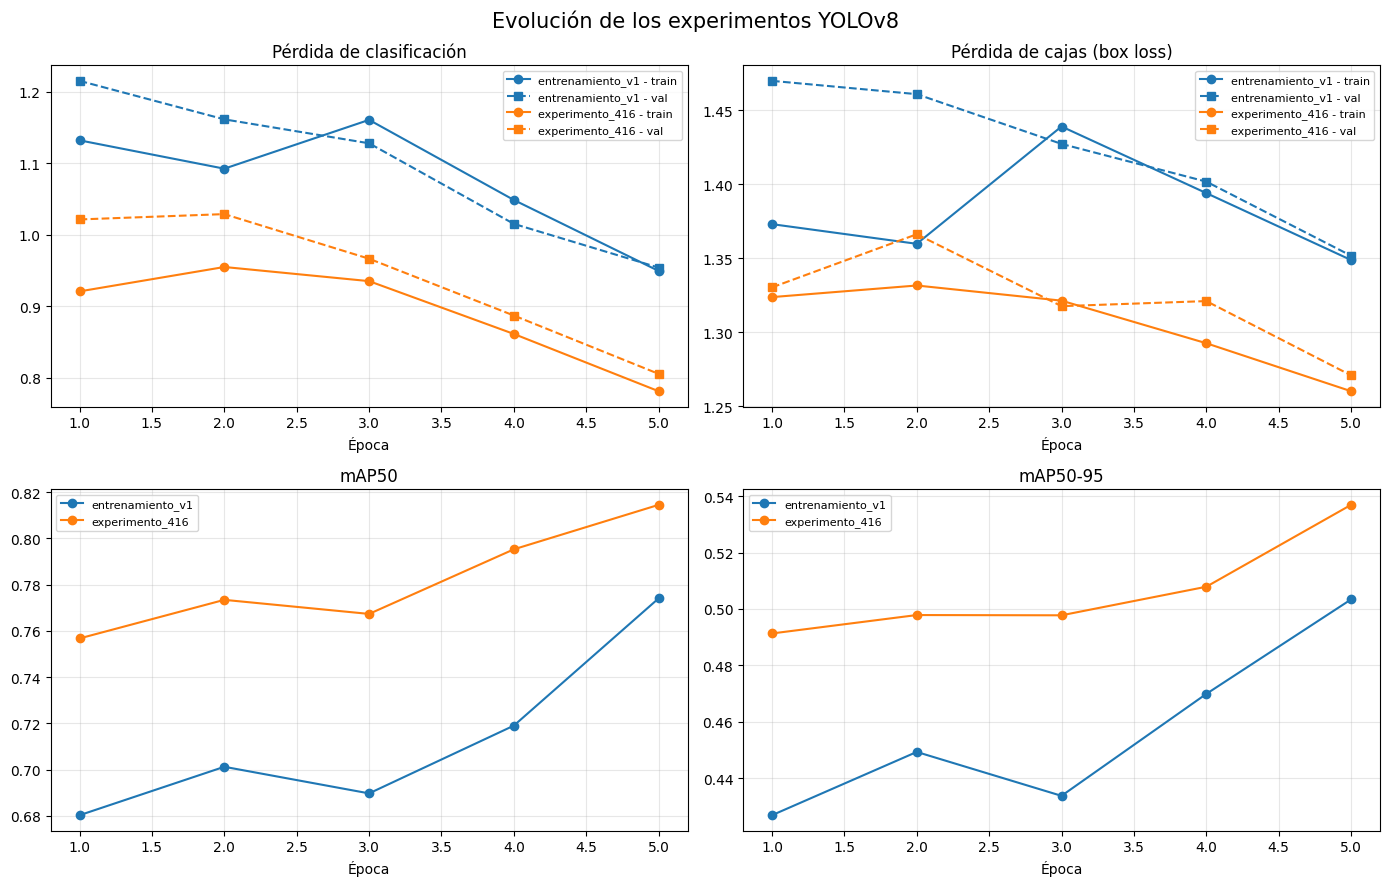

In [ ]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
RESULTADOS = BASE / "03_resultados"

archivos = {
    "entrenamiento_v1": BASE / "02_modelos/entrenamiento_v1/results.csv",
    "experimento_416": BASE / "02_modelos/experimento_416/results.csv",
}

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
colores = {
    "entrenamiento_v1": "tab:blue",
    "experimento_416": "tab:orange"
}

for nombre, ruta in archivos.items():
    df = pd.read_csv(ruta)
    df.columns = df.columns.str.strip()
    epocas = df["epoch"]

    # Pérdida de clasificación
    axes[0, 0].plot(
        epocas, df["train/cls_loss"], marker="o",
        color=colores[nombre], label=f"{nombre} - train"
    )
    axes[0, 0].plot(
        epocas, df["val/cls_loss"], marker="s", linestyle="--",
        color=colores[nombre], label=f"{nombre} - val"
    )

    # Pérdida de cajas
    axes[0, 1].plot(
        epocas, df["train/box_loss"], marker="o",
        color=colores[nombre], label=f"{nombre} - train"
    )
    axes[0, 1].plot(
        epocas, df["val/box_loss"], marker="s", linestyle="--",
        color=colores[nombre], label=f"{nombre} - val"
    )

    # Métricas de detección
    axes[1, 0].plot(
        epocas, df["metrics/mAP50(B)"], marker="o",
        color=colores[nombre], label=nombre
    )
    axes[1, 1].plot(
        epocas, df["metrics/mAP50-95(B)"], marker="o",
        color=colores[nombre], label=nombre
    )

axes[0, 0].set_title("Pérdida de clasificación")
axes[0, 1].set_title("Pérdida de cajas (box loss)")
axes[1, 0].set_title("mAP50")
axes[1, 1].set_title("mAP50-95")

for ax in axes.flat:
    ax.set_xlabel("Época")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)

fig.suptitle("Evolución de los experimentos YOLOv8", fontsize=15)
fig.tight_layout()

salida = RESULTADOS / "curvas_entrenamiento_comparativas.png"
fig.savefig(salida, dpi=160, bbox_inches="tight")
print("Figura guardada en:", salida)

plt.show()


**3. Antes de entrenar: comprobar GPU y archivos**

In [ ]:

from pathlib import Path
import torch
import ultralytics

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")

modelo = BASE / "02_modelos/experimento_416/weights/best.pt"
datos = BASE / "01_datos_yolo/data.yaml"
salida = BASE / "02_modelos/entrenamiento_adicional_v1"

print("Ultralytics:", ultralytics.__version__)
print("PyTorch:", torch.__version__)
print("CUDA disponible:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\nModelo inicial encontrado:", modelo.exists(), modelo)
print("Archivo data.yaml encontrado:", datos.exists(), datos)
print("Carpeta del nuevo experimento:", salida)
print("¿Ya existe esa carpeta?:", salida.exists())

if modelo.exists() and datos.exists() and torch.cuda.is_available():
    print("\nCOMPROBACIÓN: LISTO PARA PREPARAR EL ENTRENAMIENTO")
else:
    print("\nCOMPROBACIÓN: REVISAR LOS ELEMENTOS QUE FALTAN")


ModuleNotFoundError: No module named 'ultralytics'

**Paso 1. Instalar Ultralytics**

In [ ]:

%pip install ultralytics==8.4.184


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 59.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


**Paso siguiente: verificar el entorno y los archivos**
Esta vez comprobaremos los paquetes, la GPU, los pesos del modelo y el archivo de configuración del dataset.

In [ ]:

from pathlib import Path
import torch
import ultralytics

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")

modelo = BASE / "02_modelos/experimento_416/weights/best.pt"
datos = BASE / "01_datos_yolo/data.yaml"
salida = BASE / "02_modelos/entrenamiento_adicional_v1"

print("Ultralytics:", ultralytics.__version__)
print("PyTorch:", torch.__version__)
print("CUDA disponible:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\nModelo inicial:", modelo.exists())
print("Configuración del dataset:", datos.exists())
print("Carpeta del nuevo experimento:", salida)
print("¿Ya existe la carpeta?:", salida.exists())

if modelo.exists() and datos.exists() and torch.cuda.is_available():
    print("\nRESULTADO: entorno listo para preparar el entrenamiento.")
else:
    print("\nRESULTADO: debemos resolver los elementos que faltan.")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics: 8.4.184
PyTorch: 2.11.0+cu130
CUDA disponible: True
GPU: NVIDIA L4

Modelo inicial: True
Configuración del dataset: True
Carpeta del nuevo experimento: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/02_modelos/entrenamiento_adicional_v1
¿Ya existe la carpeta?: False

RESULTADO: entorno listo para preparar el entrenamiento.


In [ ]:

from pathlib import Path
from ultralytics import YOLO

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")

modelo_inicial = BASE / "02_modelos/experimento_416/weights/best.pt"
data_yaml = BASE / "01_datos_yolo/data.yaml"
proyecto = BASE / "02_modelos"
nombre_experimento = "entrenamiento_adicional_v1"

# Protección: no sobrescribir un experimento previo
destino = proyecto / nombre_experimento

if destino.exists():
    raise FileExistsError(
        f"La carpeta ya existe: {destino}. "
        "No se iniciará el entrenamiento para evitar sobrescribir resultados."
    )

if not modelo_inicial.exists() or not data_yaml.exists():
    raise FileNotFoundError("No se encontró el modelo inicial o data.yaml.")

modelo = YOLO(str(modelo_inicial))

resultados = modelo.train(
    data=str(data_yaml),
    imgsz=416,
    epochs=10,
    patience=3,
    batch=16,
    device=0,
    project=str(proyecto),
    name=nombre_experimento,
    exist_ok=False,
    pretrained=True,
    save=True,
    plots=True,
    seed=42
)

print("\nEntrenamiento finalizado.")
print("Resultados:", destino)
print("Pesos y curvas disponibles en esa carpeta.")


New https://pypi.org/project/ultralytics/8.4.188 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.184 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/01_datos_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=416, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0

**Paso 1. Verificar el estado del entrenamiento** Al parecer se paró

In [ ]:

from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
CARPETA = BASE / "02_modelos" / "entrenamiento_adicional_v1"

print("Carpeta encontrada:", CARPETA.exists())

if CARPETA.exists():
    for nombre in [
        "results.csv",
        "weights/best.pt",
        "weights/last.pt",
        "args.yaml"
    ]:
        ruta = CARPETA / nombre
        print(f"{'OK' if ruta.exists() else 'FALTA'}: {nombre}")

    ruta_csv = CARPETA / "results.csv"

    if ruta_csv.exists():
        df = pd.read_csv(ruta_csv)
        print("\nÉpocas registradas:", len(df))

        columnas = [
            c for c in [
                "epoch",
                "metrics/precision(B)",
                "metrics/recall(B)",
                "metrics/mAP50(B)",
                "metrics/mAP50-95(B)"
            ]
            if c in df.columns
        ]

        display(df[columnas].tail(10))
else:
    print("No se encuentra la carpeta del nuevo experimento.")


Carpeta encontrada: True
OK: results.csv
OK: weights/best.pt
OK: weights/last.pt
OK: args.yaml

Épocas registradas: 4


,epoch,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B)
0,1,0.86137,0.76045,0.80789,0.53461
1,2,0.87114,0.72724,0.79997,0.51488
2,3,0.87941,0.68965,0.79297,0.51533
3,4,0.85438,0.70371,0.79095,0.51129


**2. Siguiente paso: comprobar el mejor modelo guardado**

In [ ]:

from pathlib import Path
from ultralytics import YOLO
import pandas as pd

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
CARPETA = BASE / "02_modelos" / "entrenamiento_adicional_v1"

mejor_peso = CARPETA / "weights" / "best.pt"
ultimo_peso = CARPETA / "weights" / "last.pt"
resultados_csv = CARPETA / "results.csv"

print("best.pt existe:", mejor_peso.exists())
print("last.pt existe:", ultimo_peso.exists())

df = pd.read_csv(resultados_csv)
fila_mejor = df.loc[df["metrics/mAP50(B)"].idxmax()]

print("\nMejor época registrada:", int(fila_mejor["epoch"]))
print("Mejor mAP50:", round(fila_mejor["metrics/mAP50(B)"], 4))
print("Mejor mAP50-95:", round(fila_mejor["metrics/mAP50-95(B)"], 4))

# Comprobar que el peso best.pt puede cargarse
modelo = YOLO(str(mejor_peso))
print("\nModelo best.pt cargado correctamente.")
print("Número de clases:", len(modelo.names))
print("Clases:", modelo.names)


best.pt existe: True
last.pt existe: True

Mejor época registrada: 1
Mejor mAP50: 0.8079
Mejor mAP50-95: 0.5346

Modelo best.pt cargado correctamente.
Número de clases: 15
Clases: {0: 'badger', 1: 'bird', 2: 'bobcat', 3: 'car', 4: 'cat', 5: 'coyote', 6: 'deer', 7: 'dog', 8: 'fox', 9: 'opossum', 10: 'rabbit', 11: 'raccoon', 12: 'rodent', 13: 'skunk', 14: 'squirrel'}


In [ ]:

from pathlib import Path
import pandas as pd
import yaml

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
CARPETA = BASE / "02_modelos" / "entrenamiento_adicional_v1"

# 1. Revisar los argumentos guardados
ruta_args = CARPETA / "args.yaml"

print("=== ARGUMENTOS DEL ENTRENAMIENTO ===")
if ruta_args.exists():
    with open(ruta_args, "r", encoding="utf-8") as f:
        args = yaml.safe_load(f)

    for clave in ["epochs", "patience", "batch", "imgsz", "device",
                  "resume", "project", "name"]:
        print(f"{clave}: {args.get(clave) if args else None}")
else:
    print("No se encontró args.yaml")

# 2. Revisar el progreso registrado
ruta_csv = CARPETA / "results.csv"

print("\n=== ÚLTIMAS ÉPOCAS REGISTRADAS ===")
if ruta_csv.exists():
    df = pd.read_csv(ruta_csv)
    df.columns = df.columns.str.strip()
    columnas = [
        c for c in [
            "epoch", "time",
            "metrics/mAP50(B)", "metrics/mAP50-95(B)"
        ] if c in df.columns
    ]
    print("Número de filas:", len(df))
    display(df[columnas].tail())

# 3. Buscar archivos de registro
print("\n=== ARCHIVOS RELACIONADOS CON EL EXPERIMENTO ===")
for ruta in sorted(CARPETA.rglob("*")):
    if ruta.is_file() and (
        ruta.suffix.lower() in [".log", ".txt"] or
        "error" in ruta.name.lower()
    ):
        print(ruta)


=== ARGUMENTOS DEL ENTRENAMIENTO ===
epochs: 10
patience: 3
batch: 16
imgsz: 416
device: 0
resume: False
project: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/02_modelos
name: entrenamiento_adicional_v1

=== ÚLTIMAS ÉPOCAS REGISTRADAS ===
Número de filas: 4


,epoch,time,metrics/mAP50(B),metrics/mAP50-95(B)
0,1,509.049,0.80789,0.53461
1,2,559.583,0.79997,0.51488
2,3,609.633,0.79297,0.51533
3,4,659.453,0.79095,0.51129



=== ARCHIVOS RELACIONADOS CON EL EXPERIMENTO ===


**Paso siguiente: evaluar en las dos particiones**
Evaluaremos el nuevo best.pt tanto en val_cis como en val_trans, con resolución 416, para compararlo con los resultados anteriores. No inicia entrenamiento ni sobrescribe los pesos.

In [ ]:

from pathlib import Path
import pandas as pd
import yaml
from ultralytics import YOLO

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
DATOS = BASE / "01_datos_yolo"
RESULTADOS = BASE / "03_resultados"
PESOS = BASE / "02_modelos/entrenamiento_adicional_v1/weights/best.pt"

# Verificar archivos
assert PESOS.exists(), f"No se encontró el modelo: {PESOS}"
assert (DATOS / "data.yaml").exists(), "No se encontró data.yaml"

with open(DATOS / "data.yaml", "r", encoding="utf-8") as f:
    config = yaml.safe_load(f)

modelo = YOLO(str(PESOS))
filas = []

for particion in ["val_cis", "val_trans"]:
    yaml_eval = dict(config)
    yaml_eval["val"] = str(DATOS / "images" / particion)

    ruta_yaml = RESULTADOS / f"evaluacion_adicional_{particion}.yaml"
    with open(ruta_yaml, "w", encoding="utf-8") as f:
        yaml.safe_dump(yaml_eval, f, sort_keys=False)

    print(f"\nEvaluando {particion}...")

    metricas = modelo.val(
        data=str(ruta_yaml),
        imgsz=416,
        batch=16,
        device=0,
        plots=False,
        verbose=False
    )

    filas.append({
        "modelo": "entrenamiento_adicional_v1",
        "pesos": str(PESOS),
        "particion": particion,
        "imgsz_evaluacion": 416,
        "precision": float(metricas.box.mp),
        "recall": float(metricas.box.mr),
        "mAP50": float(metricas.box.map50),
        "mAP50_95": float(metricas.box.map),
    })

df = pd.DataFrame(filas)
salida = RESULTADOS / "metricas_entrenamiento_adicional_v1.csv"
df.to_csv(salida, index=False)

print("\n=== RESULTADOS DE EVALUACIÓN ===")
display(df)
print("Archivo guardado:", salida)



Evaluando val_cis...
Ultralytics 8.4.184 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
Model summary (fused): 73 layers, 3,136,109 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.3±0.1 ms, read: 115.1±58.2 MB/s, size: 126.4 KB)
val: Scanning /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/01_datos_yolo/labels/val_cis.cache... 1665 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1665/1665 465.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 105/105 15.5it/s 6.8s
                   all       1665       1763      0.866      0.756      0.807      0.535
Speed: 0.2ms preprocess, 0.7ms inference, 0.0ms loss, 0.8ms postprocess per image

Evaluando val_trans...
Ultralytics 8.4.184 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
Model summary (fused): 73 layers, 3,136,109 parameters, 0 gradients, 8.7 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.4±0.1 m

,modelo,pesos,particion,imgsz_evaluacion,precision,recall,mAP50,mAP50_95
0,entrenamiento_adicional_v1,/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/...,val_cis,416,0.865707,0.755749,0.807247,0.534511
1,entrenamiento_adicional_v1,/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/...,val_trans,416,0.385785,0.400542,0.345516,0.227485


Archivo guardado: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/metricas_entrenamiento_adicional_v1.csv


**3. Siguiente paso: demostración visual en cámaras nuevas**
Antes de seguir entrenando, conviene mostrar cómo detecta animales el modelo seleccionado en imágenes de val_trans. Haremos una prueba con 12 imágenes, guardando las predicciones en una carpeta nueva.

In [ ]:
from pathlib import Path
import random
from ultralytics import YOLO

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")

CARPETA_IMAGENES = BASE / "01_datos_yolo/images/val_trans"
PESOS = BASE / "02_modelos/entrenamiento_v1/weights/best.pt"
SALIDA = BASE / "03_resultados/demo_val_trans_entrenamiento_v1"

# Verificar que existen los archivos necesarios
assert CARPETA_IMAGENES.exists(), f"No existe: {CARPETA_IMAGENES}"
assert PESOS.exists(), f"No existe: {PESOS}"
assert not SALIDA.exists(), (
    f"La carpeta de salida ya existe: {SALIDA}. "
    "No se sobrescribirán resultados anteriores."
)

# Seleccionar 12 imágenes de forma reproducible
extensiones = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
imagenes = sorted(
    p for p in CARPETA_IMAGENES.iterdir()
    if p.suffix.lower() in extensiones
)

assert len(imagenes) >= 12, "No hay suficientes imágenes."

random.seed(42)
muestra = random.sample(imagenes, 12)

print("Modelo:", PESOS)
print("Imágenes seleccionadas:", len(muestra))

modelo = YOLO(str(PESOS))

resultados = modelo.predict(
    source=[str(p) for p in muestra],
    imgsz=416,
    conf=0.25,
    device=0,
    save=True,
    project=str(SALIDA.parent),
    name=SALIDA.name,
    exist_ok=False,
    verbose=False
)

print("\nDemostración terminada.")
print("Resultados guardados en:", SALIDA)

Modelo: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/02_modelos/entrenamiento_v1/weights/best.pt
Imágenes seleccionadas: 12
Results saved to /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/demo_val_trans_entrenamiento_v1

Demostración terminada.
Resultados guardados en: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/demo_val_trans_entrenamiento_v1


**El siguiente paso es inspeccionar visualmente las 12 imágenes para comprobar qué detectó el modelo en cámaras nuevas.**
**Paso 1. Crear una hoja de contacto con las predicciones**
Esta celda reunirá las imágenes generadas en una sola lámina para facilitar la revisión. No modifica las imágenes originales ni los pesos del modelo.

In [ ]:
from pathlib import Path
from PIL import Image, ImageOps, ImageDraw
import math

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
CARPETA = BASE / "03_resultados/demo_val_trans_entrenamiento_v1"
SALIDA = BASE / "03_resultados/hoja_contacto_demo_val_trans.png"

# Buscar imágenes de predicción
extensiones = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
archivos = sorted(
    p for p in CARPETA.rglob("*")
    if p.is_file() and p.suffix.lower() in extensiones
)

print("Imágenes encontradas:", len(archivos))

assert len(archivos) > 0, (
    "No se encontraron imágenes. Revisa el contenido de la carpeta de resultados."
)

# Preparar una cuadrícula de 3 columnas
columnas = 3
ancho_celda = 400
alto_celda = 300
filas = math.ceil(len(archivos) / columnas)

margen = 20
alto_titulo = 35

ancho_lienzo = columnas * ancho_celda + (columnas + 1) * margen
alto_lienzo = filas * (alto_celda + alto_titulo) + (filas + 1) * margen

lamina = Image.new("RGB", (ancho_lienzo, alto_lienzo), "white")
dibujo = ImageDraw.Draw(lamina)

for i, archivo in enumerate(archivos):
    with Image.open(archivo) as img:
        img = img.convert("RGB")
        img.thumbnail((ancho_celda, alto_celda))

    fila = i // columnas
    columna = i % columnas

    x = margen + columna * (ancho_celda + margen)
    y = margen + fila * (alto_celda + alto_titulo + margen)

    dibujo.text(
        (x, y),
        f"{i+1}. {archivo.name[:42]}",
        fill="black"
    )

    imagen_con_borde = ImageOps.expand(img, border=2, fill="gray")
    lamina.paste(imagen_con_borde, (x, y + alto_titulo))

lamina.save(SALIDA)

print("Hoja de contacto guardada en:", SALIDA)
display(lamina)

**Siguiente paso: comprobar si las imágenes coinciden**

In [ ]:
from pathlib import Path

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados")

ANTERIOR = BASE / "predicciones_visuales_val_trans"
ACTUAL = BASE / "demo_val_trans_entrenamiento_v1"

extensiones = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def obtener_nombres(carpeta):
    if not carpeta.exists():
        print("No existe la carpeta:", carpeta)
        return set()

    return {
        p.name
        for p in carpeta.rglob("*")
        if p.is_file() and p.suffix.lower() in extensiones
    }

nombres_anteriores = obtener_nombres(ANTERIOR)
nombres_actuales = obtener_nombres(ACTUAL)

coinciden = nombres_anteriores & nombres_actuales

print("Imágenes anteriores:", len(nombres_anteriores))
print("Imágenes actuales:", len(nombres_actuales))
print("Archivos con el mismo nombre:", len(coinciden))
print("Solo en la carpeta anterior:", len(nombres_anteriores - nombres_actuales))
print("Solo en la carpeta actual:", len(nombres_actuales - nombres_anteriores))

if coinciden:
    print("\nImágenes coincidentes:")
    for nombre in sorted(coinciden):
        print("-", nombre)

Imágenes anteriores: 12
Imágenes actuales: 12
Archivos con el mismo nombre: 12
Solo en la carpeta anterior: 0
Solo en la carpeta actual: 0

Imágenes coincidentes:
- 585dac23-23d2-11e8-a6a3-ec086b02610b.jpg
- 587b7cfc-23d2-11e8-a6a3-ec086b02610b.jpg
- 587eea19-23d2-11e8-a6a3-ec086b02610b.jpg
- 5888bcca-23d2-11e8-a6a3-ec086b02610b.jpg
- 58a52fa8-23d2-11e8-a6a3-ec086b02610b.jpg
- 58adc18c-23d2-11e8-a6a3-ec086b02610b.jpg
- 58b66758-23d2-11e8-a6a3-ec086b02610b.jpg
- 59247c5d-23d2-11e8-a6a3-ec086b02610b.jpg
- 59310046-23d2-11e8-a6a3-ec086b02610b.jpg
- 5946b7d1-23d2-11e8-a6a3-ec086b02610b.jpg
- 5948443b-23d2-11e8-a6a3-ec086b02610b.jpg
- 594844e9-23d2-11e8-a6a3-ec086b02610b.jpg


In [ ]:
from pathlib import Path

BASE = Path(
    "/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados"
)

for archivo in sorted(BASE.rglob("*")):
    if archivo.is_file():
        nombre = archivo.name.lower()
        if any(palabra in nombre for palabra in [
            "error", "auditoria", "auditoría",
            "prediccion", "predicción",
            "val_trans", "falso", "revision", "revisión"
        ]):
            print(archivo.relative_to(BASE))

analisis_tamano_cajas_val_trans.csv
auditoria_12_imagenes.csv
auditoria_iou_12_imagenes.csv
comparacion_val_trans_416.csv
detalle_robustez_por_objeto_val_trans.csv
evaluacion_adicional_val_trans.yaml
gradcam_comparativo/gradcam_val_trans_bobcat_5858bfa6-23d2-11e8-a6a3-ec086b02610b.png
gradcam_comparativo/gradcam_val_trans_dog_5858bff0-23d2-11e8-a6a3-ec086b02610b.png
gradcam_datos_originales/val_trans_5858bfa6-23d2-11e8-a6a3-ec086b02610b_bobcat.npy
gradcam_datos_originales/val_trans_5858bff0-23d2-11e8-a6a3-ec086b02610b_dog.npy
gradcam_model15/val_trans_5858bfa6-23d2-11e8-a6a3-ec086b02610b_bobcat.npy
gradcam_model15/val_trans_5858bfa6-23d2-11e8-a6a3-ec086b02610b_bobcat.png
gradcam_model15/val_trans_5858bff0-23d2-11e8-a6a3-ec086b02610b_dog.npy
gradcam_model15/val_trans_5858bff0-23d2-11e8-a6a3-ec086b02610b_dog.png
hoja_contacto_demo_val_trans.png
hoja_revision_occlusion_18.png
metricas_por_clase_val_trans.csv
registro_revision_occlusion_18.csv
resumen_auditoria_iou_12_imagenes.csv
resumen_

**Siguiente paso: recuperar la auditoría original**
Vamos a leer los CSV que ya existen en Drive, sin modificarlos. Primero recuperaremos el detalle de errores y la comparación a 416 px para saber exactamente qué se hizo en la sesión anterior.

In [ ]:
from pathlib import Path
import pandas as pd

BASE = Path(
    "/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados"
)

archivos = [
    "auditoria_12_imagenes.csv",
    "auditoria_iou_12_imagenes.csv",
    "resumen_auditoria_iou_12_imagenes.csv",
    "comparacion_val_trans_416.csv",
]

for nombre in archivos:
    ruta = BASE / nombre
    print("\n" + "=" * 70)
    print("ARCHIVO:", nombre)

    if not ruta.exists():
        print("No se encontró este archivo.")
        continue

    try:
        df = pd.read_csv(ruta, sep=None, engine="python")
        print("Dimensiones:", df.shape)
        print("Columnas:", df.columns.tolist())
        display(df)
    except Exception as e:
        print("No se pudo leer:", str(e))


ARCHIVO: auditoria_12_imagenes.csv
Dimensiones: (21, 4)
Columnas: ['imagen', 'tipo', 'clase', 'confianza']


,imagen,tipo,clase,confianza
0,585dac23-23d2-11e8-a6a3-ec086b02610b.jpg,etiqueta_real,opossum,NaN
1,587b7cfc-23d2-11e8-a6a3-ec086b02610b.jpg,prediccion,cat,0.6165
2,587b7cfc-23d2-11e8-a6a3-ec086b02610b.jpg,etiqueta_real,cat,NaN
3,587eea19-23d2-11e8-a6a3-ec086b02610b.jpg,prediccion,opossum,0.4796
4,587eea19-23d2-11e8-a6a3-ec086b02610b.jpg,etiqueta_real,opossum,NaN
5,5888bcca-23d2-11e8-a6a3-ec086b02610b.jpg,etiqueta_real,opossum,NaN
6,58a52fa8-23d2-11e8-a6a3-ec086b02610b.jpg,prediccion,rabbit,0.3538
7,58a52fa8-23d2-11e8-a6a3-ec086b02610b.jpg,etiqueta_real,opossum,NaN
8,58adc18c-23d2-11e8-a6a3-ec086b02610b.jpg,prediccion,opossum,0.6169
9,58adc18c-23d2-11e8-a6a3-ec086b02610b.jpg,etiqueta_real,opossum,NaN



ARCHIVO: auditoria_iou_12_imagenes.csv
Dimensiones: (14, 6)
Columnas: ['imagen', 'tipo', 'clase_real', 'clase_predicha', 'confianza', 'IoU']


,imagen,tipo,clase_real,clase_predicha,confianza,IoU
0,585dac23-23d2-11e8-a6a3-ec086b02610b.jpg,FN,opossum,NaN,NaN,NaN
1,587b7cfc-23d2-11e8-a6a3-ec086b02610b.jpg,TP,cat,cat,0.6163,0.9112
2,587eea19-23d2-11e8-a6a3-ec086b02610b.jpg,TP,opossum,opossum,0.4797,0.6029
3,5888bcca-23d2-11e8-a6a3-ec086b02610b.jpg,FN,opossum,NaN,NaN,NaN
4,58a52fa8-23d2-11e8-a6a3-ec086b02610b.jpg,ERROR_CLASIFICACION,opossum,rabbit,0.3549,0.7861
5,58adc18c-23d2-11e8-a6a3-ec086b02610b.jpg,TP,opossum,opossum,0.6168,0.7748
6,58b66758-23d2-11e8-a6a3-ec086b02610b.jpg,FN,cat,NaN,NaN,NaN
7,59247c5d-23d2-11e8-a6a3-ec086b02610b.jpg,ERROR_CLASIFICACION,bobcat,rabbit,0.3607,0.8528
8,59247c5d-23d2-11e8-a6a3-ec086b02610b.jpg,FP,NaN,cat,0.4396,NaN
9,59247c5d-23d2-11e8-a6a3-ec086b02610b.jpg,FP,NaN,coyote,0.2555,NaN



ARCHIVO: resumen_auditoria_iou_12_imagenes.csv
Dimensiones: (4, 2)
Columnas: ['tipo', 'cantidad']


,tipo,cantidad
0,TP,4
1,ERROR_CLASIFICACION,3
2,FN,5
3,FP,2



ARCHIVO: comparacion_val_trans_416.csv
Dimensiones: (2, 6)
Columnas: ['modelo', 'resolucion_evaluacion', 'precision', 'recall', 'mAP50', 'mAP50_95']


,modelo,resolucion_evaluacion,precision,recall,mAP50,mAP50_95
0,experimento_320,416,0.465630,0.382781,0.407565,0.272477
1,experimento_416,416,0.379631,0.457517,0.361714,0.229481


**Vamos a comparar las predicciones de las mismas 12 imágenes a resoluciones de entrada de 320 px y 416 px, aprovechando la auditoría que ya hicimos.**

El objetivo es comprobar si cambian las detecciones, las clases predichas y los errores. Trabajaremos sin modificar los modelos, las etiquetas ni los registros anteriores.

In [ ]:
from pathlib import Path

BASE = Path(
    "/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados"
)

carpetas = [
    BASE / "predicciones_visuales_val_trans",
    BASE / "demo_val_trans_entrenamiento_v1",
]

extensiones = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

for carpeta in carpetas:
    print("\n" + "=" * 65)
    print("CARPETA:", carpeta)
    print("Existe:", carpeta.exists())

    if not carpeta.exists():
        continue

    archivos = sorted(
        p for p in carpeta.rglob("*")
        if p.is_file() and p.suffix.lower() in extensiones
    )

    print("Número de imágenes:", len(archivos))

    for archivo in archivos:
        print(" -", archivo.name)


CARPETA: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/predicciones_visuales_val_trans
Existe: True
Número de imágenes: 12
 - 585dac23-23d2-11e8-a6a3-ec086b02610b.jpg
 - 587b7cfc-23d2-11e8-a6a3-ec086b02610b.jpg
 - 587eea19-23d2-11e8-a6a3-ec086b02610b.jpg
 - 5888bcca-23d2-11e8-a6a3-ec086b02610b.jpg
 - 58a52fa8-23d2-11e8-a6a3-ec086b02610b.jpg
 - 58adc18c-23d2-11e8-a6a3-ec086b02610b.jpg
 - 58b66758-23d2-11e8-a6a3-ec086b02610b.jpg
 - 59247c5d-23d2-11e8-a6a3-ec086b02610b.jpg
 - 59310046-23d2-11e8-a6a3-ec086b02610b.jpg
 - 5946b7d1-23d2-11e8-a6a3-ec086b02610b.jpg
 - 5948443b-23d2-11e8-a6a3-ec086b02610b.jpg
 - 594844e9-23d2-11e8-a6a3-ec086b02610b.jpg

CARPETA: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/demo_val_trans_entrenamiento_v1
Existe: True
Número de imágenes: 12
 - 585dac23-23d2-11e8-a6a3-ec086b02610b.jpg
 - 587b7cfc-23d2-11e8-a6a3-ec086b02610b.jpg
 - 587eea19-23d2-11e8-a6a3-ec086b02610b.jpg
 - 5888bcca-23d2-11e8-a6a3-ec086b02610b.jpg
 - 58a52fa8-23d2-11e

**Paso 2. Generar predicciones comparables**
Usaremos el modelo entrenamiento_v1/weights/best.pt sobre las 12 imágenes originales de val_trans, primero con imgsz=320 y después con imgsz=416. Guardaremos las cajas y sus confianzas en archivos independientes.

In [ ]:
from pathlib import Path
import pandas as pd
from ultralytics import YOLO

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
IMAGENES = BASE / "01_datos_yolo/images/val_trans"
PESOS = BASE / "02_modelos/entrenamiento_v1/weights/best.pt"
SALIDA = BASE / "03_resultados/comparacion_resolucion_12"

assert IMAGENES.exists(), f"No existe la carpeta: {IMAGENES}"
assert PESOS.exists(), f"No se encuentran los pesos: {PESOS}"
assert not SALIDA.exists(), f"La carpeta ya existe: {SALIDA}"

# Recuperar exactamente las 12 imágenes auditadas
nombres = [
    "585dac23-23d2-11e8-a6a3-ec086b02610b.jpg",
    "587b7cfc-23d2-11e8-a6a3-ec086b02610b.jpg",
    "587eea19-23d2-11e8-a6a3-ec086b02610b.jpg",
    "5888bcca-23d2-11e8-a6a3-ec086b02610b.jpg",
    "58a52fa8-23d2-11e8-a6a3-ec086b02610b.jpg",
    "58adc18c-23d2-11e8-a6a3-ec086b02610b.jpg",
    "58b66758-23d2-11e8-a6a3-ec086b02610b.jpg",
    "59247c5d-23d2-11e8-a6a3-ec086b02610b.jpg",
    "59310046-23d2-11e8-a6a3-ec086b02610b.jpg",
    "5946b7d1-23d2-11e8-a6a3-ec086b02610b.jpg",
    "5948443b-23d2-11e8-a6a3-ec086b02610b.jpg",
    "594844e9-23d2-11e8-a6a3-ec086b02610b.jpg",
]

rutas = [IMAGENES / nombre for nombre in nombres]
faltantes = [str(p) for p in rutas if not p.exists()]
assert not faltantes, f"Faltan imágenes: {faltantes}"

modelo = YOLO(str(PESOS))
registros = []

for resolucion in [320, 416]:
    print(f"\nProcesando las 12 imágenes con imgsz={resolucion}...")

    resultados = modelo.predict(
        source=[str(p) for p in rutas],
        imgsz=resolucion,
        conf=0.25,
        iou=0.7,
        device=0,
        save=True,
        save_txt=True,
        save_conf=True,
        project=str(SALIDA),
        name=f"imgsz_{resolucion}",
        exist_ok=False,
        verbose=False
    )

    for nombre, resultado in zip(nombres, resultados):
        cajas = resultado.boxes

        if cajas is None or len(cajas) == 0:
            registros.append({
                "imagen": nombre,
                "imgsz": resolucion,
                "clase_id": None,
                "clase": None,
                "confianza": None,
                "x_centro": None,
                "y_centro": None,
                "ancho": None,
                "alto": None
            })
            continue

        xywh = cajas.xywhn.cpu().numpy()
        clases = cajas.cls.cpu().numpy().astype(int)
        confianzas = cajas.conf.cpu().numpy()

        for j, clase_id in enumerate(clases):
            registros.append({
                "imagen": nombre,
                "imgsz": resolucion,
                "clase_id": int(clase_id),
                "clase": resultado.names[int(clase_id)],
                "confianza": float(confianzas[j]),
                "x_centro": float(xywh[j][0]),
                "y_centro": float(xywh[j][1]),
                "ancho": float(xywh[j][2]),
                "alto": float(xywh[j][3])
            })

df = pd.DataFrame(registros)
SALIDA.mkdir(parents=True, exist_ok=True)
csv = SALIDA / "predicciones_12_imagenes_320_vs_416.csv"
df.to_csv(csv, index=False)

print("\nProceso terminado.")
print("Predicciones registradas:", len(df))
print("Detecciones por resolución:")
display(
    df.groupby("imgsz")
      .agg(
          imagenes=("imagen", "nunique"),
          detecciones=("clase_id", "count")
      )
      .reset_index()
)
print("CSV guardado en:", csv)
print("Carpeta de resultados:", SALIDA)


Procesando las 12 imágenes con imgsz=320...
Results saved to /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/comparacion_resolucion_12/imgsz_320
4 labels saved to /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/comparacion_resolucion_12/imgsz_320/labels

Procesando las 12 imágenes con imgsz=416...
Results saved to /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/comparacion_resolucion_12/imgsz_416
7 labels saved to /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/comparacion_resolucion_12/imgsz_416/labels

Proceso terminado.
Predicciones registradas: 28
Detecciones por resolución:


,imgsz,imagenes,detecciones
0,320,12,6
1,416,12,9


CSV guardado en: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/comparacion_resolucion_12/predicciones_12_imagenes_320_vs_416.csv
Carpeta de resultados: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/comparacion_resolucion_12


**2. Paso siguiente: comparar las detecciones por imagen**
Vamos a identificar qué clases detectó el modelo en cada resolución, cuáles aparecieron en ambas y cuáles cambiaron.

In [ ]:
from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")

CSV = (
    BASE / "03_resultados/comparacion_resolucion_12/"
    "predicciones_12_imagenes_320_vs_416.csv"
)

df = pd.read_csv(CSV)

# Separar detecciones de cada resolución
d320 = df[df["imgsz"] == 320].copy()
d416 = df[df["imgsz"] == 416].copy()

# Resumen de clases detectadas por imagen
def resumir(grupo):
    if grupo.empty:
        return "Sin detecciones"
    return "; ".join(
        f"{fila['clase']} ({fila['confianza']:.2f})"
        for _, fila in grupo.sort_values(
            "confianza", ascending=False
        ).iterrows()
    )

resumen = []

for imagen in sorted(df["imagen"].unique()):
    g320 = d320[
        (d320["imagen"] == imagen) & d320["clase"].notna()
    ]
    g416 = d416[
        (d416["imagen"] == imagen) & d416["clase"].notna()
    ]

    resumen.append({
        "imagen": imagen,
        "detecciones_320": len(g320),
        "clases_320": resumir(g320),
        "detecciones_416": len(g416),
        "clases_416": resumir(g416),
    })

comparacion = pd.DataFrame(resumen)

display(comparacion)

print("\nTotal de detecciones a 320 px:", len(d320[d320["clase"].notna()]))
print("Total de detecciones a 416 px:", len(d416[d416["clase"].notna()]))

,imagen,detecciones_320,clases_320,detecciones_416,clases_416
0,585dac23-23d2-11e8-a6a3-ec086b02610b.jpg,0,Sin detecciones,0,Sin detecciones
1,587b7cfc-23d2-11e8-a6a3-ec086b02610b.jpg,0,Sin detecciones,1,cat (0.62)
2,587eea19-23d2-11e8-a6a3-ec086b02610b.jpg,0,Sin detecciones,1,opossum (0.48)
3,5888bcca-23d2-11e8-a6a3-ec086b02610b.jpg,0,Sin detecciones,0,Sin detecciones
4,58a52fa8-23d2-11e8-a6a3-ec086b02610b.jpg,0,Sin detecciones,1,rabbit (0.35)
5,58adc18c-23d2-11e8-a6a3-ec086b02610b.jpg,2,opossum (0.62); raccoon (0.40),1,opossum (0.62)
6,58b66758-23d2-11e8-a6a3-ec086b02610b.jpg,0,Sin detecciones,0,Sin detecciones
7,59247c5d-23d2-11e8-a6a3-ec086b02610b.jpg,2,dog (0.46); bobcat (0.28),3,cat (0.44); rabbit (0.36); coyote (0.26)
8,59310046-23d2-11e8-a6a3-ec086b02610b.jpg,0,Sin detecciones,0,Sin detecciones
9,5946b7d1-23d2-11e8-a6a3-ec086b02610b.jpg,1,raccoon (0.57),1,opossum (0.41)



Total de detecciones a 320 px: 6
Total de detecciones a 416 px: 9


**2. Paso siguiente: contrastar con las etiquetas reales**
Vamos a comparar las predicciones con las anotaciones originales de val_trans. Para que la comparación sea justa, utilizaremos las mismas 12 imágenes y el mismo criterio para ambas resoluciones.

La siguiente celda emparejará cada predicción con una caja real usando IoU ≥ 0.50, independientemente de la clase. Después distinguirá entre detecciones correctas, errores de clasificación, falsos negativos y falsos positivos. Este criterio permite comparar ambas resoluciones de forma consistente, aunque debemos mantenerlo identificado como el criterio de esta auditoría.

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
PRED_CSV = (
    BASE / "03_resultados/comparacion_resolucion_12/"
    "predicciones_12_imagenes_320_vs_416.csv"
)
LABELS = BASE / "01_datos_yolo/labels/val_trans"
SALIDA = BASE / "03_resultados/comparacion_resolucion_12"

assert PRED_CSV.exists(), f"No existe: {PRED_CSV}"
assert LABELS.exists(), f"No existe: {LABELS}"

pred = pd.read_csv(PRED_CSV)
IOU_MINIMO = 0.50

# Cargar las clases del dataset
import yaml
with open(BASE / "01_datos_yolo/data.yaml", "r", encoding="utf-8") as f:
    data_config = yaml.safe_load(f)

names = data_config["names"]
if isinstance(names, list):
    names = {i: nombre for i, nombre in enumerate(names)}
else:
    names = {int(k): v for k, v in names.items()}

def cargar_etiquetas(ruta):
    """Devuelve las cajas reales en formato xywh normalizado."""
    if not ruta.exists():
        raise FileNotFoundError(f"Falta la etiqueta: {ruta}")

    objetos = []
    contenido = ruta.read_text(encoding="utf-8").strip()

    if not contenido:
        return objetos

    for linea in contenido.splitlines():
        valores = linea.split()
        if len(valores) < 5:
            continue
        clase = int(valores[0])
        x, y, w, h = map(float, valores[1:5])
        objetos.append({
            "clase_id": clase,
            "clase": names.get(clase, str(clase)),
            "x": x, "y": y, "w": w, "h": h
        })
    return objetos

def xywh_a_xyxy(caja):
    x, y, w, h = caja
    return [x-w/2, y-h/2, x+w/2, y+h/2]

def calcular_iou(a, b):
    ax1, ay1, ax2, ay2 = xywh_a_xyxy(a)
    bx1, by1, bx2, by2 = xywh_a_xyxy(b)

    ix1, iy1 = max(ax1, bx1), max(ay1, by1)
    ix2, iy2 = min(ax2, bx2), min(ay2, by2)

    inter = max(0, ix2-ix1) * max(0, iy2-iy1)
    area_a = max(0, ax2-ax1) * max(0, ay2-ay1)
    area_b = max(0, bx2-bx1) * max(0, by2-by1)
    union = area_a + area_b - inter
    return inter / union if union > 0 else 0.0

resumen = []
detalle = []

for resolucion in [320, 416]:
    df_r = pred[pred["imgsz"] == resolucion]

    for imagen in sorted(pred["imagen"].unique()):
        etiqueta = LABELS / (Path(imagen).stem + ".txt")
        reales = cargar_etiquetas(etiqueta)

        dp = df_r[
            (df_r["imagen"] == imagen) & df_r["clase"].notna()
        ].copy()

        predicciones = []
        for _, fila in dp.iterrows():
            predicciones.append({
                "clase": str(fila["clase"]),
                "confianza": float(fila["confianza"]),
                "caja": [
                    float(fila["x_centro"]),
                    float(fila["y_centro"]),
                    float(fila["ancho"]),
                    float(fila["alto"])
                ]
            })

        # Construir candidatos de emparejamiento por IoU,
        # sin exigir que las clases coincidan.
        candidatos = []
        for i, real in enumerate(reales):
            caja_real = [real["x"], real["y"], real["w"], real["h"]]
            for j, p in enumerate(predicciones):
                iou = calcular_iou(caja_real, p["caja"])
                if iou >= IOU_MINIMO:
                    candidatos.append((iou, i, j))

        # Emparejamiento greedy: IoU más alta primero;
        # cada objeto y predicción se utiliza como máximo una vez.
        candidatos.sort(reverse=True)
        usados_reales, usadas_pred = set(), set()
        usados_reales = set()
        usados_pred = set()
        emparejamientos = []

        for iou, i, j in candidatos:
            if i in usados_reales or j in usados_pred:
                continue
            usados_reales.add(i)
            usados_pred.add(j)
            emparejamientos.append((iou, i, j))

        tp = errores_clase = 0

        for iou, i, j in emparejamientos:
            real, p = reales[i], predicciones[j]
            correcto = real["clase"] == p["clase"]

            if correcto:
                tp += 1
                tipo = "TP"
            else:
                errores_clase += 1
                tipo = "ERROR_CLASIFICACION"

            detalle.append({
                "imgsz": resolucion,
                "imagen": imagen,
                "tipo": tipo,
                "clase_real": real["clase"],
                "clase_predicha": p["clase"],
                "confianza": p["confianza"],
                "IoU": iou
            })

        fn = len(reales) - len(usados_reales)
        fp = len(predicciones) - len(usados_pred)

        for i, real in enumerate(reales):
            if i not in usados_reales:
                detalle.append({
                    "imgsz": resolucion,
                    "imagen": imagen,
                    "tipo": "FN",
                    "clase_real": real["clase"],
                    "clase_predicha": None,
                    "confianza": None,
                    "IoU": None
                })

        for j, p in enumerate(predicciones):
            if j not in usados_pred:
                detalle.append({
                    "imgsz": resolucion,
                    "imagen": imagen,
                    "tipo": "FP",
                    "clase_real": None,
                    "clase_predicha": p["clase"],
                    "confianza": p["confianza"],
                    "IoU": None
                })

        resumen.append({
            "imgsz": resolucion,
            "imagen": imagen,
            "objetos_reales": len(reales),
            "predicciones": len(predicciones),
            "TP": tp,
            "errores_clasificacion": errores_clase,
            "FN": fn,
            "FP": fp
        })

df_resumen = pd.DataFrame(resumen)
df_detalle = pd.DataFrame(detalle)

archivo_resumen = SALIDA / "auditoria_comparativa_320_vs_416.csv"
archivo_detalle = SALIDA / "detalle_auditoria_320_vs_416.csv"

df_resumen.to_csv(archivo_resumen, index=False)
df_detalle.to_csv(archivo_detalle, index=False)

print("RESUMEN POR RESOLUCIÓN")
display(
    df_resumen.groupby("imgsz")[
        ["objetos_reales", "predicciones", "TP",
         "errores_clasificacion", "FN", "FP"]
    ].sum().reset_index()
)

print("\nDETALLE POR IMAGEN")
display(df_resumen)

print("\nArchivos guardados:")
print(archivo_resumen)
print(archivo_detalle)

RESUMEN POR RESOLUCIÓN


,imgsz,objetos_reales,predicciones,TP,errores_clasificacion,FN,FP
0,320,12,6,1,0,11,5
1,416,12,9,4,3,5,2



DETALLE POR IMAGEN


,imgsz,imagen,objetos_reales,predicciones,TP,errores_clasificacion,FN,FP
0,320,585dac23-23d2-11e8-a6a3-ec086b02610b.jpg,1,0,0,0,1,0
1,320,587b7cfc-23d2-11e8-a6a3-ec086b02610b.jpg,1,0,0,0,1,0
2,320,587eea19-23d2-11e8-a6a3-ec086b02610b.jpg,1,0,0,0,1,0
3,320,5888bcca-23d2-11e8-a6a3-ec086b02610b.jpg,1,0,0,0,1,0
4,320,58a52fa8-23d2-11e8-a6a3-ec086b02610b.jpg,1,0,0,0,1,0
5,320,58adc18c-23d2-11e8-a6a3-ec086b02610b.jpg,1,2,1,0,0,1
6,320,58b66758-23d2-11e8-a6a3-ec086b02610b.jpg,1,0,0,0,1,0
7,320,59247c5d-23d2-11e8-a6a3-ec086b02610b.jpg,1,2,0,0,1,2
8,320,59310046-23d2-11e8-a6a3-ec086b02610b.jpg,1,0,0,0,1,0
9,320,5946b7d1-23d2-11e8-a6a3-ec086b02610b.jpg,1,1,0,0,1,1



Archivos guardados:
/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/comparacion_resolucion_12/auditoria_comparativa_320_vs_416.csv
/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/comparacion_resolucion_12/detalle_auditoria_320_vs_416.csv


**Paso 1. Preparar la evaluación**
Ejecuta esta celda en Google Colab. Solo comprobará que existen el modelo, el archivo de configuración y las imágenes de validación.

In [ ]:
from pathlib import Path
import torch
import yaml
from ultralytics import YOLO

# Directorio principal del proyecto
BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")

# Archivos necesarios
MODELO = BASE / "02_modelos/entrenamiento_v1/weights/best.pt"
DATA_YAML = BASE / "01_datos_yolo/data.yaml"
IMAGENES_VAL = BASE / "01_datos_yolo/images/val_trans"

# Comprobaciones
print("Modelo encontrado:", MODELO.exists())
print("Configuración encontrada:", DATA_YAML.exists())
print("Carpeta val_trans encontrada:", IMAGENES_VAL.exists())

if MODELO.exists():
    print("Tamaño del modelo:", round(MODELO.stat().st_size / (1024**2), 2), "MB")

if IMAGENES_VAL.exists():
    extensiones = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    imagenes = [
        p for p in IMAGENES_VAL.iterdir()
        if p.is_file() and p.suffix.lower() in extensiones
    ]
    print("Número de imágenes:", len(imagenes))

print("GPU disponible:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Modelo encontrado: True
Configuración encontrada: True
Carpeta val_trans encontrada: True
Tamaño del modelo: 6.16 MB
Número de imágenes: 1533
GPU disponible: True
GPU: NVIDIA L4


**Paso 2. Evaluar el modelo con ambas resoluciones**
Esta celda evaluará exactamente los mismos pesos con imgsz=320 y imgsz=416, manteniendo conf=0.25, iou=0.7 y el mismo conjunto de validación. Guardará los resultados en una carpeta nueva para no sobrescribir los experimentos anteriores.

In [ ]:
from pathlib import Path
import pandas as pd
from ultralytics import YOLO

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")

MODELO = BASE / "02_modelos/entrenamiento_v1/weights/best.pt"
DATA_YAML = BASE / "01_datos_yolo/data.yaml"
SALIDA = BASE / "03_resultados/evaluacion_resolucion_global"

SALIDA.mkdir(parents=True, exist_ok=True)

# Cargar el mismo modelo para las dos evaluaciones
model = YOLO(str(MODELO))

resultados = []

for resolucion in [320, 416]:
    print("\n" + "=" * 60)
    print(f"EVALUACIÓN GLOBAL: imgsz={resolucion}")
    print("=" * 60)

    metrics = model.val(
        data=str(DATA_YAML),
        split="val_trans",
        imgsz=resolucion,
        conf=0.25,
        iou=0.7,
        device=0,
        batch=16,
        workers=2,
        plots=True,
        project=str(SALIDA),
        name=f"val_trans_imgsz_{resolucion}",
        exist_ok=True,
        verbose=True
    )

    resultados.append({
        "imgsz": resolucion,
        "precision": float(metrics.box.mp),
        "recall": float(metrics.box.mr),
        "mAP50": float(metrics.box.map50),
        "mAP50_95": float(metrics.box.map),
    })

    print(f"\nResultados para imgsz={resolucion}")
    print(f"Precision: {metrics.box.mp:.4f}")
    print(f"Recall:    {metrics.box.mr:.4f}")
    print(f"mAP50:     {metrics.box.map50:.4f}")
    print(f"mAP50-95:  {metrics.box.map:.4f}")

df_resultados = pd.DataFrame(resultados)
archivo_csv = SALIDA / "comparacion_global_320_vs_416.csv"
df_resultados.to_csv(archivo_csv, index=False)

print("\nCOMPARACIÓN GLOBAL")
display(df_resultados.round(4))

print("\nArchivo guardado en:")
print(archivo_csv)


EVALUACIÓN GLOBAL: imgsz=320
Ultralytics 8.4.184 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
Model summary (fused): 73 layers, 3,136,109 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.3±0.1 ms, read: 124.6±65.3 MB/s, size: 117.6 KB)
val: Scanning /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/01_datos_yolo/labels/val_trans.cache... 1533 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1533/1533 229.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 96/96 14.8it/s 6.5s
                   all       1533       1673      0.398       0.35      0.267      0.174
                  bird          5          5          0          0          0          0
                bobcat        728        793      0.863      0.231      0.214       0.14
                   cat         70         70       0.12        0.3     0.0667     0.0444
                coyote         45         45      0.163

,imgsz,precision,recall,mAP50,mAP50_95
0,320,0.3980,0.3504,0.2671,0.1743
1,416,0.4706,0.3800,0.2919,0.1998



Archivo guardado en:
/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/evaluacion_resolucion_global/comparacion_global_320_vs_416.csv


**3. Siguiente paso: guardar y comparar las métricas por clase**
Vamos a generar una tabla por especie para documentar los resultados y utilizarla después en el informe académico. Esta celda; vuelve a evaluar ambas resoluciones, pero no entrena ni modifica el modelo.

In [ ]:
from pathlib import Path
import pandas as pd
import yaml
from ultralytics import YOLO

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
MODELO = BASE / "02_modelos/entrenamiento_v1/weights/best.pt"
DATA_YAML = BASE / "01_datos_yolo/data.yaml"
SALIDA = BASE / "03_resultados/evaluacion_resolucion_global"
SALIDA.mkdir(parents=True, exist_ok=True)

with open(DATA_YAML, "r", encoding="utf-8") as f:
    config = yaml.safe_load(f)

names = config["names"]
if isinstance(names, list):
    nombres_clases = {i: nombre for i, nombre in enumerate(names)}
else:
    nombres_clases = {int(i): nombre for i, nombre in names.items()}

model = YOLO(str(MODELO))
filas = []

for resolucion in [320, 416]:
    print(f"\nEvaluando resolución {resolucion}...")

    m = model.val(
        data=str(DATA_YAML),
        split="val_trans",
        imgsz=resolucion,
        conf=0.25,
        iou=0.7,
        device=0,
        batch=16,
        workers=2,
        plots=False,
        verbose=False
    )

    box = m.box

    for posicion, clase_id in enumerate(box.ap_class_index):
        filas.append({
            "imgsz": resolucion,
            "clase_id": int(clase_id),
            "especie": nombres_clases.get(int(clase_id), str(clase_id)),
            "precision": float(box.p[posicion]),
            "recall": float(box.r[posicion]),
            "mAP50": float(box.ap50[posicion]),
            "mAP50_95": float(box.ap[posicion].mean())
        })

df_clases = pd.DataFrame(filas)

archivo = SALIDA / "metricas_por_clase_320_vs_416.csv"
df_clases.to_csv(archivo, index=False)

print("\nMÉTRICAS POR CLASE Y RESOLUCIÓN")
display(df_clases.round(4))

print("\nCOMPARACIÓN DE mAP50")
tabla = df_clases.pivot(
    index="especie",
    columns="imgsz",
    values="mAP50"
).rename(columns={320: "mAP50_320", 416: "mAP50_416"})

tabla["diferencia_416_menos_320"] = (
    tabla["mAP50_416"] - tabla["mAP50_320"]
)

display(tabla.round(4))

print("\nArchivo guardado:")
print(archivo)


Evaluando resolución 320...
Ultralytics 8.4.184 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
Model summary (fused): 73 layers, 3,136,109 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.3±0.1 ms, read: 129.5±64.9 MB/s, size: 102.3 KB)
val: Scanning /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/01_datos_yolo/labels/val_trans.cache... 1533 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1533/1533 306.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 96/96 19.5it/s 4.9s
                   all       1533       1673      0.398       0.35      0.267      0.174
Speed: 0.1ms preprocess, 0.5ms inference, 0.0ms loss, 0.6ms postprocess per image

Evaluando resolución 416...
Ultralytics 8.4.184 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
Model summary (fused): 73 layers, 3,136,109 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.4±0.1 ms, rea

,imgsz,clase_id,especie,precision,recall,mAP50,mAP50_95
0,320,1,bird,0.0000,0.0000,0.0000,0.0000
1,320,2,bobcat,0.8632,0.2308,0.2142,0.1398
2,320,4,cat,0.1200,0.3000,0.0667,0.0444
3,320,5,coyote,0.1635,0.3778,0.0672,0.0418
4,320,7,dog,0.5385,0.7000,0.6355,0.5160
5,320,9,opossum,0.7411,0.5388,0.4978,0.2189
6,320,10,rabbit,0.0097,0.0143,0.0002,0.0001
7,320,11,raccoon,0.3279,0.4412,0.3765,0.2562
8,320,13,skunk,0.8182,0.5510,0.5460,0.3518
9,416,1,bird,0.0000,0.0000,0.0000,0.0000



COMPARACIÓN DE mAP50


imgsz,mAP50_320,mAP50_416,diferencia_416_menos_320
especie,,,
bird,0.0000,0.0000,0.0000
bobcat,0.2142,0.1945,-0.0196
cat,0.0667,0.1577,0.0909
coyote,0.0672,0.0915,0.0242
dog,0.6355,0.5524,-0.0831
opossum,0.4978,0.6061,0.1084
rabbit,0.0002,0.0004,0.0002
raccoon,0.3765,0.4935,0.1170
skunk,0.5460,0.5312,-0.0149



Archivo guardado:
/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/evaluacion_resolucion_global/metricas_por_clase_320_vs_416.csv


**Paso 1. Generar la matriz de confusión**
Ejecuta esta celda en Google Colab. Evaluará el modelo sobre las 1.533 imágenes y guardará los resultados en una carpeta nueva, sin sobrescribir las evaluaciones anteriores.

In [ ]:
from pathlib import Path
import pandas as pd
from IPython.display import display
from ultralytics import YOLO

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")

MODELO = BASE / "02_modelos/entrenamiento_v1/weights/best.pt"
DATA_YAML = BASE / "01_datos_yolo/data.yaml"
SALIDA = BASE / "03_resultados/analisis_errores_416"

SALIDA.mkdir(parents=True, exist_ok=True)

model = YOLO(str(MODELO))

print("Evaluando modelo con imgsz=416...")

metrics = model.val(
    data=str(DATA_YAML),
    split="val_trans",
    imgsz=416,
    conf=0.25,
    iou=0.7,
    device=0,
    batch=16,
    workers=2,
    plots=True,
    project=str(SALIDA),
    name="matriz_confusion",
    exist_ok=True,
    verbose=False
)

# Recuperar la matriz de confusión
matriz = metrics.confusion_matrix.matrix

# Nombres de las clases y categoría de fondo
nombres = model.names
if isinstance(nombres, dict):
    nombres_clases = [nombres[i] for i in sorted(nombres)]
else:
    nombres_clases = list(nombres)

etiquetas = nombres_clases + ["fondo"]

df_matriz = pd.DataFrame(
    matriz,
    index=etiquetas,
    columns=etiquetas
)

archivo_csv = SALIDA / "matriz_confusion_416.csv"
df_matriz.to_csv(archivo_csv, index=True)

print("\nMATRIZ DE CONFUSIÓN")
print("Filas = clase real; columnas = clase predicha.")
print("'fondo' representa detecciones omitidas o falsas detecciones, según el eje.")
display(df_matriz)

print("\nArchivos generados:")
print("Carpeta de gráficos:", SALIDA / "matriz_confusion")
print("Matriz CSV:", archivo_csv)

Evaluando modelo con imgsz=416...
Ultralytics 8.4.184 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
Model summary (fused): 73 layers, 3,136,109 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.3±0.0 ms, read: 107.5±58.2 MB/s, size: 94.9 KB)
val: Scanning /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/01_datos_yolo/labels/val_trans.cache... 1533 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1533/1533 321.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 96/96 14.1it/s 6.8s
                   all       1533       1673      0.471       0.38      0.292        0.2
Speed: 0.3ms preprocess, 0.6ms inference, 0.0ms loss, 0.8ms postprocess per image
Results saved to /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/analisis_errores_416/matriz_confusion

MATRIZ DE CONFUSIÓN
Filas = clase real; columnas = clase predicha.
'fondo' representa detecciones omitidas o falsas detec

,badger,bird,bobcat,car,cat,coyote,deer,dog,fox,opossum,rabbit,raccoon,rodent,skunk,squirrel,fondo
badger,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
bird,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
bobcat,0.0,0.0,159.0,0.0,4.0,5.0,0.0,0.0,0.0,8.0,0.0,0.0,0.0,0.0,0.0,28.0
car,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
cat,0.0,0.0,167.0,0.0,33.0,12.0,0.0,12.0,0.0,4.0,0.0,16.0,0.0,2.0,0.0,56.0
coyote,0.0,0.0,40.0,0.0,5.0,17.0,0.0,15.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,63.0
deer,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0
dog,0.0,0.0,29.0,0.0,0.0,1.0,0.0,42.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,40.0
fox,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
opossum,0.0,0.0,9.0,0.0,3.0,1.0,0.0,0.0,0.0,264.0,0.0,11.0,0.0,6.0,0.0,32.0



Archivos generados:
Carpeta de gráficos: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/analisis_errores_416/matriz_confusion
Matriz CSV: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/analisis_errores_416/matriz_confusion_416.csv


**Paso 2. Verificar los conteos de las etiquetas**

In [ ]:
from pathlib import Path
from collections import Counter
import pandas as pd
import yaml

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")

LABELS = BASE / "01_datos_yolo/labels/val_trans"
DATA_YAML = BASE / "01_datos_yolo/data.yaml"
MATRIZ_CSV = (
    BASE / "03_resultados/analisis_errores_416/"
    "matriz_confusion_416.csv"
)

# Leer nombres de clases
with open(DATA_YAML, "r", encoding="utf-8") as f:
    config = yaml.safe_load(f)

names = config["names"]
if isinstance(names, list):
    nombres = {i: nombre for i, nombre in enumerate(names)}
else:
    nombres = {int(i): nombre for i, nombre in names.items()}

# Contar objetos reales en las etiquetas YOLO
conteo = Counter()
archivos = list(LABELS.glob("*.txt"))

for archivo in archivos:
    with open(archivo, "r", encoding="utf-8") as f:
        for linea in f:
            partes = linea.strip().split()
            if len(partes) >= 5:
                clase_id = int(float(partes[0]))
                conteo[clase_id] += 1

df_reales = pd.DataFrame([
    {
        "clase_id": i,
        "especie": nombres.get(i, str(i)),
        "instancias_reales": conteo.get(i, 0)
    }
    for i in sorted(nombres)
])

print("Imágenes con archivo de etiquetas:", len(archivos))
print("Total de objetos reales en las etiquetas:", sum(conteo.values()))
print("\nCONTEO DIRECTO DE ETIQUETAS")
display(df_reales)

# Comparar con la matriz guardada
df_matriz = pd.read_csv(MATRIZ_CSV, index_col=0)

print("\nSUMAS DE LAS FILAS DE LA MATRIZ")
df_sumas = pd.DataFrame({
    "especie": df_matriz.index,
    "suma_fila": df_matriz.sum(axis=1).values
})
display(df_sumas)

print("\nSuma total de la matriz:", df_matriz.to_numpy().sum())

Imágenes con archivo de etiquetas: 1533
Total de objetos reales en las etiquetas: 1673

CONTEO DIRECTO DE ETIQUETAS


,clase_id,especie,instancias_reales
0,0,badger,0
1,1,bird,5
2,2,bobcat,793
3,3,car,0
4,4,cat,70
5,5,coyote,45
6,6,deer,0
7,7,dog,80
8,8,fox,0
9,9,opossum,425



SUMAS DE LAS FILAS DE LA MATRIZ


,especie,suma_fila
0,badger,0.0
1,bird,1.0
2,bobcat,204.0
3,car,0.0
4,cat,302.0
5,coyote,142.0
6,deer,2.0
7,dog,112.0
8,fox,0.0
9,opossum,326.0



Suma total de la matriz: 1966.0


**2. Siguiente paso: verificar la matriz con las métricas de Ultralytics**
Vamos a generar una matriz normalizada por clase real y comprobar que sus conteos coincidan con las etiquetas originales. Para evitar confusiones, usaremos directamente los datos de evaluación que devuelve el modelo.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import yaml
from ultralytics import YOLO

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
MODELO = BASE / "02_modelos/entrenamiento_v1/weights/best.pt"
DATA_YAML = BASE / "01_datos_yolo/data.yaml"
SALIDA = BASE / "03_resultados/analisis_errores_416"
SALIDA.mkdir(parents=True, exist_ok=True)

model = YOLO(str(MODELO))

metrics = model.val(
    data=str(DATA_YAML),
    split="val_trans",
    imgsz=416,
    conf=0.25,
    iou=0.7,
    device=0,
    batch=16,
    workers=2,
    plots=True,
    project=str(SALIDA),
    name="verificacion_matriz",
    exist_ok=True,
    verbose=False
)

# Matriz original entregada por Ultralytics
cm = np.asarray(metrics.confusion_matrix.matrix)
print("Dimensiones de la matriz:", cm.shape)
print("Suma total:", cm.sum())

# Mostrar la matriz sin modificar sus valores
print("\nMatriz de confusión:")
display(pd.DataFrame(cm))

# Mostrar los conteos reales que Ultralytics reporta por clase
box = metrics.box
print("\nClases evaluadas:", box.ap_class_index)
print("Instancias por clase en las etiquetas: 1673 en total")
print("Precision global:", round(float(box.mp), 4))
print("Recall global:", round(float(box.mr), 4))
print("mAP50 global:", round(float(box.map50), 4))
print("mAP50-95 global:", round(float(box.map), 4))

Ultralytics 8.4.184 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
Model summary (fused): 73 layers, 3,136,109 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.3±0.1 ms, read: 134.3±62.0 MB/s, size: 110.8 KB)
val: Scanning /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/01_datos_yolo/labels/val_trans.cache... 1533 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1533/1533 494.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 96/96 14.5it/s 6.6s
                   all       1533       1673      0.471       0.38      0.292        0.2
Speed: 0.3ms preprocess, 0.6ms inference, 0.0ms loss, 0.9ms postprocess per image
Results saved to /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/analisis_errores_416/verificacion_matriz
Dimensiones de la matriz: (16, 16)
Suma total: 1966.0

Matriz de confusión:


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,0.0,0.0,159.0,0.0,4.0,5.0,0.0,0.0,0.0,8.0,0.0,0.0,0.0,0.0,0.0,28.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,167.0,0.0,33.0,12.0,0.0,12.0,0.0,4.0,0.0,16.0,0.0,2.0,0.0,56.0
5,0.0,0.0,40.0,0.0,5.0,17.0,0.0,15.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,63.0
6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0
7,0.0,0.0,29.0,0.0,0.0,1.0,0.0,42.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,40.0
8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9,0.0,0.0,9.0,0.0,3.0,1.0,0.0,0.0,0.0,264.0,0.0,11.0,0.0,6.0,0.0,32.0



Clases evaluadas: [ 1  2  4  5  7  9 10 11 13]
Instancias por clase en las etiquetas: 1673 en total
Precision global: 0.4706
Recall global: 0.38
mAP50 global: 0.2919
mAP50-95 global: 0.1998


**2. Siguiente paso: analizar las confusiones por objeto real**
Para evitar depender de la interpretación de la matriz de Ultralytics, vamos a construir una auditoría independiente a partir de las etiquetas originales y las predicciones del modelo. Emparejaremos cajas reales y predichas mediante IoU ≥ 0.50 y registraremos por separado:
- detecciones correctas;
- errores de clasificación;
- objetos no detectados;
- falsas detecciones.
Esta auditoría nos permitirá obtener ejemplos concretos de confusiones entre especies y verificar los conteos antes de tomar decisiones sobre el entrenamiento.

In [ ]:
from pathlib import Path
import pandas as pd
import yaml
from ultralytics import YOLO

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
MODELO = BASE / "02_modelos/entrenamiento_v1/weights/best.pt"
DATA_YAML = BASE / "01_datos_yolo/data.yaml"
IMAGENES = BASE / "01_datos_yolo/images/val_trans"
ETIQUETAS = BASE / "01_datos_yolo/labels/val_trans"

SALIDA = BASE / "03_resultados/analisis_errores_416/auditoria_objetos"
SALIDA.mkdir(parents=True, exist_ok=True)

with open(DATA_YAML, "r", encoding="utf-8") as f:
    config = yaml.safe_load(f)

names = config["names"]
if isinstance(names, list):
    nombres = {i: n for i, n in enumerate(names)}
else:
    nombres = {int(i): n for i, n in names.items()}

model = YOLO(str(MODELO))

# Guardar predicciones en formato YOLO normalizado, con confianza
model.predict(
    source=str(IMAGENES),
    imgsz=416,
    conf=0.25,
    iou=0.7,
    device=0,
    batch=16,
    save=False,
    save_txt=True,
    save_conf=True,
    project=str(SALIDA),
    name="predicciones",
    exist_ok=True,
    verbose=False
)

print("Predicciones generadas.")
print("Revisa la carpeta:", SALIDA / "predicciones" / "labels")
print("Las etiquetas originales no se han modificado.")

Results saved to /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/analisis_errores_416/auditoria_objetos/predicciones
1088 labels saved to /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/analisis_errores_416/auditoria_objetos/predicciones/labels
Predicciones generadas.
Revisa la carpeta: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/analisis_errores_416/auditoria_objetos/predicciones/labels
Las etiquetas originales no se han modificado.


Ahora vamos a comparar las predicciones con las etiquetas reales mediante IoU ≥ 0.50. Así identificaremos las confusiones entre especies, los animales no detectados y las falsas detecciones.
**Paso 2. Construir la auditoría independiente**

In [ ]:
from pathlib import Path
from collections import Counter
import pandas as pd
import numpy as np
import yaml

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
DATA_YAML = BASE / "01_datos_yolo/data.yaml"
IMAGENES = BASE / "01_datos_yolo/images/val_trans"
REALES = BASE / "01_datos_yolo/labels/val_trans"
PRED = (
    BASE / "03_resultados/analisis_errores_416/"
    "auditoria_objetos/predicciones/labels"
)
SALIDA = BASE / "03_resultados/analisis_errores_416/auditoria_objetos"
SALIDA.mkdir(parents=True, exist_ok=True)

with open(DATA_YAML, "r", encoding="utf-8") as f:
    config = yaml.safe_load(f)

names = config["names"]
if isinstance(names, list):
    nombres = {i: n for i, n in enumerate(names)}
else:
    nombres = {int(i): n for i, n in names.items()}

def leer_cajas(ruta, predicciones=False):
    cajas = []
    if not ruta.exists():
        return cajas

    for linea in ruta.read_text(encoding="utf-8").splitlines():
        partes = linea.split()
        if len(partes) < 5:
            continue

        clase = int(float(partes[0]))
        x, y, w, h = map(float, partes[1:5])
        confianza = float(partes[5]) if predicciones and len(partes) > 5 else np.nan

        cajas.append({
            "clase": clase,
            "x1": x - w / 2,
            "y1": y - h / 2,
            "x2": x + w / 2,
            "y2": y + h / 2,
            "confianza": confianza
        })
    return cajas

def iou(a, b):
    x1 = max(a["x1"], b["x1"])
    y1 = max(a["y1"], b["y1"])
    x2 = min(a["x2"], b["x2"])
    y2 = min(a["y2"], b["y2"])

    inter = max(0, x2 - x1) * max(0, y2 - y1)
    area_a = max(0, a["x2"] - a["x1"]) * max(0, a["y2"] - a["y1"])
    area_b = max(0, b["x2"] - b["x1"]) * max(0, b["y2"] - b["y1"])
    union = area_a + area_b - inter

    return inter / union if union > 0 else 0.0

# Obtener las imágenes originales
extensiones = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
imagenes = sorted(
    p for p in IMAGENES.iterdir()
    if p.is_file() and p.suffix.lower() in extensiones
)

detalle = []
resumen = []
confusiones = Counter()
totales = Counter()

for imagen in imagenes:
    nombre = imagen.name
    reales = leer_cajas(REALES / f"{imagen.stem}.txt")
    preds = leer_cajas(PRED / f"{imagen.stem}.txt", predicciones=True)

    candidatos = []
    for ir, real in enumerate(reales):
        for ip, pred in enumerate(preds):
            valor_iou = iou(real, pred)
            if valor_iou >= 0.50:
                candidatos.append((valor_iou, ir, ip))

    # Emparejamiento voraz: IoU más alto primero, cada caja se usa una vez
    candidatos.sort(reverse=True)
    usados_reales, usados_pred = set(), set()
    pares = []

    for valor_iou, ir, ip in candidatos:
        if ir not in usados_reales and ip not in usados_pred:
            usados_reales.add(ir)
            usados_pred.add(ip)
            pares.append((ir, ip, valor_iou))

    tp = errores_clase = 0

    for ir, ip, valor_iou in pares:
        real, pred = reales[ir], preds[ip]
        clase_real = nombres.get(real["clase"], str(real["clase"]))
        clase_pred = nombres.get(pred["clase"], str(pred["clase"]))

        if real["clase"] == pred["clase"]:
            tipo = "TP"
            tp += 1
        else:
            tipo = "ERROR_CLASIFICACION"
            errores_clase += 1
            confusiones[(clase_real, clase_pred)] += 1

        detalle.append({
            "imagen": nombre,
            "tipo": tipo,
            "clase_real": clase_real,
            "clase_predicha": clase_pred,
            "confianza": pred["confianza"],
            "IoU": valor_iou
        })

    fn = len(reales) - len(usados_reales)
    fp = len(preds) - len(usados_pred)

    for ir, real in enumerate(reales):
        if ir not in usados_reales:
            detalle.append({
                "imagen": nombre,
                "tipo": "FN",
                "clase_real": nombres.get(real["clase"], str(real["clase"])),
                "clase_predicha": None,
                "confianza": np.nan,
                "IoU": np.nan
            })

    for ip, pred in enumerate(preds):
        if ip not in usados_pred:
            detalle.append({
                "imagen": nombre,
                "tipo": "FP",
                "clase_real": None,
                "clase_predicha": nombres.get(pred["clase"], str(pred["clase"])),
                "confianza": pred["confianza"],
                "IoU": np.nan
            })

    resumen.append({
        "imagen": nombre,
        "objetos_reales": len(reales),
        "predicciones": len(preds),
        "TP": tp,
        "errores_clasificacion": errores_clase,
        "FN": fn,
        "FP": fp
    })

    totales.update({
        "objetos_reales": len(reales),
        "predicciones": len(preds),
        "TP": tp,
        "errores_clasificacion": errores_clase,
        "FN": fn,
        "FP": fp
    })

df_detalle = pd.DataFrame(detalle)
df_resumen = pd.DataFrame(resumen)

df_detalle.to_csv(SALIDA / "detalle_auditoria_iou_416.csv", index=False)
df_resumen.to_csv(SALIDA / "resumen_auditoria_iou_416.csv", index=False)

df_confusiones = pd.DataFrame(
    [
        {"clase_real": real, "clase_predicha": pred, "casos": cantidad}
        for (real, pred), cantidad in confusiones.most_common()
    ],
    columns=["clase_real", "clase_predicha", "casos"]
)
df_confusiones.to_csv(SALIDA / "confusiones_entre_especies_416.csv", index=False)

print("RESUMEN GLOBAL DE AUDITORÍA (IoU >= 0.50)")
display(pd.DataFrame([dict(totales)]))

print("\nCONFUSIONES MÁS FRECUENTES")
display(df_confusiones.head(15))

print("\nCONTEO DE TIPOS DE RESULTADO")
display(df_detalle["tipo"].value_counts().rename_axis("tipo").to_frame("casos"))

print("\nArchivos guardados en:", SALIDA)

RESUMEN GLOBAL DE AUDITORÍA (IoU >= 0.50)


,objetos_reales,predicciones,TP,errores_clasificacion,FN,FP
0,1673,1287,615,434,624,238



CONFUSIONES MÁS FRECUENTES


,clase_real,clase_predicha,casos
0,bobcat,cat,150
1,bobcat,rabbit,66
2,bobcat,coyote,42
3,bobcat,dog,30
4,dog,coyote,14
5,dog,cat,14
6,raccoon,opossum,13
7,coyote,cat,12
8,raccoon,cat,12
9,bobcat,squirrel,10



CONTEO DE TIPOS DE RESULTADO


,casos
tipo,
FN,624
TP,615
ERROR_CLASIFICACION,434
FP,238



Archivos guardados en: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/analisis_errores_416/auditoria_objetos


**4. Siguiente paso: seleccionar imágenes concretas para revisar**
Vamos a extraer una muestra de imágenes con los errores más frecuentes, incluyendo el nombre de la imagen, la clase real, la clase predicha, la confianza y el IoU. Utilizaremos el CSV que ya generamos, sin volver a ejecutar el modelo.

In [ ]:
from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")

ARCHIVO = (
    BASE / "03_resultados/analisis_errores_416/"
    "auditoria_objetos/detalle_auditoria_iou_416.csv"
)

SALIDA = BASE / "03_resultados/analisis_errores_416/auditoria_objetos"

df = pd.read_csv(ARCHIVO)

# Errores de clasificación de bobcat hacia las clases más frecuentes
errores_prioritarios = df[
    (df["tipo"] == "ERROR_CLASIFICACION") &
    (df["clase_real"] == "bobcat") &
    (df["clase_predicha"].isin(["cat", "rabbit", "coyote", "dog"]))
].copy()

# Ordenar por confianza de la predicción
errores_prioritarios = errores_prioritarios.sort_values(
    "confianza", ascending=False
)

archivo = SALIDA / "muestra_errores_bobcat.csv"
errores_prioritarios.to_csv(archivo, index=False)

print("Número de errores prioritarios:", len(errores_prioritarios))
print("\nPrimeros 20 casos para revisión:")
display(errores_prioritarios.head(20))

print("\nArchivo guardado en:")
print(archivo)

Número de errores prioritarios: 288

Primeros 20 casos para revisión:


,imagen,tipo,clase_real,clase_predicha,confianza,IoU
957,58d7a0ce-23d2-11e8-a6a3-ec086b02610b.jpg,ERROR_CLASIFICACION,bobcat,cat,0.924976,0.888267
298,5880939c-23d2-11e8-a6a3-ec086b02610b.jpg,ERROR_CLASIFICACION,bobcat,coyote,0.874365,0.958965
1285,58fa5f9d-23d2-11e8-a6a3-ec086b02610b.jpg,ERROR_CLASIFICACION,bobcat,cat,0.861152,0.868403
1342,590237f0-23d2-11e8-a6a3-ec086b02610b.jpg,ERROR_CLASIFICACION,bobcat,coyote,0.858735,0.918730
1030,58df6ae7-23d2-11e8-a6a3-ec086b02610b.jpg,ERROR_CLASIFICACION,bobcat,cat,0.857230,0.954028
1071,58e40c71-23d2-11e8-a6a3-ec086b02610b.jpg,ERROR_CLASIFICACION,bobcat,coyote,0.844710,0.885543
487,589b01c4-23d2-11e8-a6a3-ec086b02610b.jpg,ERROR_CLASIFICACION,bobcat,cat,0.842227,0.935925
20,585a6251-23d2-11e8-a6a3-ec086b02610b.jpg,ERROR_CLASIFICACION,bobcat,cat,0.838818,0.906216
1825,593ef805-23d2-11e8-a6a3-ec086b02610b.jpg,ERROR_CLASIFICACION,bobcat,coyote,0.835471,0.954507
515,589cb458-23d2-11e8-a6a3-ec086b02610b.jpg,ERROR_CLASIFICACION,bobcat,coyote,0.832569,0.946408



Archivo guardado en:
/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/analisis_errores_416/auditoria_objetos/muestra_errores_bobcat.csv


**2. Siguiente paso: generar una hoja visual de los primeros 20 casos**
Vamos a crear una imagen de revisión con las fotografías originales y sus etiquetas reales y predichas. Así podremos observar si el patrón se debe a confusiones visuales o a posibles problemas de anotación.

In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import yaml

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")

CSV = (
    BASE / "03_resultados/analisis_errores_416/"
    "auditoria_objetos/muestra_errores_bobcat.csv"
)
IMAGENES = BASE / "01_datos_yolo/images/val_trans"
SALIDA = BASE / "03_resultados/analisis_errores_416/auditoria_objetos"

df = pd.read_csv(CSV).head(20).copy()

# Crear una hoja visual con 20 imágenes
fig, axes = plt.subplots(5, 4, figsize=(20, 22))
axes = axes.flatten()

for ax, (_, fila) in zip(axes, df.iterrows()):
    ruta = IMAGENES / fila["imagen"]

    if ruta.exists():
        img = Image.open(ruta).convert("RGB")
        ax.imshow(img)
        ax.set_title(
            f"Real: {fila['clase_real']} | Pred: {fila['clase_predicha']}\n"
            f"Conf: {fila['confianza']:.2f} | IoU: {fila['IoU']:.2f}",
            fontsize=9
        )
    else:
        ax.text(0.5, 0.5, "Imagen no encontrada", ha="center", va="center")

    ax.axis("off")

plt.tight_layout()

archivo_png = SALIDA / "revision_visual_20_errores_bobcat.png"
plt.savefig(archivo_png, dpi=160, bbox_inches="tight")
plt.show()

print("Hoja visual guardada en:")
print(archivo_png)

**3. Siguiente paso: mostrar las cajas reales y predichas**
Propongo modificar la hoja visual para superponer dos cajas en cada imagen:
- Verde: caja real, tomada de las anotaciones originales.
- Rojo: caja predicha, con la clase y la confianza del modelo.
Esto nos permitirá comprobar si el animal está bien localizado, si la caja incluye partes importantes del cuerpo y si hay problemas evidentes de anotación.

In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import yaml

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")

CSV = (
    BASE / "03_resultados/analisis_errores_416/"
    "auditoria_objetos/muestra_errores_bobcat.csv"
)
IMAGENES = BASE / "01_datos_yolo/images/val_trans"
REALES = BASE / "01_datos_yolo/labels/val_trans"
PRED = (
    BASE / "03_resultados/analisis_errores_416/"
    "auditoria_objetos/predicciones/labels"
)
SALIDA = BASE / "03_resultados/analisis_errores_416/auditoria_objetos"
SALIDA.mkdir(parents=True, exist_ok=True)

with open(BASE / "01_datos_yolo/data.yaml", "r", encoding="utf-8") as f:
    config = yaml.safe_load(f)

names = config["names"]
if isinstance(names, list):
    nombres = {i: n for i, n in enumerate(names)}
else:
    nombres = {int(i): n for i, n in names.items()}

def dibujar_cajas(draw, ruta_txt, ancho, alto, prediccion=False):
    if not ruta_txt.exists():
        return

    for linea in ruta_txt.read_text(encoding="utf-8").splitlines():
        p = linea.split()
        if len(p) < 5:
            continue

        clase = int(float(p[0]))
        x, y, w, h = map(float, p[1:5])

        x1 = (x - w / 2) * ancho
        y1 = (y - h / 2) * alto
        x2 = (x + w / 2) * ancho
        y2 = (y + h / 2) * alto

        color = "red" if prediccion else "lime"
        draw.rectangle((x1, y1, x2, y2), outline=color, width=3)

        etiqueta = nombres.get(clase, str(clase))
        if prediccion and len(p) >= 6:
            etiqueta += f" {float(p[5]):.2f}"

        draw.text((x1, max(0, y1 - 14)), etiqueta, fill=color)

df = pd.read_csv(CSV).head(20)

fig, axes = plt.subplots(5, 4, figsize=(20, 22))
axes = axes.flatten()

for ax, (_, fila) in zip(axes, df.iterrows()):
    ruta_img = IMAGENES / fila["imagen"]

    if not ruta_img.exists():
        ax.set_title("Imagen no encontrada")
        ax.axis("off")
        continue

    img = Image.open(ruta_img).convert("RGB")
    draw = ImageDraw.Draw(img)
    ancho, alto = img.size

    dibujar_cajas(
        draw, REALES / f"{ruta_img.stem}.txt",
        ancho, alto, prediccion=False
    )
    dibujar_cajas(
        draw, PRED / f"{ruta_img.stem}.txt",
        ancho, alto, prediccion=True
    )

    ax.imshow(img)
    ax.set_title(
        f"Real: {fila['clase_real']} | Pred: {fila['clase_predicha']}\n"
        f"Conf: {fila['confianza']:.2f} | IoU: {fila['IoU']:.2f}",
        fontsize=8
    )
    ax.axis("off")

plt.tight_layout()
archivo = SALIDA / "revision_20_cajas_reales_vs_predichas.png"
plt.savefig(archivo, dpi=150, bbox_inches="tight")
plt.show()

print("Hoja guardada en:", archivo)
print("Verde = anotación real | Rojo = predicción del modelo")

**Paso 1. Recuperar la configuración real del entrenamiento**
Buscará los archivos de configuración y resultados de los tres experimentos principales: entrenamiento_v1, experimento_416 y entrenamiento_adicional_v1.

In [ ]:
from pathlib import Path
import pandas as pd
import yaml

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")

EXPERIMENTOS = [
    BASE / "02_modelos/entrenamiento_v1",
    BASE / "02_modelos/experimento_416",
    BASE / "02_modelos/entrenamiento_adicional_v1",
]

for carpeta in EXPERIMENTOS:
    print("\n" + "=" * 65)
    print("EXPERIMENTO:", carpeta.name)
    print("=" * 65)

    if not carpeta.exists():
        print("Carpeta no encontrada.")
        continue

    # Configuración del entrenamiento registrada por Ultralytics
    archivos_yaml = list(carpeta.rglob("args.yaml"))

    if archivos_yaml:
        for archivo in archivos_yaml:
            print("\nConfiguración:", archivo)
            with open(archivo, "r", encoding="utf-8") as f:
                args = yaml.safe_load(f)

            claves = [
                "model", "pretrained", "data", "epochs", "patience",
                "batch", "imgsz", "device", "optimizer", "lr0",
                "lrf", "momentum", "weight_decay", "workers",
                "seed", "deterministic", "augment", "hsv_h",
                "hsv_s", "hsv_v", "degrees", "translate",
                "scale", "fliplr", "flipud", "mosaic",
                "mixup", "close_mosaic"
            ]

            for clave in claves:
                if clave in args:
                    print(f"  {clave}: {args[clave]}")
    else:
        print("No se encontró args.yaml.")

    # Resumen de resultados por época, si existe
    archivos_csv = list(carpeta.glob("results.csv"))

    if archivos_csv:
        for archivo in archivos_csv:
            print("\nÚltimas filas de:", archivo)
            df = pd.read_csv(archivo)
            display(df.tail(3))
    else:
        print("No se encontró results.csv en la raíz del experimento.")

print("\n" + "=" * 65)
print("FIN DE LA REVISIÓN")


EXPERIMENTO: entrenamiento_v1

Configuración: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/02_modelos/entrenamiento_v1/args.yaml
  model: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/02_modelos/prueba_gpu/weights/last.pt
  pretrained: True
  data: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/01_datos_yolo/data.yaml
  epochs: 5
  patience: 100
  batch: 8
  imgsz: 320
  device: 0
  optimizer: auto
  lr0: 0.01
  lrf: 0.01
  momentum: 0.937
  weight_decay: 0.0005
  workers: 2
  seed: 42
  deterministic: True
  augment: False
  hsv_h: 0.015
  hsv_s: 0.7
  hsv_v: 0.4
  degrees: 0.0
  translate: 0.1
  scale: 0.5
  fliplr: 0.5
  flipud: 0.0
  mosaic: 1.0
  mixup: 0.0
  close_mosaic: 10

Últimas filas de: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/02_modelos/entrenamiento_v1/results.csv


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
2,3,275.840,1.43887,1.16051,1.26995,0.75875,0.61179,0.68970,0.43372,1.42711,1.12776,1.23556,0.000318,0.000318,0.000318
3,4,366.633,1.39390,1.04851,1.24355,0.81671,0.62568,0.71902,0.46987,1.40164,1.01508,1.19855,0.000214,0.000214,0.000214
4,5,458.013,1.34870,0.94926,1.21260,0.84958,0.69728,0.77407,0.50339,1.35161,0.95394,1.18064,0.000109,0.000109,0.000109



EXPERIMENTO: experimento_416

Configuración: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/02_modelos/experimento_416/args.yaml
  model: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/02_modelos/entrenamiento_v1/weights/best.pt
  pretrained: True
  data: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/01_datos_yolo/data.yaml
  epochs: 5
  patience: 100
  batch: 8
  imgsz: 416
  device: 0
  optimizer: auto
  lr0: 0.01
  lrf: 0.01
  momentum: 0.937
  weight_decay: 0.0005
  workers: 2
  seed: 42
  deterministic: True
  augment: False
  hsv_h: 0.015
  hsv_s: 0.7
  hsv_v: 0.4
  degrees: 0.0
  translate: 0.1
  scale: 0.5
  fliplr: 0.5
  flipud: 0.0
  mosaic: 1.0
  mixup: 0.0
  close_mosaic: 10

Últimas filas de: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/02_modelos/experimento_416/results.csv


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
2,3,283.755,1.32126,0.93501,1.32474,0.83290,0.66691,0.76735,0.49776,1.31754,0.96634,1.28642,0.000318,0.000318,0.000318
3,4,373.592,1.29250,0.86115,1.30363,0.84303,0.73558,0.79530,0.50789,1.32096,0.88692,1.26906,0.000214,0.000214,0.000214
4,5,465.440,1.26010,0.78108,1.27523,0.85660,0.75534,0.81454,0.53694,1.27083,0.80532,1.24106,0.000109,0.000109,0.000109



EXPERIMENTO: entrenamiento_adicional_v1

Configuración: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/02_modelos/entrenamiento_adicional_v1/args.yaml
  model: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/02_modelos/experimento_416/weights/best.pt
  pretrained: True
  data: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/01_datos_yolo/data.yaml
  epochs: 10
  patience: 3
  batch: 16
  imgsz: 416
  device: 0
  optimizer: auto
  lr0: 0.01
  lrf: 0.01
  momentum: 0.937
  weight_decay: 0.0005
  workers: 8
  seed: 42
  deterministic: True
  augment: False
  hsv_h: 0.015
  hsv_s: 0.7
  hsv_v: 0.4
  degrees: 0.0
  translate: 0.1
  scale: 0.5
  fliplr: 0.5
  flipud: 0.0
  mosaic: 1.0
  mixup: 0.0
  close_mosaic: 10

Últimas filas de: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/02_modelos/entrenamiento_adicional_v1/results.csv


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
1,2,559.583,1.29120,0.84008,1.30219,0.87114,0.72724,0.79997,0.51488,1.31239,0.90268,1.26921,0.000316,0.000316,0.000316
2,3,609.633,1.30962,0.88985,1.30812,0.87941,0.68965,0.79297,0.51533,1.31960,0.89618,1.27188,0.000422,0.000422,0.000422
3,4,659.453,1.30143,0.85630,1.30975,0.85438,0.70371,0.79095,0.51129,1.35373,0.92272,1.30070,0.000370,0.000370,0.000370



FIN DE LA REVISIÓN


**3. Falta comprobar el manejo de las imágenes vacías**
Este es el punto que debemos resolver antes de cerrar el entregable 1.

En la preparación del dataset encontramos 1.454 imágenes sin cajas válidas. Para el requisito académico, debemos establecer si esas imágenes se conservaron como ejemplos de fondo con archivos de etiquetas vacíos o si se excluyeron.

En YOLO, una imagen de fondo normalmente se representa conservando la imagen y creando un archivo .txt vacío correspondiente. No se necesita una clase adicional llamada fondo.

In [ ]:
from pathlib import Path

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
PARTICIONES = ["train", "val_cis", "val_trans"]

for particion in PARTICIONES:
    imagenes = BASE / "01_datos_yolo/images" / particion
    etiquetas = BASE / "01_datos_yolo/labels" / particion

    print("\n" + "=" * 55)
    print("PARTICIÓN:", particion)
    print("=" * 55)

    if not imagenes.exists() or not etiquetas.exists():
        print("No se encontró la carpeta de imágenes o etiquetas.")
        continue

    extensiones = {".jpg", ".jpeg", ".png", ".webp"}
    archivos_img = [
        p for p in imagenes.iterdir()
        if p.is_file() and p.suffix.lower() in extensiones
    ]

    txts = list(etiquetas.glob("*.txt"))
    vacios = sum(p.stat().st_size == 0 for p in txts)
    con_contenido = sum(p.stat().st_size > 0 for p in txts)

    imagenes_sin_txt = sum(
        not (etiquetas / f"{img.stem}.txt").exists()
        for img in archivos_img
    )

    print("Imágenes:", len(archivos_img))
    print("Archivos TXT:", len(txts))
    print("TXT vacíos (posibles fondos):", vacios)
    print("TXT con anotaciones:", con_contenido)
    print("Imágenes sin TXT correspondiente:", imagenes_sin_txt)

print("\nRevisión terminada. No se modificó ningún archivo.")


PARTICIÓN: train
Imágenes: 12099
Archivos TXT: 12099
TXT vacíos (posibles fondos): 0
TXT con anotaciones: 12099
Imágenes sin TXT correspondiente: 0

PARTICIÓN: val_cis
Imágenes: 1665
Archivos TXT: 1665
TXT vacíos (posibles fondos): 0
TXT con anotaciones: 1665
Imágenes sin TXT correspondiente: 0

PARTICIÓN: val_trans
Imágenes: 1533
Archivos TXT: 1533
TXT vacíos (posibles fondos): 0
TXT con anotaciones: 1533
Imágenes sin TXT correspondiente: 0

Revisión terminada. No se modificó ningún archivo.


**Siguiente paso: comprobar las imágenes originales sin cajas**
Vamos a revisar los archivos de anotaciones ECCV que utilizamos al preparar el dataset. Así podremos determinar si las imágenes sin cajas válidas siguen disponibles y si sus metadatos permiten recuperarlas sin alterar el dataset actual.

In [ ]:
from pathlib import Path

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")

print("ARCHIVOS JSON DE ANOTACIONES")

for ruta in BASE.rglob("*.json"):
    print(ruta)

print("\nARCHIVOS DE ANOTACIONES EN FORMATO TAR/GZ")

for patron in ("*.tar", "*.tar.gz", "*.tgz", "*.zip"):
    for ruta in BASE.rglob(patron):
        print(ruta)

ARCHIVOS JSON DE ANOTACIONES
/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/01_datos_yolo/clases.json
/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/05_registros/trans_val_annotations.json

ARCHIVOS DE ANOTACIONES EN FORMATO TAR/GZ
/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/00_datos_originales/eccv_18_annotations.tar.gz
/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/00_datos_originales/eccv_18_all_images_sm.tar.gz
/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/04_informes/backup_Monitoreo_Fauna_YOLOv8.zip


In [ ]:
from pathlib import Path
import json
from collections import Counter

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
JSON_PATH = BASE / "05_registros/trans_val_annotations.json"

with open(JSON_PATH, "r", encoding="utf-8") as f:
    datos = json.load(f)

imagenes = datos.get("images", [])
anotaciones = datos.get("annotations", [])
categorias = datos.get("categories", [])

print("RESUMEN DEL JSON ORIGINAL")
print("Imágenes registradas:", len(imagenes))
print("Anotaciones registradas:", len(anotaciones))
print("Categorías:", len(categorias))

# Identificar anotaciones con cajas válidas
def caja_valida(ann):
    bbox = ann.get("bbox")
    if not isinstance(bbox, (list, tuple)) or len(bbox) < 4:
        return False
    try:
        x, y, w, h = map(float, bbox[:4])
        return w > 0 and h > 0
    except (TypeError, ValueError):
        return False

validas = [a for a in anotaciones if caja_valida(a)]
invalidas = [a for a in anotaciones if not caja_valida(a)]

ids_con_caja = {a.get("image_id") for a in validas}
ids_imagenes = {img.get("id") for img in imagenes}

ids_sin_caja = ids_imagenes - ids_con_caja

print("\nCALIDAD DE LAS ANOTACIONES")
print("Anotaciones con caja válida:", len(validas))
print("Anotaciones sin caja válida:", len(invalidas))
print("Imágenes sin ninguna caja válida:", len(ids_sin_caja))

# Mostrar algunos ejemplos de imágenes sin caja válida
por_id = {img.get("id"): img for img in imagenes}

print("\nPRIMERAS 10 IMÁGENES SIN CAJAS VÁLIDAS")
for image_id in list(ids_sin_caja)[:10]:
    img = por_id.get(image_id, {})
    print({
        "id": image_id,
        "file_name": img.get("file_name"),
        "date_captured": img.get("date_captured"),
        "location": img.get("location")
    })

print("\nCLAVES DISPONIBLES EN CADA IMAGEN")
if imagenes:
    print(list(imagenes[0].keys()))

print("\nCLAVES DISPONIBLES EN CADA ANOTACIÓN")
if anotaciones:
    print(list(anotaciones[0].keys()))

RESUMEN DEL JSON ORIGINAL
Imágenes registradas: 1725
Anotaciones registradas: 1865
Categorías: 16

CALIDAD DE LAS ANOTACIONES
Anotaciones con caja válida: 1673
Anotaciones sin caja válida: 192
Imágenes sin ninguna caja válida: 192

PRIMERAS 10 IMÁGENES SIN CAJAS VÁLIDAS
{'id': '5888bc2f-23d2-11e8-a6a3-ec086b02610b', 'file_name': '5888bc2f-23d2-11e8-a6a3-ec086b02610b.jpg', 'date_captured': '2012-04-10 11:38:03', 'location': 125}
{'id': '589b0385-23d2-11e8-a6a3-ec086b02610b', 'file_name': '589b0385-23d2-11e8-a6a3-ec086b02610b.jpg', 'date_captured': '2012-03-28 14:33:06', 'location': 125}
{'id': '58a1ca4b-23d2-11e8-a6a3-ec086b02610b', 'file_name': '58a1ca4b-23d2-11e8-a6a3-ec086b02610b.jpg', 'date_captured': '2012-04-23 21:48:14', 'location': 125}
{'id': '586e3105-23d2-11e8-a6a3-ec086b02610b', 'file_name': '586e3105-23d2-11e8-a6a3-ec086b02610b.jpg', 'date_captured': '2012-04-20 20:19:56', 'location': 125}
{'id': '591678b2-23d2-11e8-a6a3-ec086b02610b', 'file_name': '591678b2-23d2-11e8-a6a3-

**3. Siguiente paso: comprobar qué imágenes del JSON existen en val_trans**
Comparará los nombres del JSON con las imágenes actuales de val_trans y nos dirá cuántas de las 192 imágenes sin cajas válidas están disponibles en esa partición.

In [ ]:
from pathlib import Path
import json

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")

JSON_PATH = BASE / "05_registros/trans_val_annotations.json"
IMAGENES = BASE / "01_datos_yolo/images/val_trans"
ETIQUETAS = BASE / "01_datos_yolo/labels/val_trans"

with open(JSON_PATH, "r", encoding="utf-8") as f:
    datos = json.load(f)

anotaciones = datos.get("annotations", [])
imagenes_json = datos.get("images", [])

def caja_valida(ann):
    bbox = ann.get("bbox")
    if not isinstance(bbox, (list, tuple)) or len(bbox) < 4:
        return False
    try:
        x, y, w, h = map(float, bbox[:4])
        return w > 0 and h > 0
    except (TypeError, ValueError):
        return False

ids_con_caja = {
    a.get("image_id")
    for a in anotaciones
    if caja_valida(a)
}

sin_caja = [
    img for img in imagenes_json
    if img.get("id") not in ids_con_caja
]

nombres_sin_caja = {
    img.get("file_name") for img in sin_caja
    if img.get("file_name")
}

imagenes_actuales = {
    p.name for p in IMAGENES.iterdir()
    if p.is_file()
}

coinciden = sorted(nombres_sin_caja & imagenes_actuales)

print("Imágenes sin cajas válidas en el JSON:", len(nombres_sin_caja))
print("De ellas, presentes en val_trans:", len(coinciden))
print("Con etiqueta TXT vacía:", sum(
    (ETIQUETAS / f"{Path(nombre).stem}.txt").exists()
    and (ETIQUETAS / f"{Path(nombre).stem}.txt").stat().st_size == 0
    for nombre in coinciden
))

print("\nPrimeros 10 nombres coincidentes:")
for nombre in coinciden[:10]:
    print(nombre)

Imágenes sin cajas válidas en el JSON: 192
De ellas, presentes en val_trans: 0
Con etiqueta TXT vacía: 0

Primeros 10 nombres coincidentes:


**Siguiente paso: **verificar el entrenamiento
Antes de modificar el dataset, revisaremos si las imágenes de fondo también se excluyeron del conjunto de entrenamiento y dejaremos constancia de ello. No vamos a cambiar ni borrar archivos.

In [ ]:
from pathlib import Path
import json

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
JSON_PATH = BASE / "01_datos_yolo/data.yaml"

print("=== CONFIGURACIÓN DEL DATASET ===")
print(JSON_PATH.read_text(encoding="utf-8"))

print("\n=== ARCHIVOS DE ETIQUETAS ===")

for particion in ["train", "val_cis", "val_trans"]:
    carpeta_img = BASE / "01_datos_yolo/images" / particion
    carpeta_lbl = BASE / "01_datos_yolo/labels" / particion

    imagenes = [
        p for p in carpeta_img.iterdir()
        if p.is_file() and p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ]

    etiquetas = list(carpeta_lbl.glob("*.txt"))
    vacias = sum(p.stat().st_size == 0 for p in etiquetas)

    print(f"\n{particion}:")
    print(f"  Imágenes: {len(imagenes)}")
    print(f"  Archivos TXT: {len(etiquetas)}")
    print(f"  TXT vacíos: {vacias}")

=== CONFIGURACIÓN DEL DATASET ===
path: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/01_datos_yolo
train: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/01_datos_yolo/images/train
val: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/01_datos_yolo/images/val_cis
names:
  0: badger
  1: bird
  2: bobcat
  3: car
  4: cat
  5: coyote
  6: deer
  7: dog
  8: fox
  9: opossum
  10: rabbit
  11: raccoon
  12: rodent
  13: skunk
  14: squirrel
val_trans: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/01_datos_yolo/images/val_trans


=== ARCHIVOS DE ETIQUETAS ===

train:
  Imágenes: 12099
  Archivos TXT: 12099
  TXT vacíos: 0

val_cis:
  Imágenes: 1665
  Archivos TXT: 1665
  TXT vacíos: 0

val_trans:
  Imágenes: 1533
  Archivos TXT: 1533
  TXT vacíos: 0


**Primer paso: revisar el análisis de robustez**
Empezaremos por el entregable 4. Ya existen archivos de análisis en tu carpeta de resultados, por lo que primero comprobaremos qué contienen y evitaremos recalcular lo que ya está hecho.

In [ ]:
from pathlib import Path
import pandas as pd

BASE = Path(
    "/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8"
)
RESULTADOS = BASE / "03_resultados"

archivos = [
    "robustez_por_tamano_val_trans.csv",
    "robustez_por_especie_y_tamano_val_trans.csv",
    "detalle_robustez_por_objeto_val_trans.csv",
    "analisis_tamano_cajas_val_trans.csv",
    "resumen_occlusion_18_imagenes.csv",
    "resumen_revision_occlusion_18.csv",
]

for nombre in archivos:
    coincidencias = list(RESULTADOS.rglob(nombre))

    print("\n" + "=" * 70)
    print(f"ARCHIVO: {nombre}")

    if not coincidencias:
        print("No encontrado.")
        continue

    for ruta in coincidencias:
        print(f"Ruta: {ruta}")

        try:
            df = pd.read_csv(ruta)
            print(f"Dimensiones: {df.shape}")
            print("Columnas:", df.columns.tolist())
            print(df.head(5).to_string(index=False))
        except Exception as e:
            print("No se pudo leer:", e)


ARCHIVO: robustez_por_tamano_val_trans.csv
Ruta: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/robustez_por_tamano_val_trans.csv
Dimensiones: (3, 7)
Columnas: ['grupo_tamano', 'objetos_reales', 'localizados', 'clasificados_correctamente', 'recall_localizacion_pct', 'recall_clase_correcta_pct', 'omisiones']
grupo_tamano  objetos_reales  localizados  clasificados_correctamente  recall_localizacion_pct  recall_clase_correcta_pct  omisiones
      grande             419          363                         154                    86.63                      36.75         56
     mediano             836          567                         375                    67.82                      44.86        269
     pequeno             418          119                          86                    28.47                      20.57        299

ARCHIVO: robustez_por_especie_y_tamano_val_trans.csv
Ruta: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/robustez_por_especie_y_ta

**3. Siguiente paso: **comprobar si existe una evaluación de oclusión más amplia
Antes de dar por cerrado el entregable 4, comprobaremos si ya existe algún archivo con una evaluación adicional de oclusión. Así evitamos repetir trabajo y no confundimos la revisión manual de 18 imágenes con un experimento sobre las 1.533 imágenes de val_trans.

In [ ]:
from pathlib import Path

BASE = Path(
    "/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados"
)

terminos = ("occlusion", "occlusion", "oclusion", "oclus", "robustez")

print("ARCHIVOS RELACIONADOS CON OCLUSIÓN O ROBUSTEZ\n")

encontrados = []

for ruta in BASE.rglob("*"):
    if ruta.is_file() and any(
        termino in ruta.name.lower() for termino in terminos
    ):
        encontrados.append(ruta)

for ruta in sorted(encontrados):
    print(f"{ruta.relative_to(BASE)}")

if not encontrados:
    print("No se encontraron archivos con esos términos.")

ARCHIVOS RELACIONADOS CON OCLUSIÓN O ROBUSTEZ

detalle_robustez_por_objeto_val_trans.csv
hoja_revision_occlusion_18.png
plantilla_occlusion_18_imagenes.csv
registro_revision_occlusion_18.csv
resumen_occlusion_18_imagenes.csv
resumen_revision_occlusion_18.csv
revision_occlusion_18_imagenes.csv
revision_occlusion_grupo_02.png
revision_occlusion_grupo_03.png
robustez_por_especie_y_tamano_val_trans.csv
robustez_por_tamano_val_trans.csv


**Paso actual: comprobar los archivos disponibles**
Buscará los registros de oclusión, las predicciones existentes y los archivos de imágenes que necesitaremos para organizar la revisión.

In [ ]:
from pathlib import Path
import pandas as pd

BASE = Path(
    "/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8"
)
RESULTADOS = BASE / "03_resultados"

print("=== 1. REGISTROS DE OCLUSIÓN ===")

for nombre in [
    "revision_occlusion_18_imagenes.csv",
    "registro_revision_occlusion_18.csv",
    "plantilla_occlusion_18_imagenes.csv",
]:
    ruta = RESULTADOS / nombre
    print(f"\nArchivo: {nombre}")

    if ruta.exists():
        df = pd.read_csv(ruta)
        print("Dimensiones:", df.shape)
        print("Columnas:", df.columns.tolist())
        print(df.head(3).to_string(index=False))
    else:
        print("No encontrado en la ruta esperada.")

print("\n=== 2. PREDICCIONES EXISTENTES ===")

carpetas = [
    RESULTADOS / "analisis_errores_416/auditoria_objetos/predicciones",
    RESULTADOS / "comparacion_resolucion_12/imgsz_416",
    RESULTADOS / "predicciones_visuales_val_trans",
]

for carpeta in carpetas:
    print(f"\nCarpeta: {carpeta}")
    if carpeta.exists():
        archivos = list(carpeta.rglob("*"))
        archivos = [p for p in archivos if p.is_file()]
        print("Archivos encontrados:", len(archivos))
        for p in archivos[:5]:
            print(" -", p.relative_to(RESULTADOS))
    else:
        print("No encontrada.")

print("\n=== 3. IMÁGENES DE VAL_TRANS ===")

imagenes = BASE / "01_datos_yolo/images/val_trans"
if imagenes.exists():
    extensiones = {".jpg", ".jpeg", ".png"}
    total = sum(
        1 for p in imagenes.iterdir()
        if p.is_file() and p.suffix.lower() in extensiones
    )
    print("Imágenes disponibles:", total)
else:
    print("No se encontró la carpeta de imágenes.")

=== 1. REGISTROS DE OCLUSIÓN ===

Archivo: revision_occlusion_18_imagenes.csv
Dimensiones: (18, 1)
Columnas: ['imagen;objeto_id;clase_real;nivel_occlusion;observaciones']
imagen;objeto_id;clase_real;nivel_occlusion;observaciones
 593ef703-23d2-11e8-a6a3-ec086b02610b.jpg;1;raccoon;baja;
  58c97d70-23d2-11e8-a6a3-ec086b02610b.jpg;1;bobcat;baja;
  591cb2b2-23d2-11e8-a6a3-ec086b02610b.jpg;1;bobcat;baja;

Archivo: registro_revision_occlusion_18.csv
Dimensiones: (18, 7)
Columnas: ['indice_revision', 'imagen', 'clase_original', 'nivel_occlusion_original', 'estado_revision_visual', 'observacion_visual', 'correccion_confirmada']
 indice_revision                                   imagen clase_original nivel_occlusion_original estado_revision_visual                                                               observacion_visual  correccion_confirmada
               0 593ef703-23d2-11e8-a6a3-ec086b02610b.jpg        raccoon                     baja               Revisado Figura visible dentro de l

In [ ]:
from pathlib import Path
import pandas as pd

BASE = Path(
    "/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8"
)
RES = BASE / "03_resultados"
IMG = BASE / "01_datos_yolo/images/val_trans"
LBL = BASE / "01_datos_yolo/labels/val_trans"
PRED = RES / "analisis_errores_416/auditoria_objetos/predicciones/labels"

# Imágenes originales del conjunto de prueba
exts = {".jpg", ".jpeg", ".png"}
imagenes = {
    p.stem: p for p in IMG.iterdir()
    if p.is_file() and p.suffix.lower() in exts
}

# Etiquetas reales y predicciones
etiquetas_reales = {p.stem for p in LBL.glob("*.txt")}
predicciones = {p.stem for p in PRED.glob("*.txt")}

print("=== CORRESPONDENCIA DE ARCHIVOS ===")
print("Imágenes originales:", len(imagenes))
print("Etiquetas reales:", len(etiquetas_reales))
print("Archivos de predicción:", len(predicciones))
print("Imágenes con etiqueta real:", len(set(imagenes) & etiquetas_reales))
print("Imágenes con archivo de predicción:", len(set(imagenes) & predicciones))
print("Imágenes sin archivo de predicción:", len(set(imagenes) - predicciones))
print("Predicciones sin imagen correspondiente:", len(predicciones - set(imagenes)))

# Revisar metadatos de los resultados, si existen
print("\n=== ARCHIVOS DE TRAZABILIDAD ===")
for ruta in sorted(RES.rglob("*")):
    if ruta.is_file() and ruta.name.lower() in {
        "args.yaml",
        "results.csv",
        "trazabilidad_gradcam.md",
        "huellas_modelos_sha256.csv",
    }:
        print(ruta.relative_to(RES))

# Mostrar algunas predicciones y etiquetas para inspección posterior
print("\n=== EJEMPLOS DE ARCHIVOS COINCIDENTES ===")
for stem in sorted(set(imagenes) & predicciones)[:5]:
    print(
        f"{stem}: imagen={imagenes[stem].name}, "
        f"etiqueta_real={(LBL / (stem + '.txt')).exists()}, "
        f"predicción={(PRED / (stem + '.txt')).exists()}"
    )

=== CORRESPONDENCIA DE ARCHIVOS ===
Imágenes originales: 1533
Etiquetas reales: 1533
Archivos de predicción: 1088
Imágenes con etiqueta real: 1533
Imágenes con archivo de predicción: 1088
Imágenes sin archivo de predicción: 445
Predicciones sin imagen correspondiente: 0

=== ARCHIVOS DE TRAZABILIDAD ===
TRAZABILIDAD_GRADCAM.md
huellas_modelos_sha256.csv

=== EJEMPLOS DE ARCHIVOS COINCIDENTES ===
5858bfa6-23d2-11e8-a6a3-ec086b02610b: imagen=5858bfa6-23d2-11e8-a6a3-ec086b02610b.jpg, etiqueta_real=True, predicción=True
5858bff0-23d2-11e8-a6a3-ec086b02610b: imagen=5858bff0-23d2-11e8-a6a3-ec086b02610b.jpg, etiqueta_real=True, predicción=True
5858c0ab-23d2-11e8-a6a3-ec086b02610b: imagen=5858c0ab-23d2-11e8-a6a3-ec086b02610b.jpg, etiqueta_real=True, predicción=True
5858c0b5-23d2-11e8-a6a3-ec086b02610b: imagen=5858c0b5-23d2-11e8-a6a3-ec086b02610b.jpg, etiqueta_real=True, predicción=True
5858c0eb-23d2-11e8-a6a3-ec086b02610b: imagen=5858c0eb-23d2-11e8-a6a3-ec086b02610b.jpg, etiqueta_real=True, pr

**Siguiente paso: verificar qué modelo se utilizó**
Leerá el registro de huellas de los modelos y mostrará su contenido.

In [ ]:
from pathlib import Path
import pandas as pd

BASE = Path(
    "/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8"
)
ARCHIVO = BASE / "03_resultados/huellas_modelos_sha256.csv"

if ARCHIVO.exists():
    # Detectar separador automáticamente
    df = pd.read_csv(ARCHIVO, sep=None, engine="python")

    print("Archivo:", ARCHIVO)
    print("Dimensiones:", df.shape)
    print("Columnas:", df.columns.tolist())
    print(df.to_string(index=False))
else:
    print("No se encontró:", ARCHIVO)

Archivo: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/huellas_modelos_sha256.csv
Dimensiones: (2, 5)
Columnas: ['modelo', 'ruta', 'existe', 'tamano_MB', 'sha256']
          modelo                                                                                      ruta  existe  tamano_MB                                                           sha256
entrenamiento_v1 /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/02_modelos/entrenamiento_v1/weights/best.pt    True       6.16 05c6e8a1a82a3a27069b2eeaa31353ddaca4146f4e0f5154d204832f754a0948
 experimento_416  /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/02_modelos/experimento_416/weights/best.pt    True       6.17 2926819fec203d6340abd24e3d85c2ac12c06b0b2c00dfa5ce19dd7b93e6334c


Siguiente paso: localizar los registros del análisis de errores
Ejecuta esta celda en Colab. Buscará los CSV que documentan la evaluación y mostrará sus columnas y primeras filas.

In [ ]:
from pathlib import Path
import pandas as pd

BASE = Path(
    "/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados"
)

nombres = [
    "detalle_auditoria_iou_416.csv",
    "resumen_auditoria_iou_416.csv",
    "confusiones_entre_especies_416.csv",
    "detalle_robustez_por_objeto_val_trans.csv",
]

for nombre in nombres:
    print("\n" + "=" * 70)
    print(nombre)

    coincidencias = list(BASE.rglob(nombre))

    if not coincidencias:
        print("No encontrado.")
        continue

    for ruta in coincidencias:
        print("Ruta:", ruta)
        df = pd.read_csv(ruta)
        print("Dimensiones:", df.shape)
        print("Columnas:", df.columns.tolist())
        print(df.head(3).to_string(index=False))


detalle_auditoria_iou_416.csv
Ruta: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/analisis_errores_416/auditoria_objetos/detalle_auditoria_iou_416.csv
Dimensiones: (1911, 6)
Columnas: ['imagen', 'tipo', 'clase_real', 'clase_predicha', 'confianza', 'IoU']
                                  imagen                tipo clase_real clase_predicha  confianza      IoU
5858bfa6-23d2-11e8-a6a3-ec086b02610b.jpg                  TP     bobcat         bobcat   0.299593 0.916952
5858bff0-23d2-11e8-a6a3-ec086b02610b.jpg ERROR_CLASIFICACION     coyote            cat   0.410430 0.866915
5858c0ab-23d2-11e8-a6a3-ec086b02610b.jpg ERROR_CLASIFICACION        dog         coyote   0.539141 0.887275

resumen_auditoria_iou_416.csv
Ruta: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/analisis_errores_416/auditoria_objetos/resumen_auditoria_iou_416.csv
Dimensiones: (1533, 7)
Columnas: ['imagen', 'objetos_reales', 'predicciones', 'TP', 'errores_clasificacion', 'FN', 'FP']
               

In [ ]:
from pathlib import Path
import pandas as pd

BASE = Path(
    "/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados"
)
ARCHIVO = (
    BASE / "analisis_errores_416/auditoria_objetos/"
    "resumen_auditoria_iou_416.csv"
)

df = pd.read_csv(ARCHIVO)

print("=== COBERTURA DEL RESUMEN ===")
print("Imágenes registradas:", len(df))
print("Filas con cero predicciones:", (df["predicciones"] == 0).sum())
print("Filas con una o más predicciones:", (df["predicciones"] > 0).sum())
print("Total de objetos reales:", df["objetos_reales"].sum())
print("Total de predicciones:", df["predicciones"].sum())
print("Total TP:", df["TP"].sum())
print("Total errores de clasificación:", df["errores_clasificacion"].sum())
print("Total FN:", df["FN"].sum())
print("Total FP:", df["FP"].sum())

print("\n=== EJEMPLOS DE IMÁGENES SIN PREDICCIONES ===")
print(
    df.loc[df["predicciones"] == 0, [
        "imagen", "objetos_reales", "predicciones", "FN"
    ]].head(10).to_string(index=False)
)

=== COBERTURA DEL RESUMEN ===
Imágenes registradas: 1533
Filas con cero predicciones: 445
Filas con una o más predicciones: 1088
Total de objetos reales: 1673
Total de predicciones: 1287
Total TP: 615
Total errores de clasificación: 434
Total FN: 624
Total FP: 238

=== EJEMPLOS DE IMÁGENES SIN PREDICCIONES ===
                                  imagen  objetos_reales  predicciones  FN
5858c105-23d2-11e8-a6a3-ec086b02610b.jpg               2             0   2
5858c18e-23d2-11e8-a6a3-ec086b02610b.jpg               1             0   1
585a6312-23d2-11e8-a6a3-ec086b02610b.jpg               1             0   1
585a6347-23d2-11e8-a6a3-ec086b02610b.jpg               1             0   1
585a65a6-23d2-11e8-a6a3-ec086b02610b.jpg               1             0   1
585a65f5-23d2-11e8-a6a3-ec086b02610b.jpg               1             0   1
585c043a-23d2-11e8-a6a3-ec086b02610b.jpg               1             0   1
585da985-23d2-11e8-a6a3-ec086b02610b.jpg               1             0   1
585daab6-23d2

**2. Siguiente paso: preparar la evaluación de oclusión**
Ahora necesitamos asignar a cada objeto real un nivel estimado de oclusión —bajo, medio o alto— y vincularlo con los resultados de detección.

La primera tarea será generar una tabla de revisión que reúna:
- Nombre de la imagen y clase real.
- Tamaño relativo del objeto.
- Resultado de localización y clasificación.
- Nivel de oclusión por revisar.
- Campo para observaciones.
Así podremos revisar las imágenes en grupos y conservar la trazabilidad. No asignaremos niveles de oclusión automáticamente sin una base visual fiable.

In [ ]:
from pathlib import Path
import pandas as pd

BASE = Path(
    "/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8"
)
RES = BASE / "03_resultados"

robustez = pd.read_csv(
    RES / "detalle_robustez_por_objeto_val_trans.csv"
)

auditoria = pd.read_csv(
    RES / "analisis_errores_416/auditoria_objetos/"
    "detalle_auditoria_iou_416.csv"
)

print("Objetos en tabla de robustez:", len(robustez))
print("Registros en auditoría de predicciones:", len(auditoria))

print("\nColumnas de robustez:")
print(robustez.columns.tolist())

print("\nTipos de error registrados:")
print(auditoria["tipo"].value_counts(dropna=False).to_string())

print("\nNiveles de tamaño disponibles:")
print(robustez["grupo_tamano"].value_counts(dropna=False).to_string())

Objetos en tabla de robustez: 1673
Registros en auditoría de predicciones: 1911

Columnas de robustez:
['imagen', 'clase_real', 'grupo_tamano', 'localizada', 'clasificacion_correcta', 'clase_predicha', 'confianza', 'IoU']

Tipos de error registrados:
tipo
FN                     624
TP                     615
ERROR_CLASIFICACION    434
FP                     238

Niveles de tamaño disponibles:
grupo_tamano
mediano    836
grande     419
pequeno    418


Siguiente paso: preparar una muestra visual de oclusión
En lugar de revisar 1.673 objetos de golpe, comenzaremos con una muestra de 60 objetos, distribuida por tamaño y resultado de detección. Esto nos permitirá probar los criterios de oclusión antes de ampliar la revisión.

In [ ]:
from pathlib import Path
import pandas as pd

BASE = Path(
    "/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8"
)
RES = BASE / "03_resultados"

df = pd.read_csv(
    RES / "detalle_robustez_por_objeto_val_trans.csv"
)

# Estratos por tamaño y resultado
df["resultado_revision"] = df.apply(
    lambda r: (
        "localizada_y_clasificada"
        if r["localizada"] == 1
        and r["clasificacion_correcta"] == 1
        else "localizada_con_error"
        if r["localizada"] == 1
        else "omitida"
    ),
    axis=1
)

# Selección reproducible y proporcional, hasta 60 objetos
grupos = list(
    df.groupby(["grupo_tamano", "resultado_revision"])
)
seleccion = []

for (tamano, resultado), grupo in grupos:
    n = min(60 // len(grupos), len(grupo))
    if n > 0:
        seleccion.append(
            grupo.sample(n=n, random_state=42)
        )

muestra = pd.concat(seleccion).drop_duplicates(
    subset=["imagen", "clase_real"]
)

muestra["nivel_occlusion_estimado"] = ""
muestra["observaciones_occlusion"] = ""

salida = RES / "muestra_revision_occlusion.csv"
muestra.to_csv(salida, index=False, encoding="utf-8-sig")

print("Objetos seleccionados:", len(muestra))
print("\nDistribución por tamaño y resultado:")
print(
    muestra.groupby(
        ["grupo_tamano", "resultado_revision"]
    ).size().to_string()
)
print("\nArchivo creado:", salida)

Objetos seleccionados: 54

Distribución por tamaño y resultado:
grupo_tamano  resultado_revision      
grande        localizada_con_error        6
              localizada_y_clasificada    6
              omitida                     6
mediano       localizada_con_error        6
              localizada_y_clasificada    6
              omitida                     6
pequeno       localizada_con_error        6
              localizada_y_clasificada    6
              omitida                     6

Archivo creado: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/muestra_revision_occlusion.csv


Siguiente paso: preparar las imágenes para revisar
Ahora vamos a comprobar si podemos localizar las 54 imágenes seleccionadas en val_trans y generar una hoja de contacto para inspeccionarlas visualmente. Así podremos asignar la oclusión sin inferirla a partir de los errores del modelo.

In [ ]:
from pathlib import Path
import pandas as pd

BASE = Path(
    "/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8"
)
RES = BASE / "03_resultados"
IMG = BASE / "01_datos_yolo/images/val_trans"

muestra = pd.read_csv(
    RES / "muestra_revision_occlusion.csv"
)

disponibles = {
    p.stem: p
    for p in IMG.iterdir()
    if p.is_file()
    and p.suffix.lower() in {".jpg", ".jpeg", ".png"}
}

muestra["imagen_disponible"] = muestra["imagen"].apply(
    lambda x: Path(str(x)).stem in disponibles
)

print("Objetos en la muestra:", len(muestra))
print("Imágenes disponibles:", muestra["imagen_disponible"].sum())
print("Imágenes no encontradas:", (~muestra["imagen_disponible"]).sum())

print("\nEjemplos de imágenes no encontradas:")
print(
    muestra.loc[
        ~muestra["imagen_disponible"], "imagen"
    ].head(10).to_string(index=False)
)

Objetos en la muestra: 54
Imágenes disponibles: 54
Imágenes no encontradas: 0

Ejemplos de imágenes no encontradas:
Series([], )


**Siguiente paso: generar las hojas visuales**
Vamos a crear tres hojas de 18 imágenes cada una, con las cajas reales dibujadas en verde. Cada imagen mostrará la especie, el tamaño del objeto y el resultado del detector. Así podrás estimar la oclusión con contexto visual.

In [ ]:
from pathlib import Path
from PIL import Image, ImageDraw, ImageFont
import pandas as pd
import yaml
import math
from IPython.display import display

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
RES = BASE / "03_resultados"
IMG_DIR = BASE / "01_datos_yolo/images/val_trans"
LBL_DIR = BASE / "01_datos_yolo/labels/val_trans"
YAML_PATH = BASE / "01_datos_yolo/data.yaml"

muestra = pd.read_csv(RES / "muestra_revision_occlusion.csv")
with open(YAML_PATH, "r", encoding="utf-8") as f:
    config = yaml.safe_load(f)

names = config["names"]
if isinstance(names, list):
    names = {i: n for i, n in enumerate(names)}
else:
    names = {int(k): v for k, v in names.items()}

def fuente(tamano=14):
    try:
        return ImageFont.truetype("DejaVuSans.ttf", tamano)
    except OSError:
        return ImageFont.load_default()

def preparar_imagen(fila, ancho=320, alto=220):
    ruta_img = IMG_DIR / str(fila["imagen"])
    ruta_lbl = LBL_DIR / f"{ruta_img.stem}.txt"

    im = Image.open(ruta_img).convert("RGB")
    original_w, original_h = im.size

    # Dibujar las cajas reales en verde
    draw = ImageDraw.Draw(im)
    if ruta_lbl.exists():
        for linea in ruta_lbl.read_text().splitlines():
            partes = linea.split()
            if len(partes) != 5:
                continue

            clase, xc, yc, bw, bh = partes
            xc, yc, bw, bh = map(float, (xc, yc, bw, bh))

            x1 = (xc - bw / 2) * original_w
            y1 = (yc - bh / 2) * original_h
            x2 = (xc + bw / 2) * original_w
            y2 = (yc + bh / 2) * original_h

            draw.rectangle((x1, y1, x2, y2), outline="#00FF00", width=3)

    im.thumbnail((ancho, alto))
    return im

salida = RES / "hojas_revision_occlusion"
salida.mkdir(parents=True, exist_ok=True)

for numero, inicio in enumerate(range(0, len(muestra), 18), start=1):
    lote = muestra.iloc[inicio:inicio + 18]
    columnas, filas = 3, math.ceil(len(lote) / 3)
    celda_w, imagen_h, texto_h = 340, 220, 65

    hoja = Image.new(
        "RGB",
        (columnas * celda_w, filas * (imagen_h + texto_h)),
        "white"
    )
    draw_hoja = ImageDraw.Draw(hoja)

    for j, (_, fila) in enumerate(lote.iterrows()):
        x = (j % columnas) * celda_w
        y = (j // columnas) * (imagen_h + texto_h)

        im = preparar_imagen(fila)
        hoja.paste(im, (x + 5, y + 5))

        resultado = fila["resultado_revision"]
        clase = fila["clase_real"]
        tamano = fila["grupo_tamano"]

        texto = [
            f"{Path(str(fila['imagen'])).name[:25]}",
            f"Clase: {clase} | Tamano: {tamano}",
            f"Resultado: {resultado}",
            "Occlusion: POR REVISAR"
        ]

        for k, linea in enumerate(texto):
            draw_hoja.text(
                (x + 5, y + imagen_h + 5 + k * 15),
                linea,
                fill="black",
                font=fuente(11)
            )

    ruta = salida / f"hoja_occlusion_{numero:02d}.jpg"
    hoja.save(ruta, quality=90)
    print("Guardada:", ruta)
    display(hoja)

**3. Siguiente paso**
Vamos a registrar la oclusión de forma sistemática en el CSV muestra_revision_occlusion.csv, conservando intacto el archivo original de resultados. Para evitar errores, asignaremos los niveles revisando cada objeto y dejando una observación cuando haya dudas.

In [ ]:
from pathlib import Path
import pandas as pd

BASE = Path(
    "/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8"
)
ARCHIVO = BASE / "03_resultados/muestra_revision_occlusion.csv"

df = pd.read_csv(ARCHIVO)

grupo = df.iloc[:18].copy()
grupo.insert(0, "numero_revision", range(1, len(grupo) + 1))

columnas = [
    "numero_revision",
    "imagen",
    "clase_real",
    "grupo_tamano",
    "resultado_revision",
    "nivel_occlusion_estimado",
    "observaciones_occlusion",
]

print(grupo[columnas].to_string(index=False))

 numero_revision                                   imagen clase_real grupo_tamano       resultado_revision  nivel_occlusion_estimado  observaciones_occlusion
               1 5879d532-23d2-11e8-a6a3-ec086b02610b.jpg     coyote       grande     localizada_con_error                       NaN                      NaN
               2 59199933-23d2-11e8-a6a3-ec086b02610b.jpg     bobcat       grande     localizada_con_error                       NaN                      NaN
               3 58c0343c-23d2-11e8-a6a3-ec086b02610b.jpg     bobcat       grande     localizada_con_error                       NaN                      NaN
               4 59341bfc-23d2-11e8-a6a3-ec086b02610b.jpg     bobcat       grande     localizada_con_error                       NaN                      NaN
               5 58a52e62-23d2-11e8-a6a3-ec086b02610b.jpg     bobcat       grande     localizada_con_error                       NaN                      NaN
               6 590b9e12-23d2-11e8-a6a3-ec086b02610

Siguiente paso: revisar los casos dudosos
Vamos a generar una hoja ampliada con los objetos dudosos del primer grupo, mostrando cada imagen original y su caja real. De momento, no modificaremos el CSV.

In [ ]:
from pathlib import Path
import pandas as pd
from PIL import Image, ImageDraw
from IPython.display import display
import math

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
RES = BASE / "03_resultados"
IMG_DIR = BASE / "01_datos_yolo/images/val_trans"
LBL_DIR = BASE / "01_datos_yolo/labels/val_trans"

df = pd.read_csv(RES / "muestra_revision_occlusion.csv")
grupo = df.iloc[:18].copy()

# Casos que requieren revisión visual adicional
indices_dudosos = [2, 8, 9, 13, 14, 16, 18]
revision = grupo.iloc[[i - 1 for i in indices_dudosos]].copy()

def dibujar_cajas(imagen, archivo_label):
    draw = ImageDraw.Draw(imagen)
    w, h = imagen.size

    if archivo_label.exists():
        for linea in archivo_label.read_text().splitlines():
            p = linea.split()
            if len(p) != 5:
                continue
            _, xc, yc, bw, bh = map(float, p)
            x1 = (xc - bw / 2) * w
            y1 = (yc - bh / 2) * h
            x2 = (xc + bw / 2) * w
            y2 = (yc + bh / 2) * h
            draw.rectangle((x1, y1, x2, y2), outline="lime", width=4)

    return imagen

tarjetas = []
for _, fila in revision.iterrows():
    ruta_img = IMG_DIR / fila["imagen"]
    ruta_lbl = LBL_DIR / (ruta_img.stem + ".txt")

    im = Image.open(ruta_img).convert("RGB")
    dibujar_cajas(im, ruta_lbl)
    im.thumbnail((600, 450))
    tarjetas.append((fila["imagen"], fila["clase_real"], im.copy()))

ancho = 620
alto_tarjeta = 500
columnas = 2
filas = math.ceil(len(tarjetas) / columnas)
hoja = Image.new("RGB", (columnas * ancho, filas * alto_tarjeta), "white")
draw = ImageDraw.Draw(hoja)

for i, (nombre, clase, im) in enumerate(tarjetas):
    x = (i % columnas) * ancho
    y = (i // columnas) * alto_tarjeta
    hoja.paste(im, (x + 5, y + 25))
    draw.text((x + 5, y + 5), f"{nombre} | clase: {clase}", fill="black")

salida = RES / "revision_dudosos_grupo_01.png"
hoja.save(salida)
print("Hoja guardada en:", salida)
display(hoja)

In [ ]:
from pathlib import Path
import pandas as pd

BASE = Path(
    "/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8"
)
RES = BASE / "03_resultados"

entrada = RES / "muestra_revision_occlusion.csv"
salida = RES / "muestra_revision_occlusion_v2.csv"

df = pd.read_csv(entrada)

df["occlusion_fisica"] = ""
df["recorte_borde"] = ""
df["visibilidad_insuficiente"] = ""
df["nivel_occlusion_final"] = ""
df["observaciones_revision"] = ""

# Opciones que se utilizarán durante la revisión
print("Columnas disponibles para registrar la revisión:")
print(df.columns.tolist())

print("\nNúmero de objetos:", len(df))
print("\nDistribución inicial por tamaño:")
print(df["grupo_tamano"].value_counts().to_string())

df.to_csv(salida, index=False, encoding="utf-8-sig")
print("\nCopia de trabajo creada:", salida)
print("El archivo original permanece sin cambios.")

Columnas disponibles para registrar la revisión:
['imagen', 'clase_real', 'grupo_tamano', 'localizada', 'clasificacion_correcta', 'clase_predicha', 'confianza', 'IoU', 'resultado_revision', 'nivel_occlusion_estimado', 'observaciones_occlusion', 'occlusion_fisica', 'recorte_borde', 'visibilidad_insuficiente', 'nivel_occlusion_final', 'observaciones_revision']

Número de objetos: 54

Distribución inicial por tamaño:
grupo_tamano
grande     18
mediano    18
pequeno    18

Copia de trabajo creada: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/muestra_revision_occlusion_v2.csv
El archivo original permanece sin cambios.


In [ ]:
from pathlib import Path
import pandas as pd

BASE = Path(
    "/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8"
)
ARCHIVO = BASE / "03_resultados/muestra_revision_occlusion_v2.csv"

df = pd.read_csv(ARCHIVO)
grupo = df.iloc[:18].copy()

for i, fila in grupo.iterrows():
    print(
        f"{i + 1}. {fila['imagen']} | "
        f"Clase: {fila['clase_real']} | "
        f"Tamaño: {fila['grupo_tamano']} | "
        f"Resultado: {fila['resultado_revision']}"
    )

1. 5879d532-23d2-11e8-a6a3-ec086b02610b.jpg | Clase: coyote | Tamaño: grande | Resultado: localizada_con_error
2. 59199933-23d2-11e8-a6a3-ec086b02610b.jpg | Clase: bobcat | Tamaño: grande | Resultado: localizada_con_error
3. 58c0343c-23d2-11e8-a6a3-ec086b02610b.jpg | Clase: bobcat | Tamaño: grande | Resultado: localizada_con_error
4. 59341bfc-23d2-11e8-a6a3-ec086b02610b.jpg | Clase: bobcat | Tamaño: grande | Resultado: localizada_con_error
5. 58a52e62-23d2-11e8-a6a3-ec086b02610b.jpg | Clase: bobcat | Tamaño: grande | Resultado: localizada_con_error
6. 590b9e12-23d2-11e8-a6a3-ec086b02610b.jpg | Clase: bobcat | Tamaño: grande | Resultado: localizada_con_error
7. 58718353-23d2-11e8-a6a3-ec086b02610b.jpg | Clase: dog | Tamaño: grande | Resultado: localizada_y_clasificada
8. 58f42499-23d2-11e8-a6a3-ec086b02610b.jpg | Clase: opossum | Tamaño: grande | Resultado: localizada_y_clasificada
9. 5946ba55-23d2-11e8-a6a3-ec086b02610b.jpg | Clase: raccoon | Tamaño: grande | Resultado: localizada_y_cl

In [ ]:
from pathlib import Path
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display
import pandas as pd
import math

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
RES = BASE / "03_resultados"
IMG_DIR = BASE / "01_datos_yolo/images/val_trans"
LBL_DIR = BASE / "01_datos_yolo/labels/val_trans"

df = pd.read_csv(RES / "muestra_revision_occlusion_v2.csv")
grupo = df.iloc[:18].copy()

def fuente(size=18):
    try:
        return ImageFont.truetype("DejaVuSans.ttf", size)
    except OSError:
        return ImageFont.load_default()

cols, filas = 3, 6
cw, ch = 430, 310
hoja = Image.new("RGB", (cols*cw, filas*ch), "white")
draw = ImageDraw.Draw(hoja)

for n, (_, fila) in enumerate(grupo.iterrows(), start=1):
    x, y = ((n-1) % cols)*cw, ((n-1) // cols)*ch
    ruta = IMG_DIR / fila["imagen"]
    im = Image.open(ruta).convert("RGB")
    w, h = im.size
    d = ImageDraw.Draw(im)

    label = LBL_DIR / f"{ruta.stem}.txt"
    if label.exists():
        for linea in label.read_text().splitlines():
            p = linea.split()
            if len(p) != 5:
                continue
            _, xc, yc, bw, bh = map(float, p)
            d.rectangle(
                ((xc-bw/2)*w, (yc-bh/2)*h,
                 (xc+bw/2)*w, (yc+bh/2)*h),
                outline="lime", width=max(2, w//400)
            )

    im.thumbnail((cw-12, 230))
    hoja.paste(im, (x+5, y+5))
    draw.text((x+5, y+240), f"#{n} | {fila['clase_real']} | {fila['grupo_tamano']}", fill="black", font=fuente())
    draw.text((x+5, y+264), ruta.name, fill="black", font=fuente(12))

salida = RES / "hoja_revision_occlusion_grandes_01.png"
hoja.save(salida)
print("Hoja guardada:", salida)
display(hoja)

**Paso 1. Generar la hoja visual del grupo mediano**
Ejecuta esta celda en Google Colab. Mostrará las imágenes 19–36 de la muestra, con sus cajas reales en verde y los identificadores numerados.

In [ ]:
from pathlib import Path
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display
import pandas as pd
import math

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
RES = BASE / "03_resultados"
IMG_DIR = BASE / "01_datos_yolo/images/val_trans"
LBL_DIR = BASE / "01_datos_yolo/labels/val_trans"

df = pd.read_csv(RES / "muestra_revision_occlusion_v2.csv")
grupo = df.iloc[18:36].copy()

def fuente(size=16):
    try:
        return ImageFont.truetype("DejaVuSans.ttf", size)
    except OSError:
        return ImageFont.load_default()

cols, filas = 3, math.ceil(len(grupo) / 3)
cw, ch = 430, 310
hoja = Image.new("RGB", (cols*cw, filas*ch), "white")
draw = ImageDraw.Draw(hoja)

for numero, (_, fila) in enumerate(grupo.iterrows(), start=19):
    x = ((numero-19) % cols) * cw
    y = ((numero-19) // cols) * ch

    ruta = IMG_DIR / str(fila["imagen"])
    im = Image.open(ruta).convert("RGB")
    w, h = im.size
    d = ImageDraw.Draw(im)

    label = LBL_DIR / f"{ruta.stem}.txt"
    if label.exists():
        for linea in label.read_text().splitlines():
            p = linea.split()
            if len(p) != 5:
                continue
            _, xc, yc, bw, bh = map(float, p)
            d.rectangle(
                ((xc-bw/2)*w, (yc-bh/2)*h,
                 (xc+bw/2)*w, (yc+bh/2)*h),
                outline="lime", width=max(2, w//400)
            )

    im.thumbnail((cw-12, 230))
    hoja.paste(im, (x+5, y+5))

    draw.text(
        (x+5, y+240),
        f"#{numero} | {fila['clase_real']} | {fila['grupo_tamano']}",
        fill="black", font=fuente()
    )
    draw.text(
        (x+5, y+264), ruta.name,
        fill="black", font=fuente(12)
    )

salida = RES / "hoja_revision_occlusion_medianos.png"
hoja.save(salida)
print("Hoja guardada:", salida)
display(hoja)

**Paso 1. Generar la hoja visual del grupo pequeño**
Ejecuta esta celda en Google Colab. Mostrará los últimos 18 objetos con sus cajas reales en verde, el número de revisión, la especie y el nombre de la imagen.

In [ ]:
from pathlib import Path
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display
import pandas as pd
import math

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
RES = BASE / "03_resultados"
IMG_DIR = BASE / "01_datos_yolo/images/val_trans"
LBL_DIR = BASE / "01_datos_yolo/labels/val_trans"

df = pd.read_csv(RES / "muestra_revision_occlusion_v2.csv")
grupo = df.iloc[36:54].copy()

def fuente(size=16):
    try:
        return ImageFont.truetype("DejaVuSans.ttf", size)
    except OSError:
        return ImageFont.load_default()

cols, filas = 3, math.ceil(len(grupo) / 3)
cw, ch = 430, 310
hoja = Image.new("RGB", (cols * cw, filas * ch), "white")
draw = ImageDraw.Draw(hoja)

for numero, (_, fila) in enumerate(grupo.iterrows(), start=37):
    x = ((numero - 37) % cols) * cw
    y = ((numero - 37) // cols) * ch

    ruta = IMG_DIR / str(fila["imagen"])
    im = Image.open(ruta).convert("RGB")
    w, h = im.size
    d = ImageDraw.Draw(im)

    label = LBL_DIR / f"{ruta.stem}.txt"
    if label.exists():
        for linea in label.read_text().splitlines():
            p = linea.split()
            if len(p) != 5:
                continue
            _, xc, yc, bw, bh = map(float, p)
            d.rectangle(
                (
                    (xc - bw / 2) * w,
                    (yc - bh / 2) * h,
                    (xc + bw / 2) * w,
                    (yc + bh / 2) * h,
                ),
                outline="lime",
                width=max(2, w // 400),
            )

    im.thumbnail((cw - 12, 230))
    hoja.paste(im, (x + 5, y + 5))

    draw.text(
        (x + 5, y + 240),
        f"#{numero} | {fila['clase_real']} | {fila['grupo_tamano']}",
        fill="black",
        font=fuente(),
    )
    draw.text(
        (x + 5, y + 264),
        ruta.name,
        fill="black",
        font=fuente(12),
    )

salida = RES / "hoja_revision_occlusion_pequenos.png"
hoja.save(salida)

print("Objetos en la hoja:", len(grupo))
print("Hoja guardada:", salida)
display(hoja)

Paso 1. Consolidar los 54 registros
Ejecuta esta única celda en Colab. Recoge las clasificaciones preliminares de las tres hojas, registra por separado los recortes y los casos dudosos, y genera un archivo nuevo. No sobrescribe el CSV original ni el de trabajo.

In [ ]:
from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
RES = BASE / "03_resultados"

entrada = RES / "muestra_revision_occlusion_v2.csv"
salida = RES / "muestra_revision_occlusion_consolidada_preliminar.csv"

df = pd.read_csv(entrada)

if len(df) != 54:
    raise ValueError(
        f"Se esperaban 54 registros, pero hay {len(df)}. "
        "No se ha creado el archivo."
    )

# Decisiones preliminares basadas en las hojas visuales.
# Formato: nivel preliminar, recorte, visibilidad insuficiente,
# estado de evaluación y observación.
decisiones = {
    # Grupo grande: objetos 1–18
    1:  ("baja", "no", "no", "evaluable", "Sin obstrucción física evidente"),
    2:  ("", "si", "no", "recorte", "Cuerpo cortado por el borde inferior"),
    3:  ("", "no", "si", "dudosa", "Escena nocturna; oclusión no determinable"),
    4:  ("", "si", "no", "recorte", "Animal junto a los bordes derecho e inferior"),
    5:  ("", "si", "no", "recorte", "Animal junto al borde derecho"),
    6:  ("", "no", "si", "dudosa", "Contraste limitado"),
    7:  ("baja", "no", "no", "evaluable", "Cuerpo visible"),
    8:  ("", "no", "si", "dudosa", "Animal poco definido en escena nocturna"),
    9:  ("baja", "no", "no", "evaluable", "Sin obstrucción física evidente"),
    10: ("baja", "no", "no", "evaluable", "Cuerpo visible"),
    11: ("", "si", "no", "recorte", "Animal cortado por el borde izquierdo"),
    12: ("", "si", "no", "recorte", "Animal cortado por el borde superior"),
    13: ("", "no", "si", "dudosa", "Escena nocturna; figura poco definida"),
    14: ("", "no", "si", "dudosa", "Visibilidad limitada"),
    15: ("baja", "no", "no", "evaluable", "Sin obstrucción física clara"),
    16: ("", "no", "si", "no_evaluable", "No se distingue suficientemente el objeto"),
    17: ("", "si", "no", "recorte", "Caja cortada por el borde inferior"),
    18: ("", "si", "no", "recorte", "Animal parcialmente fuera del encuadre"),

    # Grupo mediano: objetos 19–36
    19: ("baja", "no", "no", "evaluable", "Sin obstrucción clara"),
    20: ("baja", "no", "no", "evaluable", "Figura visible"),
    21: ("", "no", "si", "dudosa", "Escena nocturna"),
    22: ("baja", "no", "no", "evaluable", "Animal visible"),
    23: ("baja", "no", "no", "evaluable", "No se observa obstrucción clara"),
    24: ("", "no", "si", "dudosa", "Escena nocturna"),
    25: ("", "no", "si", "dudosa", "Visibilidad limitada"),
    26: ("", "no", "si", "dudosa", "Animal poco definido"),
    27: ("baja", "no", "no", "evaluable", "Animal visible"),
    28: ("", "no", "si", "dudosa", "Escena nocturna"),
    29: ("baja", "no", "no", "evaluable", "Animal visible en el camino"),
    30: ("", "no", "si", "dudosa", "Escena nocturna"),
    31: ("baja", "no", "no", "evaluable", "Sin obstrucción clara"),
    32: ("", "no", "si", "dudosa", "Visibilidad limitada"),
    33: ("", "no", "si", "dudosa", "Figura poco definida"),
    34: ("", "si", "no", "recorte", "Figura junto al borde izquierdo"),
    35: ("", "si", "no", "recorte", "Figura próxima al borde inferior"),
    36: ("", "no", "si", "dudosa", "Figura parcialmente distinguible"),

    # Grupo pequeño: objetos 37–54
    37: ("baja", "no", "no", "evaluable", "Sin obstrucción clara"),
    38: ("baja", "no", "no", "evaluable", "No se aprecia obstrucción física"),
    39: ("", "si", "no", "recorte", "Posible recorte por el borde derecho"),
    40: ("", "no", "si", "dudosa", "Escena nocturna"),
    41: ("baja", "no", "no", "evaluable", "Sin obstrucción clara"),
    42: ("", "no", "si", "dudosa", "Varias cajas próximas; requiere verificar el objeto"),
    43: ("", "no", "si", "dudosa", "Escena nocturna"),
    44: ("baja", "no", "no", "evaluable", "Sin obstrucción física clara"),
    45: ("", "no", "si", "dudosa", "Visibilidad nocturna limitada"),
    46: ("", "si", "no", "recorte", "Figura junto al borde izquierdo"),
    47: ("", "no", "si", "dudosa", "Figura poco definida"),
    48: ("", "no", "si", "dudosa", "Escena nocturna"),
    49: ("", "no", "si", "dudosa", "Figura poco definida"),
    50: ("", "no", "si", "dudosa", "Contraste limitado"),
    51: ("", "no", "si", "dudosa", "Escena nocturna"),
    52: ("", "si", "no", "recorte", "Posible recorte por el borde derecho"),
    53: ("baja", "no", "no", "evaluable", "Animal visible en escena diurna"),
    54: ("", "no", "si", "dudosa", "Figura poco definida"),
}

df.insert(0, "numero_revision", range(1, 55))

df["occlusion_fisica"] = ""
df["recorte_borde"] = ""
df["visibilidad_insuficiente"] = ""
df["nivel_occlusion_final"] = ""
df["estado_evaluacion"] = ""
df["observaciones_revision"] = ""

for numero, valores in decisiones.items():
    nivel, recorte, visibilidad, estado, observacion = valores
    idx = numero - 1

    df.loc[idx, "occlusion_fisica"] = nivel
    df.loc[idx, "recorte_borde"] = recorte
    df.loc[idx, "visibilidad_insuficiente"] = visibilidad
    df.loc[idx, "nivel_occlusion_final"] = (
        nivel if nivel else estado
    )
    df.loc[idx, "estado_evaluacion"] = estado
    df.loc[idx, "observaciones_revision"] = observacion

df.to_csv(salida, index=False, encoding="utf-8-sig")

print("Archivo preliminar creado:", salida)
print("\nResumen por estado de evaluación:")
print(df["estado_evaluacion"].value_counts().to_string())

print("\nResumen por tamaño y estado:")
print(
    df.groupby(["grupo_tamano", "estado_evaluacion"])
      .size()
      .unstack(fill_value=0)
      .to_string()
)

print("\nNiveles preliminares de oclusión física:")
print(
    df.loc[df["estado_evaluacion"] == "evaluable",
           "nivel_occlusion_final"]
      .value_counts()
      .to_string()
)

print("\nIMPORTANTE: clasificación preliminar; requiere validación.")

Archivo preliminar creado: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/muestra_revision_occlusion_consolidada_preliminar.csv

Resumen por estado de evaluación:
estado_evaluacion
dudosa          24
evaluable       17
recorte         12
no_evaluable     1

Resumen por tamaño y estado:
estado_evaluacion  dudosa  evaluable  no_evaluable  recorte
grupo_tamano                                               
grande                  5          5             1        7
mediano                 9          7             0        2
pequeno                10          5             0        3

Niveles preliminares de oclusión física:
nivel_occlusion_final
baja    17

IMPORTANTE: clasificación preliminar; requiere validación.


Paso siguiente: comprobar los registros de oclusión ya existentes
Ejecuta esta única celda en Colab. Revisará el registro anterior de 18 imágenes y lo comparará con la muestra de 54 objetos. Así sabremos si podemos aprovechar esas observaciones sin repetir la revisión.

In [ ]:
from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
RES = BASE / "03_resultados"

# Leer el registro anterior; este CSV usa punto y coma.
archivo_revision = RES / "revision_occlusion_18_imagenes.csv"
revision = pd.read_csv(archivo_revision, sep=";")

# Leer la muestra consolidada de 54 objetos.
archivo_muestra = RES / "muestra_revision_occlusion_consolidada_preliminar.csv"
muestra = pd.read_csv(archivo_muestra)

print("=== REGISTRO ANTERIOR DE 18 IMÁGENES ===")
print("Columnas:", revision.columns.tolist())
print("Registros:", len(revision))

if "nivel_occlusion" in revision.columns:
    print("\nDistribución de niveles registrados:")
    print(revision["nivel_occlusion"].fillna("sin asignar").value_counts().to_string())

print("\n=== COINCIDENCIA CON LA MUESTRA DE 54 ===")
revision["imagen_base"] = revision["imagen"].astype(str).map(
    lambda x: Path(x).name
)
muestra["imagen_base"] = muestra["imagen"].astype(str).map(
    lambda x: Path(x).name
)

coinciden = set(revision["imagen_base"]) & set(muestra["imagen_base"])
print("Imágenes del registro anterior presentes en la muestra:", len(coinciden))

print("\n=== NIVELES PRELIMINARES EN LA MUESTRA ===")
print(
    muestra["estado_evaluacion"]
    .value_counts(dropna=False)
    .to_string()
)

print("\nNo se han modificado archivos.")

=== REGISTRO ANTERIOR DE 18 IMÁGENES ===
Columnas: ['imagen', 'objeto_id', 'clase_real', 'nivel_occlusion', 'observaciones']
Registros: 18

Distribución de niveles registrados:
nivel_occlusion
baja      15
media      2
dudosa     1

=== COINCIDENCIA CON LA MUESTRA DE 54 ===
Imágenes del registro anterior presentes en la muestra: 1

=== NIVELES PRELIMINARES EN LA MUESTRA ===
estado_evaluacion
dudosa          24
evaluable       17
recorte         12
no_evaluable     1

No se han modificado archivos.


In [ ]:
from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
RES = BASE / "03_resultados"

archivo = RES / "revision_occlusion_18_imagenes.csv"
df = pd.read_csv(archivo, sep=";")

print("=== REGISTRO DE OCLUSIÓN ===")
print("Total de registros:", len(df))
print("\nDetalle de los registros:")

print(
    df[["imagen", "clase_real", "nivel_occlusion", "observaciones"]]
    .to_string(index=False)
)

print("\n=== OBJETOS POR NIVEL DE OCLUSIÓN ===")
print(
    df.groupby("nivel_occlusion")["objeto_id"]
    .count()
    .sort_values(ascending=False)
    .to_string()
)

print("\nSolo lectura: no se ha modificado ningún archivo.")

=== REGISTRO DE OCLUSIÓN ===
Total de registros: 18

Detalle de los registros:
                                  imagen clase_real nivel_occlusion  observaciones
593ef703-23d2-11e8-a6a3-ec086b02610b.jpg    raccoon            baja            NaN
58c97d70-23d2-11e8-a6a3-ec086b02610b.jpg     bobcat            baja            NaN
591cb2b2-23d2-11e8-a6a3-ec086b02610b.jpg     bobcat            baja            NaN
589b02be-23d2-11e8-a6a3-ec086b02610b.jpg    opossum           media            NaN
58c34cfc-23d2-11e8-a6a3-ec086b02610b.jpg        cat            baja            NaN
585a65a6-23d2-11e8-a6a3-ec086b02610b.jpg     bobcat            baja            NaN
585dabf5-23d2-11e8-a6a3-ec086b02610b.jpg     bobcat           media            NaN
58f106dd-23d2-11e8-a6a3-ec086b02610b.jpg     bobcat            baja            NaN
59279cda-23d2-11e8-a6a3-ec086b02610b.jpg    opossum            baja            NaN
58f10601-23d2-11e8-a6a3-ec086b02610b.jpg    opossum            baja            NaN
590b9c79

In [ ]:
from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
RES = BASE / "03_resultados"

archivos = [
    "robustez_por_tamano_val_trans.csv",
    "robustez_por_especie_y_tamano_val_trans.csv",
    "detalle_robustez_por_objeto_val_trans.csv",
]

for nombre in archivos:
    ruta = RES / nombre
    print(f"\n{'=' * 70}")
    print("ARCHIVO:", nombre)

    if ruta.exists():
        df = pd.read_csv(ruta)
        print("Dimensiones:", df.shape)
        print("Columnas:", df.columns.tolist())
        print("\nPrimeras 3 filas:")
        print(df.head(3).to_string(index=False))
    else:
        print("No encontrado:", ruta)

print("\nComprobación terminada. No se modificaron archivos.")


ARCHIVO: robustez_por_tamano_val_trans.csv
Dimensiones: (3, 7)
Columnas: ['grupo_tamano', 'objetos_reales', 'localizados', 'clasificados_correctamente', 'recall_localizacion_pct', 'recall_clase_correcta_pct', 'omisiones']

Primeras 3 filas:
grupo_tamano  objetos_reales  localizados  clasificados_correctamente  recall_localizacion_pct  recall_clase_correcta_pct  omisiones
      grande             419          363                         154                    86.63                      36.75         56
     mediano             836          567                         375                    67.82                      44.86        269
     pequeno             418          119                          86                    28.47                      20.57        299

ARCHIVO: robustez_por_especie_y_tamano_val_trans.csv
Dimensiones: (25, 7)
Columnas: ['clase_real', 'grupo_tamano', 'objetos', 'localizados', 'clasificados_correctamente', 'recall_localizacion_pct', 'recall_clase_correcta_pct'

In [ ]:
from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
archivo = BASE / "03_resultados" / "muestra_revision_occlusion_consolidada_preliminar.csv"

df = pd.read_csv(archivo)

print("Dimensiones:", df.shape)
print("\nColumnas disponibles:")
print(df.columns.tolist())

print("\nPrimeras 10 filas:")
print(df.head(10).to_string(index=False))

print("\nValores distintos de las columnas que podrían describir la oclusión:")
for col in df.columns:
    if any(p in col.lower() for p in ["occlusion", "visibilidad", "estado", "observacion", "recorte"]):
        print(f"\n{col}:")
        print(df[col].fillna("sin dato").value_counts().to_string())

print("\nSolo lectura: no se modificó ningún archivo.")

Dimensiones: (54, 18)

Columnas disponibles:
['numero_revision', 'imagen', 'clase_real', 'grupo_tamano', 'localizada', 'clasificacion_correcta', 'clase_predicha', 'confianza', 'IoU', 'resultado_revision', 'nivel_occlusion_estimado', 'observaciones_occlusion', 'occlusion_fisica', 'recorte_borde', 'visibilidad_insuficiente', 'nivel_occlusion_final', 'observaciones_revision', 'estado_evaluacion']

Primeras 10 filas:
 numero_revision                                   imagen clase_real grupo_tamano  localizada  clasificacion_correcta clase_predicha  confianza      IoU       resultado_revision  nivel_occlusion_estimado  observaciones_occlusion occlusion_fisica recorte_borde visibilidad_insuficiente nivel_occlusion_final                       observaciones_revision estado_evaluacion
               1 5879d532-23d2-11e8-a6a3-ec086b02610b.jpg     coyote       grande           1                       0         bobcat   0.398961 0.791962     localizada_con_error                       NaN          

In [ ]:
from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
RES = BASE / "03_resultados"

revision = pd.read_csv(
    RES / "revision_occlusion_18_imagenes.csv",
    sep=";"
)
detalle = pd.read_csv(
    RES / "detalle_robustez_por_objeto_val_trans.csv"
)

# Normalizar nombres para cruzar los registros.
revision["imagen_base"] = revision["imagen"].map(
    lambda x: Path(str(x)).name
)
detalle["imagen_base"] = detalle["imagen"].map(
    lambda x: Path(str(x)).name
)

# Cruzar por imagen y especie real.
cruce = revision.merge(
    detalle,
    on=["imagen_base", "clase_real"],
    how="left",
    suffixes=("_revision", "_modelo"),
    indicator=True
)

print("=== VALIDACIÓN DEL CRUCE ===")
print("Registros revisados:", len(revision))
print("Registros que encontraron correspondencia:")
print(cruce["_merge"].value_counts().to_string())

coincidentes = cruce[cruce["_merge"] == "both"].copy()

if not coincidentes.empty:
    print("\n=== RESULTADOS EXPLORATORIOS POR OCLUSIÓN ===")

    resumen = coincidentes.groupby("nivel_occlusion").agg(
        objetos=("imagen_base", "size"),
        localizados=("localizada", "sum"),
        clasificados_correctamente=("clasificacion_correcta", "sum")
    )

    resumen["recall_localizacion_pct"] = (
        100 * resumen["localizados"] / resumen["objetos"]
    ).round(2)

    resumen["recall_clase_correcta_pct"] = (
        100 * resumen["clasificados_correctamente"] / resumen["objetos"]
    ).round(2)

    print(resumen.to_string())

print(
    "\nInterpretación: los grupos pequeños, especialmente el de oclusión "
    "media, son exploratorios y no permiten generalizar."
)
print("No se modificaron archivos.")

=== VALIDACIÓN DEL CRUCE ===
Registros revisados: 18
Registros que encontraron correspondencia:
_merge
both          18
left_only      0
right_only     0

=== RESULTADOS EXPLORATORIOS POR OCLUSIÓN ===
                 objetos  localizados  clasificados_correctamente  recall_localizacion_pct  recall_clase_correcta_pct
nivel_occlusion                                                                                                      
baja                  15            9                           6                     60.0                       40.0
dudosa                 1            0                           0                      0.0                        0.0
media                  2            2                           0                    100.0                        0.0

Interpretación: los grupos pequeños, especialmente el de oclusión media, son exploratorios y no permiten generalizar.
No se modificaron archivos.


**3. Siguiente paso: entregable 3**
Ahora debemos volver al entregable 3: generalización entre cámaras conocidas y no vistas. Tenemos resultados previos de val_cis y val_trans, pero antes de redactar conclusiones definitivas debemos confirmar que las métricas comparadas corresponden al mismo modelo y a la misma configuración de evaluación.

**Paso 1. Comprobar los resultados existentes**

In [ ]:
from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
RES = BASE / "03_resultados"
MODELOS = BASE / "02_modelos"

print("=== MODELOS DISPONIBLES ===")

for nombre in [
    "entrenamiento_v1",
    "experimento_416",
    "entrenamiento_adicional_v1",
]:
    carpeta = MODELOS / nombre
    best = carpeta / "weights" / "best.pt"
    resultados = carpeta / "results.csv"

    print(f"\nModelo: {nombre}")
    print("Carpeta existente:", carpeta.exists())
    print("best.pt disponible:", best.exists())
    print("results.csv disponible:", resultados.exists())

print("\n=== ARCHIVOS DE EVALUACIÓN DE GENERALIZACIÓN ===")

for patron in [
    "*val_trans*.csv",
    "*val_cis*.csv",
    "*generalizacion*.csv",
    "*resumen*metricas*.csv",
]:
    encontrados = sorted(RES.rglob(patron))
    print(f"\nPatrón: {patron}")
    if encontrados:
        for archivo in encontrados[:15]:
            print(" -", archivo.relative_to(BASE))
    else:
        print(" - No se encontraron archivos")

print("\nComprobación terminada; no se modificaron archivos.")

=== MODELOS DISPONIBLES ===

Modelo: entrenamiento_v1
Carpeta existente: True
best.pt disponible: True
results.csv disponible: True

Modelo: experimento_416
Carpeta existente: True
best.pt disponible: True
results.csv disponible: True

Modelo: entrenamiento_adicional_v1
Carpeta existente: True
best.pt disponible: True
results.csv disponible: True

=== ARCHIVOS DE EVALUACIÓN DE GENERALIZACIÓN ===

Patrón: *val_trans*.csv
 - 03_resultados/analisis_tamano_cajas_val_trans.csv
 - 03_resultados/comparacion_val_trans_416.csv
 - 03_resultados/detalle_robustez_por_objeto_val_trans.csv
 - 03_resultados/metricas_por_clase_val_trans.csv
 - 03_resultados/robustez_por_especie_y_tamano_val_trans.csv
 - 03_resultados/robustez_por_tamano_val_trans.csv

Patrón: *val_cis*.csv
 - No se encontraron archivos

Patrón: *generalizacion*.csv
 - 03_resultados/tabla_brecha_generalizacion.csv
 - 03_resultados/tabla_metricas_generalizacion.csv

Patrón: *resumen*metricas*.csv
 - No se encontraron archivos

Comprobac

Siguiente paso: leer las tablas existentes
Vamos a consultar directamente esas dos tablas, sin repetir evaluaciones ni entrenamientos.

In [ ]:
from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
RES = BASE / "03_resultados"

archivos = [
    "tabla_metricas_generalizacion.csv",
    "tabla_brecha_generalizacion.csv",
]

for nombre in archivos:
    ruta = RES / nombre

    print("\n" + "=" * 70)
    print(nombre)

    if not ruta.exists():
        print("Archivo no encontrado.")
        continue

    # Detectar automáticamente si el CSV usa coma o punto y coma.
    df = pd.read_csv(ruta, sep=None, engine="python")

    print("Dimensiones:", df.shape)
    print("Columnas:", df.columns.tolist())
    print("\nContenido:")
    print(df.to_string(index=False))

print("\nConsulta terminada. No se modificaron archivos.")


tabla_metricas_generalizacion.csv
Dimensiones: (4, 11)
Columnas: ['modelo', 'particion', 'imgsz_evaluacion', 'precision', 'recall', 'mAP50', 'mAP50_95', 'precision_pct', 'recall_pct', 'mAP50_pct', 'mAP50_95_pct']

Contenido:
          modelo particion  imgsz_evaluacion  precision   recall    mAP50  mAP50_95  precision_pct  recall_pct  mAP50_pct  mAP50_95_pct
entrenamiento_v1   val_cis               416   0.821174 0.682805 0.747817  0.461268      82.117439   68.280507  74.781703     46.126841
entrenamiento_v1 val_trans               416   0.466660 0.382290 0.407580  0.272454      46.665950   38.228987  40.758050     27.245392
 experimento_416   val_cis               416   0.858881 0.754986 0.814664  0.536890      85.888136   75.498555  81.466403     53.689044
 experimento_416 val_trans               416   0.380030 0.456675 0.361719  0.229407      38.002987   45.667481  36.171869     22.940715

tabla_brecha_generalizacion.csv
Dimensiones: (2, 8)
Columnas: ['modelo', 'imgsz_evaluacion', 

**3. Siguiente paso: aprovechar el análisis Grad-CAM existente**
Antes de dar por cerrado el entregable 3, revisemos el resumen ya guardado, sin volver a generar mapas.

In [ ]:
from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
RES = BASE / "03_resultados"

for nombre in [
    "resumen_gradcam_model15.csv",
    "tabla_gradcam_consolidada.csv",
]:
    ruta = RES / nombre
    print("\n" + "=" * 65)
    print("Archivo:", nombre)

    if ruta.exists():
        df = pd.read_csv(ruta, sep=None, engine="python")
        print("Dimensiones:", df.shape)
        print("Columnas:", df.columns.tolist())
        print(df.to_string(index=False))
    else:
        print("No encontrado.")

print("\nSolo lectura: no se modificaron archivos.")


Archivo: resumen_gradcam_model15.csv
Dimensiones: (4, 8)
Columnas: ['particion', 'imagen', 'clase', 'candidato', 'activacion_dentro_pct', 'activacion_fuera_pct', 'mapa_npy', 'visualizacion_png']
particion                                   imagen   clase  candidato  activacion_dentro_pct  activacion_fuera_pct                                                                                                                              mapa_npy                                                                                                                     visualizacion_png
  val_cis 5858bfe7-23d2-11e8-a6a3-ec086b02610b.jpg  rabbit       2307                  93.22                  6.78   /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/gradcam_model15/val_cis_5858bfe7-23d2-11e8-a6a3-ec086b02610b_rabbit.npy   /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/gradcam_model15/val_cis_5858bfe7-23d2-11e8-a6a3-ec086b02610b_rabbit.png
  val_cis 5858c0a8-23d2-11e8-a6a3-ec08

**Paso 1. Revisar los archivos de informes existentes**
En Colab, ejecuta esta única celda. Mostrará los archivos de las carpetas de informes y resultados, sin modificar nada.

In [ ]:
from pathlib import Path

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")

carpetas = [
    BASE / "04_informes",
    BASE / "03_resultados",
]

for carpeta in carpetas:
    print("\n" + "=" * 75)
    print(f"CARPETA: {carpeta.relative_to(BASE)}")
    print("=" * 75)

    if not carpeta.exists():
        print("La carpeta no existe.")
        continue

    archivos = sorted(
        (p for p in carpeta.rglob("*") if p.is_file()),
        key=lambda p: str(p).lower()
    )

    if not archivos:
        print("No contiene archivos.")
        continue

    for archivo in archivos:
        tamano_kb = archivo.stat().st_size / 1024
        print(f"{archivo.relative_to(BASE)}  ({tamano_kb:.1f} KB)")

print("\nRevisión terminada. No se modificaron archivos.")

In [ ]:
from pathlib import Path

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
archivo = BASE / "04_informes" / "ESTADO_PROYECTO.md"

if archivo.exists():
    print("=== ESTADO ACTUAL DEL PROYECTO ===\n")
    print(archivo.read_text(encoding="utf-8"))
else:
    print("No se encontró el archivo:", archivo)

print("\nSolo lectura: no se modificó ningún archivo.")

=== ESTADO ACTUAL DEL PROYECTO ===

# Estado del proyecto: Monitoreo de Fauna con YOLOv8

Fecha de actualización: 2026-10-23 00:24

## Objetivo
Detectar y clasificar animales en imágenes de cámaras trampa
usando YOLOv8 y el dataset CCT-20.

## Ubicación principal
/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8

## Carpetas
- 00_datos_originales: archivos originales del dataset.
- 01_datos_yolo: imágenes, etiquetas YOLO y data.yaml.
- 02_modelos: checkpoints y registros de entrenamiento.
- 03_resultados: evaluaciones, métricas, CSV y gráficas.
- 04_informes: documentación e informe académico.
- 05_registros: anotaciones, inventarios y registros auxiliares.

## Dataset preparado
- Entrenamiento: 12.099 imágenes preparadas y 12.617 cajas.
- Validación de ubicaciones conocidas (val_cis):
  1.665 imágenes y 1.763 cajas.
- Validación de ubicación no vista (val_trans):
  1.533 imágenes y 1.673 cajas.
- Clases YOLO: 15. La categoría "empty" no se usa como clase de objeto.

## Modelos principales

In [ ]:
from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
archivo = BASE / "03_resultados" / "comparacion_val_trans_416.csv"

if archivo.exists():
    df = pd.read_csv(archivo)
    print("Archivo:", archivo.name)
    print("Dimensiones:", df.shape)
    print("\nColumnas:")
    print(df.columns.tolist())
    print("\nContenido completo:")
    display(df)
else:
    print("No se encontró el archivo:", archivo)
    print("\nNo se ha ejecutado ninguna evaluación.")

Archivo: comparacion_val_trans_416.csv
Dimensiones: (2, 6)

Columnas:
['modelo', 'resolucion_evaluacion', 'precision', 'recall', 'mAP50', 'mAP50_95']

Contenido completo:


,modelo,resolucion_evaluacion,precision,recall,mAP50,mAP50_95
0,experimento_320,416,0.465630,0.382781,0.407565,0.272477
1,experimento_416,416,0.379631,0.457517,0.361714,0.229481


**25/10/2026 22:47 Retomando el proyecto**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**Entregable 5: implementación del módulo de monitoreo ecológico.**

In [ ]:
from pathlib import Path
import json

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")

carpeta_imagenes = BASE / "01_datos_yolo" / "images" / "val_trans"
archivo_json = BASE / "05_registros" / "trans_val_annotations.json"

print("=== IMÁGENES DE LA UBICACIÓN NO VISTA ===")

if carpeta_imagenes.exists():
    imagenes = sorted(
        p for p in carpeta_imagenes.iterdir()
        if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
    )
    print("Total de imágenes:", len(imagenes))
    print("Primeras 15 imágenes:")
    for p in imagenes[:15]:
        print(" ", p.name)
else:
    print("No se encontró la carpeta:", carpeta_imagenes)

print("\n=== METADATOS DEL JSON ===")

if archivo_json.exists():
    with open(archivo_json, "r", encoding="utf-8") as f:
        datos = json.load(f)

    print("Claves principales:", list(datos.keys()))

    imagenes_json = datos.get("images", [])
    print("Imágenes en JSON:", len(imagenes_json))

    if imagenes_json:
        print("\nCampos del primer registro:")
        print(list(imagenes_json[0].keys()))
        print("\nEjemplo de registro:")
        print(json.dumps(imagenes_json[0], indent=2, ensure_ascii=False))

        campos_temporales = [
            k for k in imagenes_json[0].keys()
            if any(t in k.lower() for t in
                   ["time", "date", "camera", "location", "sequence"])
        ]
        print("\nCampos potencialmente útiles:", campos_temporales)
else:
    print("No se encontró el archivo:", archivo_json)

print("\nComprobación de solo lectura finalizada.")

=== IMÁGENES DE LA UBICACIÓN NO VISTA ===
Total de imágenes: 1533
Primeras 15 imágenes:
  5858bfa6-23d2-11e8-a6a3-ec086b02610b.jpg
  5858bff0-23d2-11e8-a6a3-ec086b02610b.jpg
  5858c0ab-23d2-11e8-a6a3-ec086b02610b.jpg
  5858c0b5-23d2-11e8-a6a3-ec086b02610b.jpg
  5858c0eb-23d2-11e8-a6a3-ec086b02610b.jpg
  5858c105-23d2-11e8-a6a3-ec086b02610b.jpg
  5858c11b-23d2-11e8-a6a3-ec086b02610b.jpg
  5858c144-23d2-11e8-a6a3-ec086b02610b.jpg
  5858c186-23d2-11e8-a6a3-ec086b02610b.jpg
  5858c18e-23d2-11e8-a6a3-ec086b02610b.jpg
  5858c1c1-23d2-11e8-a6a3-ec086b02610b.jpg
  5858c1ef-23d2-11e8-a6a3-ec086b02610b.jpg
  5858c278-23d2-11e8-a6a3-ec086b02610b.jpg
  5858c2a6-23d2-11e8-a6a3-ec086b02610b.jpg
  5858c2ed-23d2-11e8-a6a3-ec086b02610b.jpg

=== METADATOS DEL JSON ===
Claves principales: ['info', 'categories', 'images', 'annotations']
Imágenes en JSON: 1725

Campos del primer registro:
['file_name', 'rights_holder', 'height', 'width', 'frame_num', 'date_captured', 'location', 'seq_num_frames', 'seq_id',

In [ ]:
%pip install -q ultralytics pyyaml

**Paso 2. Comprobar la cobertura temporal**
Nos dirá cuántas imágenes tienen fecha válida, cuántas pertenecen a secuencias identificadas y qué rango temporal cubren.

In [ ]:
from pathlib import Path
import json
import pandas as pd

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
CARPETA = BASE / "01_datos_yolo" / "images" / "val_trans"
JSON_PATH = BASE / "05_registros" / "trans_val_annotations.json"

# Imágenes disponibles en val_trans
nombres = {
    p.name for p in CARPETA.iterdir()
    if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png"}
}

# Metadatos originales
with open(JSON_PATH, "r", encoding="utf-8") as f:
    datos = json.load(f)

df = pd.DataFrame(datos.get("images", []))
df = df[df["file_name"].isin(nombres)].copy()
df["fecha_hora"] = pd.to_datetime(df["date_captured"], errors="coerce")

print("=== COBERTURA DE METADATOS EN VAL_TRANS ===")
print("Imágenes en carpeta:", len(nombres))
print("Imágenes vinculadas al JSON:", len(df))
print("Imágenes sin registro en JSON:", len(nombres - set(df["file_name"])))
print("Fechas válidas:", int(df["fecha_hora"].notna().sum()))
print("Fechas ausentes o inválidas:", int(df["fecha_hora"].isna().sum()))
print("Secuencias identificadas:", df["seq_id"].nunique(dropna=True))
print("Ubicaciones identificadas:", df["location"].nunique(dropna=True))

fechas = df["fecha_hora"].dropna()
if not fechas.empty:
    print("Primera captura:", fechas.min())
    print("Última captura:", fechas.max())
    print("\nCapturas por fecha (primeros 10 días):")
    print(
        fechas.dt.strftime("%Y-%m-%d")
        .value_counts()
        .sort_index()
        .head(10)
        .to_string()
    )

print("\nSolo lectura: no se modificó ningún archivo.")

=== COBERTURA DE METADATOS EN VAL_TRANS ===
Imágenes en carpeta: 1533
Imágenes vinculadas al JSON: 1533
Imágenes sin registro en JSON: 0
Fechas válidas: 1533
Fechas ausentes o inválidas: 0
Secuencias identificadas: 556
Ubicaciones identificadas: 1
Primera captura: 2011-04-15 21:38:14
Última captura: 2012-05-10 02:24:46

Capturas por fecha (primeros 10 días):
fecha_hora
2011-04-15     3
2011-04-16     3
2011-04-19     5
2011-04-22     6
2011-04-24     7
2011-04-25    12
2011-04-26    21
2011-04-29     3
2011-04-30    15
2011-05-02     3

Solo lectura: no se modificó ningún archivo.


**Paso 3. Ejecutar el modelo sobre las imágenes de la ubicación no vista**
Usaremos entrenamiento_v1/weights/best.pt, que mostró mejor mAP en val_trans que experimento_416 en la comparación que ya revisamos. La inferencia se realizará a 416 píxeles, con confianza mínima de 0,25, para mantener las condiciones de la comparación.

La siguiente celda procesará las 1.533 imágenes y generará dos archivos: un registro detallado de las detecciones y un registro por imagen, incluyendo aquellas en las que el modelo no detecte ningún objeto. Los resultados se guardarán en una carpeta nueva para no sobrescribir los archivos anteriores.

In [ ]:
from pathlib import Path
import json
import pandas as pd
from ultralytics import YOLO

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")

CARPETA_IMAGENES = BASE / "01_datos_yolo" / "images" / "val_trans"
JSON_PATH = BASE / "05_registros" / "trans_val_annotations.json"
PESOS = BASE / "02_modelos" / "entrenamiento_v1" / "weights" / "best.pt"

SALIDA = BASE / "03_resultados" / "monitoreo_ecologico"
SALIDA.mkdir(parents=True, exist_ok=True)

# Cargar metadatos originales
with open(JSON_PATH, "r", encoding="utf-8") as f:
    datos = json.load(f)

metadatos = pd.DataFrame(datos["images"])
metadatos["fecha_hora"] = pd.to_datetime(
    metadatos["date_captured"], errors="coerce"
)
metadatos["file_name"] = metadatos["file_name"].astype(str)

metadatos = metadatos[
    metadatos["file_name"].isin(
        [p.name for p in CARPETA_IMAGENES.iterdir()
         if p.suffix.lower() in {".jpg", ".jpeg", ".png"}]
    )
].copy()

# Comprobar los recursos necesarios
if not PESOS.exists():
    raise FileNotFoundError(f"No se encontraron los pesos: {PESOS}")

if len(metadatos) != 1533 or metadatos["fecha_hora"].isna().any():
    raise ValueError(
        "Los metadatos no coinciden con las 1.533 imágenes "
        "o hay fechas inválidas. Se detuvo el procesamiento."
    )

print("Cargando modelo existente...")
modelo = YOLO(str(PESOS))
nombres_clases = modelo.names

registros_detecciones = []
registros_imagenes = []

print("Procesando imágenes de val_trans...")

resultados = modelo.predict(
    source=str(CARPETA_IMAGENES),
    imgsz=416,
    conf=0.25,
    iou=0.70,
    device=0,
    stream=True,
    save=False,
    verbose=False
)

meta_por_archivo = metadatos.set_index("file_name").to_dict("index")

for resultado in resultados:
    nombre_archivo = Path(resultado.path).name
    meta = meta_por_archivo[nombre_archivo]
    cantidad = 0

    if resultado.boxes is not None and len(resultado.boxes) > 0:
        cajas = resultado.boxes
        coordenadas = cajas.xyxy.cpu().tolist()
        confianzas = cajas.conf.cpu().tolist()
        clases = cajas.cls.cpu().tolist()

        for xyxy, confianza, clase_id in zip(
            coordenadas, confianzas, clases
        ):
            clase_id = int(clase_id)
            especie = nombres_clases[clase_id]
            cantidad += 1

            registros_detecciones.append({
                "imagen": nombre_archivo,
                "fecha_hora": meta["fecha_hora"],
                "fecha": meta["fecha_hora"].strftime("%Y-%m-%d"),
                "hora": meta["fecha_hora"].strftime("%H:%M:%S"),
                "seq_id": meta.get("seq_id"),
                "location": meta.get("location"),
                "clase_id": clase_id,
                "especie": especie,
                "confianza": float(confianza),
                "x1": xyxy[0],
                "y1": xyxy[1],
                "x2": xyxy[2],
                "y2": xyxy[3]
            })

    registros_imagenes.append({
        "imagen": nombre_archivo,
        "fecha_hora": meta["fecha_hora"],
        "fecha": meta["fecha_hora"].strftime("%Y-%m-%d"),
        "hora": meta["fecha_hora"].strftime("%H:%M:%S"),
        "seq_id": meta.get("seq_id"),
        "location": meta.get("location"),
        "numero_detecciones": cantidad
    })

# Crear y guardar resultados
columnas_det = [
    "imagen", "fecha_hora", "fecha", "hora", "seq_id", "location",
    "clase_id", "especie", "confianza", "x1", "y1", "x2", "y2"
]
columnas_img = [
    "imagen", "fecha_hora", "fecha", "hora", "seq_id", "location",
    "numero_detecciones"
]

df_detecciones = pd.DataFrame(registros_detecciones, columns=columnas_det)
df_imagenes = pd.DataFrame(registros_imagenes, columns=columnas_img)

df_detecciones.to_csv(
    SALIDA / "detecciones_val_trans.csv", index=False
)
df_imagenes.to_csv(
    SALIDA / "resumen_por_imagen.csv", index=False
)

print("\n=== PROCESAMIENTO TERMINADO ===")
print("Imágenes procesadas:", len(df_imagenes))
print("Imágenes con detecciones:",
      int((df_imagenes["numero_detecciones"] > 0).sum()))
print("Imágenes sin detecciones:",
      int((df_imagenes["numero_detecciones"] == 0).sum()))
print("Detecciones totales:", len(df_detecciones))
print("Especies detectadas:",
      sorted(df_detecciones["especie"].unique().tolist())
      if not df_detecciones.empty else [])
print("\nArchivos guardados en:", SALIDA)
print("- detecciones_val_trans.csv")
print("- resumen_por_imagen.csv")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Cargando modelo existente...
Procesando imágenes de val_trans...

=== PROCESAMIENTO TERMINADO ===
Imágenes procesadas: 1533
Imágenes con detecciones: 1088
Imágenes sin detecciones: 445
Detecciones totales: 1287
Especies detectadas: ['bobcat', 'cat', 'coyote', 'dog', 'opossum', 'rabbit', 'raccoon', 'skunk', 'squirrel']

Archivos guardados en: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/monitoreo_ecologico
- detecciones_val_trans.csv
- resumen_por_imagen.csv


**Paso 4. Construir los reportes por especie y periodo**
Ahora utilizaremos los CSV que acabas de generar. No volveremos a ejecutar YOLOv8. Esta celda hará únicamente el análisis de los resultados existentes.

**Prepararemos tres reportes:**
-Actividad diaria por especie: número de detecciones e imágenes en las que aparece cada especie por fecha.
**- Actividad por franja horaria: **detecciones por especie durante madrugada, mañana, tarde y noche.
**- Resumen general por especie:** detecciones totales, imágenes distintas y confianza media del modelo.

In [ ]:
from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
SALIDA = BASE / "03_resultados" / "monitoreo_ecologico"

archivo_det = SALIDA / "detecciones_val_trans.csv"
archivo_img = SALIDA / "resumen_por_imagen.csv"

# Leer resultados ya generados: no se ejecuta el modelo
df = pd.read_csv(archivo_det)
df_img = pd.read_csv(archivo_img)

if df.empty:
    raise ValueError(
        "No hay detecciones. No se generarán tablas por especie."
    )

df["fecha_hora"] = pd.to_datetime(df["fecha_hora"], errors="coerce")
df["fecha"] = df["fecha_hora"].dt.strftime("%Y-%m-%d")
df["hora_num"] = df["fecha_hora"].dt.hour

# Clasificar las detecciones en franjas horarias
def clasificar_franja(hora):
    if 0 <= hora < 6:
        return "Madrugada (00:00-05:59)"
    elif 6 <= hora < 12:
        return "Mañana (06:00-11:59)"
    elif 12 <= hora < 18:
        return "Tarde (12:00-17:59)"
    return "Noche (18:00-23:59)"

df["franja_horaria"] = df["hora_num"].apply(clasificar_franja)

# 1. Detecciones por fecha y especie
actividad_diaria = (
    df.groupby(["fecha", "especie"], as_index=False)
      .agg(
          detecciones=("especie", "size"),
          imagenes_con_deteccion=("imagen", "nunique"),
          secuencias=("seq_id", "nunique"),
          confianza_media=("confianza", "mean")
      )
      .sort_values(["fecha", "especie"])
)

# 2. Detecciones por especie y franja horaria
actividad_horaria = (
    df.groupby(["franja_horaria", "especie"], as_index=False)
      .agg(
          detecciones=("especie", "size"),
          imagenes_con_deteccion=("imagen", "nunique"),
          secuencias=("seq_id", "nunique"),
          confianza_media=("confianza", "mean")
      )
)

orden_franjas = [
    "Madrugada (00:00-05:59)",
    "Mañana (06:00-11:59)",
    "Tarde (12:00-17:59)",
    "Noche (18:00-23:59)"
]
actividad_horaria["franja_horaria"] = pd.Categorical(
    actividad_horaria["franja_horaria"],
    categories=orden_franjas,
    ordered=True
)
actividad_horaria = actividad_horaria.sort_values(
    ["franja_horaria", "especie"]
)

# 3. Resumen global por especie
resumen_especies = (
    df.groupby("especie", as_index=False)
      .agg(
          detecciones=("especie", "size"),
          imagenes_con_deteccion=("imagen", "nunique"),
          secuencias=("seq_id", "nunique"),
          confianza_media=("confianza", "mean"),
          confianza_minima=("confianza", "min"),
          confianza_maxima=("confianza", "max")
      )
      .sort_values("detecciones", ascending=False)
)

# Guardar los tres reportes
f_diario = SALIDA / "actividad_diaria_por_especie.csv"
f_horario = SALIDA / "actividad_por_franja_horaria.csv"
f_resumen = SALIDA / "resumen_general_por_especie.csv"

actividad_diaria.to_csv(f_diario, index=False)
actividad_horaria.to_csv(f_horario, index=False)
resumen_especies.to_csv(f_resumen, index=False)

print("=== RESUMEN GENERAL POR ESPECIE ===")
display(
    resumen_especies.round(3).reset_index(drop=True)
)

print("\n=== ACTIVIDAD POR FRANJA HORARIA ===")
display(
    actividad_horaria[
        ["franja_horaria", "especie", "detecciones",
         "imagenes_con_deteccion", "confianza_media"]
    ].round(3).reset_index(drop=True)
)

print("\n=== ARCHIVOS GENERADOS ===")
for ruta in [f_diario, f_horario, f_resumen]:
    print(f"{ruta.name}: {ruta.stat().st_size / 1024:.1f} KB")

print(
    "\nNota: son detecciones del modelo, no conteos confirmados "
    "de animales individuales ni estimaciones de abundancia."
)

=== RESUMEN GENERAL POR ESPECIE ===


,especie,detecciones,imagenes_con_deteccion,secuencias,confianza_media,confianza_minima,confianza_maxima
0,opossum,331,324,159,0.548,0.252,0.882
1,cat,279,276,161,0.532,0.253,0.941
2,bobcat,215,214,119,0.506,0.254,0.861
3,coyote,123,117,76,0.543,0.252,0.944
4,rabbit,113,103,74,0.426,0.251,0.767
5,dog,98,98,55,0.511,0.252,0.885
6,raccoon,71,69,41,0.575,0.251,0.880
7,skunk,35,34,19,0.751,0.268,0.972
8,squirrel,22,22,16,0.387,0.252,0.769



=== ACTIVIDAD POR FRANJA HORARIA ===


,franja_horaria,especie,detecciones,imagenes_con_deteccion,confianza_media
0,Madrugada (00:00-05:59),bobcat,35,35,0.578
1,Madrugada (00:00-05:59),cat,70,68,0.502
2,Madrugada (00:00-05:59),coyote,25,23,0.469
3,Madrugada (00:00-05:59),opossum,188,184,0.547
4,Madrugada (00:00-05:59),rabbit,6,6,0.369
5,Madrugada (00:00-05:59),raccoon,35,34,0.591
6,Madrugada (00:00-05:59),skunk,19,18,0.783
7,Mañana (06:00-11:59),bobcat,64,63,0.496
8,Mañana (06:00-11:59),cat,80,80,0.550
9,Mañana (06:00-11:59),coyote,20,18,0.500



=== ARCHIVOS GENERADOS ===
actividad_diaria_por_especie.csv: 20.1 KB
actividad_por_franja_horaria.csv: 1.9 KB
resumen_general_por_especie.csv: 0.8 KB

Nota: son detecciones del modelo, no conteos confirmados de animales individuales ni estimaciones de abundancia.


**3. ¿Qué falta para cerrar el entregable 5?**
Los tres reportes ya están guardados en:

03_resultados/monitoreo_ecologico/
- actividad_diaria_por_especie.csv
- actividad_por_franja_horaria.csv
- resumen_general_por_especie.csv
También tenemos detecciones_val_trans.csv y resumen_por_imagen.csv.

El último paso que recomiendo es preparar una demostración visual de una secuencia real, mostrando las imágenes con las cajas dibujadas por el modelo y sus etiquetas, junto con un pequeño resumen temporal de esa secuencia. Así el entregable no será solamente una colección de tablas, sino un módulo demostrable.

Para ello reutilizaremos las detecciones guardadas; no volveremos a ejecutar YOLOv8. Después podremos redactar la descripción técnica y los resultados del entregable 5 para incorporarlos al informe académico.

**Script de la demostración visual.** Como las imágenes y los CSV están en el Google Drive, el script debe ejecutarse en tu sesión de Colab para generar las imágenes anotadas reales.

In [ ]:
from pathlib import Path
import json
import pandas as pd
import math
from PIL import Image, ImageDraw, ImageFont

BASE = Path("/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8")
OUT = BASE / "03_resultados" / "monitoreo_ecologico" / "demostracion_visual"
IMG_DIR = BASE / "01_datos_yolo" / "images" / "val_trans"
META_JSON = BASE / "05_registros" / "trans_val_annotations.json"
DET_CSV = BASE / "03_resultados" / "monitoreo_ecologico" / "detecciones_val_trans.csv"
IMG_CSV = BASE / "03_resultados" / "monitoreo_ecologico" / "resumen_por_imagen.csv"

OUT.mkdir(parents=True, exist_ok=True)
ANOTADAS = OUT / "imagenes_anotadas"
ANOTADAS.mkdir(exist_ok=True)

for p in [IMG_DIR, META_JSON, DET_CSV, IMG_CSV]:
    if not p.exists():
        raise FileNotFoundError(f"No se encontró el archivo requerido: {p}")

detecciones = pd.read_csv(DET_CSV)
resumen_imagen = pd.read_csv(IMG_CSV)
with open(META_JSON, "r", encoding="utf-8") as f:
    meta = pd.DataFrame(json.load(f)["images"])

meta["fecha_hora"] = pd.to_datetime(meta["date_captured"], errors="coerce")
detecciones["fecha_hora"] = pd.to_datetime(detecciones["fecha_hora"], errors="coerce")
meta["file_name"] = meta["file_name"].astype(str)

imagenes_disponibles = {p.name for p in IMG_DIR.iterdir()
                        if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png"}}
meta = meta[meta["file_name"].isin(imagenes_disponibles)].copy()

conteo_seq = meta.groupby("seq_id")["file_name"].nunique().sort_values(ascending=False)
if conteo_seq.empty:
    raise ValueError("No se encontraron secuencias en los metadatos.")

seq_id = conteo_seq.index[0]
seq = meta[meta["seq_id"] == seq_id].sort_values(["fecha_hora", "frame_num"])
n = min(6, len(seq))
indices = sorted(set(round(i * (len(seq) - 1) / max(n - 1, 1)) for i in range(n)))
seleccion = seq.iloc[indices].copy()

try:
    font = ImageFont.truetype("DejaVuSans.ttf", 16)
    font_small = ImageFont.truetype("DejaVuSans.ttf", 13)
except Exception:
    font = ImageFont.load_default()
    font_small = ImageFont.load_default()

for _, row in seleccion.iterrows():
    fname = row["file_name"]
    img = Image.open(IMG_DIR / fname).convert("RGB")
    draw = ImageDraw.Draw(img)
    det = detecciones[detecciones["imagen"] == fname]

    for _, d in det.iterrows():
        x1, y1, x2, y2 = [float(d[c]) for c in ["x1", "y1", "x2", "y2"]]
        label = f'{d["especie"]} {float(d["confianza"]):.2f}'
        draw.rectangle((x1, y1, x2, y2), outline=(0, 220, 80), width=max(2, img.width // 700))
        try:
            bbox = draw.textbbox((x1, max(0, y1 - 22)), label, font=font_small)
            draw.rectangle(bbox, fill=(0, 90, 35))
        except Exception:
            pass
        draw.text((x1, max(0, y1 - 22)), label, fill=(255, 255, 255), font=font_small)

    stamp = str(row.get("date_captured", ""))
    caption = f"Secuencia {seq_id} | {stamp} | detecciones: {len(det)}"
    draw.rectangle((0, 0, img.width, 28), fill=(20, 20, 20))
    draw.text((8, 5), caption[:150], fill=(255, 255, 255), font=font_small)
    img.save(ANOTADAS / f"anotada_{fname.rsplit('.', 1)[0]}.jpg", quality=92)

paths = sorted(ANOTADAS.glob("anotada_*.jpg"))
thumb_w, thumb_h, cols = 640, 420, 2
rows = math.ceil(len(paths) / cols)
mosaico = Image.new("RGB", (cols * thumb_w, rows * thumb_h), (245, 245, 245))
for i, p in enumerate(paths):
    im = Image.open(p).convert("RGB")
    im.thumbnail((thumb_w - 16, thumb_h - 46))
    x = (i % cols) * thumb_w + (thumb_w - im.width) // 2
    y = (i // cols) * thumb_h + 8
    mosaico.paste(im, (x, y))
    ImageDraw.Draw(mosaico).text(
        ((i % cols) * thumb_w + 8, (i // cols) * thumb_h + thumb_h - 30),
        p.name[:75], fill=(20, 20, 20), font=font_small
    )
mosaico_path = OUT / "secuencia_contacto.png"
mosaico.save(mosaico_path)

seq_files = set(seq["file_name"].tolist())
det_seq = detecciones[detecciones["imagen"].isin(seq_files)].copy()
det_seq["fecha"] = det_seq["fecha_hora"].dt.strftime("%Y-%m-%d")

if not det_seq.empty:
    por_seq = (det_seq.groupby("especie", as_index=False)
               .agg(detecciones=("especie", "size"),
                    imagenes_con_deteccion=("imagen", "nunique"),
                    confianza_media=("confianza", "mean"))
               .sort_values("detecciones", ascending=False))
    por_seq.to_csv(OUT / "actividad_secuencia.csv", index=False)
    por_dia = (det_seq.groupby(["fecha", "especie"], as_index=False)
               .agg(detecciones=("especie", "size"),
                    imagenes_con_deteccion=("imagen", "nunique"),
                    confianza_media=("confianza", "mean"))
               .sort_values(["fecha", "especie"]))
    por_dia.to_csv(OUT / "actividad_diaria_secuencia.csv", index=False)
else:
    pd.DataFrame(columns=["especie", "detecciones", "imagenes_con_deteccion",
                          "confianza_media"]).to_csv(OUT / "actividad_secuencia.csv", index=False)
    pd.DataFrame(columns=["fecha", "especie", "detecciones",
                          "imagenes_con_deteccion", "confianza_media"]).to_csv(
                              OUT / "actividad_diaria_secuencia.csv", index=False)

with open(OUT / "resumen_demostracion.txt", "w", encoding="utf-8") as f:
    f.write("DEMOSTRACIÓN VISUAL DEL MÓDULO DE MONITOREO ECOLÓGICO\n")
    f.write(f"Secuencia seleccionada: {seq_id}\n")
    f.write(f"Imágenes disponibles en la secuencia: {len(seq)}\n")
    f.write(f"Imágenes mostradas en mosaico: {len(seleccion)}\n")
    f.write(f"Fecha inicial de secuencia: {seq['fecha_hora'].min()}\n")
    f.write(f"Fecha final de secuencia: {seq['fecha_hora'].max()}\n")
    f.write(f"Detecciones en todas las imágenes de la secuencia: {len(det_seq)}\n")
    f.write("\nLas cifras representan detecciones del modelo, no individuos únicos.\n")
    f.write("Las imágenes proceden de val_trans, ubicación no vista.\n")

print("Demostración generada en:", OUT)
print("Secuencia seleccionada:", seq_id)
print("Imágenes de la secuencia:", len(seq))
print("Fotogramas visualizados:", len(seleccion))
print("Detecciones en la secuencia:", len(det_seq))
print("Mosaico:", mosaico_path)
print("Archivos generados:")
for p in sorted(OUT.rglob("*")):
    if p.is_file():
        print("-", p.relative_to(OUT), f"({p.stat().st_size / 1024:.1f} KB)")


Demostración generada en: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/monitoreo_ecologico/demostracion_visual
Secuencia seleccionada: 6f16685c-5567-11e8-877e-dca9047ef277
Imágenes de la secuencia: 3
Fotogramas visualizados: 3
Detecciones en la secuencia: 3
Mosaico: /content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/03_resultados/monitoreo_ecologico/demostracion_visual/secuencia_contacto.png
Archivos generados:
- actividad_diaria_secuencia.csv (0.1 KB)
- actividad_secuencia.csv (0.1 KB)
- imagenes_anotadas/anotada_58a02102-23d2-11e8-a6a3-ec086b02610b.jpg (115.8 KB)
- imagenes_anotadas/anotada_58ac0f11-23d2-11e8-a6a3-ec086b02610b.jpg (117.1 KB)
- imagenes_anotadas/anotada_59260c1d-23d2-11e8-a6a3-ec086b02610b.jpg (116.8 KB)
- resumen_demostracion.txt (0.5 KB)
- secuencia_contacto.png (468.6 KB)


In [ ]:
from IPython.display import display, Image
from pathlib import Path

ruta = Path(
    "/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/"
    "03_resultados/monitoreo_ecologico/demostracion_visual/"
    "secuencia_contacto.png"
)

display(Image(filename=str(ruta)))

**Siguiente paso: revisar la tabla de actividad**
Ahora necesitamos comprobar que el módulo también genera información tabular coherente con las detecciones visuales. Ejecuta esta única celda en Colab; leerá los CSV existentes, sin volver a ejecutar YOLOv8.

In [ ]:
import pandas as pd
from pathlib import Path

carpeta = Path(
    "/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/"
    "03_resultados/monitoreo_ecologico/demostracion_visual"
)

print("ACTIVIDAD POR SECUENCIA")
display(pd.read_csv(carpeta / "actividad_secuencia.csv"))

print("ACTIVIDAD DIARIA")
display(pd.read_csv(carpeta / "actividad_diaria_secuencia.csv"))

print("RESUMEN DE LA DEMOSTRACIÓN")
print((carpeta / "resumen_demostracion.txt").read_text(encoding="utf-8"))

ACTIVIDAD POR SECUENCIA


,especie,detecciones,imagenes_con_deteccion,confianza_media
0,opossum,3,3,0.353556


ACTIVIDAD DIARIA


,fecha,especie,detecciones,imagenes_con_deteccion,confianza_media
0,2012-05-10,opossum,3,3,0.353556


RESUMEN DE LA DEMOSTRACIÓN
DEMOSTRACIÓN VISUAL DEL MÓDULO DE MONITOREO ECOLÓGICO
Secuencia seleccionada: 6f16685c-5567-11e8-877e-dca9047ef277
Imágenes disponibles en la secuencia: 3
Imágenes mostradas en mosaico: 3
Fecha inicial de secuencia: 2012-05-10 02:24:43
Fecha final de secuencia: 2012-05-10 02:24:45
Detecciones en todas las imágenes de la secuencia: 3

Las cifras representan detecciones del modelo, no individuos únicos.
Las imágenes proceden de val_trans, ubicación no vista.



**Paso 1. Localizar los gráficos originales**
Ya conocemos la ubicación del proyecto en Google Drive. No hace falta volver a comprobar los datos ni ejecutar el modelo. Primero revisaremos los archivos gráficos de los dos experimentos.

In [ ]:
from pathlib import Path

raiz = Path(
    "/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/02_modelos"
)

experimentos = [
    raiz / "entrenamiento_v1",
    raiz / "experimento_416",
]

extensiones = {".png", ".jpg", ".jpeg"}

for carpeta in experimentos:
    print(f"\n{'=' * 65}")
    print(f"EXPERIMENTO: {carpeta.name}")
    print(f"{'=' * 65}")

    if not carpeta.exists():
        print("No se encontró esta carpeta.")
        continue

    graficos = sorted(
        archivo for archivo in carpeta.rglob("*")
        if archivo.is_file() and archivo.suffix.lower() in extensiones
    )

    if not graficos:
        print("No se encontraron imágenes de resultados.")
    else:
        for archivo in graficos:
            print(archivo.relative_to(carpeta))


EXPERIMENTO: entrenamiento_v1
BoxF1_curve.png
BoxPR_curve.png
BoxP_curve.png
BoxR_curve.png
confusion_matrix.png
confusion_matrix_normalized.png
labels.jpg
results.png
train_batch0.jpg
train_batch1.jpg
train_batch2.jpg
val_batch0_labels.jpg
val_batch0_pred.jpg
val_batch1_labels.jpg
val_batch1_pred.jpg
val_batch2_labels.jpg
val_batch2_pred.jpg

EXPERIMENTO: experimento_416
BoxF1_curve.png
BoxPR_curve.png
BoxP_curve.png
BoxR_curve.png
confusion_matrix.png
confusion_matrix_normalized.png
labels.jpg
results.png
train_batch0.jpg
train_batch1.jpg
train_batch2.jpg
val_batch0_labels.jpg
val_batch0_pred.jpg
val_batch1_labels.jpg
val_batch1_pred.jpg
val_batch2_labels.jpg
val_batch2_pred.jpg


**Paso siguiente: revisar las curvas de aprendizaje**
Empezaremos por results.png de ambos experimentos. Es la figura más informativa para comprobar cómo evolucionaron las pérdidas y las métricas a lo largo de las épocas.


Resultados originales: entrenamiento_v1


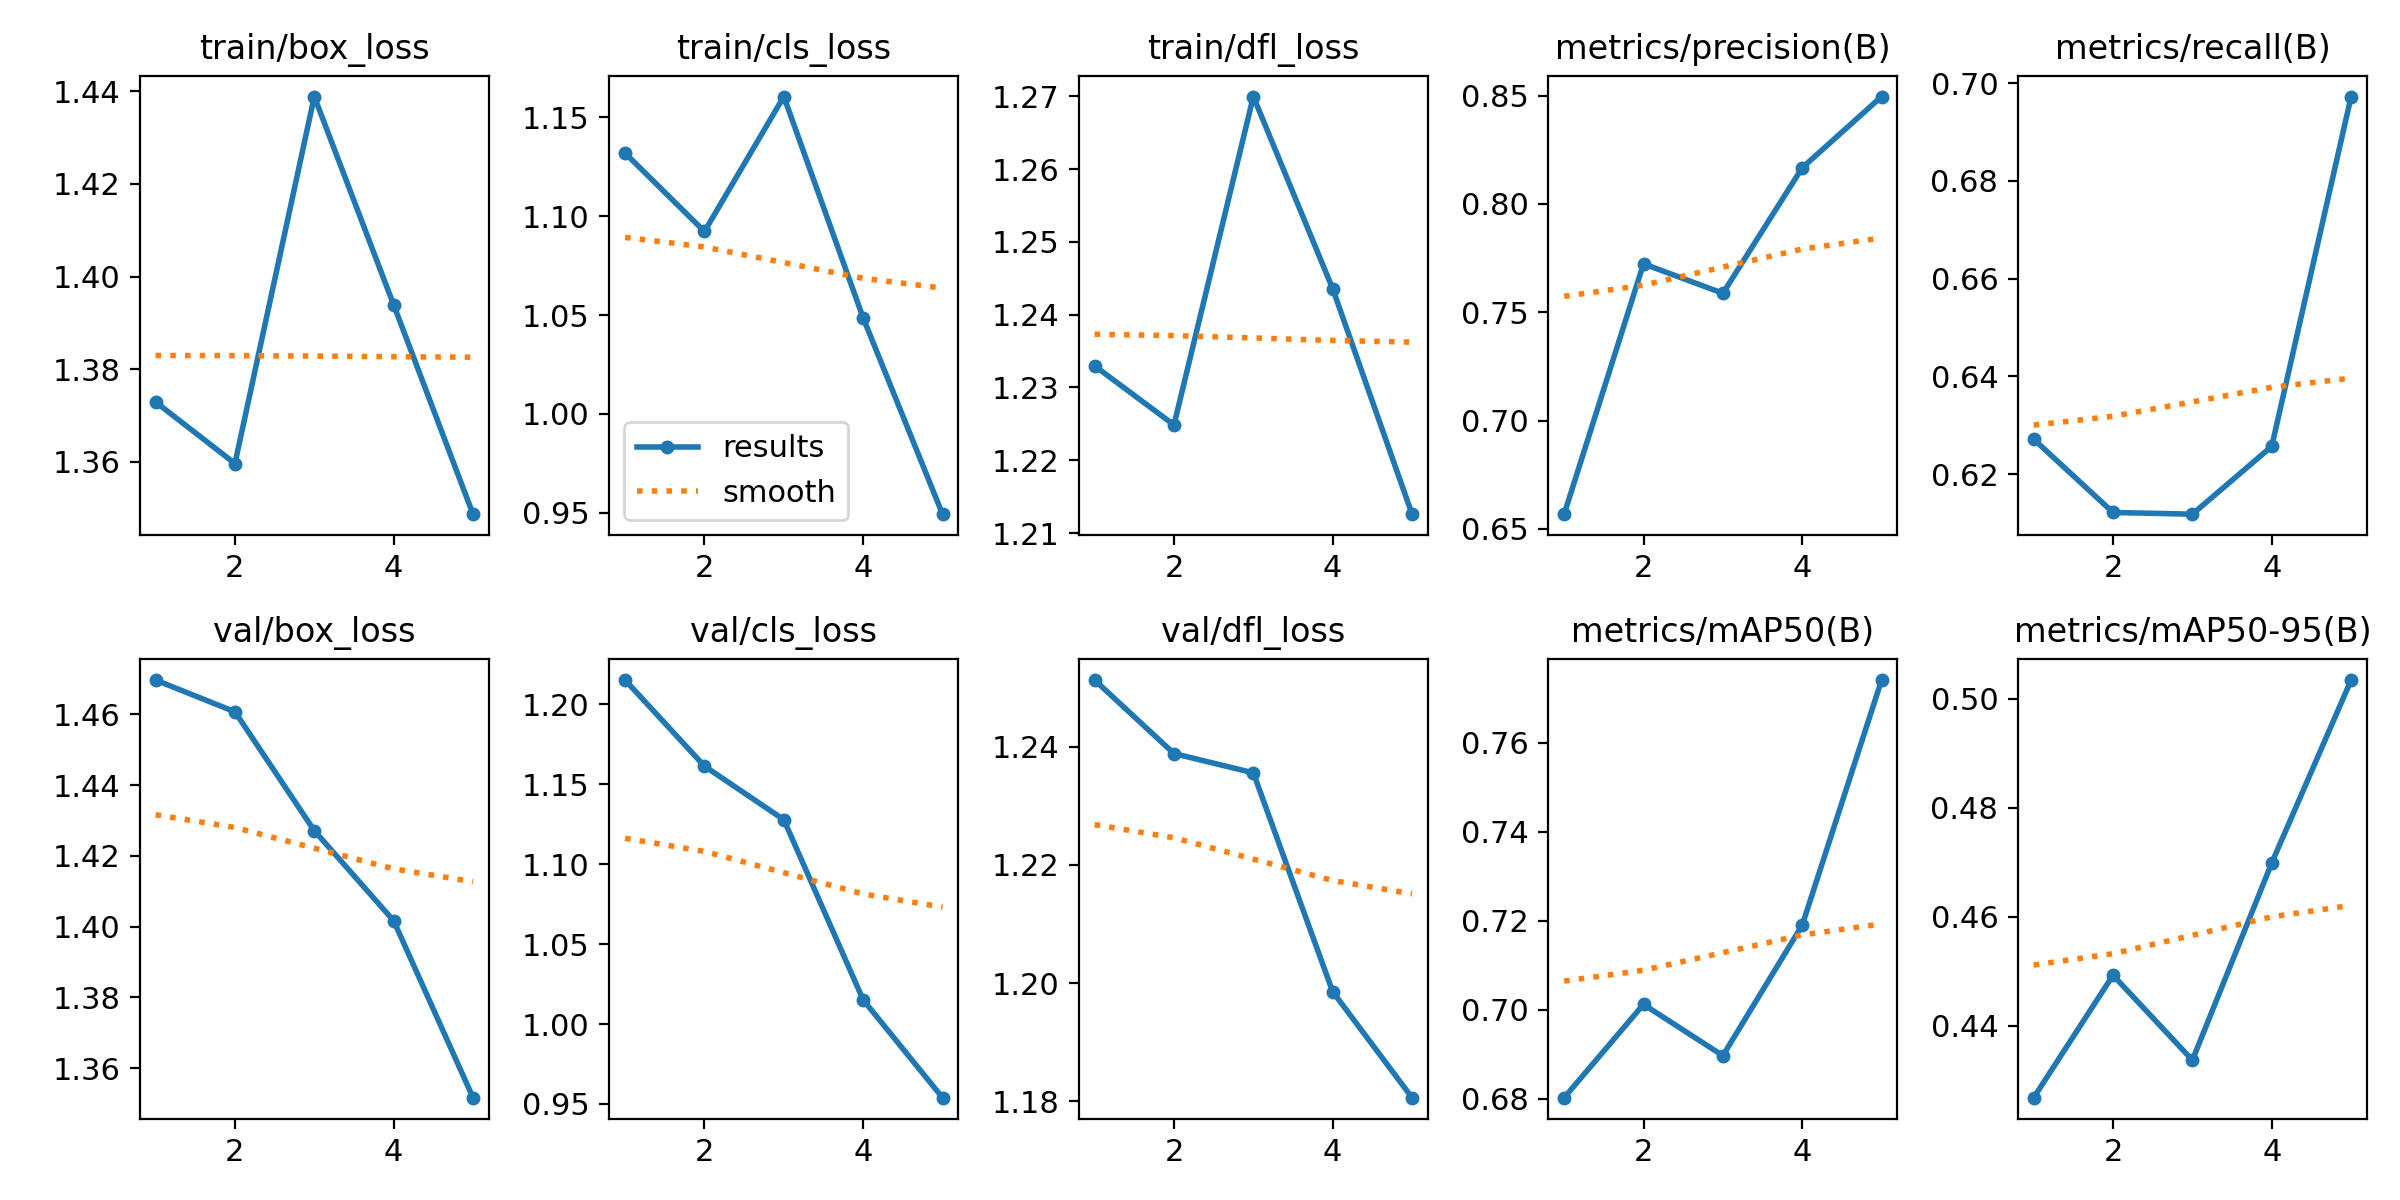


Resultados originales: experimento_416


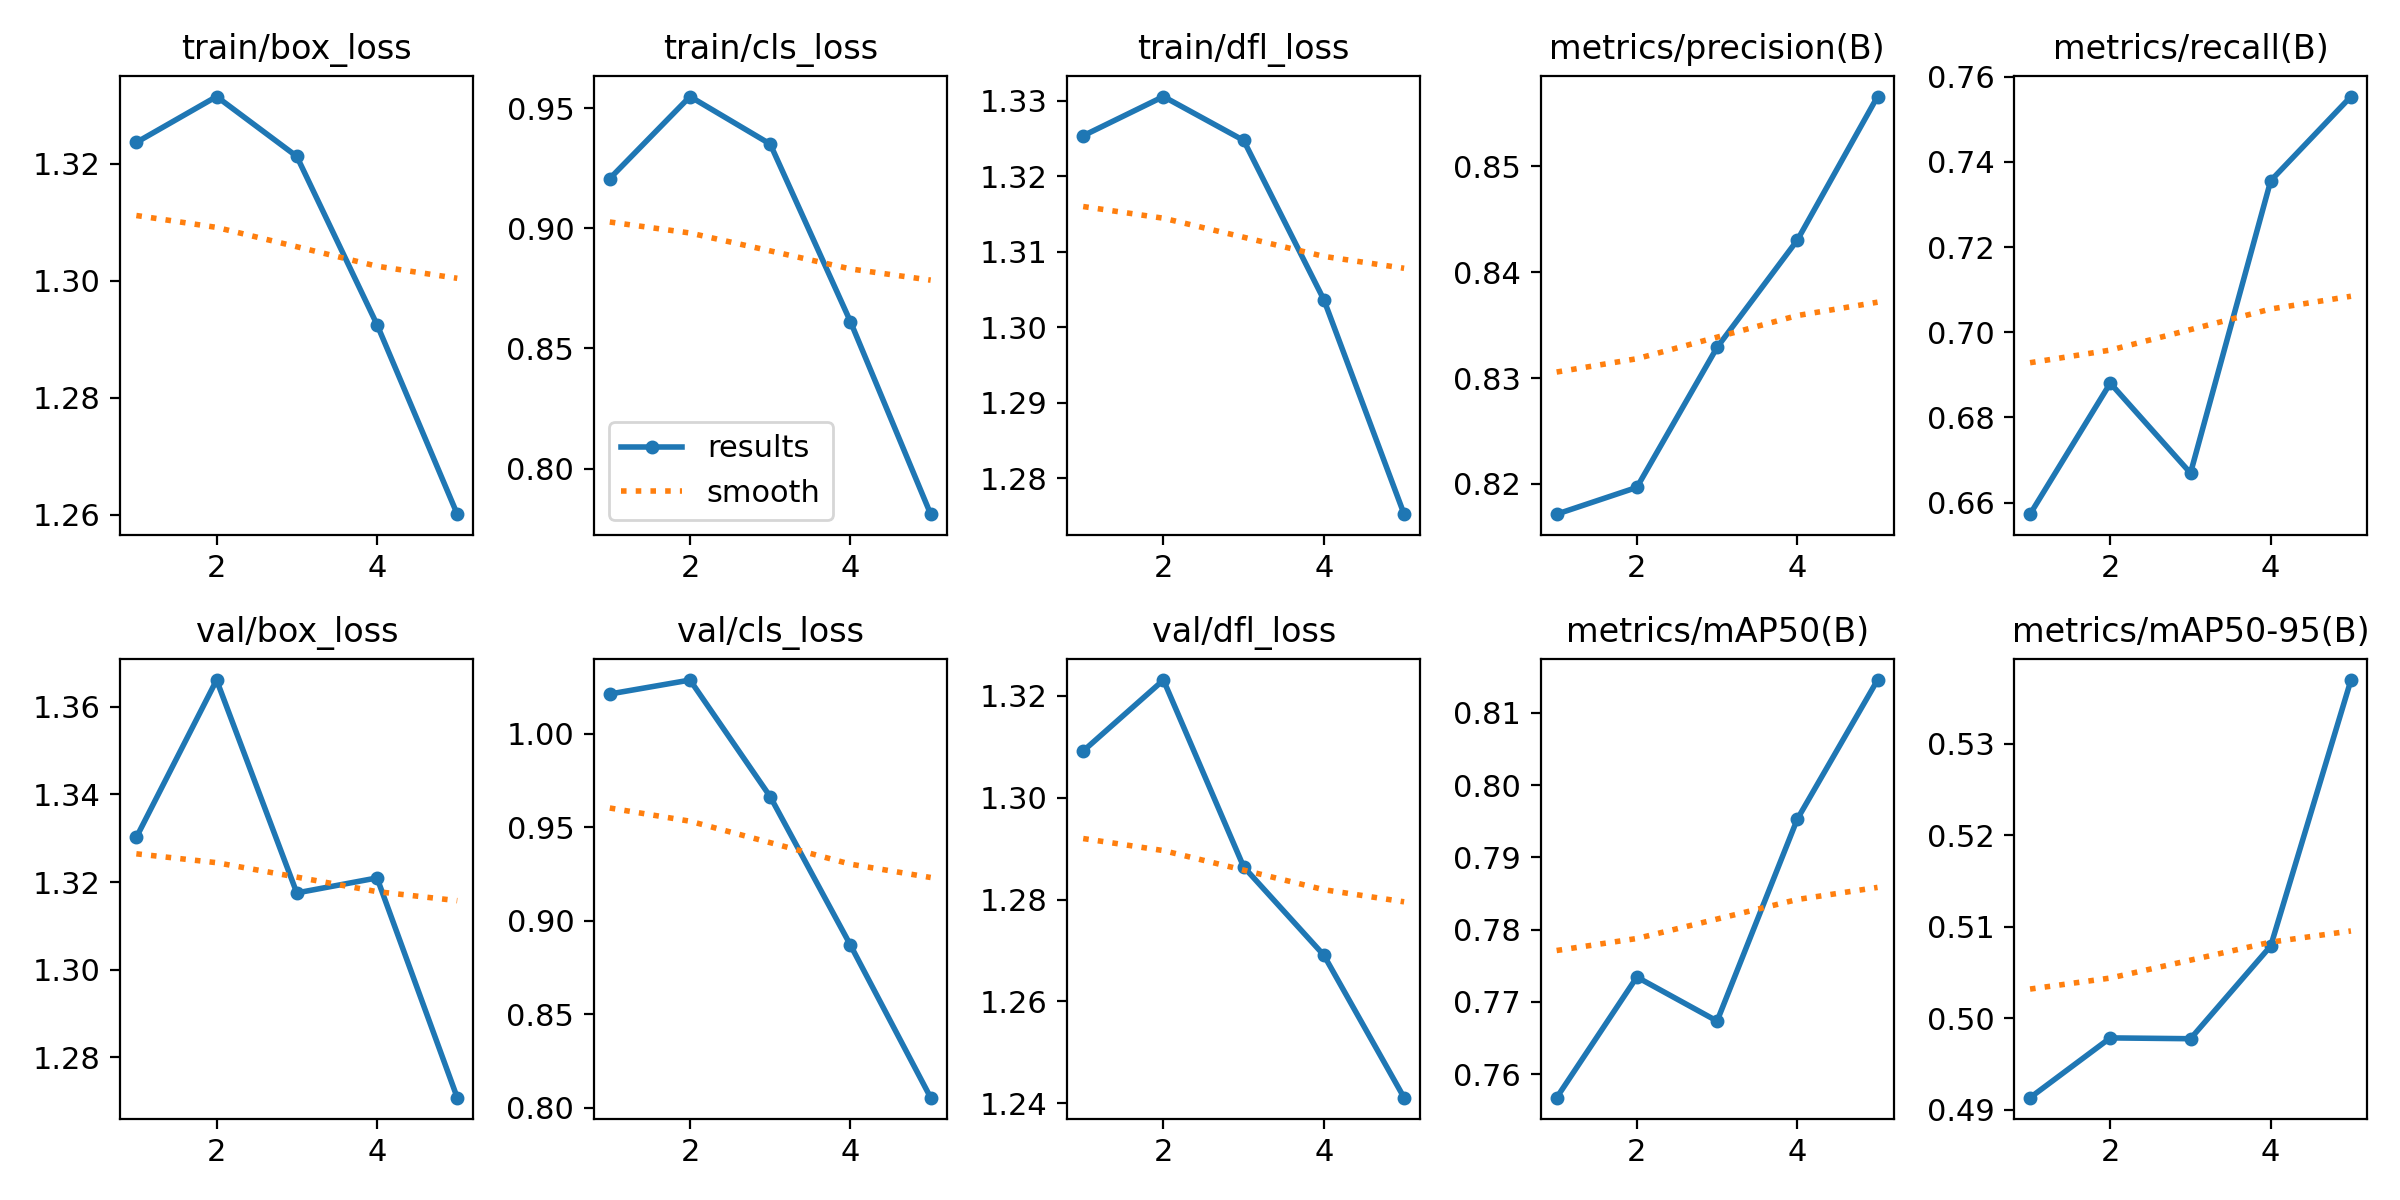

In [ ]:
from pathlib import Path
from IPython.display import display, Image

raiz = Path(
    "/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/02_modelos"
)

for experimento in ["entrenamiento_v1", "experimento_416"]:
    archivo = raiz / experimento / "results.png"

    print(f"\nResultados originales: {experimento}")

    if archivo.exists():
        display(Image(filename=str(archivo)))
    else:
        print(f"No se encontró: {archivo}")

**Siguiente paso: revisar las curvas Precision–Recal**l
Ahora revisaremos BoxPR_curve.png de ambos experimentos. Estas curvas nos ayudarán a documentar el rendimiento por clase y a identificar si hay especies para las que el equilibrio entre precisión y recall es especialmente desfavorable.


Curva Precision–Recall: entrenamiento_v1


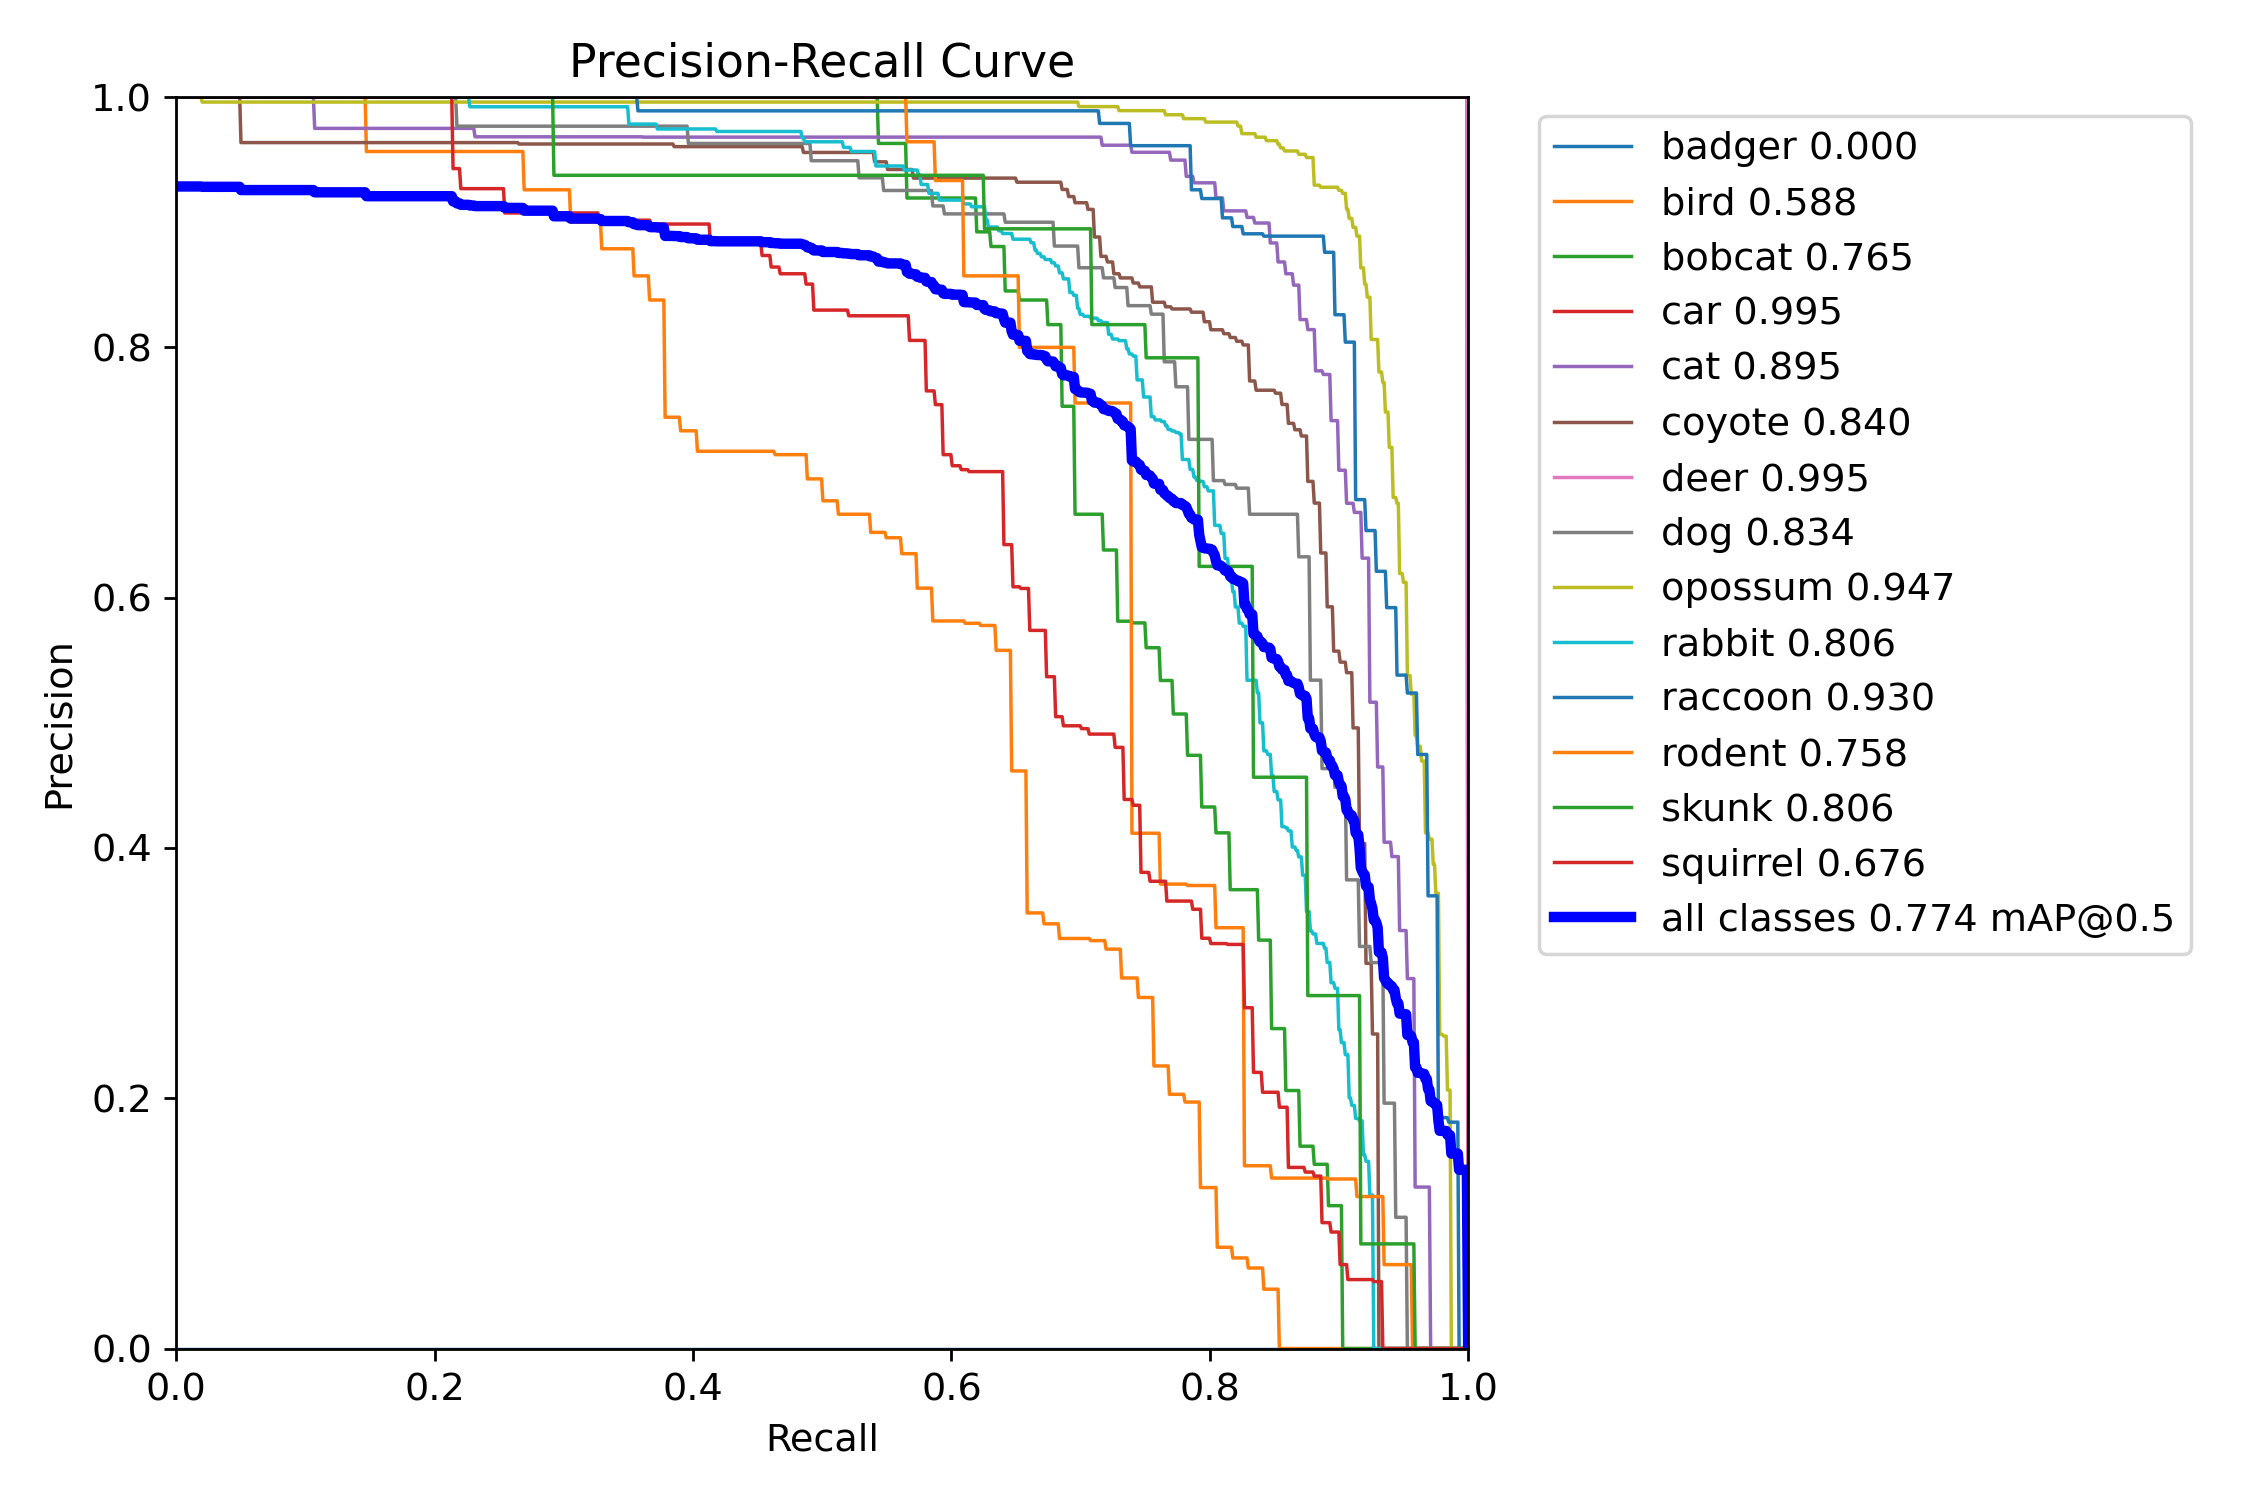


Curva Precision–Recall: experimento_416


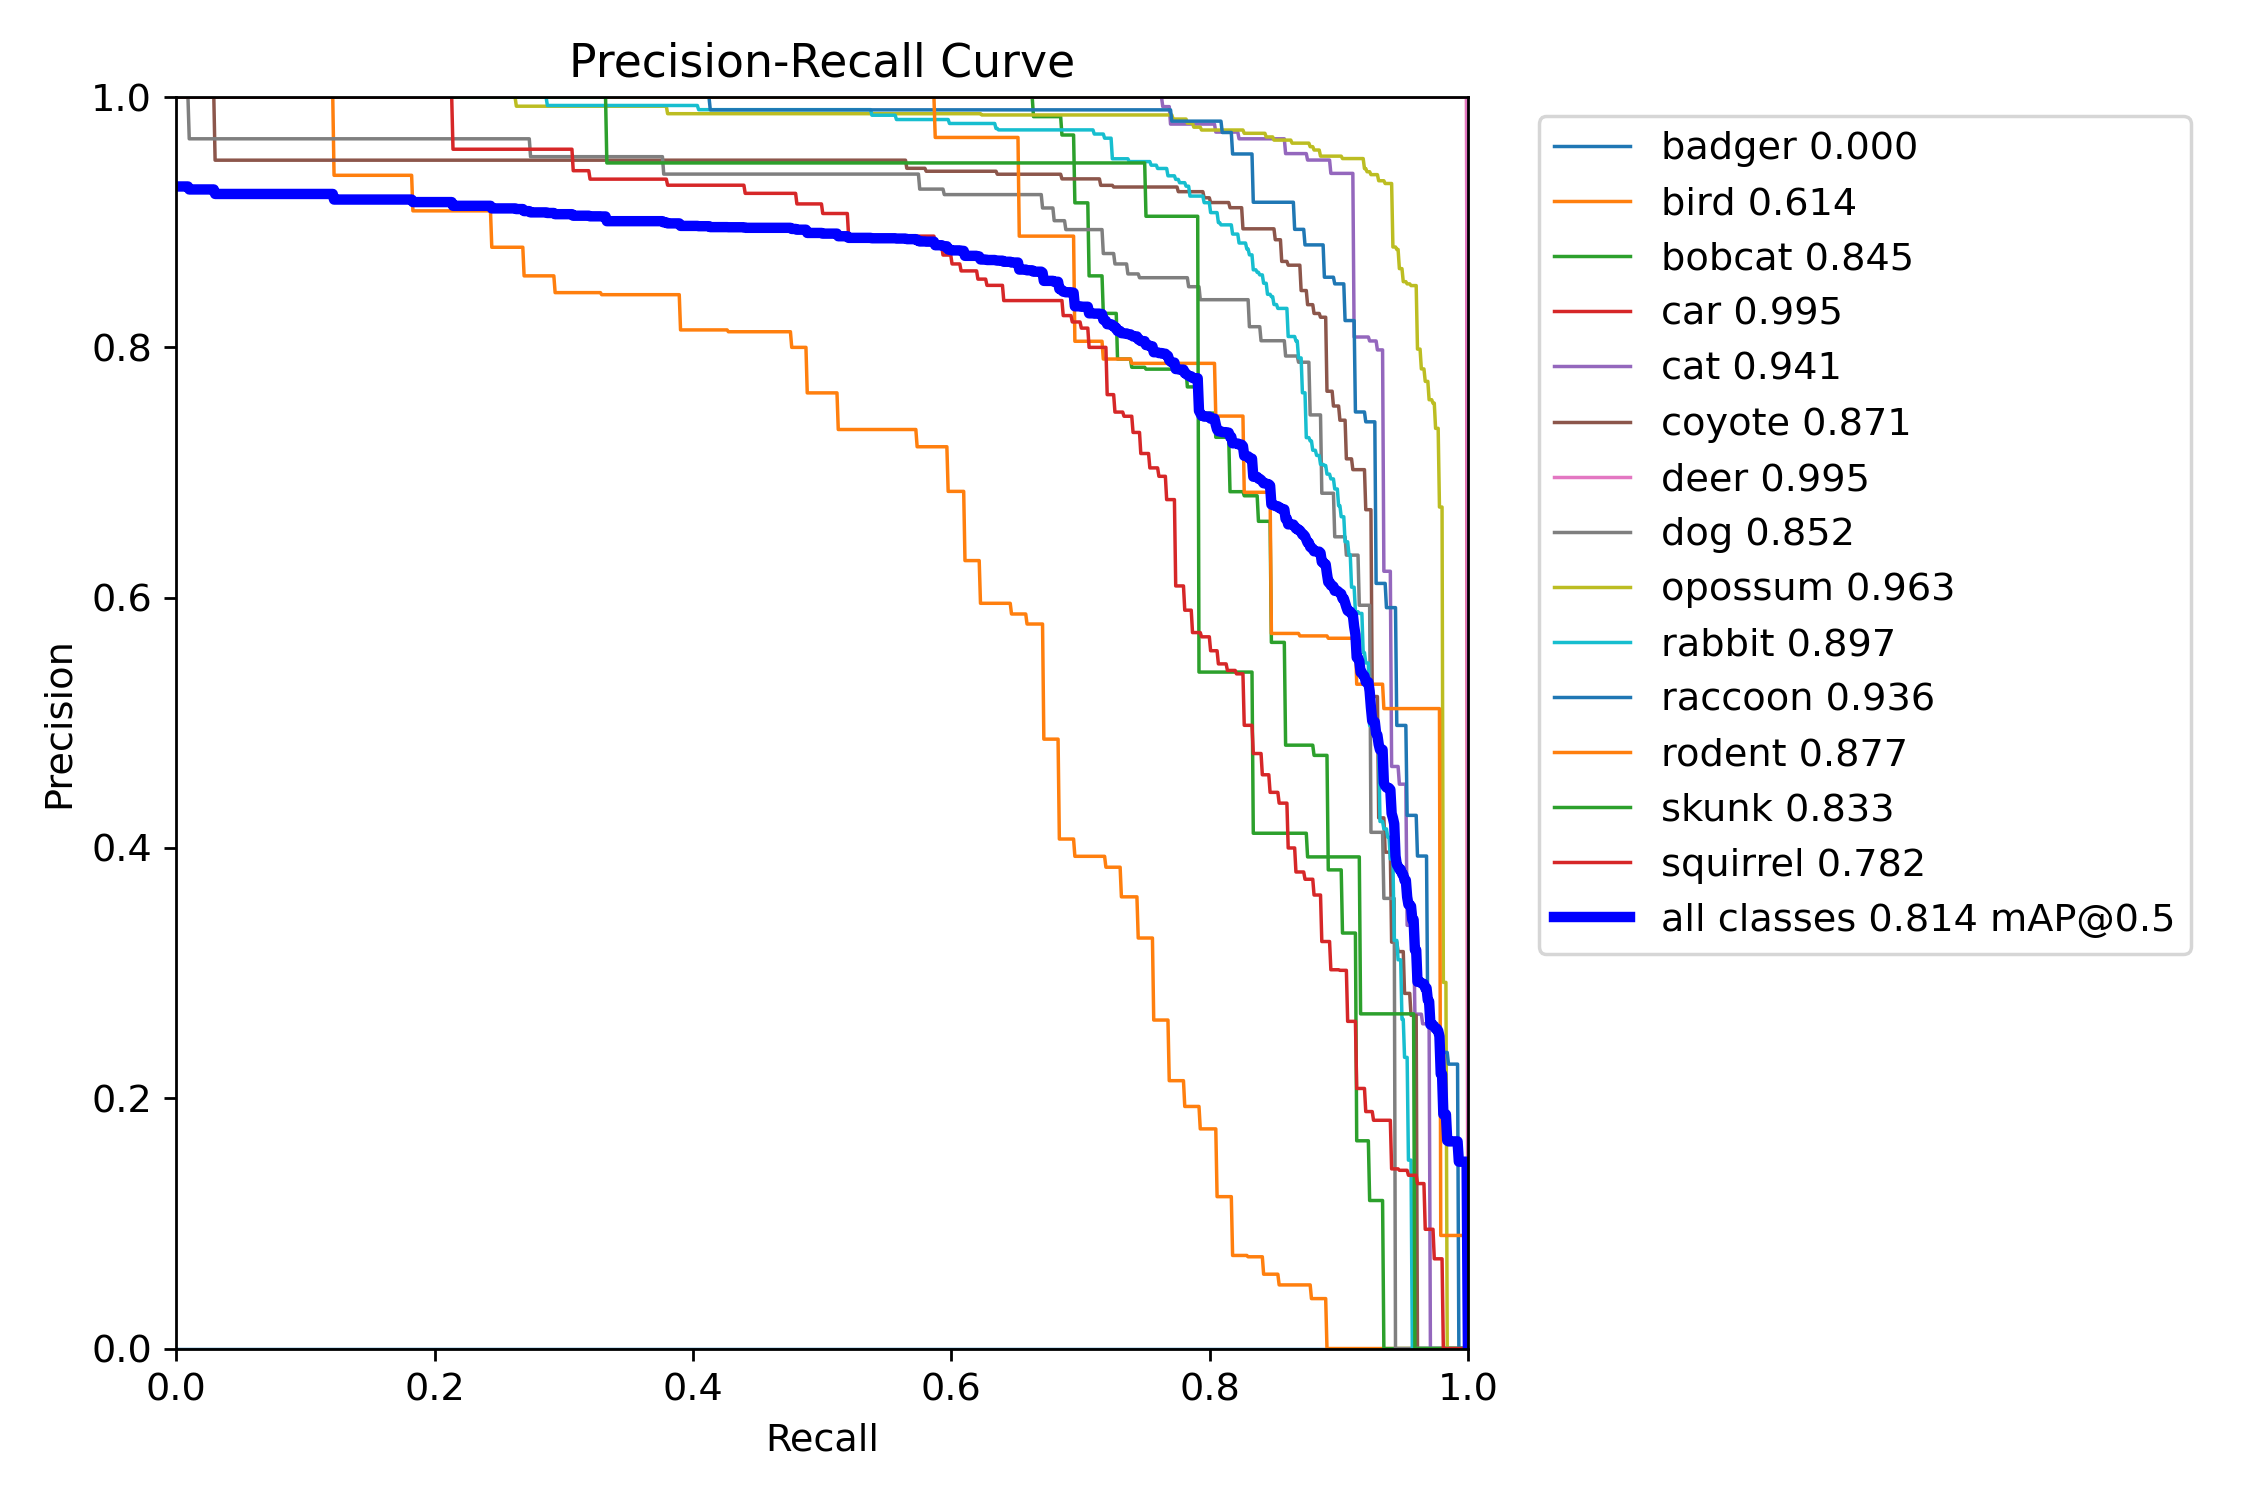

In [ ]:
from pathlib import Path
from IPython.display import display, Image

raiz = Path(
    "/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/02_modelos"
)

for experimento in ["entrenamiento_v1", "experimento_416"]:
    archivo = raiz / experimento / "BoxPR_curve.png"

    print(f"\nCurva Precision–Recall: {experimento}")
    display(Image(filename=str(archivo)))

**Paso 3. Revisar las matrices de confusión**
Estas matrices nos ayudarán a identificar qué especies confunde el modelo. Es una evidencia complementaria a las curvas Precision–Recall y puede respaldar el análisis de falsos positivos y falsos negativos del entregable 6.


MATRICES DE CONFUSIÓN: entrenamiento_v1

confusion_matrix_normalized.png


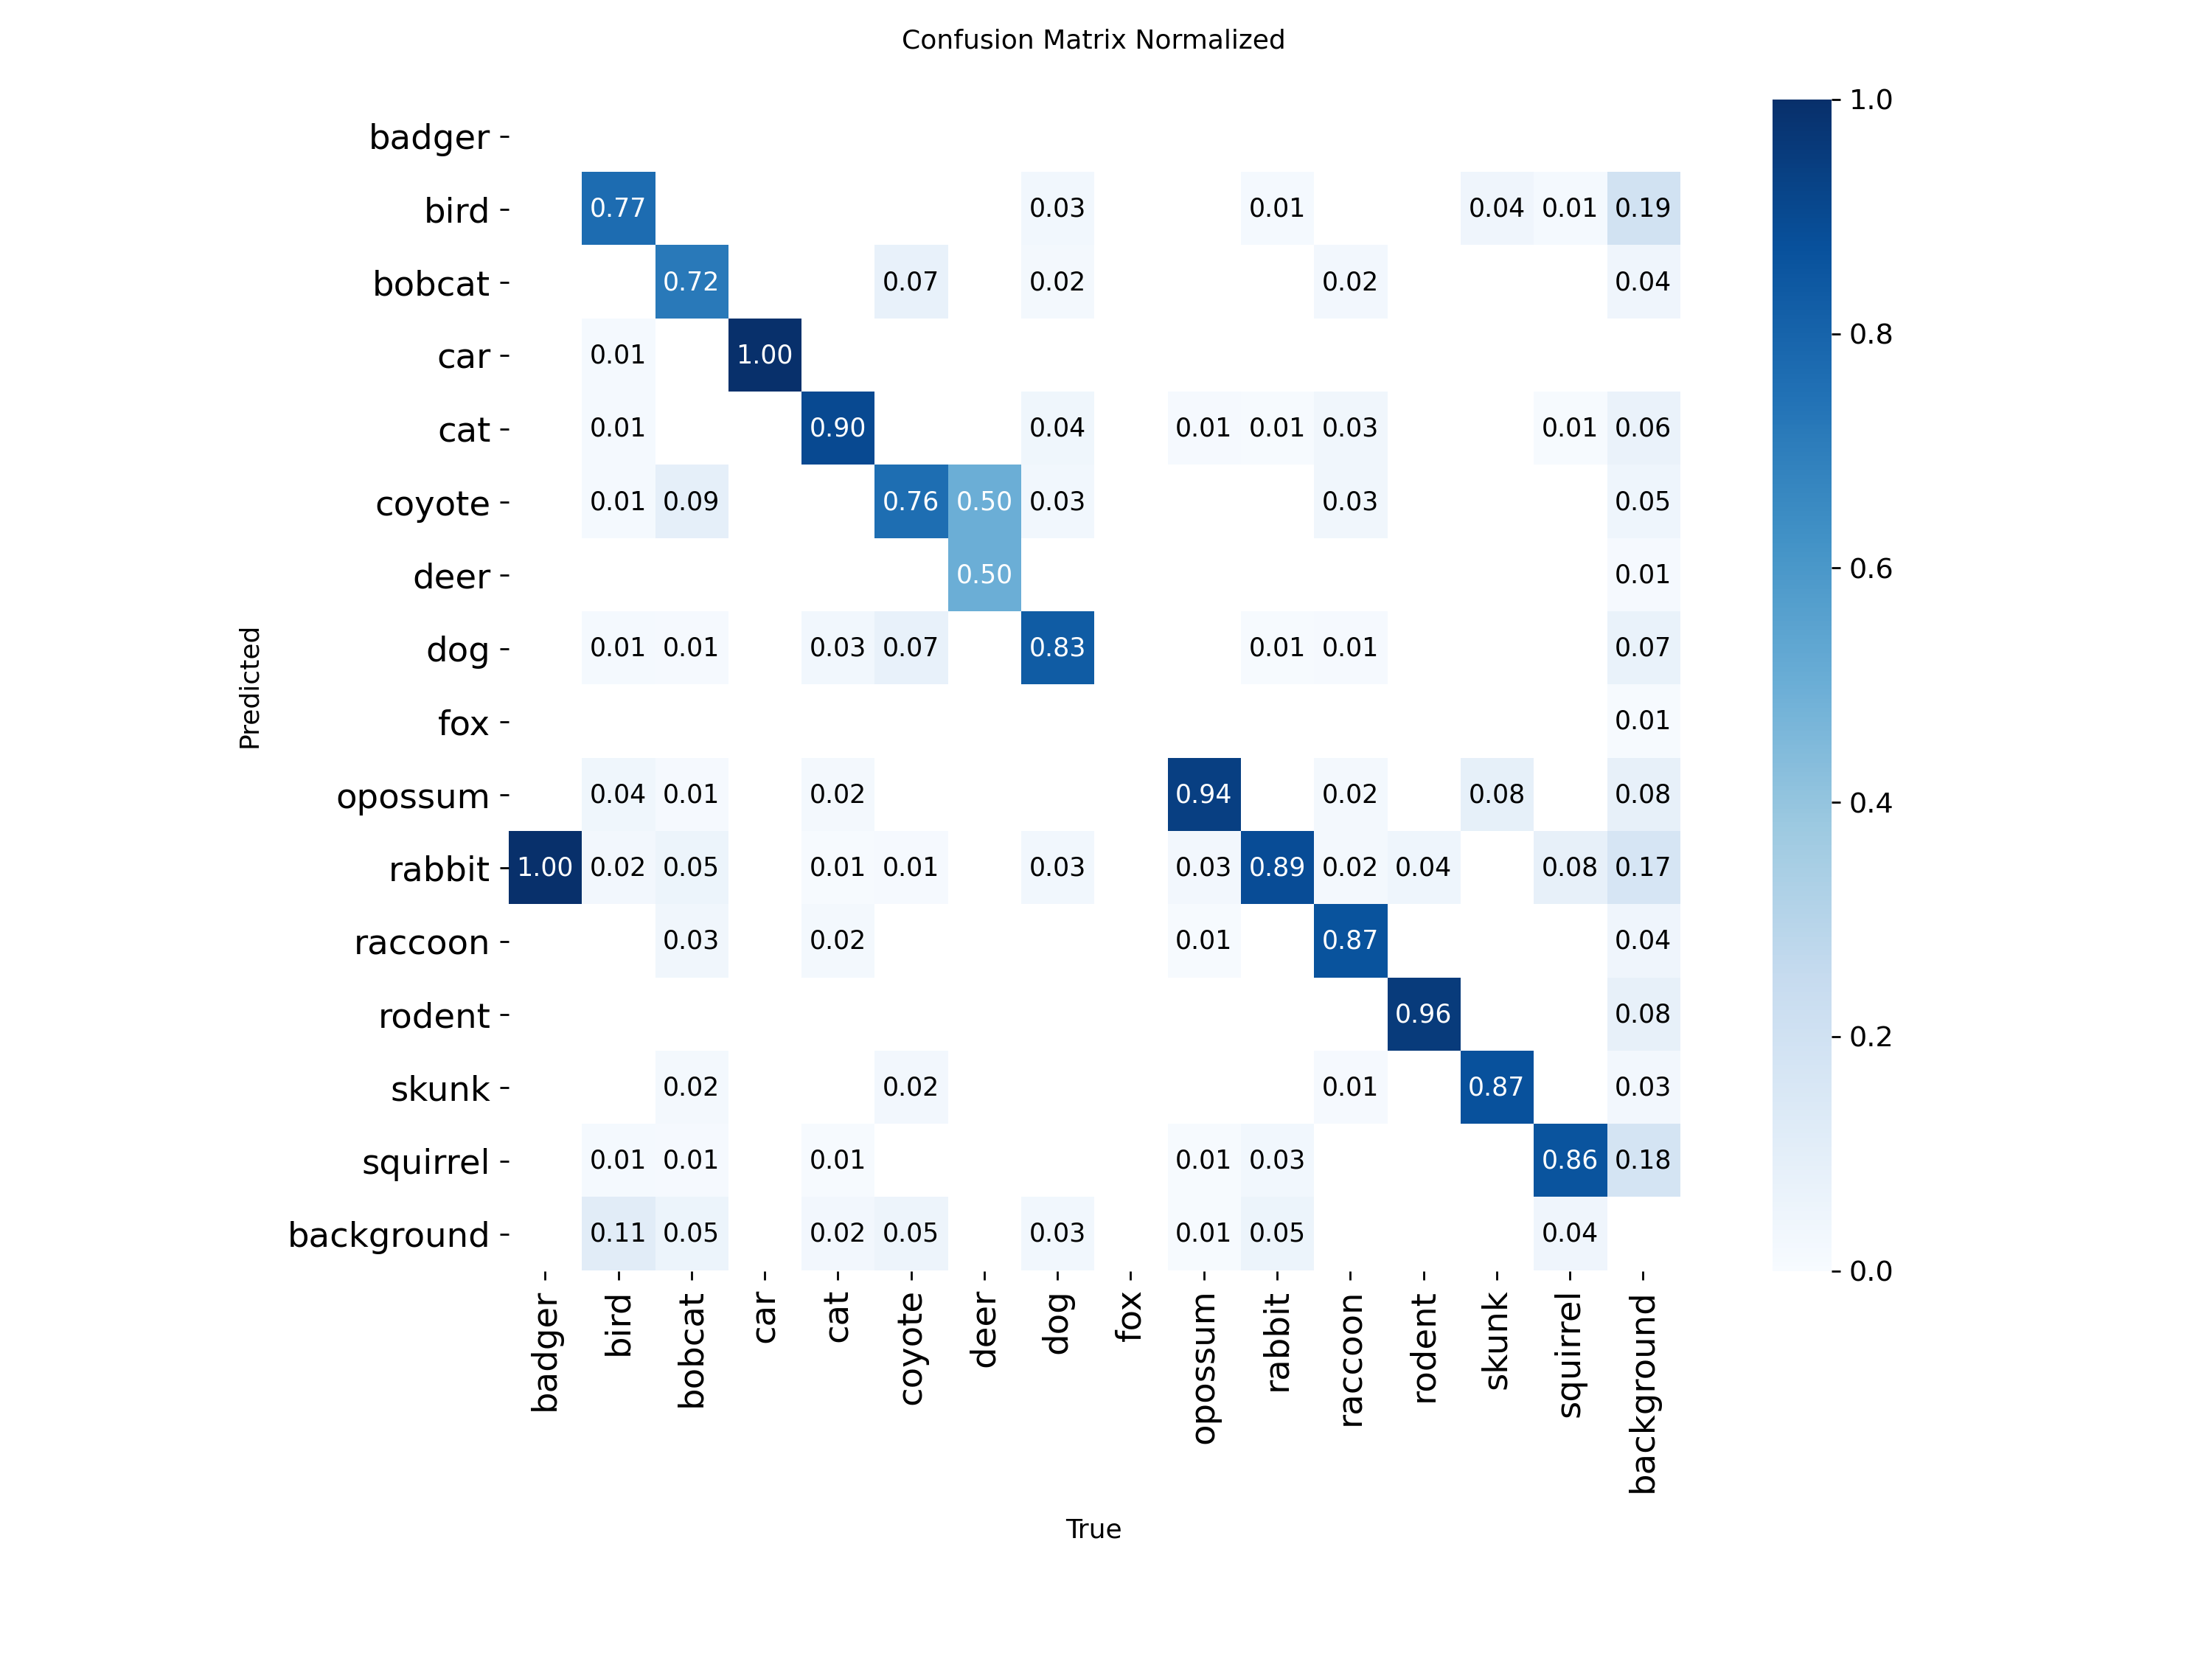


confusion_matrix.png


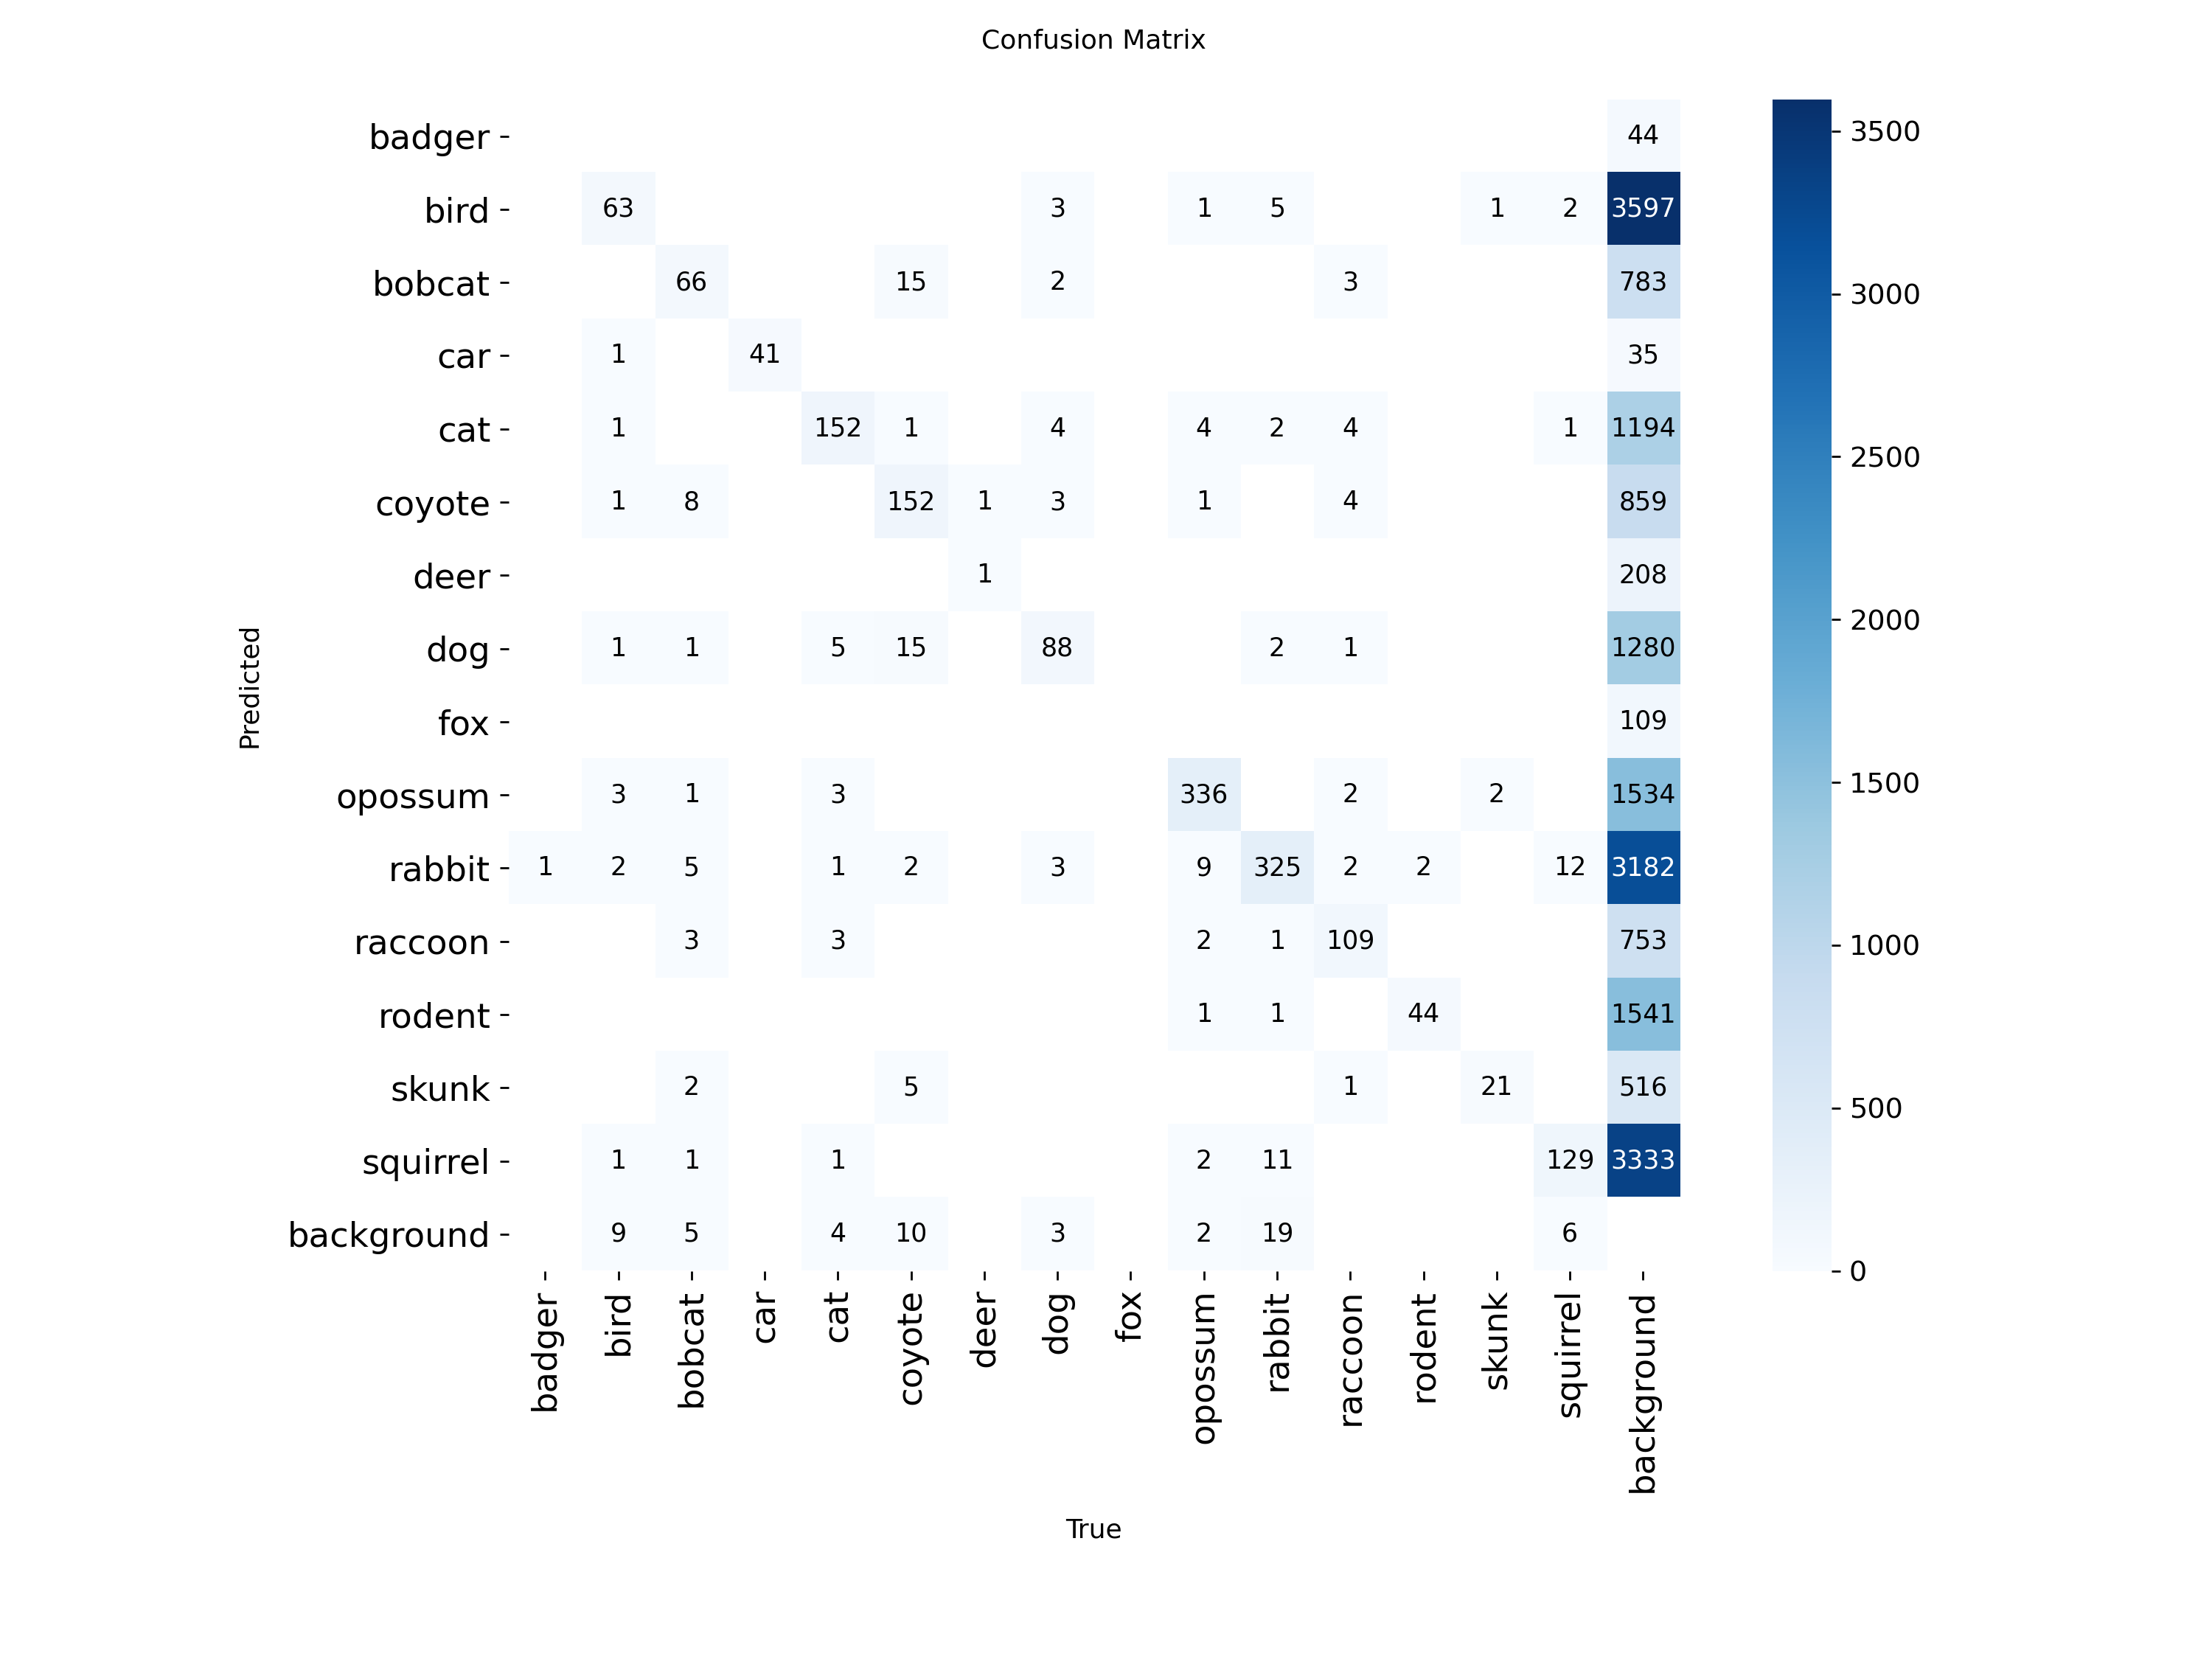


MATRICES DE CONFUSIÓN: experimento_416

confusion_matrix_normalized.png


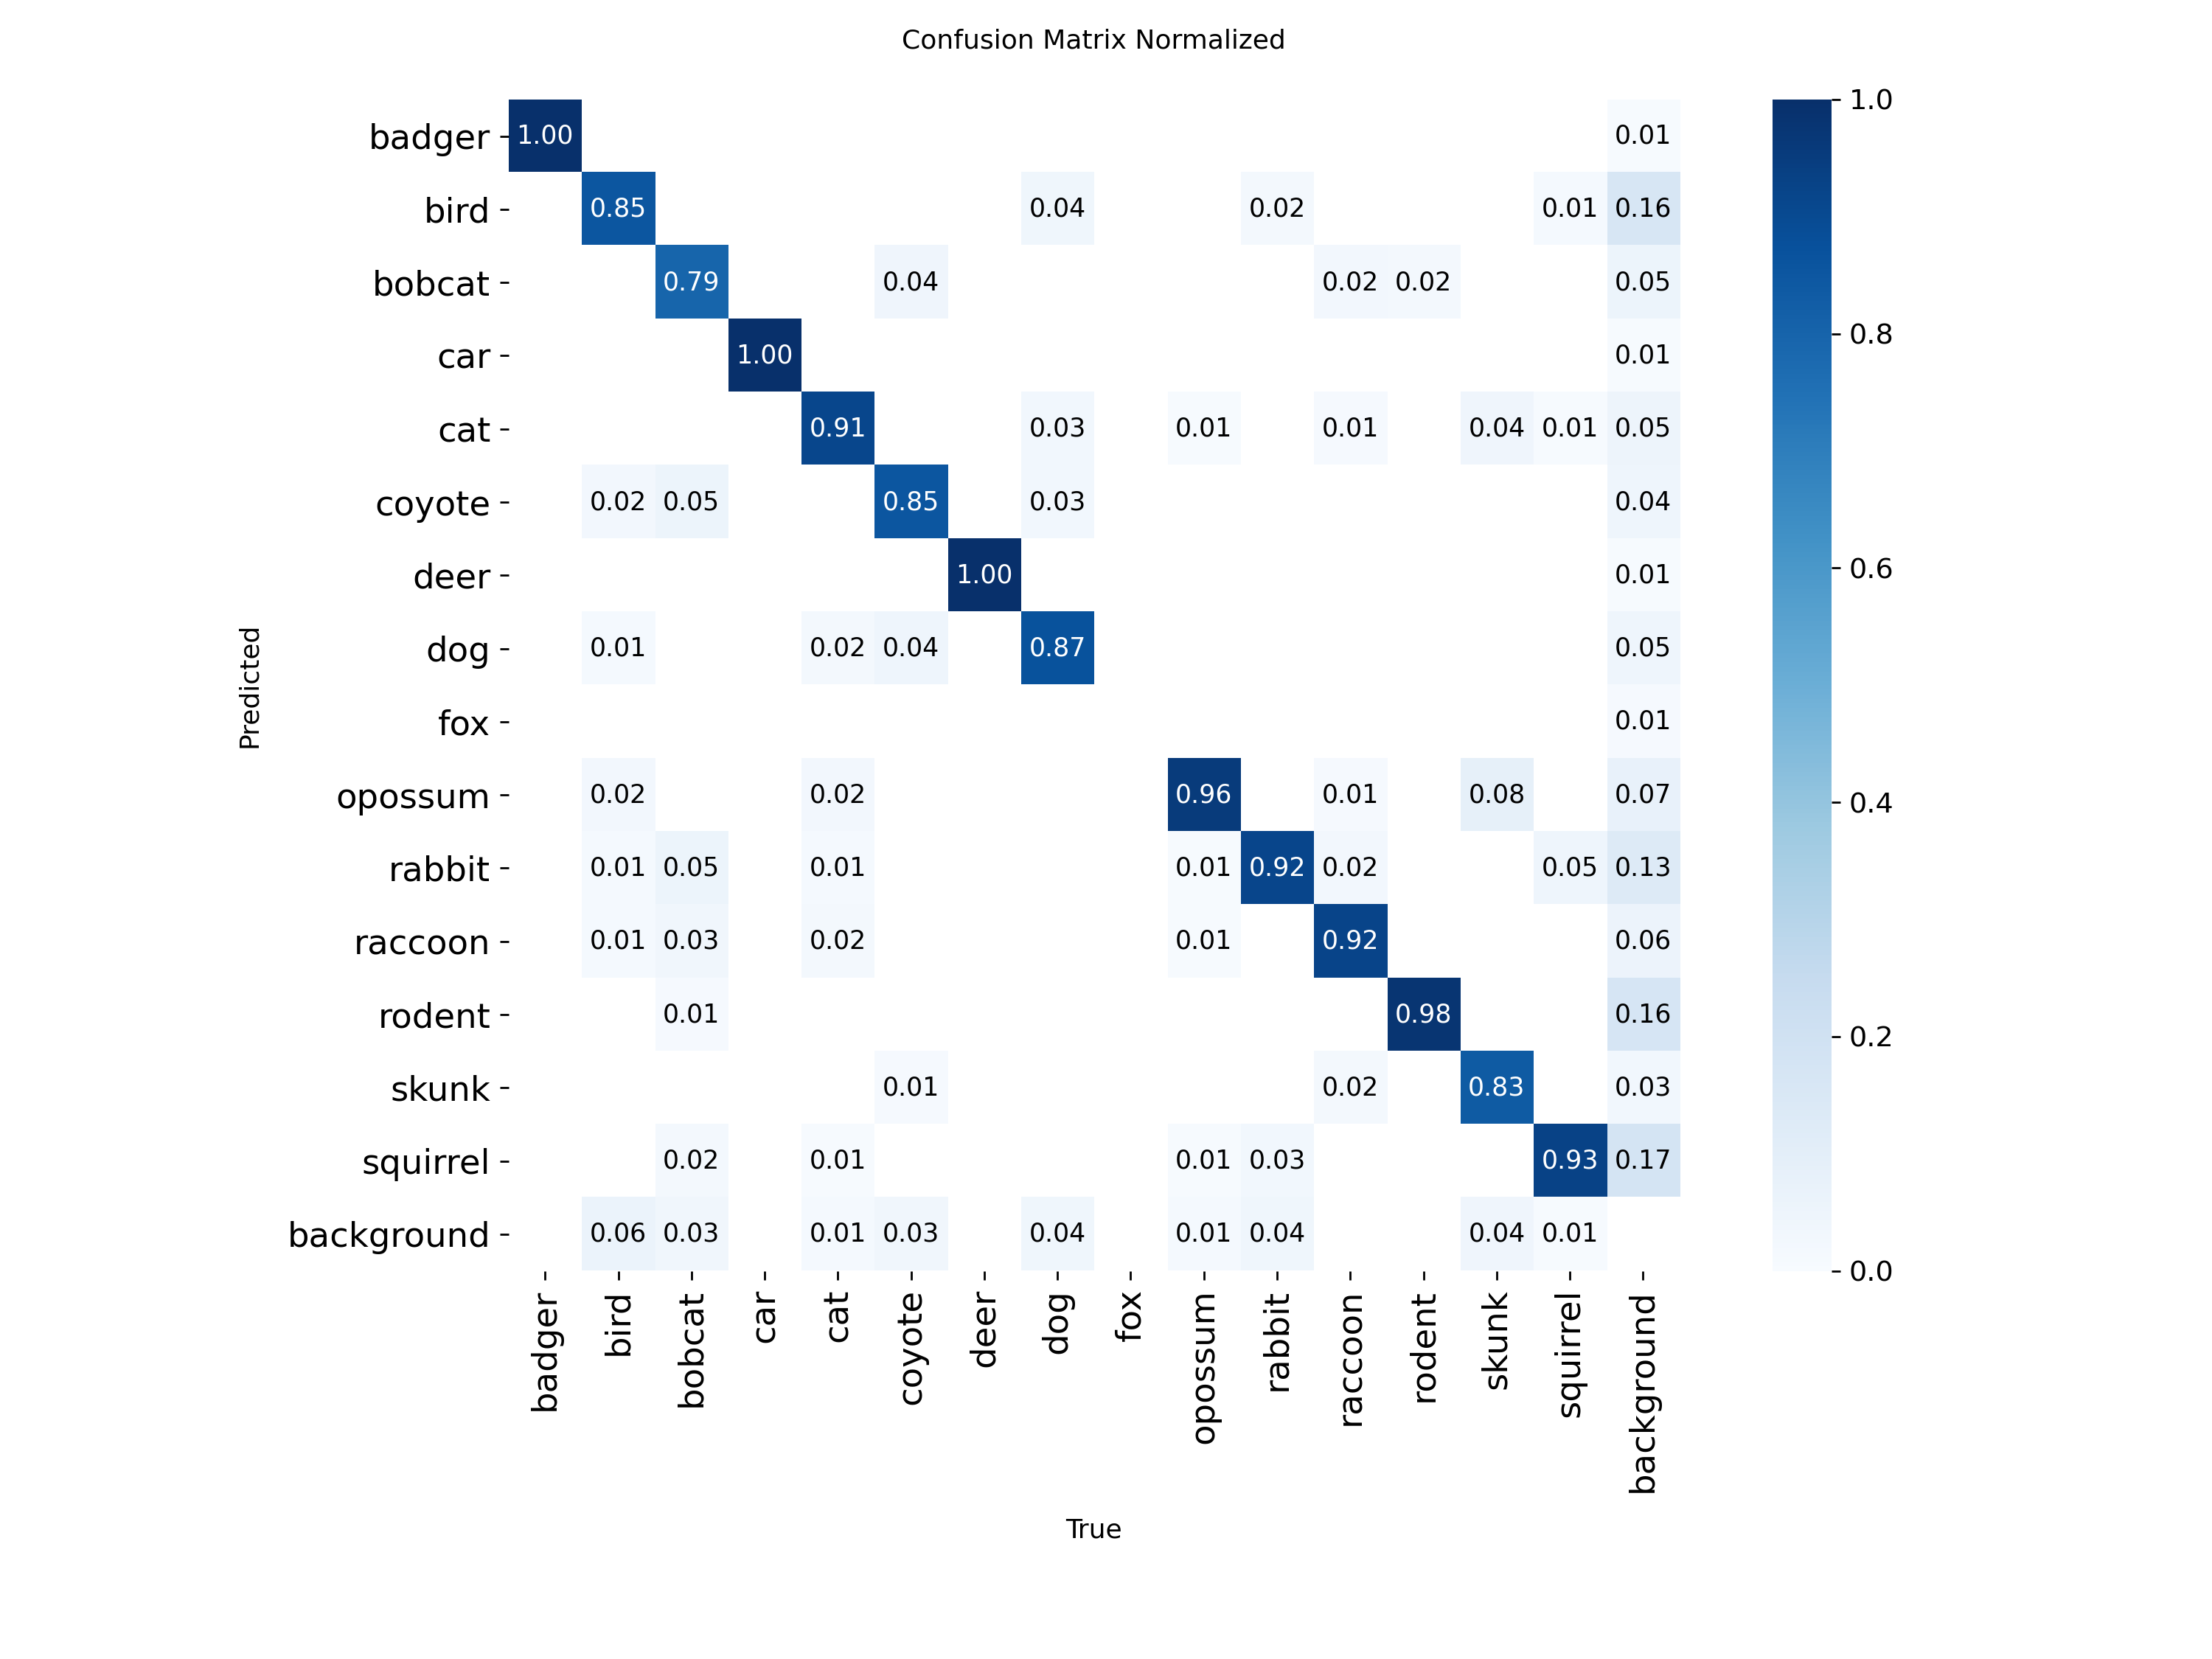


confusion_matrix.png


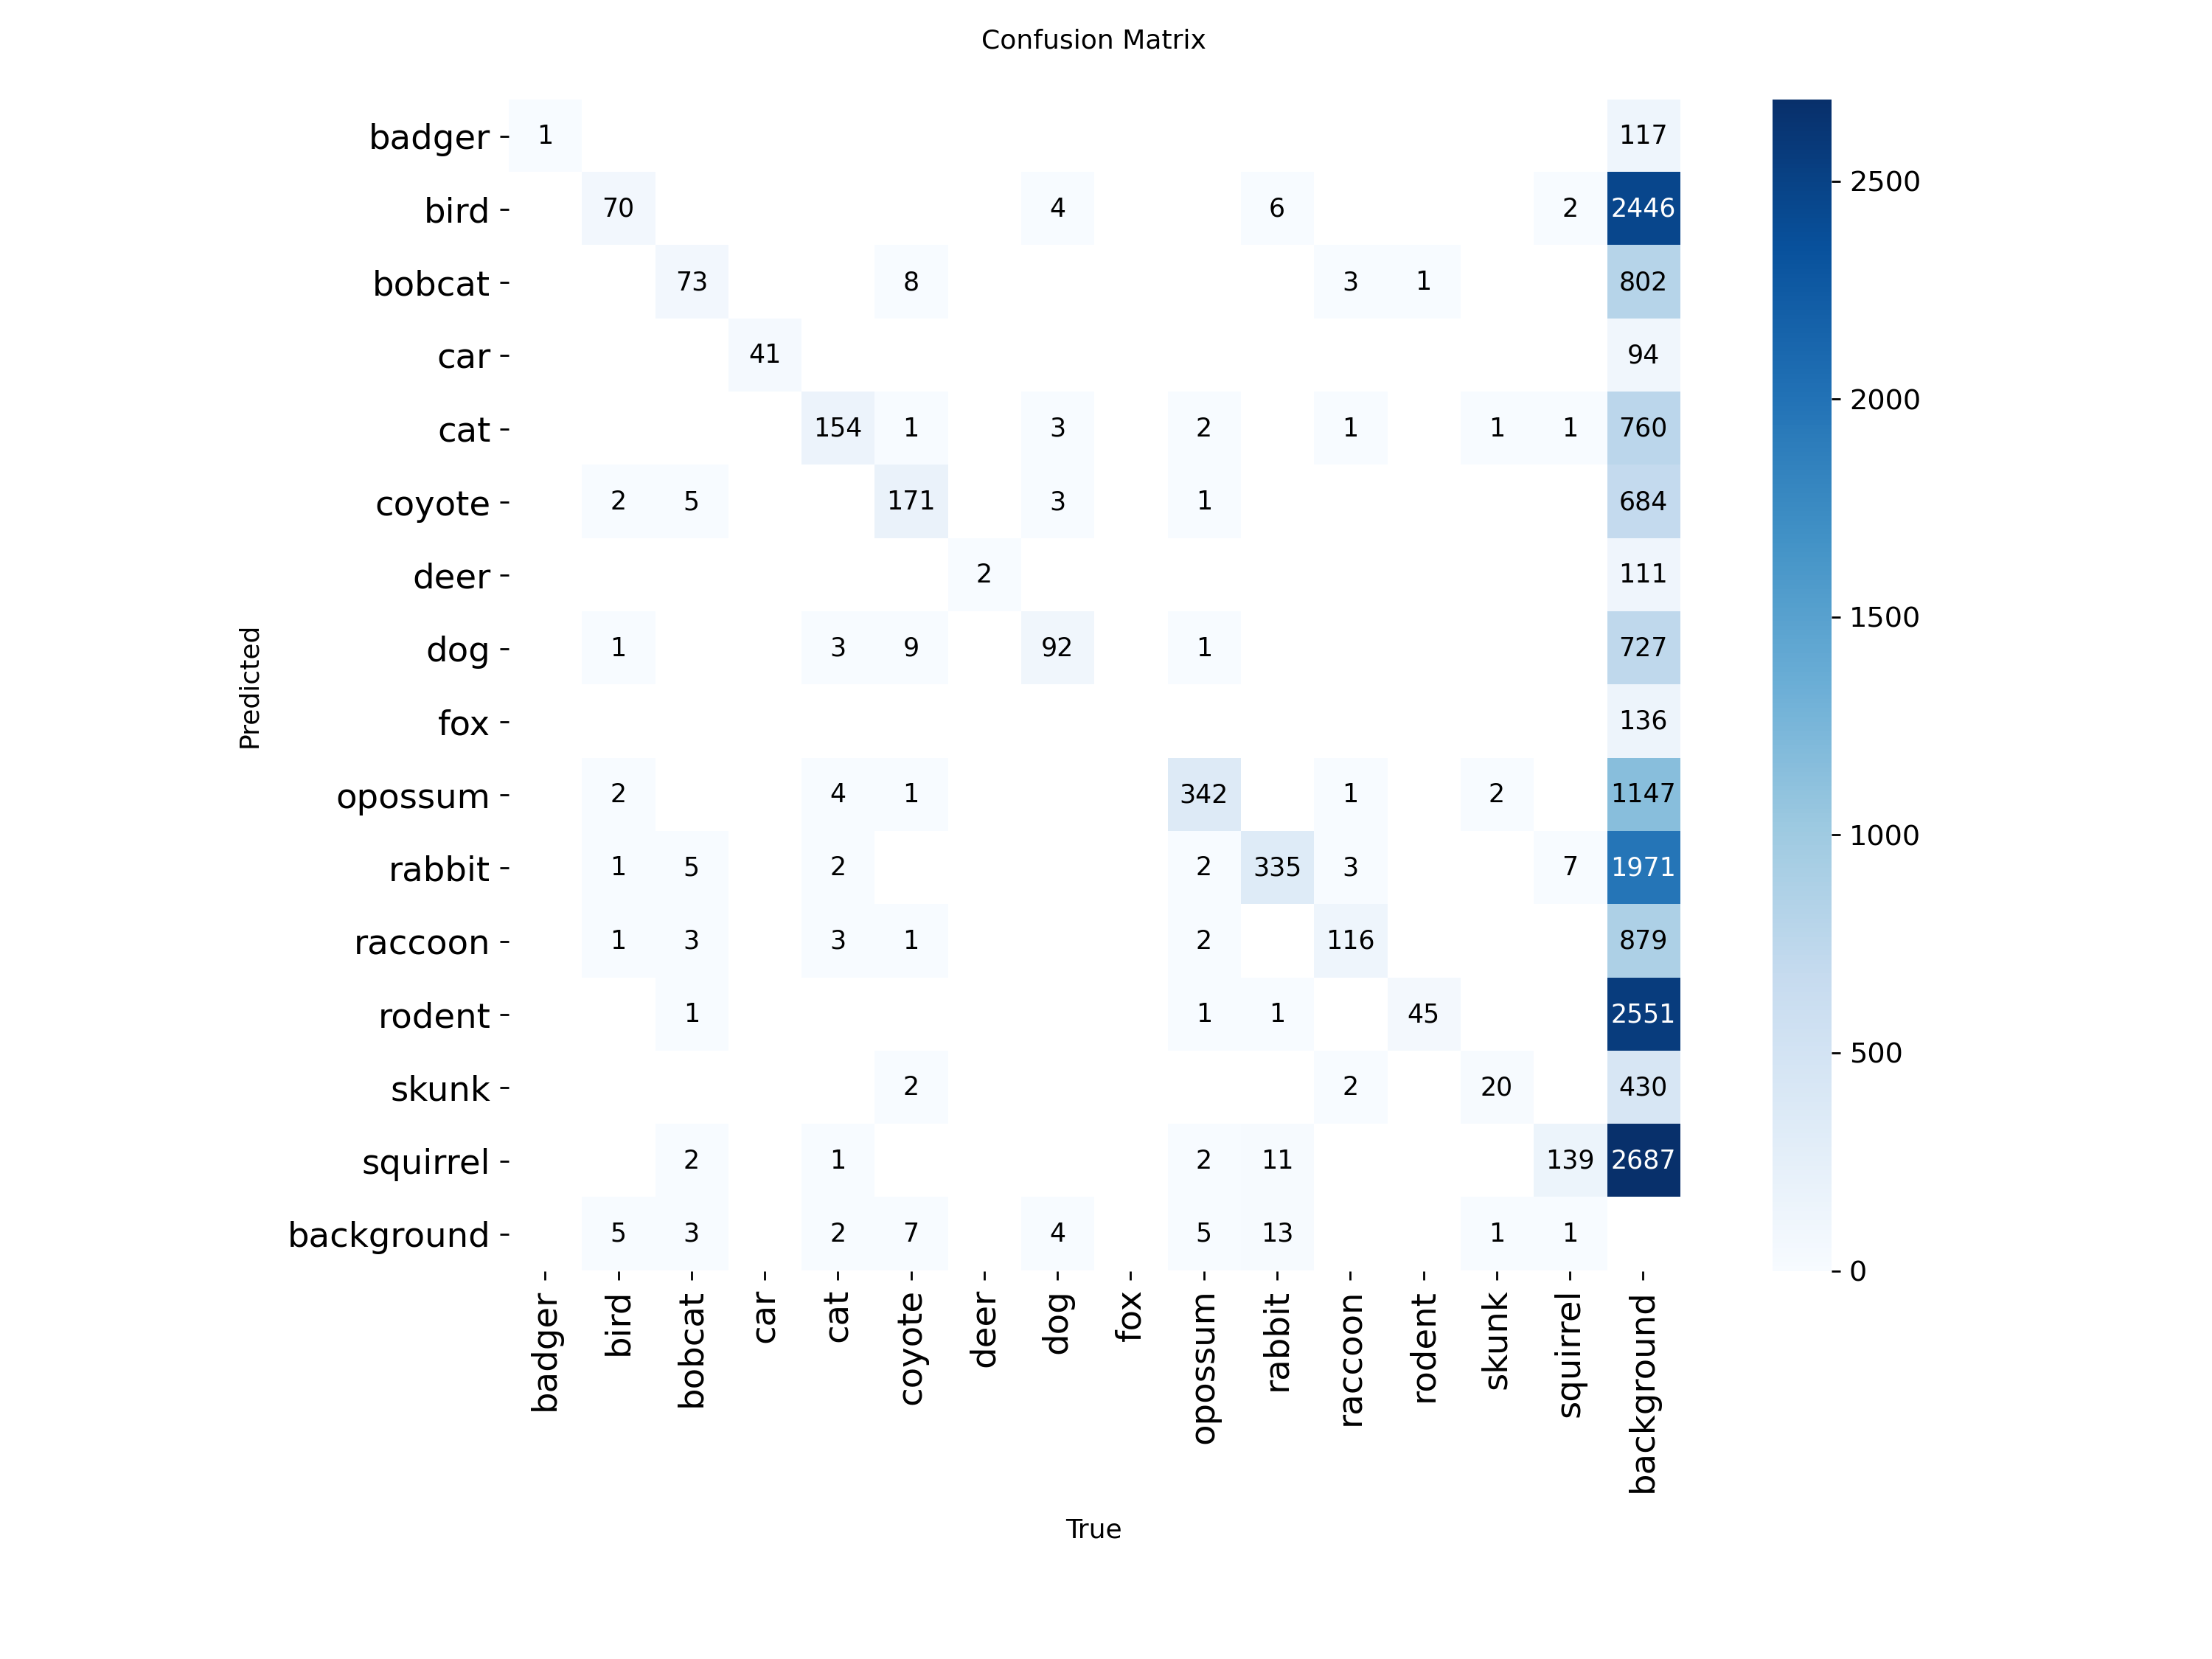

In [ ]:
from pathlib import Path
from IPython.display import display, Image

raiz = Path(
    "/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/02_modelos"
)

for experimento in ["entrenamiento_v1", "experimento_416"]:
    carpeta = raiz / experimento

    print(f"\n{'=' * 55}")
    print(f"MATRICES DE CONFUSIÓN: {experimento}")
    print(f"{'=' * 55}")

    for nombre in [
        "confusion_matrix_normalized.png",
        "confusion_matrix.png",
    ]:
        archivo = carpeta / nombre

        if archivo.exists():
            print(f"\n{nombre}")
            display(Image(filename=str(archivo)))
        else:
            print(f"No encontrado: {nombre}")

**Paso 4. Comparar etiquetas reales y predicciones**
Los archivos val_batch0_labels.jpg y val_batch0_pred.jpg permiten comparar las anotaciones reales con las predicciones del modelo. Revisaremos el primer lote de cada experimento, sin ejecutar nuevamente YOLOv8.

In [ ]:
from pathlib import Path
from IPython.display import display, Image

raiz = Path(
    "/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8/02_modelos"
)

for experimento in ["entrenamiento_v1", "experimento_416"]:
    carpeta = raiz / experimento

    print(f"\n{'=' * 60}")
    print(f"EXPERIMENTO: {experimento}")
    print(f"{'=' * 60}")

    for nombre in ["val_batch0_labels.jpg", "val_batch0_pred.jpg"]:
        archivo = carpeta / nombre

        if archivo.exists():
            print(f"\n{'Etiquetas reales' if 'labels' in nombre else 'Predicciones del modelo'}")
            display(Image(filename=str(archivo)))
        else:
            print(f"No se encontró: {archivo}")

**Busqueda de archivos fuente**

In [ ]:
from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")

raiz = Path(
    "/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8"
)

print("ARCHIVOS FUENTE ENCONTRADOS")
print("=" * 60)

archivos = sorted(raiz.rglob("*.py"))

if archivos:
    for archivo in archivos:
        print(archivo.relative_to(raiz))
else:
    print("No se encontraron archivos .py en el proyecto.")
    print("Es posible que el código esté guardado únicamente en notebooks.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ARCHIVOS FUENTE ENCONTRADOS
No se encontraron archivos .py en el proyecto.
Es posible que el código esté guardado únicamente en notebooks.


In [ ]:
from pathlib import Path

raiz = Path(
    "/content/drive/MyDrive/Monitoreo_Fauna_YOLOv8"
)

extensiones = {
    ".ipynb",
    ".py",
    ".yaml",
    ".yml",
    ".json",
    ".txt",
    ".md",
    ".sh",
}

print("ARCHIVOS DE CÓDIGO Y CONFIGURACIÓN")
print("=" * 65)

encontrados = sorted(
    archivo
    for archivo in raiz.rglob("*")
    if archivo.is_file()
    and archivo.suffix.lower() in extensiones
    and not any(
        parte.startswith(".")
        for parte in archivo.relative_to(raiz).parts
    )
)

if encontrados:
    for archivo in encontrados:
        print(
            f"{archivo.relative_to(raiz)} "
            f"({archivo.stat().st_size / 1024:.1f} KB)"
        )
else:
    print("No se encontraron archivos de código o configuración.")